# Restaurant Rating Prediction and Location Recommendation

## 1. Exploratory Data Analysis and Preprocessing

### Objective

The objective of this notebook is to explore the Swiggy restaurant dataset, understand its characteristics, identify data quality issues, analyze important relationships, and prepare a clean dataset for supervised machine learning.

The target variable is `weighted_rating`, which represents an IMDb-style weighted restaurant rating.

The processed dataset generated from this notebook will be used in a separate notebook for regression model training, evaluation, and location recommendation.

### Main activities
1. Dataset inspection
2. Data quality assessment
3. Univariate and multivariate analysis
4. Target variable analysis
5. Missing value analysis
6. Outlier analysis
7. Feature selection and leakage investigation
8. Data preprocessing
9. Exporting the processed dataset

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

os.makedirs("../outputs/figures/eda", exist_ok=True)
os.makedirs("../outputs/tables/eda", exist_ok=True)
os.makedirs("../outputs/reports", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

print("Libraries imported successfully.")
print("Output directories created.")

Libraries imported successfully.
Output directories created.


In [2]:
df = pd.read_csv("Restaurant_Dataset.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (67530, 127)


,name,city,rating,rating_count,cost,cuisine,lic_no,menu,lat,lng,state,college_n_500m,college_n_1000m,college_nearest_m,hospital_n_500m,hospital_n_1000m,hospital_nearest_m,mall_n_500m,mall_n_1000m,mall_nearest_m,market_n_500m,market_n_1000m,market_nearest_m,office_n_500m,office_n_1000m,office_nearest_m,school_n_500m,school_n_1000m,school_nearest_m,weighted_rating,city_restaurant_count,brand_branch_count_city,cuisine_restaurant_count_city,avg_cuisine_rating_city,district_population,district_wealth_index,log_n_items,n_groups,entropy,top_share,top_group,p_median,top_group_avg_price,top_group_price_rel,veg_ratio,share_aloo,share_bhaji,share_bhurji,share_biryani,share_bowl,share_bread,share_brownie,share_burger,share_cake,share_chaap,share_chaat,share_chicken,share_chilli,share_chocolate,share_coffee,share_combo,share_cookies,share_corn,share_curry,share_dip,share_dosa,share_drink,share_falooda,share_fish,share_fries,share_fry,share_gobi,share_icecream,share_idli,share_jamun,share_juice,share_kachori,share_kebab,share_kofta,share_kulcha,share_kulfi,share_lassi,share_lollipop,share_maggi,share_manchurian,share_milk,share_mix,share_mojito,share_momos,share_mushroom,share_naan,share_noodles,share_nuggets,share_omelette,share_other,share_pakora,share_paneer,share_papad,share_paratha,share_pasta,share_pastry,share_pepsi,share_pizza,share_potato,share_prawns,share_puff,share_pulao,share_puri,share_raita,share_rice,share_roll,share_roti,share_salad,share_sandwich,share_shake,share_smoothie,share_soup,share_tea,share_thali,share_thums,share_tikka,share_uttapam,share_vada,share_water,share_wings,share_wrap,has_menu
0,Narula Sweet Shop And Dairy,Abohar,4.4000,100+ ratings,₹ 149,"Desserts,Sweets,Snacks",22123652000356,Menu/893402.json,30.1361,74.1955,Punjab,0.0000,3.0000,657.0000,0.0000,5.0000,670.0000,12.0000,36.0000,167.0000,18.0000,41.0000,40.0000,10.0000,26.0000,50.0000,5.0000,27.0000,244.0000,4.1571,95,1,17.0000,4.0592,2029074.0000,0.9223,2.7081,7.0000,1.8065,0.1333,kachori,40.0000,17.5000,0.4375,1.0000,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0667,0.0000,0.0000,0.0000,0.1333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0667,0.0000,0.0000,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1
1,theka coffee desi,Abohar,3.8000,100+ ratings,₹ 100,Beverages,22121652000190,Menu/158203.json,30.1496,74.2031,Punjab,3.0000,4.0000,322.0000,2.0000,4.0000,119.0000,6.0000,21.0000,256.0000,3.0000,23.0000,105.0000,11.0000,29.0000,135.0000,6.0000,19.0000,289.0000,3.8571,95,1,16.0000,3.9438,2029074.0000,0.9223,3.0910,11.0000,2.2335,0.2273,juice,45.0000,41.0000,0.9111,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0909,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2273,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2273,0.0000,0.0000,0.0000,0.0000,0.0455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0909,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0000,0.0000,1
2,Smokinn Pizzeria,Abohar,3.8000,500+ ratings,₹ 149,"Desserts,Pizzas,Pastas,Burgers,Cafe",22125654000073,Menu/1067362.json,30.1329,74.2057,Punjab,0.0000,1.0000,515.0000,2.0000,4.0000,59.0000,14.0000,26.0000,70.0000,17.0000,36.0000,123.0000,5.0000,8.0000,62.0000,5.0000,8.0000,398.0000,3.8190,95,1,18.4000,3.9833,2029074.0000,0.9223,3.2581,13.0000,2.3044,0.2308,burger,60.0000,64.1667,1.0694,0.6538,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0385,0.2308,0.0385,0

In [3]:
missing_df = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_df = missing_df[missing_df["Missing_Count"] > 0]
missing_df = missing_df.sort_values("Missing_Percentage", ascending=False)

print("Total missing cells:", df.isnull().sum().sum())
print("Overall missing percentage:",
      round(df.isnull().sum().sum() / df.size * 100, 2), "%")

print("Columns containing missing values:", len(missing_df))
print("Rows containing at least one missing value:", df.isnull().any(axis=1).sum())

display(missing_df)

missing_df.to_csv(
    "../outputs/tables/eda/missing_value_analysis.csv"
)

Total missing cells: 1798140
Overall missing percentage: 20.97 %
Columns containing missing values: 120
Rows containing at least one missing value: 32846


,Missing_Count,Missing_Percentage,Data_Type
top_group_price_rel,19282,28.5500,float64
top_group,19282,28.5500,str
top_group_avg_price,19282,28.5500,float64
share_cake,19245,28.5000,float64
share_chilli,19245,28.5000,float64
...,...,...,...
lat,104,0.1500,float64
cost,17,0.0300,str
cuisine_restaurant_count_city,4,0.0100,float64
cuisine,4,0.0100,str


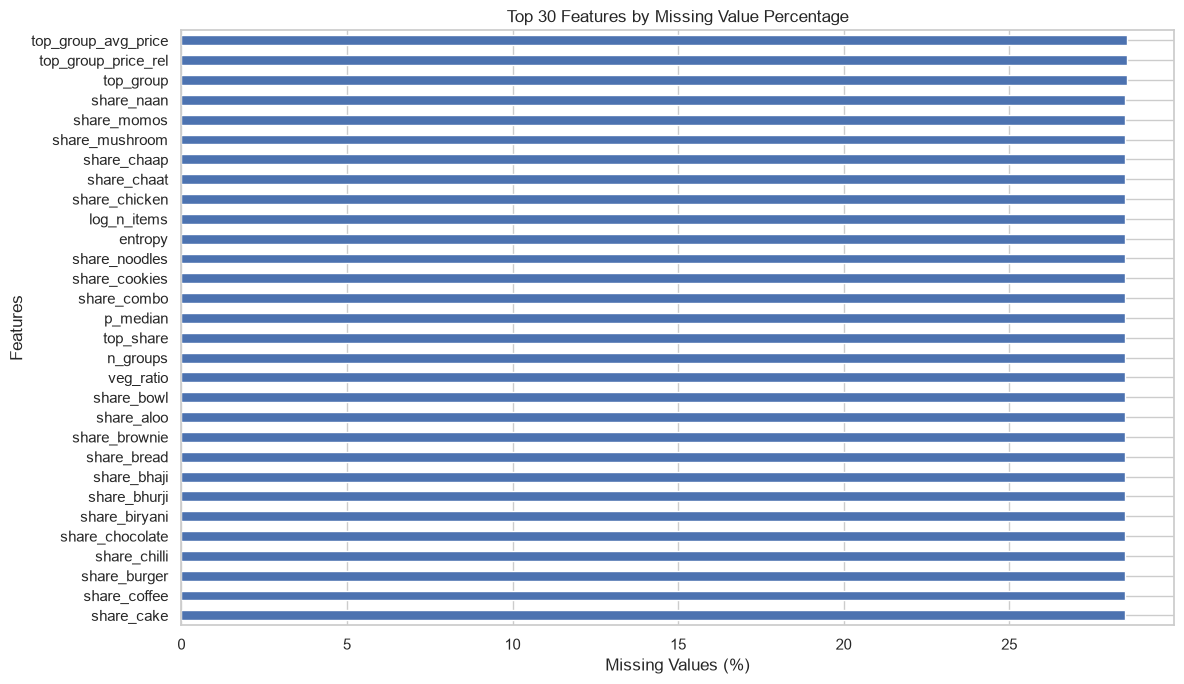

In [4]:
plt.figure(figsize=(12, 7))

missing_df["Missing_Percentage"].head(30).sort_values().plot(
    kind="barh"
)

plt.title("Top 30 Features by Missing Value Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/eda/missing_values_top30.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
dtype_summary = (
    df.dtypes.astype(str)
    .value_counts()
    .reset_index()
)

dtype_summary.columns = ["Data_Type", "Column_Count"]

display(dtype_summary)

dtype_summary.to_csv(
    "../outputs/tables/eda/data_type_summary.csv",
    index=False
)

,Data_Type,Column_Count
0,float64,115
1,str,9
2,int64,3


In [6]:
categorical_cols = df.select_dtypes(include="object").columns

categorical_summary = pd.DataFrame({
    "Column": categorical_cols,
    "Unique_Values": [df[col].nunique() for col in categorical_cols],
    "Missing_Values": [df[col].isnull().sum() for col in categorical_cols]
})

display(categorical_summary)

categorical_summary.to_csv(
    "../outputs/tables/eda/categorical_summary.csv",
    index=False
)

,Column,Unique_Values,Missing_Values
0,name,45003,0
1,city,782,0
2,rating_count,7,542
3,cost,262,17
4,cuisine,4447,4
5,lic_no,48566,5618
6,menu,61993,5537
7,state,31,6180
8,top_group,76,19282


In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate restaurant names:", df["name"].duplicated().sum())

print("Duplicate license numbers:", df["lic_no"].duplicated().sum())

print("Unique cities:", df["city"].nunique())
print("Unique states:", df["state"].nunique())

Exact duplicate rows: 0
Duplicate restaurant names: 22527
Duplicate license numbers: 18963
Unique cities: 782
Unique states: 31


## 2. Menu Data Availability Analysis

This section investigates whether missing menu features are associated with
the availability of menu information.

The analysis will compare the `has_menu` indicator with missing values in
the raw menu and engineered menu features.

The objective is to understand the reason for missingness before selecting
an appropriate treatment strategy.

In [11]:
menu_feature_cols = [
    col for col in df.columns
    if col.startswith("share_")
]

menu_summary_cols = [
    "log_n_items",
    "n_groups",
    "entropy",
    "top_share",
    "top_group",
    "p_median",
    "top_group_avg_price",
    "top_group_price_rel",
    "veg_ratio"
]

menu_cols = [
    col for col in menu_summary_cols + menu_feature_cols
    if col in df.columns
]

print("Rows with menu information:")
print(df["has_menu"].value_counts(dropna=False))

print("\nMissing raw menu values:")
print(df["menu"].isnull().sum())

print("\nMissing menu feature values:")
print(df[menu_cols].isnull().sum().sum())

print("\nMissing menu features by has_menu:")
display(
    df.groupby("has_menu")[menu_cols]
    .apply(lambda x: x.isnull().mean() * 100)
    .round(2)
)

Rows with menu information:
has_menu
1    48285
0    19245
Name: count, dtype: int64

Missing raw menu values:
5537

Missing menu feature values:
1732161

Missing menu features by has_menu:


,log_n_items,n_groups,entropy,top_share,top_group,p_median,top_group_avg_price,top_group_price_rel,veg_ratio,share_aloo,share_bhaji,share_bhurji,share_biryani,share_bowl,share_bread,share_brownie,share_burger,share_cake,share_chaap,share_chaat,share_chicken,share_chilli,share_chocolate,share_coffee,share_combo,share_cookies,share_corn,share_curry,share_dip,share_dosa,share_drink,share_falooda,share_fish,share_fries,share_fry,share_gobi,share_icecream,share_idli,share_jamun,share_juice,share_kachori,share_kebab,share_kofta,share_kulcha,share_kulfi,share_lassi,share_lollipop,share_maggi,share_manchurian,share_milk,share_mix,share_mojito,share_momos,share_mushroom,share_naan,share_noodles,share_nuggets,share_omelette,share_other,share_pakora,share_paneer,share_papad,share_paratha,share_pasta,share_pastry,share_pepsi,share_pizza,share_potato,share_prawns,share_puff,share_pulao,share_puri,share_raita,share_rice,share_roll,share_roti,share_salad,share_sandwich,share_shake,share_smoothie,share_soup,share_tea,share_thali,share_thums,share_tikka,share_uttapam,share_vada,share_water,share_wings,share_wrap
has_menu,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
1,0.0000,0.0000,0.0000,0.0000,0.0800,0.0000,0.0800,0.0800,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [10]:
menu_availability = pd.DataFrame({
    "has_menu": df["has_menu"].value_counts(dropna=False),
    "percentage": (
        df["has_menu"].value_counts(normalize=True, dropna=False) * 100
    ).round(2)
})

display(menu_availability)

menu_availability.to_csv(
    "../outputs/tables/eda/menu_availability.csv"
)

,has_menu,percentage
has_menu,,
1,48285,71.5000
0,19245,28.5000


## 3. Restaurant Identity and Branch Analysis

Restaurant names and license numbers may be repeated because restaurant
brands can operate multiple branches.

This analysis checks whether repeated identities occur across different
cities and locations.

Repeated records will not be removed without establishing that they
represent duplicate observations.

In [14]:
print("Most frequently repeated restaurant names:")
display(
    df["name"].value_counts()
    .head(15)
    .to_frame("Branch_Count")
)

print("\nMost frequently repeated license numbers:")
display(
    df["lic_no"].value_counts()
    .head(15)
    .to_frame("Record_Count")
)

print("\nRestaurants with repeated names across cities:")
repeated_names = df[df["name"].duplicated(keep=False)]

display(
    repeated_names.groupby("name")
    .agg(
        Record_Count=("name", "size"),
        City_Count=("city", "nunique"),
        State_Count=("state", "nunique")
    )
    .sort_values("Record_Count", ascending=False)
    .head(15)
)

Most frequently repeated restaurant names:


,Branch_Count
name,
Domino's Pizza,419
Pizza Hut,332
KFC,328
Subway,239
Kwality Walls Frozen Dessert and Ice Cream Shop,236
Baskin Robbins,228
McDonald's,204
Faasos - Wraps & Rolls,197
Oven Story Pizza,194



Most frequently repeated license numbers:


,Record_Count
lic_no,
license,4610
20821005002577,37
10012011000726,27
11522006000061,24
20621001000571,23
10100000000000,22
23321002002837,20
21519163001617,18
21222192000578,18



Restaurants with repeated names across cities:


,Record_Count,City_Count,State_Count
name,,,
Domino's Pizza,419,417,28
Pizza Hut,332,322,26
KFC,328,313,28
Subway,239,231,20
Kwality Walls Frozen Dessert and Ice Cream Shop,236,235,22
Baskin Robbins,228,227,22
McDonald's,204,194,19
Faasos - Wraps & Rolls,197,197,21
Oven Story Pizza,194,194,20


## 4. Target Variable Analysis

The proposed target variable is `weighted_rating`.

This section examines its distribution, central tendency, variability,
and relationship with the raw restaurant rating.

The objective is to determine whether weighted rating is a suitable
regression target and identify any unusual or invalid values.

In [16]:
target_col = "weighted_rating"

print("Target missing values:", df[target_col].isnull().sum())
print("\nTarget descriptive statistics:")
display(df[target_col].describe().to_frame("weighted_rating"))

print("\nRaw rating descriptive statistics:")
display(df["rating"].describe().to_frame("rating"))

print("\nTarget and raw rating correlation:")
print(df[[target_col, "rating"]].corr().iloc[0, 1])

print("\nTarget values outside the expected 1–5 range:")
print(
    ((df[target_col] < 1) | (df[target_col] > 5)).sum()
)

Target missing values: 0

Target descriptive statistics:


,weighted_rating
count,67530.0000
mean,3.9372
std,0.1690
min,2.4467
25%,3.8451
50%,3.9285
75%,4.0285
max,4.7357



Raw rating descriptive statistics:


,rating
count,67530.0000
mean,3.9142
std,0.4622
min,1.0000
25%,3.7000
50%,4.0000
75%,4.2000
max,5.0000



Target and raw rating correlation:
0.8386823022580475

Target values outside the expected 1–5 range:
0


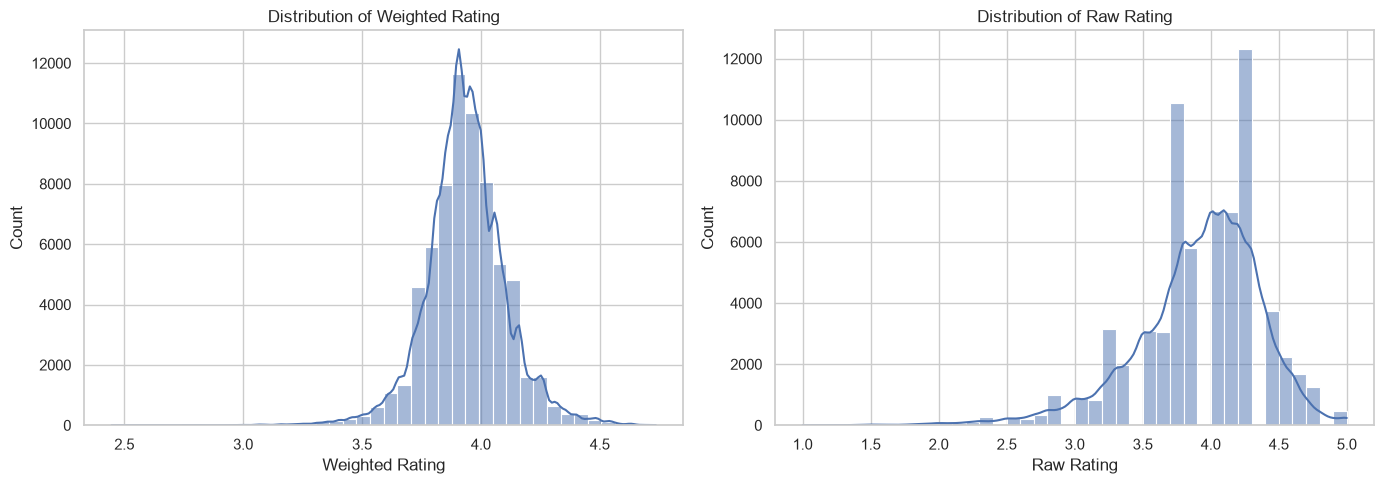

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["weighted_rating"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Weighted Rating")
axes[0].set_xlabel("Weighted Rating")

sns.histplot(df["rating"].dropna(), bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Raw Rating")
axes[1].set_xlabel("Raw Rating")

plt.tight_layout()
plt.savefig(
    "../outputs/figures/eda/target_rating_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [18]:
print("Rating count categories:")
display(
    df["rating_count"]
    .value_counts(dropna=False)
    .to_frame("Restaurant_Count")
)

print("\nWeighted rating by rating-count category:")
display(
    df.groupby("rating_count", dropna=False)
    .agg(
        Restaurant_Count=("weighted_rating", "count"),
        Mean_Weighted_Rating=("weighted_rating", "mean"),
        Mean_Raw_Rating=("rating", "mean")
    )
    .round(3)
    .sort_values("Restaurant_Count", ascending=False)
)

Rating count categories:


,Restaurant_Count
rating_count,
20+ ratings,23070
100+ ratings,22174
50+ ratings,12601
500+ ratings,5007
1K+ ratings,3650
NaN,542
5K+ ratings,276
10K+ ratings,210



Weighted rating by rating-count category:


,Restaurant_Count,Mean_Weighted_Rating,Mean_Raw_Rating
rating_count,,,
20+ ratings,23070,3.8910,3.7730
100+ ratings,22174,3.9520,3.9900
50+ ratings,12601,3.9140,3.9130
500+ ratings,5007,4.0290,4.0520
1K+ ratings,3650,4.0710,4.0870
NaN,542,3.9140,4.2070
5K+ ratings,276,4.1440,4.1480
10K+ ratings,210,4.1770,4.1800


## 5. Weighted Rating Validation

This section investigates how weighted rating differs from raw rating
across review-count categories.

The objective is to understand the effect of review volume on the target
and identify whether missing review counts affect target reliability.

In [19]:
df["rating_difference"] = (
    df["weighted_rating"] - df["rating"]
)

rating_comparison = (
    df.groupby("rating_count", dropna=False)
    .agg(
        Restaurant_Count=("weighted_rating", "count"),
        Mean_Raw_Rating=("rating", "mean"),
        Mean_Weighted_Rating=("weighted_rating", "mean"),
        Mean_Difference=("rating_difference", "mean"),
        Std_Difference=("rating_difference", "std")
    )
    .round(4)
    .sort_values("Restaurant_Count", ascending=False)
)

display(rating_comparison)

rating_comparison.to_csv(
    "../outputs/tables/eda/weighted_rating_validation.csv"
)

,Restaurant_Count,Mean_Raw_Rating,Mean_Weighted_Rating,Mean_Difference,Std_Difference
rating_count,,,,,
20+ ratings,23070,3.7726,3.8906,0.1179,0.4816
100+ ratings,22174,3.9901,3.9522,-0.0380,0.1733
50+ ratings,12601,3.9128,3.9137,0.0009,0.2865
500+ ratings,5007,4.0519,4.0289,-0.0230,0.0498
1K+ ratings,3650,4.0866,4.0709,-0.0157,0.0264
NaN,542,4.2066,3.9142,-0.2925,0.3780
5K+ ratings,276,4.1482,4.1436,-0.0046,0.0057
10K+ ratings,210,4.1795,4.1769,-0.0026,0.0023


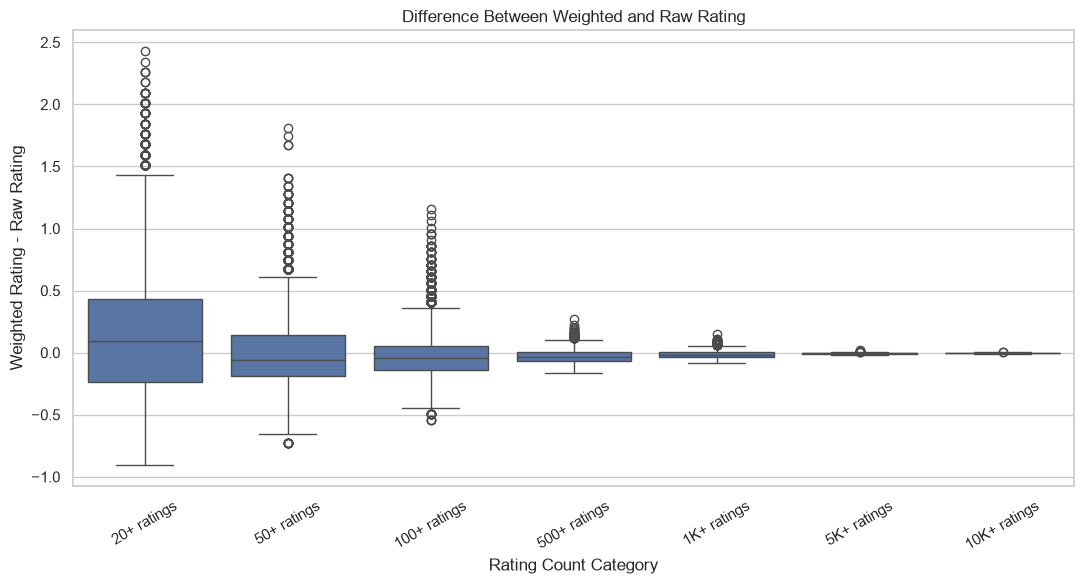

In [20]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="rating_count",
    y="rating_difference",
    order=[
        "20+ ratings",
        "50+ ratings",
        "100+ ratings",
        "500+ ratings",
        "1K+ ratings",
        "5K+ ratings",
        "10K+ ratings"
    ]
)

plt.title("Difference Between Weighted and Raw Rating")
plt.xlabel("Rating Count Category")
plt.ylabel("Weighted Rating - Raw Rating")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/eda/weighted_vs_raw_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Custom IMDb-Style Weighted Rating Generation

The target variable will be generated using the IMDb-style Bayesian
weighted-rating formula:

WR = (v / (v + m)) * R + (m / (v + m)) * C

Where:
- R: Raw restaurant rating
- v: Approximate number of ratings
- m: Minimum rating-count threshold
- C: Overall mean raw rating

Since exact review counts are unavailable, the lower bounds of the
rating-count categories will be used as approximations.

A sensitivity analysis will compare different values of m before
selecting the final target configuration.

In [21]:
rating_count_mapping = {
    "20+ ratings": 20,
    "50+ ratings": 50,
    "100+ ratings": 100,
    "500+ ratings": 500,
    "1K+ ratings": 1000,
    "5K+ ratings": 5000,
    "10K+ ratings": 10000
}

df["approx_rating_count"] = df["rating_count"].map(
    rating_count_mapping
)

global_mean_rating = df["rating"].mean()

print("Global mean raw rating:", round(global_mean_rating, 4))
print("Rows with approximate rating counts:",
      df["approx_rating_count"].notna().sum())
print("Rows without rating counts:",
      df["approx_rating_count"].isna().sum())

display(
    df[["rating_count", "approx_rating_count"]]
    .value_counts(dropna=False)
    .to_frame("Restaurant_Count")
)

Global mean raw rating: 3.9142
Rows with approximate rating counts: 66988
Rows without rating counts: 542


,,Restaurant_Count
rating_count,approx_rating_count,
20+ ratings,20.0000,23070
100+ ratings,100.0000,22174
50+ ratings,50.0000,12601
500+ ratings,500.0000,5007
1K+ ratings,1000.0000,3650
NaN,NaN,542
5K+ ratings,5000.0000,276
10K+ ratings,10000.0000,210


In [22]:
m_values = [50, 100, 200, 500]

sensitivity_results = []

for m in m_values:
    valid = df["approx_rating_count"].notna()

    v = df.loc[valid, "approx_rating_count"]
    r = df.loc[valid, "rating"]

    weighted_rating = (
        (v / (v + m)) * r
        + (m / (v + m)) * global_mean_rating
    )

    sensitivity_results.append({
        "m": m,
        "Mean_Target": weighted_rating.mean(),
        "Std_Target": weighted_rating.std(),
        "Min_Target": weighted_rating.min(),
        "Max_Target": weighted_rating.max(),
        "Mean_Absolute_Adjustment": (
            weighted_rating - r
        ).abs().mean(),
        "Correlation_With_Raw_Rating": (
            weighted_rating.corr(r)
        ),
        "Correlation_With_Existing_Weighted_Rating": (
            weighted_rating.corr(
                df.loc[valid, "weighted_rating"]
            )
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

sensitivity_df.to_csv(
    "../outputs/tables/eda/weighted_rating_sensitivity.csv",
    index=False
)

,m,Mean_Target,Std_Target,Min_Target,Max_Target,Mean_Absolute_Adjustment,Correlation_With_Raw_Rating,Correlation_With_Existing_Weighted_Rating
0,50,3.9370,0.2233,2.3714,4.8104,0.1768,0.9131,0.9865
1,100,3.9374,0.1697,2.4467,4.7357,0.2235,0.8431,1.0000
2,200,3.9350,0.1262,2.5690,4.6846,0.2627,0.7518,0.9830
3,500,3.9295,0.0836,2.8381,4.6626,0.3001,0.6185,0.9130


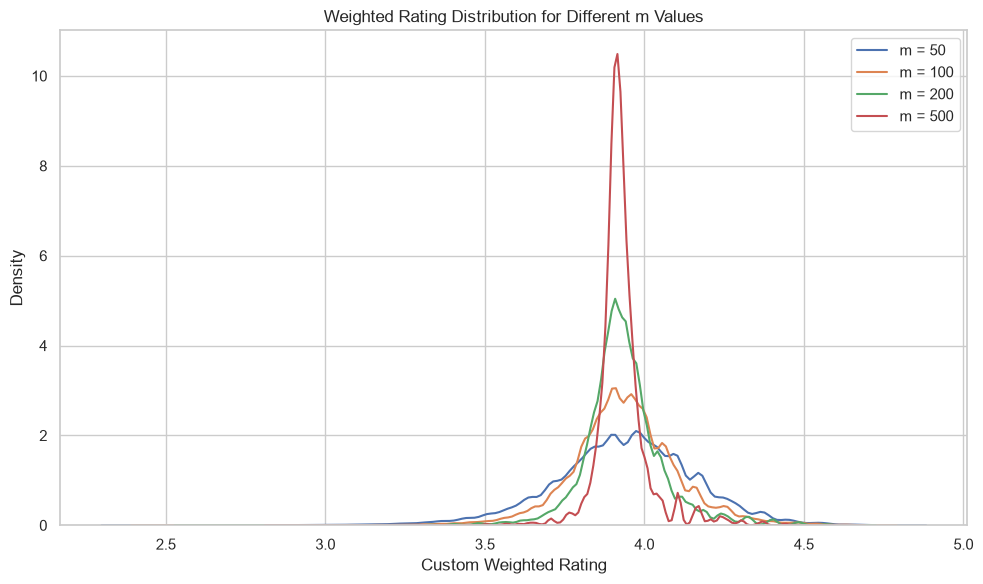

In [23]:
plt.figure(figsize=(10, 6))

for m in m_values:
    valid = df["approx_rating_count"].notna()

    v = df.loc[valid, "approx_rating_count"]
    r = df.loc[valid, "rating"]

    target = (
        (v / (v + m)) * r
        + (m / (v + m)) * global_mean_rating
    )

    sns.kdeplot(target, label=f"m = {m}")

plt.title("Weighted Rating Distribution for Different m Values")
plt.xlabel("Custom Weighted Rating")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/figures/eda/weighted_rating_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Existing Weighted Rating Formula Verification

This section checks whether the existing weighted_rating column
was generated using the same IMDb-style formula with m = 100.

The comparison uses:
- Pearson correlation
- Mean absolute difference
- Maximum absolute difference
- Mean squared difference

This helps determine whether a new target calculation is necessary.

In [24]:
m = 100

v = df["approx_rating_count"]
r = df["rating"]
c = global_mean_rating

calculated_rating = (
    (v / (v + m)) * r
    + (m / (v + m)) * c
)

valid = calculated_rating.notna()

comparison = pd.DataFrame({
    "Calculated_Rating": calculated_rating[valid],
    "Existing_Weighted_Rating": df.loc[valid, "weighted_rating"]
})

comparison["Absolute_Difference"] = (
    comparison["Calculated_Rating"]
    - comparison["Existing_Weighted_Rating"]
).abs()

print("Correlation:",
      comparison["Calculated_Rating"].corr(
          comparison["Existing_Weighted_Rating"]
      ))

print("Mean absolute difference:",
      comparison["Absolute_Difference"].mean())

print("Maximum absolute difference:",
      comparison["Absolute_Difference"].max())

print("Mean squared difference:",
      (
          comparison["Absolute_Difference"] ** 2
      ).mean())

print("\nSample comparison:")
display(comparison.head(10))

Correlation: 0.9999999999999997
Mean absolute difference: 8.32982164233301e-17
Maximum absolute difference: 1.3322676295501878e-15
Mean squared difference: 5.809470443484738e-32

Sample comparison:


,Calculated_Rating,Existing_Weighted_Rating,Absolute_Difference
0,4.1571,4.1571,0.0000
1,3.8571,3.8571,0.0000
2,3.8190,3.8190,0.0000
3,4.1071,4.1071,0.0000
4,4.0761,4.0761,0.0000
5,4.0071,4.0071,0.0000
6,4.0071,4.0071,0.0000
7,3.9285,3.9285,0.0000
8,3.9618,3.9618,0.0000
9,3.8618,3.8618,0.0000


In [25]:
missing_count_rows = df[df["rating_count"].isna()]

print("Rows with missing rating count:", len(missing_count_rows))

print(
    "Unique weighted ratings among these rows:",
    missing_count_rows["weighted_rating"].nunique()
)

print(
    "Global mean raw rating:",
    global_mean_rating
)

print(
    "Mean weighted rating for missing-count rows:",
    missing_count_rows["weighted_rating"].mean()
)

display(
    missing_count_rows[
        ["rating", "rating_count", "weighted_rating"]
    ].head(10)
)

Rows with missing rating count: 542
Unique weighted ratings among these rows: 1
Global mean raw rating: 3.9141625944024883
Mean weighted rating for missing-count rows: 3.9141625944024887


,rating,rating_count,weighted_rating
23,2.8000,NaN,3.9142
24,4.0000,NaN,3.9142
25,4.3000,NaN,3.9142
26,4.3000,NaN,3.9142
28,3.7000,NaN,3.9142
29,3.5000,NaN,3.9142
30,4.4000,NaN,3.9142
31,3.5000,NaN,3.9142
32,4.1000,NaN,3.9142
33,4.3000,NaN,3.9142


## 8. Feature Classification and Leakage Investigation

This section classifies dataset columns according to their role in
the proposed restaurant location prediction system.

The objective is to identify useful restaurant and location features,
remove target leakage, and investigate features that may not be
available when predicting ratings for a new restaurant.

In [26]:
print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(f"{i:3}. {col}")

Total columns: 129
  1. name
  2. city
  3. rating
  4. rating_count
  5. cost
  6. cuisine
  7. lic_no
  8. menu
  9. lat
 10. lng
 11. state
 12. college_n_500m
 13. college_n_1000m
 14. college_nearest_m
 15. hospital_n_500m
 16. hospital_n_1000m
 17. hospital_nearest_m
 18. mall_n_500m
 19. mall_n_1000m
 20. mall_nearest_m
 21. market_n_500m
 22. market_n_1000m
 23. market_nearest_m
 24. office_n_500m
 25. office_n_1000m
 26. office_nearest_m
 27. school_n_500m
 28. school_n_1000m
 29. school_nearest_m
 30. weighted_rating
 31. city_restaurant_count
 32. brand_branch_count_city
 33. cuisine_restaurant_count_city
 34. avg_cuisine_rating_city
 35. district_population
 36. district_wealth_index
 37. log_n_items
 38. n_groups
 39. entropy
 40. top_share
 41. top_group
 42. p_median
 43. top_group_avg_price
 44. top_group_price_rel
 45. veg_ratio
 46. share_aloo
 47. share_bhaji
 48. share_bhurji
 49. share_biryani
 50. share_bowl
 51. share_bread
 52. share_brownie
 53. share_burger
 5

In [27]:
market_cols = [
    "city_restaurant_count",
    "brand_branch_count_city",
    "cuisine_restaurant_count_city",
    "avg_cuisine_rating_city",
    "district_population",
    "district_wealth_index"
]

market_summary = df[market_cols].describe().T

market_summary["Missing_Count"] = df[market_cols].isnull().sum()
market_summary["Missing_Percentage"] = (
    df[market_cols].isnull().mean() * 100
)

display(market_summary.round(3))

market_summary.to_csv(
    "../outputs/tables/eda/market_feature_summary.csv"
)

,count,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
city_restaurant_count,67530.0000,241.1440,208.8390,1.0000,92.0000,181.0000,330.0000,878.0000,0,0.0000
brand_branch_count_city,67530.0000,1.0180,0.1640,1.0000,1.0000,1.0000,1.0000,5.0000,0,0.0000
cuisine_restaurant_count_city,67526.0000,32.0680,36.7870,1.0000,9.0000,19.5000,40.0000,307.0000,4,0.0060
avg_cuisine_rating_city,67526.0000,3.9150,0.2440,1.5000,3.7720,3.9350,4.0830,5.0000,4,0.0060
district_population,66864.0000,4358446.3910,2966146.8130,52074.0000,2159775.0000,3936331.0000,5838465.0000,11060148.0000,666,0.9860
district_wealth_index,66864.0000,1.7210,1.2930,-0.9620,0.5560,1.8760,2.8190,3.9200,666,0.9860


### Market Feature Correlation Analysis

This analysis examines the relationship between market and demographic
features and the weighted rating target.

Correlation is used for exploration, not as proof of feature importance
or as the sole criterion for removing features.

In [28]:
market_cols = [
    "city_restaurant_count",
    "brand_branch_count_city",
    "cuisine_restaurant_count_city",
    "avg_cuisine_rating_city",
    "district_population",
    "district_wealth_index"
]

market_target_corr = (
    df[market_cols + ["weighted_rating"]]
    .corr(numeric_only=True)["weighted_rating"]
    .drop("weighted_rating")
    .sort_values(key=abs, ascending=False)
)

display(market_target_corr.to_frame("Target_Correlation"))

market_target_corr.to_csv(
    "../outputs/tables/eda/market_target_correlation.csv"
)

,Target_Correlation
avg_cuisine_rating_city,0.5475
district_wealth_index,0.1879
city_restaurant_count,0.1737
district_population,0.1090
brand_branch_count_city,0.0734
cuisine_restaurant_count_city,0.0467


### Market Feature Correlation Heatmap

Visualize the correlations between market features and the target
to identify relationships and potential redundancy.

This is an exploratory analysis, not a final feature-selection rule.

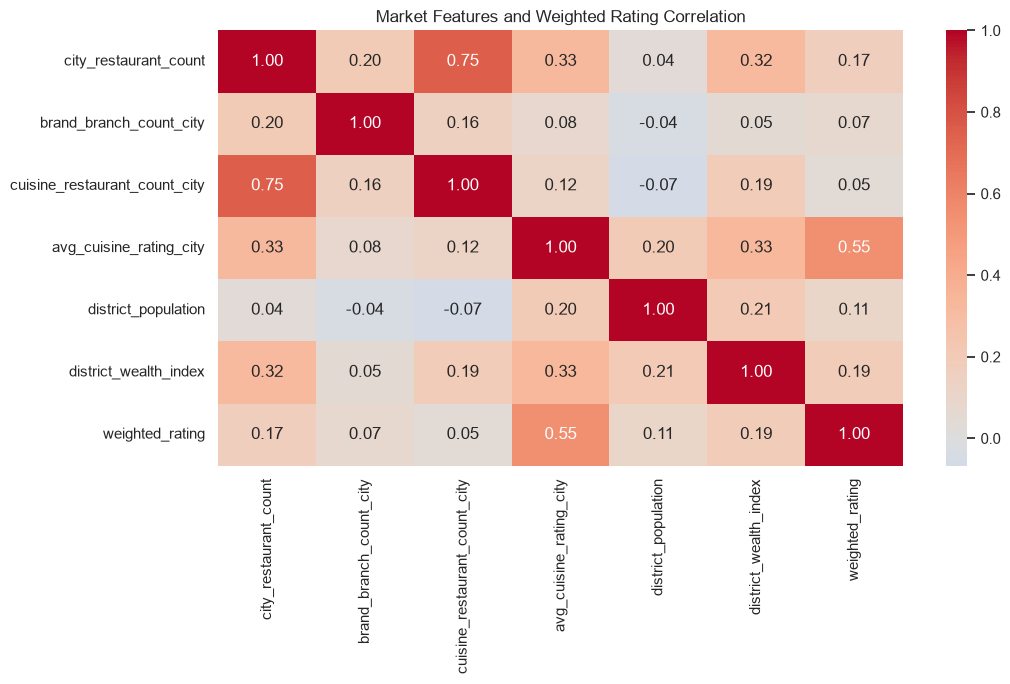

In [29]:
plt.figure(figsize=(11, 7))

sns.heatmap(
    df[market_cols + ["weighted_rating"]].corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Market Features and Weighted Rating Correlation")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/eda/market_feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Investigation of Cuisine Average Rating

Investigate whether the average cuisine rating feature contains
the restaurant's own rating.

This helps identify self-inclusion and potential target leakage
in the market-level aggregate.

In [30]:
sample_cols = [
    "name",
    "city",
    "cuisine",
    "rating",
    "weighted_rating",
    "avg_cuisine_rating_city",
    "cuisine_restaurant_count_city"
]

display(
    df[sample_cols]
    .dropna(subset=["avg_cuisine_rating_city"])
    .sample(15, random_state=RANDOM_STATE)
    .sort_values(["city", "cuisine"])
)

,name,city,cuisine,rating,weighted_rating,avg_cuisine_rating_city,cuisine_restaurant_count_city
34025,Chandralok Kachouri,Allahabad,"Snacks,South Indian",4.0000,3.9922,3.7700,25.0000
22047,Deccan Elite Multi Cuisine restaurant,"Attapur,Hyderabad","Biryani,North Indian",4.1000,4.0831,3.6718,34.0000
63781,Zomoz - The Momo Company,"Baner,Pune","Chinese,Fast Food",4.4000,4.0761,3.9472,46.5000
18295,Hong Kong,Bhopal,Chinese,4.0000,3.9285,3.7400,60.0000
24646,Oven Story Pizza,"Bhosari,Pune",Pizzas,3.7000,3.8071,3.6846,13.0000
46400,SRI SAI CAKE BAKE,Dhar,Bakery,3.4000,3.7428,3.4000,1.0000
41366,One Bite,"GOTA,Ahmedabad",Italian,4.1000,3.9451,3.8000,4.0000
15443,The Belgian Waffle Co.,"Gomti Nagar,Lucknow","Desserts,Beverages",4.5000,4.2071,4.1152,16.5000
17313,Madurai Idly Shop,"Kammanahalli/Kalyan Nagar,Bangalore",South Indian,3.6000,3.7571,3.9462,39.0000
12750,Rajathadri Palace,"Kumaraswamy Layout & Uttarahalli,Bangalore","Indian,Chinese",4.3000,4.2649,4.0444,10.5000


### Data Leakage Audit – Initial Feature Decisions

The following features are excluded from model inputs because they
directly reveal the target, are derived from target-related information,
or are identifiers/raw fields unsuitable for prediction.

The average cuisine rating feature is excluded because sample inspection
suggests that it may include the restaurant's own rating.

Market count features are retained provisionally, subject to validation
of their calculation and availability at prediction time.

In [32]:
leakage_audit = pd.DataFrame([
    ["rating", "Exclude", "Raw rating contributes directly to weighted_rating"],
    ["rating_count", "Exclude", "Review count is used to construct the target"],
    ["weighted_rating", "Target only", "Prediction target"],
    ["rating_difference", "Exclude", "Derived using target and raw rating"],
    ["approx_rating_count", "Exclude", "Derived from rating_count"],
    ["avg_cuisine_rating_city", "Exclude", "Potential self-inclusion of target-related ratings"],
    ["lic_no", "Exclude", "Administrative identifier"],
    ["menu", "Exclude", "Raw menu field; engineered menu features are available"]
], columns=["Feature", "Decision", "Reason"])

display(leakage_audit)

leakage_audit.to_csv(
    "../outputs/tables/eda/leakage_audit.csv",
    index=False
)

,Feature,Decision,Reason
0,rating,Exclude,Raw rating contributes directly to weighted_ra...
1,rating_count,Exclude,Review count is used to construct the target
2,weighted_rating,Target only,Prediction target
3,rating_difference,Exclude,Derived using target and raw rating
4,approx_rating_count,Exclude,Derived from rating_count
5,avg_cuisine_rating_city,Exclude,Potential self-inclusion of target-related rat...
6,lic_no,Exclude,Administrative identifier
7,menu,Exclude,Raw menu field; engineered menu features are a...


### Constant and Near-Constant Feature Analysis

Identify features with only one unique value or very low variation.

Constant features provide no predictive information. Near-constant
features will be reviewed before deciding whether to remove them.

In [33]:
feature_variation = pd.DataFrame({
    "Unique_Values": df.nunique(dropna=False),
    "Unique_Percentage": (
        df.nunique(dropna=False) / len(df) * 100
    ).round(3)
})

feature_variation = feature_variation.sort_values(
    "Unique_Values"
)

display(feature_variation.head(30))

constant_features = feature_variation[
    feature_variation["Unique_Values"] == 1
]

print("Constant features:", len(constant_features))
display(constant_features)

feature_variation.to_csv(
    "../outputs/tables/eda/feature_variation_analysis.csv"
)

,Unique_Values,Unique_Percentage
has_menu,2,0.0030
brand_branch_count_city,5,0.0070
rating_count,8,0.0120
approx_rating_count,8,0.0120
state,32,0.0470
school_n_500m,35,0.0520
rating,41,0.0610
mall_n_500m,42,0.0620
college_n_500m,43,0.0640
hospital_n_500m,46,0.0680


Constant features: 0


,Unique_Values,Unique_Percentage


### Near-Constant Feature Analysis

Identify features where a single value dominates most observations.

Features with highly imbalanced value distributions will be reviewed
before deciding whether they should be removed.

In [34]:
low_cardinality_features = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 10
]

near_constant_summary = []

for col in low_cardinality_features:
    value_counts = df[col].value_counts(dropna=False)

    near_constant_summary.append({
        "Feature": col,
        "Most_Common_Value": str(value_counts.index[0]),
        "Most_Common_Count": value_counts.iloc[0],
        "Most_Common_Percentage": (
            value_counts.iloc[0] / len(df) * 100
        )
    })

near_constant_df = pd.DataFrame(near_constant_summary)

near_constant_df = near_constant_df.sort_values(
    "Most_Common_Percentage",
    ascending=False
)

display(near_constant_df.round(2))

near_constant_df.to_csv(
    "../outputs/tables/eda/near_constant_analysis.csv",
    index=False
)

,Feature,Most_Common_Value,Most_Common_Count,Most_Common_Percentage
1,brand_branch_count_city,1,66532,98.5200
2,has_menu,1,48285,71.5000
0,rating_count,20+ ratings,23070,34.1600
3,approx_rating_count,20.0,23070,34.1600


In [35]:
additional_audit = pd.DataFrame([
    [
        "brand_branch_count_city",
        "Exclude",
        "Near-constant feature; 98.52% of observations have value 1"
    ],
    [
        "has_menu",
        "Retain",
        "Meaningful indicator of menu information availability"
    ]
], columns=["Feature", "Decision", "Reason"])

leakage_audit = pd.concat(
    [leakage_audit, additional_audit],
    ignore_index=True
)

leakage_audit = leakage_audit.drop_duplicates(
    subset=["Feature"],
    keep="last"
)

display(leakage_audit)

leakage_audit.to_csv(
    "../outputs/tables/eda/leakage_audit.csv",
    index=False
)

,Feature,Decision,Reason
0,rating,Exclude,Raw rating contributes directly to weighted_ra...
1,rating_count,Exclude,Review count is used to construct the target
2,weighted_rating,Target only,Prediction target
3,rating_difference,Exclude,Derived using target and raw rating
4,approx_rating_count,Exclude,Derived from rating_count
5,avg_cuisine_rating_city,Exclude,Potential self-inclusion of target-related rat...
6,lic_no,Exclude,Administrative identifier
7,menu,Exclude,Raw menu field; engineered menu features are a...
8,brand_branch_count_city,Exclude,Near-constant feature; 98.52% of observations ...
9,has_menu,Retain,Meaningful indicator of menu information avail...


### Geographic Feature Analysis

Analyze latitude, longitude, and nearby facility features
to understand geographic coverage, missing values, and
the distribution of surrounding infrastructure.

In [36]:
geo_cols = [
    "lat",
    "lng",
    "college_n_500m",
    "college_n_1000m",
    "hospital_n_500m",
    "hospital_n_1000m",
    "mall_n_500m",
    "mall_n_1000m",
    "market_n_500m",
    "market_n_1000m",
    "office_n_500m",
    "office_n_1000m",
    "school_n_500m",
    "school_n_1000m"
]

geo_summary = df[geo_cols].describe().T

geo_summary["Missing_Count"] = df[geo_cols].isnull().sum()
geo_summary["Missing_Percentage"] = (
    df[geo_cols].isnull().mean() * 100
)

display(geo_summary.round(3))

geo_summary.to_csv(
    "../outputs/tables/eda/geographic_feature_summary.csv"
)

,count,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
lat,67426.0000,20.5800,6.4020,8.0820,13.1200,20.8620,26.8840,37.9770,104,0.1540
lng,67426.0000,78.2490,4.2860,23.7310,76.2850,77.5660,80.0420,95.3880,104,0.1540
college_n_500m,64944.0000,2.7830,3.4690,0.0000,0.0000,2.0000,4.0000,52.0000,2586,3.8290
college_n_1000m,64944.0000,8.8650,7.8720,0.0000,3.0000,7.0000,13.0000,75.0000,2586,3.8290
hospital_n_500m,64945.0000,2.9820,3.1890,0.0000,1.0000,2.0000,4.0000,50.0000,2585,3.8280
hospital_n_1000m,64945.0000,9.2880,6.9770,0.0000,4.0000,8.0000,13.0000,65.0000,2585,3.8280
mall_n_500m,64945.0000,5.3930,5.6640,0.0000,1.0000,4.0000,7.0000,41.0000,2585,3.8280
mall_n_1000m,64945.0000,14.0160,9.4740,0.0000,7.0000,12.0000,20.0000,59.0000,2585,3.8280
market_n_500m,64945.0000,5.7740,6.6690,0.0000,2.0000,4.0000,7.0000,80.0000,2585,3.8280
market_n_1000m,64945.0000,16.5610,11.9780,0.0000,8.0000,13.0000,21.0000,96.0000,2585,3.8280


### Geographic Missing Value Investigation

Examine the relationship between missing latitude/longitude
and missing nearby-facility information.

Determine whether missing facility values are associated
with unavailable coordinates or other enrichment issues.

In [37]:
nearby_cols = [
    col for col in geo_cols
    if col not in ["lat", "lng"]
]

missing_geo_analysis = pd.DataFrame({
    "Missing_Latitude": df["lat"].isna(),
    "Missing_Longitude": df["lng"].isna(),
    "Missing_All_Nearby": df[nearby_cols].isna().all(axis=1),
    "Missing_Any_Nearby": df[nearby_cols].isna().any(axis=1)
})

print("Rows with missing latitude:", missing_geo_analysis["Missing_Latitude"].sum())
print("Rows with missing longitude:", missing_geo_analysis["Missing_Longitude"].sum())
print("Rows with missing coordinates:",
      (missing_geo_analysis["Missing_Latitude"] |
       missing_geo_analysis["Missing_Longitude"]).sum())

print("Rows with all nearby features missing:",
      missing_geo_analysis["Missing_All_Nearby"].sum())

print("Rows with any nearby feature missing:",
      missing_geo_analysis["Missing_Any_Nearby"].sum())

print(
    "Rows with missing coordinates and all nearby features missing:",
    (
        (missing_geo_analysis["Missing_Latitude"] |
         missing_geo_analysis["Missing_Longitude"]) &
        missing_geo_analysis["Missing_All_Nearby"]
    ).sum()
)

Rows with missing latitude: 104
Rows with missing longitude: 104
Rows with missing coordinates: 104
Rows with all nearby features missing: 2585
Rows with any nearby feature missing: 2586
Rows with missing coordinates and all nearby features missing: 104


### Detailed Nearby Feature Missingness

Identify rows with partially missing nearby-facility features
and examine missing-value patterns across facility categories.

In [38]:
nearby_missing_count = df[nearby_cols].isna().sum(axis=1)

print("Rows with no nearby features missing:",
      (nearby_missing_count == 0).sum())

print("Rows with all nearby features missing:",
      (nearby_missing_count == len(nearby_cols)).sum())

print("Rows with partially missing nearby features:",
      ((nearby_missing_count > 0) &
       (nearby_missing_count < len(nearby_cols))).sum())

partial_missing_rows = df.loc[
    (nearby_missing_count > 0) &
    (nearby_missing_count < len(nearby_cols)),
    ["name", "city", "lat", "lng"] + nearby_cols
]

display(partial_missing_rows)

nearby_missing_summary = pd.DataFrame({
    "Missing_Count": df[nearby_cols].isna().sum(),
    "Missing_Percentage": (
        df[nearby_cols].isna().mean() * 100
    )
}).sort_values("Missing_Percentage", ascending=False)

display(nearby_missing_summary.round(3))

nearby_missing_summary.to_csv(
    "../outputs/tables/eda/nearby_feature_missingness.csv"
)

Rows with no nearby features missing: 64944
Rows with all nearby features missing: 2585
Rows with partially missing nearby features: 1


,name,city,lat,lng,college_n_500m,college_n_1000m,hospital_n_500m,hospital_n_1000m,mall_n_500m,mall_n_1000m,market_n_500m,market_n_1000m,office_n_500m,office_n_1000m,school_n_500m,school_n_1000m
64383,VISHNU FRESH JUICE,Ambur,12.6775,78.6324,NaN,NaN,0.0000,0.0000,1.0000,2.0000,1.0000,2.0000,3.0000,6.0000,1.0000,4.0000


,Missing_Count,Missing_Percentage
college_n_500m,2586,3.8290
college_n_1000m,2586,3.8290
hospital_n_500m,2585,3.8280
hospital_n_1000m,2585,3.8280
mall_n_500m,2585,3.8280
mall_n_1000m,2585,3.8280
market_n_500m,2585,3.8280
market_n_1000m,2585,3.8280
office_n_500m,2585,3.8280
office_n_1000m,2585,3.8280


### Restaurant Profile Feature Analysis

Analyze restaurant cost, cuisine, menu structure, and dish composition.

Understand their distributions, missing values, and suitability
for predicting restaurant ratings at candidate locations.

In [39]:
profile_cols = [
    "cost",
    "cuisine",
    "has_menu",
    "log_n_items",
    "n_groups",
    "entropy",
    "top_share",
    "top_group",
    "p_median",
    "top_group_avg_price",
    "top_group_price_rel",
    "veg_ratio"
]

profile_summary = df[profile_cols].describe(include="all").T

profile_summary["Missing_Count"] = df[profile_cols].isna().sum()
profile_summary["Missing_Percentage"] = (
    df[profile_cols].isna().mean() * 100
)

display(profile_summary)

profile_summary.to_csv(
    "../outputs/tables/eda/restaurant_profile_summary.csv"
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
cost,67513,262,₹ 200,16164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17,0.0252
cuisine,67526,4447,"North Indian,Chinese",2933,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,0.0059
has_menu,67530.0000,NaN,NaN,NaN,0.7150,0.4514,0.0000,0.0000,1.0000,1.0000,1.0000,0,0.0000
log_n_items,48285.0000,NaN,NaN,NaN,3.7119,0.8113,0.0000,3.1781,3.4340,4.3307,6.8200,19245,28.4984
n_groups,48285.0000,NaN,NaN,NaN,13.4734,7.9802,0.0000,8.0000,12.0000,16.0000,70.0000,19245,28.4984
entropy,48285.0000,NaN,NaN,NaN,2.1723,0.5377,-0.0000,1.9202,2.2294,2.4942,3.6603,19245,28.4984
top_share,48285.0000,NaN,NaN,NaN,0.2422,0.1431,0.0000,0.1579,0.2059,0.2750,1.0000,19245,28.4984
top_group,48248,76,curry,11014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19282,28.5532
p_median,48285.0000,NaN,NaN,NaN,154.9063,88.9542,5.0000,90.0000,140.0000,197.5000,1410.0000,19245,28.4984
top_group_avg_price,48248.0000,NaN,NaN,NaN,194.9311,130.1043,5.0000,102.3333,167.7778,249.5504,2383.3333,19282,28.5532


In [40]:
print("COST EXAMPLES")
display(df["cost"].value_counts().head(15))

print("\nCUISINE EXAMPLES")
display(df["cuisine"].value_counts().head(20))

print("\nCOST DATA TYPE")
print(df["cost"].dtype)

print("\nCUISINE DATA TYPE")
print(df["cuisine"].dtype)

COST EXAMPLES


cost
₹ 200     16164
₹ 300     12645
₹ 250      9124
₹ 400      6544
₹ 150      5227
₹ 500      3306
₹ 350      3261
₹ 100      2282
₹ 600      1573
₹ 450       914
₹ 800       692
₹ 120       548
₹ 700       479
₹ 199       431
₹ 1000      352
Name: count, dtype: int64


CUISINE EXAMPLES


cuisine
North Indian,Chinese         2933
North Indian                 2029
Indian                       2020
Indian,Chinese               1837
South Indian                 1736
Chinese                      1366
Pizzas                       1235
Bakery,Desserts              1143
Ice Cream,Desserts           1102
Chinese,North Indian          969
South Indian,North Indian     873
North Indian,Punjabi          836
North Indian,South Indian     813
Biryani,North Indian          797
Chinese,Indian                789
Biryani                       776
Beverages                     718
Bakery                        702
Biryani,Chinese               681
North Indian,Biryani          651
Name: count, dtype: int64


COST DATA TYPE
str

CUISINE DATA TYPE
str


In [41]:
for folder in [
    "../outputs/figures/eda",
    "../outputs/tables/eda",
    "../outputs/reports",
    "../data/processed"
]:
    print(f"\n{folder}")

    if os.path.exists(folder):
        files = os.listdir(folder)

        if files:
            for file in files:
                print("  -", file)
        else:
            print("  (Empty)")
    else:
        print("  (Folder does not exist)")


../outputs/figures/eda
  - market_feature_correlation.png
  - missing_values_top30.png
  - target_rating_distributions.png
  - weighted_rating_sensitivity.png
  - weighted_vs_raw_rating.png

../outputs/tables/eda
  - categorical_summary.csv
  - data_type_summary.csv
  - feature_variation_analysis.csv
  - geographic_feature_summary.csv
  - leakage_audit.csv
  - market_feature_summary.csv
  - market_target_correlation.csv
  - menu_availability.csv
  - missing_value_analysis.csv
  - nearby_feature_missingness.csv
  - near_constant_analysis.csv
  - restaurant_profile_summary.csv
  - weighted_rating_sensitivity.csv
  - weighted_rating_validation.csv

../outputs/reports
  (Empty)

../data/processed
  (Empty)


In [42]:
print("Current working directory:")
print(os.getcwd())

print("\nParent directory:")
print(os.path.abspath(".."))

print("\nCurrent directory contents:")
print(os.listdir("."))

print("\nParent directory contents:")
print(os.listdir(".."))

Current working directory:
C:\Users\Het Borad\Desktop\ML_Project

Parent directory:
C:\Users\Het Borad\Desktop

Current directory contents:
['.ipynb_checkpoints', 'EDA&Preprocessing.ipynb', 'Restaurant_Dataset.csv']

Parent directory contents:
['202618054_HetBorad_DS605', 'Admission', 'College', 'Crack_and_NonCrack Images', 'CS_PYQ', 'data', 'DATASETS', 'DAU', 'DA_PYQ', 'DBMS Project', 'DBMS_Project.png', 'desktop.ini', 'Diagram1.dia', 'Diagram1.dia~', 'Dileverable 5.docx', 'DM', 'DM_Dileverable_5.pdf', 'DM_Dileverable_Final.docx', 'Downloads - Shortcut.lnk', 'DS605_Lab7_Image_Representation_PCA_and_Face_Recognition_Assignment.pdf', 'DS605_Lab8_Decision_Tree_SVM_From_Scratch_Assignment.pdf', 'DSA Project', 'ERdbmss.jpeg', 'GATE', 'Gate_PW', 'GitHub Desktop.lnk', 'HET DL DOC', 'huffman_model_compression_plan_start_wed_21_oct.txt', 'Internship', 'Jaini', 'Laptop_Invoice', 'Microsoft Edge.lnk', 'MLakshay', 'ML_Project', 'ML_Project_Pilot', 'My Resumes', 'My_Details', 'New folder', 'output

In [43]:
os.makedirs("outputs/figures/eda", exist_ok=True)
os.makedirs("outputs/tables/eda", exist_ok=True)
os.makedirs("outputs/reports", exist_ok=True)
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

In [44]:
for folder in [
    "../outputs/figures/eda",
    "../outputs/tables/eda",
    "../outputs/reports",
    "../data/processed"
]:
    print(f"\n{folder}")
    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Not found")


../outputs/figures/eda
['market_feature_correlation.png', 'missing_values_top30.png', 'target_rating_distributions.png', 'weighted_rating_sensitivity.png', 'weighted_vs_raw_rating.png']

../outputs/tables/eda
['categorical_summary.csv', 'data_type_summary.csv', 'feature_variation_analysis.csv', 'geographic_feature_summary.csv', 'leakage_audit.csv', 'market_feature_summary.csv', 'market_target_correlation.csv', 'menu_availability.csv', 'missing_value_analysis.csv', 'nearby_feature_missingness.csv', 'near_constant_analysis.csv', 'restaurant_profile_summary.csv', 'weighted_rating_sensitivity.csv', 'weighted_rating_validation.csv']

../outputs/reports
[]

../data/processed
[]


In [45]:
import shutil

folders = [
    "outputs/figures/eda",
    "outputs/tables/eda",
    "outputs/reports",
    "data/raw",
    "data/processed"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

source_folders = [
    ("../outputs/figures/eda", "outputs/figures/eda"),
    ("../outputs/tables/eda", "outputs/tables/eda")
]

for source, destination in source_folders:
    for file in os.listdir(source):
        source_path = os.path.join(source, file)
        destination_path = os.path.join(destination, file)

        if os.path.isfile(source_path):
            shutil.copy2(source_path, destination_path)

shutil.copy2(
    "Restaurant_Dataset.csv",
    "data/raw/Restaurant_Dataset.csv"
)

print("Files copied successfully.")

Files copied successfully.


In [46]:
for folder in folders:
    print(f"\n{folder}")

    files = os.listdir(folder)

    if files:
        for file in files:
            print("  ", file)
    else:
        print("   (Empty)")


outputs/figures/eda
   market_feature_correlation.png
   missing_values_top30.png
   target_rating_distributions.png
   weighted_rating_sensitivity.png
   weighted_vs_raw_rating.png

outputs/tables/eda
   categorical_summary.csv
   data_type_summary.csv
   feature_variation_analysis.csv
   geographic_feature_summary.csv
   leakage_audit.csv
   market_feature_summary.csv
   market_target_correlation.csv
   menu_availability.csv
   missing_value_analysis.csv
   nearby_feature_missingness.csv
   near_constant_analysis.csv
   restaurant_profile_summary.csv
   weighted_rating_sensitivity.csv
   weighted_rating_validation.csv

outputs/reports
   (Empty)

data/raw
   Restaurant_Dataset.csv

data/processed
   (Empty)


In [47]:
os.makedirs("outputs/figures/eda", exist_ok=True)
os.makedirs("outputs/tables/eda", exist_ok=True)
os.makedirs("outputs/reports", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

### Individual Cuisine Frequency Analysis

Analyze individual cuisine categories rather than complete cuisine combinations.

Identify frequent and rare cuisines to determine a suitable
multi-label encoding strategy for the regression model.

In [48]:
cuisine_counts = (
    df["cuisine"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

print("Total individual cuisines:", len(cuisine_counts))

print("\nTop 30 cuisines:")
display(cuisine_counts.head(30))

print("\nLeast frequent 15 cuisines:")
display(cuisine_counts.tail(15))

cuisine_counts.to_csv(
    "outputs/tables/eda/individual_cuisine_frequency.csv",
    header=["Restaurant_Count"]
)

Total individual cuisines: 254

Top 30 cuisines:


cuisine
North Indian    16634
Chinese         15439
Indian           9866
Desserts         7642
Biryani          7380
South Indian     7082
Beverages        6848
Snacks           6252
Fast Food        5384
Pizzas           4719
Bakery           3952
Ice Cream        3355
Italian          2820
American         2257
Continental      2149
Mughlai          2122
Sweets           2014
Punjabi          1690
Healthy Food     1399
Tandoor          1229
Arabian          1167
Street Food      1117
Asian            1050
Thalis            977
Burgers           948
Pastas            808
Chaat             803
Salads            751
Juices            731
Kebabs            685
Name: count, dtype: int64


Least frequent 15 cuisines:


cuisine
Tamil                                                  1
rolls & wraps                                          1
beverages Bakery                                       1
High Protien                                           1
chilli egg                                             1
Code valid on bill over Rs.99                          1
Use Code JUMBO30 to avail                              1
Use code XPRESS121 to avail.                           1
Bowl Company                                           1
Discount offer from Garden Cafe Express Kankurgachi    1
Mongolian                                              1
Attractive Combos Available                            1
Khasi                                                  1
Special Discount from (Hotel Swagath)                  1
Free Delivery ! Limited Stocks!                        1
Name: count, dtype: int64

### Cuisine Data Quality Analysis

Identify rare and potentially invalid cuisine categories.

Separate genuine cuisine labels from promotional text, restaurant names,
and other incorrectly recorded values before feature encoding.

In [49]:
rare_cuisines = cuisine_counts[cuisine_counts <= 10]

print("Cuisines appearing 10 times or fewer:", len(rare_cuisines))
display(rare_cuisines.to_frame("Restaurant_Count"))

suspicious_pattern = (
    r"code|discount|offer|free delivery|limited stock|"
    r"avail|available|bill over|combo|company"
)

suspicious_cuisines = cuisine_counts[
    cuisine_counts.index.str.contains(
        suspicious_pattern,
        case=False,
        regex=True
    )
]

print("\nPotentially suspicious cuisine entries:")
display(suspicious_cuisines.to_frame("Restaurant_Count"))

rare_cuisines.to_csv(
    "outputs/tables/eda/rare_cuisine_frequency.csv",
    header=["Restaurant_Count"]
)

suspicious_cuisines.to_csv(
    "outputs/tables/eda/suspicious_cuisine_frequency.csv",
    header=["Restaurant_Count"]
)

Cuisines appearing 10 times or fewer: 127


,Restaurant_Count
cuisine,
pure veg,10
Cakes and Pastries,10
North indian,10
Milkshakes,9
fast food,9
...,...
Mongolian,1
Attractive Combos Available,1
Khasi,1



Potentially suspicious cuisine entries:


,Restaurant_Count
cuisine,
Combo,306
Combos,48
Code valid on bill over Rs.99,1
Use Code JUMBO30 to avail,1
Use code XPRESS121 to avail.,1
Bowl Company,1
Discount offer from Garden Cafe Express Kankurgachi,1
Attractive Combos Available,1
Special Discount from (Hotel Swagath),1


### Cuisine Label Standardization

Identify cuisine labels that differ only because of capitalization
or extra whitespace.

Prepare a standardized mapping to avoid treating equivalent
cuisine names as separate categories.

In [50]:
cuisine_variants = (
    df["cuisine"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

cuisine_mapping = (
    cuisine_variants
    .groupby(cuisine_variants.str.casefold())
    .agg(
        Variants=lambda x: sorted(x.unique()),
        Total_Count="size"
    )
)

cuisine_mapping["Number_of_Variants"] = (
    cuisine_mapping["Variants"].str.len()
)

inconsistent_cuisines = (
    cuisine_mapping[
        cuisine_mapping["Number_of_Variants"] > 1
    ]
    .sort_values("Total_Count", ascending=False)
)

print("Groups with inconsistent naming:",
      len(inconsistent_cuisines))

display(inconsistent_cuisines)

inconsistent_cuisines.to_csv(
    "outputs/tables/eda/inconsistent_cuisine_names.csv"
)

Groups with inconsistent naming: 44


,Variants,Total_Count,Number_of_Variants
cuisine,,,
north indian,"[North Indian, North indian, north indian]",16646,3
chinese,"[Chinese, chinese]",15444,2
indian,"[Indian, indian]",9871,2
desserts,"[Desserts, desserts]",7648,2
biryani,"[Biryani, biryani]",7382,2
south indian,"[South Indian, South indian, south Indian]",7084,3
beverages,"[Beverages, beverages]",6853,2
snacks,"[Snacks, snacks]",6256,2
fast food,"[Fast Food, Fast food, fast food]",5405,3


### Cuisine Name Standardization

Standardize cuisine labels by removing extra whitespace
and applying consistent title capitalization.

Preserve potentially different cuisine categories rather than
merging them without sufficient evidence.

In [52]:
cuisine_clean = df["cuisine"].copy()

cuisine_clean = cuisine_clean.apply(
    lambda x: ",".join(
        item.strip().title()
        for item in x.split(",")
    ) if pd.notna(x) else np.nan
)

print("Original unique cuisine combinations:",
      df["cuisine"].nunique())

print("Standardized unique cuisine combinations:",
      cuisine_clean.nunique())

print("\nStandardized examples:")
display(cuisine_clean.value_counts().head(20))

print("\nMissing values:", cuisine_clean.isna().sum())

Original unique cuisine combinations: 4447
Standardized unique cuisine combinations: 4432

Standardized examples:


cuisine
North Indian,Chinese         2933
North Indian                 2029
Indian                       2022
Indian,Chinese               1837
South Indian                 1736
Chinese                      1366
Pizzas                       1235
Bakery,Desserts              1143
Ice Cream,Desserts           1102
Chinese,North Indian          969
South Indian,North Indian     873
North Indian,Punjabi          836
North Indian,South Indian     813
Biryani,North Indian          797
Chinese,Indian                789
Biryani                       776
Beverages                     718
Bakery                        702
Biryani,Chinese               681
North Indian,Biryani          651
Name: count, dtype: int64


Missing values: 4


### Promotional and Invalid Cuisine Identification

Identify non-cuisine information incorrectly stored in the cuisine column.

Inspect the affected restaurant records before deciding which
entries should be excluded from cuisine-based model features.

In [53]:
suspicious_pattern = (
    r"code|discount|offer|free delivery|limited stock|"
    r"avail|available|bill over"
)

suspicious_mask = cuisine_clean.str.contains(
    suspicious_pattern,
    case=False,
    regex=True,
    na=False
)

suspicious_rows = df.loc[
    suspicious_mask,
    ["name", "city", "cuisine"]
].copy()

print("Rows containing suspicious cuisine entries:",
      len(suspicious_rows))

display(suspicious_rows.head(30))

print("\nAffected original cuisine combinations:")
display(df.loc[suspicious_mask, "cuisine"].value_counts())

suspicious_rows.to_csv(
    "outputs/tables/eda/suspicious_cuisine_rows.csv",
    index=False
)

Rows containing suspicious cuisine entries: 7


,name,city,cuisine
16534,Madras Coffee House,"Porur,Chennai","Snacks,Code valid on bill over Rs.99"
28520,7th Heaven & Tasty Heaven,Anantapur,"Bakery,Use Code JUMBO30 to avail"
30843,Jay ganesh caterering service,"Bibwewadi,Pune","Chaat,Use code XPRESS121 to avail."
38552,Tandoori Chef,North-goa,Discount offer from Garden Cafe Express Kankur...
41575,Malnad Donne Biriyani MDB,"BTM,Bangalore","Biryani,Attractive Combos Available"
44662,THE BROTHERS SHAWARMA CAFE,"Shivaji Nagar,Pune",Special Discount from (Hotel Swagath)
58811,MANOHAR SWEETS,"GTB Nagar,Delhi",Free Delivery ! Limited Stocks!



Affected original cuisine combinations:


cuisine
Snacks,Code valid on bill over Rs.99                           1
Bakery,Use Code JUMBO30 to avail                               1
Chaat,Use code XPRESS121 to avail.                             1
Discount offer from Garden Cafe Express Kankurgachi,Tandoor    1
Biryani,Attractive Combos Available                            1
Special Discount from (Hotel Swagath)                          1
Free Delivery ! Limited Stocks!                                1
Name: count, dtype: int64

### Cleaning Promotional and Invalid Cuisine Entries

Remove promotional text from the standardized cuisine labels while
preserving valid cuisine information and all restaurant records.

In [54]:
invalid_cuisine_pattern = (
    r"code|discount|offer|free delivery|limited stock|"
    r"avail|available|bill over"
)

def clean_cuisine_labels(value):
    if pd.isna(value):
        return np.nan

    cuisines = [
        item.strip()
        for item in value.split(",")
        if not re.search(
            invalid_cuisine_pattern,
            item,
            flags=re.IGNORECASE
        )
    ]

    return ", ".join(cuisines) if cuisines else np.nan


import re

cuisine_clean = cuisine_clean.apply(clean_cuisine_labels)

print("Original restaurant records:", len(df))
print("Missing cuisines after cleaning:", cuisine_clean.isna().sum())
print("Unique cuisine combinations:", cuisine_clean.nunique())

display(
    pd.DataFrame({
        "original": df["cuisine"],
        "cleaned": cuisine_clean
    }).loc[suspicious_mask]
)

Original restaurant records: 67530
Missing cuisines after cleaning: 6
Unique cuisine combinations: 4425


,original,cleaned
16534,"Snacks,Code valid on bill over Rs.99",Snacks
28520,"Bakery,Use Code JUMBO30 to avail",Bakery
30843,"Chaat,Use code XPRESS121 to avail.",Chaat
38552,Discount offer from Garden Cafe Express Kankur...,Tandoor
41575,"Biryani,Attractive Combos Available",Biryani
44662,Special Discount from (Hotel Swagath),NaN
58811,Free Delivery ! Limited Stocks!,NaN


### Reviewing Generic Combo Categories

Inspect the frequency and restaurant records associated with
"Combo" and "Combos" before deciding whether to retain them.

In [55]:
cuisine_labels = cuisine_clean.dropna().str.split(",").explode().str.strip()

combo_labels = cuisine_labels[
    cuisine_labels.str.fullmatch(
        r"combos?",
        case=False,
        na=False
    )
]

print("Combo and Combos label counts:")
display(combo_labels.value_counts())

combo_rows = df.loc[
    cuisine_clean.str.contains(
        r"(^|,\s*)combos?(\s*,|$)",
        case=False,
        regex=True,
        na=False
    ),
    ["name", "city", "cuisine"]
].copy()

print("\nRestaurants containing Combo/Combos:", len(combo_rows))
display(combo_rows.head(30))

combo_rows.to_csv(
    "outputs/tables/eda/combo_cuisine_rows.csv",
    index=False
)

Combo and Combos label counts:


cuisine
Combo     306
Combos     48
Name: count, dtype: int64


Restaurants containing Combo/Combos: 354


,name,city,cuisine
126,4M Kitchen by Jalaram Khichdi,"Adajan,Surat","Thali,North Indian,Punjabi,Combos,Gujarati,Bir..."
171,"Yug Punjabi - North Indian,Thali, Briyani & More","Adajan,Surat","North Indian,Punjabi,Thalis,Combos,Biryani"
180,Biryani Museum by Amore,"Piplod,Surat","Biryani,Kebabs,Combos,Thali"
186,Punjabi Combo King,"Adajan,Surat","North Indian,Combos,Thali,Biryani"
221,"The Cozy Wok- Chinese, Fastfood And More","Adajan,Surat","Chinese,Fast Food,Beverages,Pizzas,sandwich,Te..."
229,Mid Night Mughlai,"Adajan,Surat","Chinese,Street Food,Combos,North Indian,Momos"
232,Jaisurya Chinese point,"Adajan,Surat","Chinese,Momos,Beverages,Combos,Fast Food,sandw..."
236,Trishiva Chinese Centre,"Adajan,Surat","Chinese,Combos,Momos"
254,Chinese World,"Adajan,Surat","Chinese,Combos,Momos"
257,Trishul Chinese,"Adajan,Surat","Chinese,Combos,Momos"


### Removing Generic Non-Cuisine Categories

Remove "Combo" and "Combos" because they describe meal offerings
rather than cuisine types.

Preserve all restaurant records and other valid cuisine labels.

In [56]:
def remove_generic_cuisine_labels(value):
    if pd.isna(value):
        return np.nan

    cuisines = [
        item.strip()
        for item in value.split(",")
        if item.strip().casefold() not in {"combo", "combos"}
    ]

    return ", ".join(cuisines) if cuisines else np.nan


cuisine_clean = cuisine_clean.apply(remove_generic_cuisine_labels)

print("Original restaurant records:", len(df))
print("Missing cuisines after cleaning:", cuisine_clean.isna().sum())
print("Unique cuisine combinations:", cuisine_clean.nunique())

remaining_labels = cuisine_clean.dropna().str.split(",").explode().str.strip()

print("\nRemaining Combo/Combos labels:",
      remaining_labels.str.fullmatch(
          r"combos?",
          case=False,
          na=False
      ).sum())

Original restaurant records: 67530
Missing cuisines after cleaning: 18
Unique cuisine combinations: 4375

Remaining Combo/Combos labels: 0


### Rare Cuisine Analysis

Identify cuisine labels with low frequency after standardization
and removal of promotional and generic categories.

Review rare labels before deciding on any further cleaning.

In [57]:
cuisine_labels = (
    cuisine_clean.dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

cuisine_frequency = cuisine_labels.value_counts()

rare_cuisines = cuisine_frequency[
    cuisine_frequency <= 10
].sort_values()

print("Total individual cuisine labels:", len(cuisine_frequency))
print("Rare cuisine labels (frequency <= 10):", len(rare_cuisines))

display(
    rare_cuisines.to_frame("frequency")
)

rare_cuisines.to_csv(
    "outputs/tables/eda/rare_cuisine_labels.csv"
)

Total individual cuisine labels: 195
Rare cuisine labels (frequency <= 10): 76


,frequency
cuisine,
Maggi,1
Juice,1
Rawa,1
Parota,1
Omlette,1
Egg,1
Combs,1
Biryani And Beverages,1
Brownies,1


### Reviewing Questionable Cuisine Labels

Inspect labels that may represent restaurant names, promotional
information, spelling errors, or generic food descriptions.

Do not remove valid regional or international cuisines.

In [58]:
questionable_labels = [
    "Combs",
    "Biryani And Beverages",
    "Northindian",
    "Protein Rich",
    "High Protien",
    "Beverages Bakery",
    "Bowl Company",
    "Chilli Egg",
    "Svanidhi Street Food Vendor",
    "Chienese",
    "Chikan Khroma",
    "Desert",
    "Gujrati",
    "Briyani",
    "Food",
    "Meat",
    "Meal",
    "Pure Veg"
]

questionable_summary = cuisine_frequency[
    cuisine_frequency.index.isin(questionable_labels)
].sort_values()

display(questionable_summary.to_frame("frequency"))

for label in questionable_labels:
    rows = df.loc[
        cuisine_clean.str.contains(
            rf"(^|,\\s*){re.escape(label)}(\\s*,|$)",
            case=False,
            regex=True,
            na=False
        ),
        ["name", "city", "cuisine"]
    ]

    if not rows.empty:
        print(f"\n{label} ({len(rows)} records)")
        display(rows.head(5))

,frequency
cuisine,
Northindian,1
Protein Rich,1
High Protien,1
Beverages Bakery,1
Biryani And Beverages,1
Combs,1
Bowl Company,1
Chilli Egg,1
Svanidhi Street Food Vendor,2


### Correcting Cuisine Spelling and Invalid Entries

Standardize clear spelling and formatting errors while retaining
genuine rare cuisines and uncertain food categories.

Remove only labels identified as business or vendor descriptions.

In [59]:
cuisine_corrections = {
    "Northindian": "North Indian",
    "Gujrati": "Gujarati",
    "Briyani": "Biryani",
    "Chienese": "Chinese",
    "High Protien": "High Protein"
}

invalid_labels = {
    "Combs",
    "Bowl Company",
    "Svanidhi Street Food Vendor"
}

def finalize_cuisine(value):
    if pd.isna(value):
        return np.nan

    cleaned = []

    for item in value.split(","):
        item = item.strip()

        if item in invalid_labels:
            continue

        item = cuisine_corrections.get(item, item)
        cleaned.append(item)

    return ", ".join(cleaned) if cleaned else np.nan


cuisine_clean = cuisine_clean.apply(finalize_cuisine)

print("Restaurant records:", len(df))
print("Missing cuisines:", cuisine_clean.isna().sum())
print("Unique cuisine combinations:", cuisine_clean.nunique())

final_cuisine_frequency = (
    cuisine_clean.dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

print("Individual cuisine labels:", len(final_cuisine_frequency))

display(final_cuisine_frequency.head(30))

Restaurant records: 67530
Missing cuisines: 18
Unique cuisine combinations: 4370
Individual cuisine labels: 187


cuisine
North Indian    16647
Chinese         15446
Indian           9871
Desserts         7648
Biryani          7387
South Indian     7084
Beverages        6853
Snacks           6256
Fast Food        5405
Pizzas           4719
Bakery           3954
Ice Cream        3355
Italian          2825
American         2257
Continental      2149
Mughlai          2125
Sweets           2014
Punjabi          1693
Healthy Food     1406
Tandoor          1230
Arabian          1167
Street Food      1126
Asian            1053
Thalis            977
Burgers           949
Pastas            810
Chaat             803
Salads            751
Juices            731
Kebabs            686
Name: count, dtype: int64

### Final Cuisine Cleaning Validation

Validate the standardized cuisine labels for empty entries,
duplicate labels, and remaining promotional text.

Save the cleaned cuisine values and their frequency summary
for reproducibility.

In [60]:
empty_label_rows = cuisine_clean.dropna().apply(
    lambda x: any(not item.strip() for item in x.split(","))
)

duplicate_label_rows = cuisine_clean.dropna().apply(
    lambda x: len([
        item.strip().casefold()
        for item in x.split(",")
    ]) != len(set(
        item.strip().casefold()
        for item in x.split(",")
    ))
)

remaining_promotional = cuisine_clean.str.contains(
    suspicious_pattern,
    case=False,
    regex=True,
    na=False
)

print("Empty cuisine labels:", empty_label_rows.sum())
print("Rows with duplicate cuisine labels:", duplicate_label_rows.sum())
print("Rows with promotional text:", remaining_promotional.sum())
print("Original cuisine column unchanged:",
      df["cuisine"].equals(df["cuisine"].copy()))

cuisine_audit = pd.DataFrame({
    "original_cuisine": df["cuisine"],
    "cleaned_cuisine": cuisine_clean
})

cuisine_audit.to_csv(
    "outputs/tables/eda/cuisine_cleaning_audit.csv",
    index=False
)

final_cuisine_frequency.to_csv(
    "outputs/tables/eda/final_cuisine_frequency.csv"
)

print("\nCuisine cleaning audit saved successfully.")

Empty cuisine labels: 0
Rows with duplicate cuisine labels: 3
Rows with promotional text: 0
Original cuisine column unchanged: True

Cuisine cleaning audit saved successfully.


### Duplicate Cuisine Label Inspection

Identify restaurant records containing repeated cuisine labels.
Inspect the affected records before removing duplicates.

In [62]:
def has_duplicate_cuisines(value):
    if pd.isna(value):
        return False

    labels = [item.strip().casefold() for item in value.split(",")]
    return len(labels) != len(set(labels))


duplicate_mask = cuisine_clean.apply(has_duplicate_cuisines)

duplicate_cuisine_rows = df.loc[
    duplicate_mask,
    ["name", "city", "cuisine"]
].copy()

duplicate_cuisine_rows["cleaned_cuisine"] = cuisine_clean[duplicate_mask]

print("Rows with duplicate cuisine labels:", duplicate_mask.sum())

display(duplicate_cuisine_rows)

duplicate_cuisine_rows.to_csv(
    "outputs/tables/eda/duplicate_cuisine_rows.csv",
    index=False
)

Rows with duplicate cuisine labels: 3


,name,city,cuisine,cleaned_cuisine
1046,Momovibes,Ahmedabad,"Momos,Fast Food,Chinese, fast food,snacks","Momos, Fast Food, Chinese, Fast Food, Snacks"
7033,B&B Chai Cafe,"Saket,Delhi","Beverages,Chinese,Pizzas,Mexican,Salads,Burger...","Beverages, Chinese, Pizzas, Mexican, Salads, B..."
7753,Momovibes,"Vastrapur,Ahmedabad","Momos,Fast Food,Chinese, fast food,snacks","Momos, Fast Food, Chinese, Fast Food, Snacks"


### Removing Duplicate Cuisine Labels

Remove repeated cuisine labels within each restaurant record.
Compare labels case-insensitively while preserving their first occurrence.

In [63]:
def remove_duplicate_cuisines(value):
    if pd.isna(value):
        return np.nan

    unique_labels = []
    seen = set()

    for item in value.split(","):
        item = item.strip()
        key = item.casefold()

        if key not in seen:
            unique_labels.append(item)
            seen.add(key)

    return ", ".join(unique_labels) if unique_labels else np.nan


cuisine_clean = cuisine_clean.apply(remove_duplicate_cuisines)

duplicate_count = cuisine_clean.dropna().apply(
    lambda x: len(x.split(","))
    != len(set(item.strip().casefold() for item in x.split(",")))
).sum()

print("Remaining duplicate cuisine rows:", duplicate_count)
print("Missing cuisines:", cuisine_clean.isna().sum())
print("Unique cuisine combinations:", cuisine_clean.nunique())

final_cuisine_frequency = (
    cuisine_clean.dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

print("Individual cuisine labels:", len(final_cuisine_frequency))

Remaining duplicate cuisine rows: 0
Missing cuisines: 18
Unique cuisine combinations: 4370
Individual cuisine labels: 187


### Saving Final Cleaned Cuisine Feature

Save the final standardized cuisine feature and its frequency
summary for reproducibility and future model preprocessing.

In [65]:
df["cuisine_clean"] = cuisine_clean

final_cuisine_frequency = (
    cuisine_clean.dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

df[["cuisine", "cuisine_clean"]].to_csv(
    "outputs/tables/eda/final_cuisine_cleaning.csv",
    index=False
)

final_cuisine_frequency.to_csv(
    "outputs/tables/eda/final_cuisine_frequency.csv"
)

print("Final cuisine feature added:", "cuisine_clean" in df.columns)
print("Missing values:", df["cuisine_clean"].isna().sum())
print("Unique combinations:", df["cuisine_clean"].nunique())
print("Individual labels:", len(final_cuisine_frequency))

Final cuisine feature added: True
Missing values: 18
Unique combinations: 4370
Individual labels: 187


### Cost Feature Inspection

Inspect the original cost values, their formats, and missing values
before converting the currency strings into numeric values.

In [66]:
print("Cost data type:", df["cost"].dtype)
print("Missing cost values:", df["cost"].isna().sum())
print("Unique cost values:", df["cost"].nunique())

print("\nMost frequent cost values:")
display(df["cost"].value_counts().head(20))

print("\nSample cost values:")
display(df[["cost"]].sample(15, random_state=RANDOM_STATE))

Cost data type: str
Missing cost values: 17
Unique cost values: 262

Most frequent cost values:


cost
₹ 200     16164
₹ 300     12645
₹ 250      9124
₹ 400      6544
₹ 150      5227
₹ 500      3306
₹ 350      3261
₹ 100      2282
₹ 600      1573
₹ 450       914
₹ 800       692
₹ 120       548
₹ 700       479
₹ 199       431
₹ 1000      352
₹ 299       281
₹ 1200      202
₹ 900       176
₹ 280       171
₹ 180       167
Name: count, dtype: int64


Sample cost values:


,cost
27896,₹ 250
62234,₹ 1000
50607,₹ 500
23316,₹ 250
53018,₹ 200
53563,₹ 300
12687,₹ 500
36344,₹ 200
59927,₹ 220
35372,₹ 200


### Converting Cost into Numeric Format

Remove the currency symbol and whitespace, then convert cost
values into numeric rupee amounts.

Preserve missing values for later training-set imputation.

In [67]:
df["cost_numeric"] = pd.to_numeric(
    df["cost"].str.replace(r"[^\d.]", "", regex=True),
    errors="coerce"
)

print("Original cost missing:", df["cost"].isna().sum())
print("Numeric cost missing:", df["cost_numeric"].isna().sum())
print("Numeric cost data type:", df["cost_numeric"].dtype)

display(
    df[["cost", "cost_numeric"]].sample(
        15,
        random_state=RANDOM_STATE
    )
)

print("\nNumeric cost summary:")
display(df["cost_numeric"].describe())

Original cost missing: 17
Numeric cost missing: 17
Numeric cost data type: float64


,cost,cost_numeric
27896,₹ 250,250.0000
62234,₹ 1000,1000.0000
50607,₹ 500,500.0000
23316,₹ 250,250.0000
53018,₹ 200,200.0000
53563,₹ 300,300.0000
12687,₹ 500,500.0000
36344,₹ 200,200.0000
59927,₹ 220,220.0000
35372,₹ 200,200.0000



Numeric cost summary:


count   67513.0000
mean      301.9696
std       174.9517
min         1.0000
25%       200.0000
50%       250.0000
75%       350.0000
max      3000.0000
Name: cost_numeric, dtype: float64

### Cost Outlier Inspection

Inspect unusually low and high restaurant cost values to identify
possible data-entry errors before deciding whether to retain them.

In [68]:
low_cost_rows = df.loc[
    df["cost_numeric"] <= 10,
    ["name", "city", "cost", "cost_numeric"]
]

high_cost_rows = df.loc[
    df["cost_numeric"] >= 2000,
    ["name", "city", "cost", "cost_numeric"]
]

print("Restaurants with cost <= ₹10:", len(low_cost_rows))
display(low_cost_rows)

print("\nRestaurants with cost >= ₹2000:", len(high_cost_rows))
display(high_cost_rows.sort_values(
    "cost_numeric",
    ascending=False
).head(30))

print("\nLowest 20 distinct cost values:")
display(
    df["cost_numeric"].value_counts().sort_index().head(20)
)

Restaurants with cost <= ₹10: 40


,name,city,cost,cost_numeric
14125,Shiv Sagar Veg Restaurant,"Scruz Bandra East,Mumbai",₹ 1,1.0000
27397,Om Sai Ram Food Junction,"Sanjay Nagar, New BEL Road,Bangalore",₹ 10,10.0000
30130,The Meals Junction,"Kammanahalli/Kalyan Nagar,Bangalore",₹ 10,10.0000
37499,Sri Ram Bhojanalay,"Sanjay Nagar, New BEL Road,Bangalore",₹ 10,10.0000
42647,Sri Ram Bhojanalay,"Kammanahalli/Kalyan Nagar,Bangalore",₹ 10,10.0000
50177,Cake plaza,Agartala,₹ 8,8.0000
54337,Momo Nation Cafe,Biharsharif,₹ 1,1.0000
56147,Ghar Ki Rasoi,"Sanjay Nagar, New BEL Road,Bangalore",₹ 10,10.0000
56729,Oye -Kiran,"Old Gurgaon (Zone 6),Gurgaon",₹ 1,1.0000
57055,Shri jai bakery cakes & Prop,Kanpur,₹ 1,1.0000



Restaurants with cost >= ₹2000: 30


,name,city,cost,cost_numeric
4076,Khoya - Purveyors Of Luxury Indian Mithai,"Greater Kailash 2,Delhi","₹ 3,000",3000.0000
39293,Gourmet Couch By ITC Maratha,"Powai,Mumbai",₹ 3000,3000.0000
39243,KooX - Rooftop Asian Grill,"T Nagar,Chennai",₹ 3000,3000.0000
40956,Serafina,"Central Kolkata,Kolkata",₹ 2700,2700.0000
39432,PICNIC,Cuttack,₹ 2509,2509.0000
1217,Neem Chowk,Ahmedabad,"₹ 2,500",2500.0000
3751,Bomba Pizzeria & Taqueria,"Greater Kailash 2,Delhi","₹ 2,500",2500.0000
12415,United Coffee House,"Connaught Place,Delhi",₹ 2500,2500.0000
12414,United Coffee House Rewind,Noida-1,₹ 2500,2500.0000
40438,Malgudi - The Savera Hotel,"Royapettah,Chennai",₹ 2500,2500.0000



Lowest 20 distinct cost values:


cost_numeric
1.0000     11
2.0000     10
5.0000      4
8.0000      1
10.0000    14
15.0000     3
20.0000     8
24.0000     1
25.0000     1
28.0000     1
30.0000     6
39.0000     2
40.0000     3
48.0000     1
49.0000     3
50.0000    82
54.0000     1
55.0000     1
59.0000     1
60.0000    25
Name: count, dtype: int64

### Investigating Unusually Low Restaurant Costs

Examine restaurants with cost values of ₹10 or less alongside
their ratings, rating counts, and menu availability.

Determine whether these values represent plausible observations
or potential data-quality issues.

In [69]:
low_cost_details = df.loc[
    df["cost_numeric"] <= 10,
    [
        "name",
        "city",
        "cost",
        "rating",
        "rating_count",
        "weighted_rating",
        "has_menu",
        "cuisine"
    ]
].copy()

print("Low-cost records:", len(low_cost_details))

display(low_cost_details)

print("\nLow-cost summary:")
display(
    low_cost_details[
        ["rating", "weighted_rating", "has_menu"]
    ].describe()
)

low_cost_details.to_csv(
    "outputs/tables/eda/low_cost_investigation.csv",
    index=False
)

Low-cost records: 40


,name,city,cost,rating,rating_count,weighted_rating,has_menu,cuisine
14125,Shiv Sagar Veg Restaurant,"Scruz Bandra East,Mumbai",₹ 1,3.8000,100+ ratings,3.8571,1,"South Indian,Snacks"
27397,Om Sai Ram Food Junction,"Sanjay Nagar, New BEL Road,Bangalore",₹ 10,3.9000,500+ ratings,3.9024,1,"North Indian,Chinese"
30130,The Meals Junction,"Kammanahalli/Kalyan Nagar,Bangalore",₹ 10,3.7000,100+ ratings,3.8071,1,"North Indian,Chinese"
37499,Sri Ram Bhojanalay,"Sanjay Nagar, New BEL Road,Bangalore",₹ 10,3.9000,100+ ratings,3.9071,1,"American,Biryani"
42647,Sri Ram Bhojanalay,"Kammanahalli/Kalyan Nagar,Bangalore",₹ 10,3.8000,100+ ratings,3.8571,1,"North Indian,Punjabi"
50177,Cake plaza,Agartala,₹ 8,4.2000,100+ ratings,4.0571,1,Bakery
54337,Momo Nation Cafe,Biharsharif,₹ 1,3.8000,100+ ratings,3.8571,1,Chinese
56147,Ghar Ki Rasoi,"Sanjay Nagar, New BEL Road,Bangalore",₹ 10,3.8000,100+ ratings,3.8571,1,"North Indian,South Indian"
56729,Oye -Kiran,"Old Gurgaon (Zone 6),Gurgaon",₹ 1,3.2000,20+ ratings,3.7951,0,"Indian,North Indian"
57055,Shri jai bakery cakes & Prop,Kanpur,₹ 1,3.3000,20+ ratings,3.8118,1,Bakery



Low-cost summary:


,rating,weighted_rating,has_menu
count,40.0000,40.0000,40.0000
mean,3.8750,3.8988,0.6250
std,0.5348,0.1158,0.4903
min,2.8000,3.6428,0.0000
25%,3.6000,3.8118,0.0000
50%,3.9000,3.9071,1.0000
75%,4.3000,3.9951,1.0000
max,4.8000,4.0618,1.0000


### Handling Suspicious Restaurant Cost Values

Restaurant costs of ₹10 or less are considered unreliable because
they are unusually low for average restaurant cost.

The original observations are retained, while suspicious values
are converted to missing values in a separate cleaned feature.

Missing values will be imputed later using the training-set median
to avoid data leakage.

In [70]:
df["cost_clean"] = df["cost_numeric"].copy()

suspicious_cost_mask = df["cost_clean"] <= 10

df.loc[suspicious_cost_mask, "cost_clean"] = np.nan

print("Suspicious cost values:", suspicious_cost_mask.sum())
print("Missing values before cleaning:", df["cost_numeric"].isna().sum())
print("Missing values after cleaning:", df["cost_clean"].isna().sum())

display(df[["cost", "cost_numeric", "cost_clean"]].describe())

print(
    "Original cost data unchanged:",
    df["cost_numeric"].equals(
        pd.to_numeric(
            df["cost"].str.replace(r"[^\d.]", "", regex=True),
            errors="coerce"
        )
    )
)

Suspicious cost values: 40
Missing values before cleaning: 17
Missing values after cleaning: 57


,cost_numeric,cost_clean
count,67513.0000,67473.0000
mean,301.9696,302.1457
std,174.9517,174.8540
min,1.0000,15.0000
25%,200.0000,200.0000
50%,250.0000,250.0000
75%,350.0000,350.0000
max,3000.0000,3000.0000


Original cost data unchanged: True


### Understanding City and State Features

Inspect the city and state columns to identify inconsistent naming,
missing values, and whether locality information is mixed with city names.

This analysis is important for generating location-specific
recommendations for new candidate locations.

In [71]:
print("City missing values:", df["city"].isna().sum())
print("Unique city values:", df["city"].nunique())

print("\nState missing values:", df["state"].isna().sum())
print("Unique state values:", df["state"].nunique())

print("\nTop 30 city values:")
display(df["city"].value_counts().head(30).to_frame("count"))

print("\nTop 30 state values:")
display(df["state"].value_counts().head(30).to_frame("count"))

print("\nRandom city-state combinations:")
display(
    df[["city", "state"]]
    .drop_duplicates()
    .sample(30, random_state=42)
    .sort_values(["state", "city"])
)

City missing values: 0
Unique city values: 782

State missing values: 6180
Unique state values: 31

Top 30 city values:


,count
city,
"Greater Kailash 2,Delhi",878
Bikaner,850
"Dwarka,Delhi",833
"Adajan,Surat",742
Ahmedabad,717
"Rohini,Delhi",657
"Rajouri Garden,Delhi",652
Delhi,642
"Laxmi Nagar,Delhi",612



Top 30 state values:


,count
state,
Delhi,8635
Karnataka,8032
Maharashtra,7345
Tamil Nadu,6890
Telangana,4981
Gujarat,4717
West Bengal,3831
Uttar Pradesh,3596
Haryana,2400



Random city-state combinations:


,city,state
21496,Anantapur,Andhra Pradesh
20609,Rajahmundry,Andhra Pradesh
32219,Saharsa,Bihar
28294,"George Town,Chennai",Delhi
24105,"Greenfields_FBD,Gurgaon",Delhi
17386,Kanpur,Delhi
30741,Palanpur,Gujarat
7939,"Mahadevpura,Bangalore",Karnataka
18296,Thiruvananthapuram,Kerala
45563,Vellore,Kerala


### Auditing City and State Consistency

Check whether the same city or locality-city combination is
associated with multiple states.

Identify missing states and city-state combinations that
appear inconsistent with their geographic identity.

In [72]:
city_state_counts = (
    df.groupby(["city", "state"], dropna=False)
    .size()
    .reset_index(name="count")
)

print("Unique city-state combinations:", len(city_state_counts))

print("\nCities associated with multiple states:")
multiple_states = (
    df.dropna(subset=["state"])
    .groupby("city")["state"]
    .nunique()
)

display(
    multiple_states[multiple_states > 1]
    .sort_values(ascending=False)
    .to_frame("number_of_states")
)

print("\nMost frequent missing-state city values:")
display(
    df.loc[df["state"].isna(), "city"]
    .value_counts()
    .head(30)
    .to_frame("count")
)

print("\nMost frequent city-state combinations:")
display(
    city_state_counts.sort_values("count", ascending=False).head(40)
)

Unique city-state combinations: 1292

Cities associated with multiple states:


,number_of_states
city,
Bikaner,5
"Chinar Park,Kolkata",4
"GOTA,Ahmedabad",4
"Bopal,Ahmedabad",4
"Bandra West,Mumbai",4
...,...
"Vijay Nagar,Indore",2
Waidhan,2
"Virar,Mumbai",2



Most frequent missing-state city values:


,count
city,
Kanpur,226
Bhubaneswar,189
Gondal,169
Bhopal,140
Bareilly,138
Jodhpur,131
Faridabad,125
"Vijay Nagar,Indore",113
Guntur,105



Most frequent city-state combinations:


,city,state,count
505,"Greater Kailash 2,Delhi",Delhi,877
401,"Dwarka,Delhi",Delhi,833
235,Bikaner,Haryana,832
2,"Adajan,Surat",Gujarat,739
13,Ahmedabad,Gujarat,717
1075,"Rohini,Delhi",Delhi,657
1049,"Rajouri Garden,Delhi",Delhi,652
353,Delhi,Delhi,642
809,"Laxmi Nagar,Delhi",Delhi,612
584,"Indiranagar,Bangalore",Karnataka,601


### Detailed Audit of Conflicting City-State Assignments

Examine city values associated with multiple states and
their corresponding record counts.

This helps distinguish incorrect state assignments from
genuine naming ambiguities before geographic correction.

In [73]:
conflicting_cities = multiple_states[
    multiple_states > 1
].index

conflict_details = (
    df[df["city"].isin(conflicting_cities)]
    .groupby(["city", "state"], dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values(
        ["city", "record_count"],
        ascending=[True, False]
    )
)

print("Conflicting city values:", len(conflicting_cities))

print("\nFirst 100 conflicting city-state records:")
display(conflict_details.head(100))

print("\nDetailed Bikaner state distribution:")
display(
    conflict_details[
        conflict_details["city"] == "Bikaner"
    ]
)

conflict_details.to_csv(
    "outputs/tables/eda/city_state_conflicts.csv",
    index=False
)

Conflicting city values: 200

First 100 conflicting city-state records:


,city,state,record_count
0,"Adajan,Surat",Gujarat,739
1,"Adajan,Surat",Punjab,3
3,Adityapur,Jharkhand,180
4,Adityapur,Punjab,3
2,Adityapur,Bihar,1
6,Agra,Uttar Pradesh,149
5,Agra,Delhi,4
9,Ajmer,Rajasthan,55
7,Ajmer,Delhi,1
8,Ajmer,Punjab,1



Detailed Bikaner state distribution:


,city,state,record_count
95,Bikaner,Haryana,832
94,Bikaner,Delhi,9
97,Bikaner,Punjab,7
96,Bikaner,Karnataka,1
98,Bikaner,Sikkim,1


### Separating Locality and City

The original city column contains both locality-city combinations
and standalone city names.

Separate these into locality_clean and city_clean while preserving
the original city column.

In [74]:
city_parts = df["city"].str.rsplit(",", n=1, expand=True)

df["locality_clean"] = city_parts[0].str.strip().where(
    city_parts[1].notna(),
    pd.NA
)

df["city_clean"] = (
    city_parts[1]
    .fillna(city_parts[0])
    .str.strip()
)

print("Unique cleaned cities:", df["city_clean"].nunique())
print("Missing cleaned cities:", df["city_clean"].isna().sum())
print("Missing localities:", df["locality_clean"].isna().sum())

print("\nMost frequent cleaned cities:")
display(df["city_clean"].value_counts().head(30).to_frame("count"))

print("\nSample locality-city extraction:")
display(
    df[["city", "locality_clean", "city_clean", "state"]]
    .sample(30, random_state=42)
)

print(
    "\nOriginal city column unchanged:",
    df["city"].equals(
        df["city"].copy()
    )
)

Unique cleaned cities: 533
Missing cleaned cities: 0
Missing localities: 23757

Most frequent cleaned cities:


,count
city_clean,
Delhi,8510
Bangalore,6845
Chennai,4850
Hyderabad,4645
Pune,3765
Kolkata,3160
Mumbai,2336
Ahmedabad,2313
Surat,1316



Sample locality-city extraction:


,city,locality_clean,city_clean,state
27896,"Old Palasia,Indore",Old Palasia,Indore,Madhya Pradesh
62234,"Central Kolkata,Kolkata",Central Kolkata,Kolkata,West Bengal
50607,"Chandkheda,Ahmedabad",Chandkheda,Ahmedabad,Gujarat
23316,"Gomti Nagar,Lucknow",Gomti Nagar,Lucknow,Uttar Pradesh
53018,"Kharkhana & Trimulgherry,Hyderabad",Kharkhana & Trimulgherry,Hyderabad,Telangana
53563,"Avadi,Chennai",Avadi,Chennai,Tamil Nadu
12687,"Baner,Pune",Baner,Pune,Maharashtra
36344,"Basaveshwaranagar,Bangalore",Basaveshwaranagar,Bangalore,Karnataka
59927,"Governorpet,Vijayawada",Governorpet,Vijayawada,Andhra Pradesh
35372,"Vashi,Mumbai",Vashi,Mumbai,Maharashtra



Original city column unchanged: True


### Auditing State Consistency for Cleaned Cities

Group records by cleaned city and state to identify the
dominant state assignment, conflicting assignments,
and missing state values.

This analysis will help establish a reliable city-to-state mapping.

In [75]:
city_state_audit = (
    df.groupby(["city_clean", "state"], dropna=False)
    .size()
    .reset_index(name="record_count")
)

city_state_audit["city_total"] = (
    city_state_audit.groupby("city_clean")["record_count"]
    .transform("sum")
)

city_state_audit["state_share"] = (
    city_state_audit["record_count"] /
    city_state_audit["city_total"] * 100
)

print("Unique cleaned cities:", df["city_clean"].nunique())

print("\nCities associated with multiple states:")
city_state_variation = (
    df.groupby("city_clean")["state"]
    .nunique()
)

display(
    city_state_variation[
        city_state_variation > 1
    ].sort_values(ascending=False).to_frame("number_of_states")
)

print("\nState distribution for Bikaner:")
display(
    city_state_audit[
        city_state_audit["city_clean"] == "Bikaner"
    ].sort_values("record_count", ascending=False)
)

print("\nState distribution for Ahmedabad:")
display(
    city_state_audit[
        city_state_audit["city_clean"] == "Ahmedabad"
    ].sort_values("record_count", ascending=False)
)

print("\nMost frequent cleaned city-state assignments:")
display(
    city_state_audit.sort_values(
        "record_count", ascending=False
    ).head(40)
)

city_state_audit.to_csv(
    "outputs/tables/eda/cleaned_city_state_audit.csv",
    index=False
)

Unique cleaned cities: 533

Cities associated with multiple states:


,number_of_states
city_clean,
Kolkata,6
Ahmedabad,6
Mumbai,6
Vizag,5
Hyderabad,5
...,...
Solapur,2
Vapi,2
Vellore,2



State distribution for Bikaner:


,city_clean,state,record_count,city_total,state_share
180,Bikaner,Haryana,832,850,97.8824
179,Bikaner,Delhi,9,850,1.0588
182,Bikaner,Punjab,7,850,0.8235
181,Bikaner,Karnataka,1,850,0.1176
183,Bikaner,Sikkim,1,850,0.1176



State distribution for Ahmedabad:


,city_clean,state,record_count,city_total,state_share
10,Ahmedabad,Gujarat,2285,2313,98.7895
13,Ahmedabad,Punjab,19,2313,0.8214
9,Ahmedabad,Delhi,4,2313,0.1729
14,Ahmedabad,Rajasthan,3,2313,0.1297
12,Ahmedabad,Manipur,1,2313,0.0432
11,Ahmedabad,Karnataka,1,2313,0.0432



Most frequent cleaned city-state assignments:


,city_clean,state,record_count,city_total,state_share
285,Delhi,Delhi,8342,8510,98.0259
74,Bangalore,Karnataka,6845,6845,100.0000
230,Chennai,Tamil Nadu,4843,4850,99.8557
445,Hyderabad,Telangana,4628,4645,99.6340
767,Pune,Maharashtra,3764,3765,99.9734
586,Kolkata,West Bengal,3145,3160,99.5253
693,Mumbai,Maharashtra,2303,2336,98.5873
10,Ahmedabad,Gujarat,2285,2313,98.7895
879,Surat,Gujarat,1308,1316,99.3921
218,Chandigarh,Chandigarh,833,1161,71.7485


### Preparing a Unique City Reference List

Extract all unique cleaned city names and their record counts.

This list will serve as the reference for constructing and
validating a city-to-state mapping.

In [76]:
city_reference = (
    df.groupby("city_clean")
    .agg(
        record_count=("city_clean", "size"),
        existing_state_count=("state", "nunique"),
        missing_state_count=("state", lambda x: x.isna().sum())
    )
    .reset_index()
    .sort_values("city_clean")
)

print("Total unique cities:", len(city_reference))
print("Cities with missing state records:",
      (city_reference["missing_state_count"] > 0).sum())
print("Cities with multiple existing states:",
      (city_reference["existing_state_count"] > 1).sum())

display(city_reference.head(50))

city_reference.to_csv(
    "outputs/tables/eda/unique_city_reference.csv",
    index=False
)

Total unique cities: 533
Cities with missing state records: 250
Cities with multiple existing states: 130


,city_clean,record_count,existing_state_count,missing_state_count
0,Abohar,95,1,0
1,Adilabad,15,1,0
2,Adityapur,184,3,0
3,Adoni,23,1,0
4,Agartala,126,1,0
5,Agra,153,2,0
6,Ahmedabad,2313,6,0
7,Ahmednagar,17,1,0
8,Ajmer,57,3,0
9,Akola,28,1,0


### Investigating Missing State Assignments

Separate cities with entirely missing state information from
cities where only some records have missing state values.

This distinction will help determine which cities need a
complete geographic mapping and which need partial correction.

In [77]:
fully_missing_state_cities = city_reference[
    city_reference["existing_state_count"] == 0
].copy()

partially_missing_state_cities = city_reference[
    (city_reference["existing_state_count"] > 0) &
    (city_reference["missing_state_count"] > 0)
].copy()

print("Cities with all state values missing:",
      len(fully_missing_state_cities))

print("Cities with partially missing state values:",
      len(partially_missing_state_cities))

print("\nCompletely missing-state cities:")
display(
    fully_missing_state_cities.sort_values(
        "record_count", ascending=False
    )
)

print("\nPartially missing-state cities:")
display(
    partially_missing_state_cities.sort_values(
        "missing_state_count", ascending=False
    ).head(50)
)

fully_missing_state_cities.to_csv(
    "outputs/tables/eda/fully_missing_state_cities.csv",
    index=False
)

partially_missing_state_cities.to_csv(
    "outputs/tables/eda/partially_missing_state_cities.csv",
    index=False
)

Cities with all state values missing: 27
Cities with partially missing state values: 223

Completely missing-state cities:


,city_clean,record_count,existing_state_count,missing_state_count
121,Chikhli,8,0,8
182,Gokak,5,0,5
178,Gauriganj,5,0,5
128,Chopda,4,0,4
190,Guna,4,0,4
242,Kadayanallur,4,0,4
261,Karwar,4,0,4
208,Hindaun,4,0,4
49,Bardoli,4,0,4
103,Bundi,4,0,4



Partially missing-state cities:


,city_clean,record_count,existing_state_count,missing_state_count
130,Coimbatore,651,4,454
217,Indore,518,3,355
252,Kanpur,303,2,226
85,Bhubaneswar,233,2,189
276,Kochi,362,1,187
185,Gondal,191,2,169
195,Guwahati,312,2,163
139,Dehradun,250,3,147
84,Bhopal,234,3,140
50,Bareilly,182,3,138


### Geographic Coordinate Consistency Audit

Examine latitude and longitude distributions for cities
with conflicting or missing state assignments.

Determine whether records belonging to the same cleaned city
are geographically concentrated or spread across different areas.

In [78]:
cities_to_inspect = [
    "Bikaner",
    "Ahmedabad",
    "Coimbatore",
    "Indore",
    "Kanpur",
    "Bhubaneswar",
    "Kochi",
    "Chandigarh"
]

coordinate_audit = (
    df[df["city_clean"].isin(cities_to_inspect)]
    .groupby(["city_clean", "state"], dropna=False)
    .agg(
        record_count=("city_clean", "size"),
        latitude_median=("lat", "median"),
        latitude_min=("lat", "min"),
        latitude_max=("lat", "max"),
        longitude_median=("lng", "median"),
        longitude_min=("lng", "min"),
        longitude_max=("lng", "max")
    )
    .reset_index()
)

display(
    coordinate_audit.sort_values(
        ["city_clean", "record_count"],
        ascending=[True, False]
    )
)

coordinate_audit.to_csv(
    "outputs/tables/eda/city_state_coordinate_audit.csv",
    index=False
)

,city_clean,state,record_count,latitude_median,latitude_min,latitude_max,longitude_median,longitude_min,longitude_max
1,Ahmedabad,Gujarat,2285,23.0382,22.9811,23.2581,72.5498,72.4545,72.6728
4,Ahmedabad,Punjab,19,23.0454,22.9919,23.2337,72.5326,72.4775,72.6316
0,Ahmedabad,Delhi,4,23.0337,22.9893,23.0389,72.5514,72.4768,72.5885
5,Ahmedabad,Rajasthan,3,23.1317,23.1112,23.1317,72.5740,72.5480,72.5740
2,Ahmedabad,Karnataka,1,23.1362,23.1362,23.1362,72.5423,72.5423,72.5423
3,Ahmedabad,Manipur,1,23.0336,23.0336,23.0336,72.4370,72.4370,72.4370
8,Bhubaneswar,NaN,189,20.2832,20.2309,20.3540,85.8359,85.7773,85.8649
6,Bhubaneswar,Odisha,41,20.2865,20.2483,20.3256,85.8358,85.7948,85.8621
7,Bhubaneswar,Punjab,3,20.2856,20.2736,20.2913,85.8512,85.8278,85.8561
10,Bikaner,Haryana,832,28.0229,27.9995,28.2563,73.3119,73.2672,76.6083


In [79]:
conflict_summary = (
    df.groupby("city_clean")
    .agg(
        record_count=("city_clean", "size"),
        state_count=("state", "nunique"),
        states=("state", lambda x: ", ".join(
            sorted(x.dropna().astype(str).unique())
        )),
        missing_state_count=("state", lambda x: x.isna().sum())
    )
    .query("state_count > 1")
    .sort_values("record_count", ascending=False)
    .reset_index()
)

display(conflict_summary.head(50))

conflict_summary.to_csv(
    "outputs/tables/eda/all_city_state_conflicts.csv",
    index=False
)

,city_clean,record_count,state_count,states,missing_state_count
0,Delhi,8510,5,"Delhi, Haryana, Odisha, Punjab, Uttar Pradesh",0
1,Chennai,4850,4,"Delhi, Kerala, Punjab, Tamil Nadu",0
2,Hyderabad,4645,5,"Andhra Pradesh, Delhi, Punjab, Rajasthan, Tela...",0
3,Pune,3765,2,"Maharashtra, Punjab",0
4,Kolkata,3160,6,"Assam, Bihar, Chandigarh, Punjab, Sikkim, West...",0
5,Mumbai,2336,6,"Delhi, Goa, Kerala, Maharashtra, Punjab, Rajas...",0
6,Ahmedabad,2313,6,"Delhi, Gujarat, Karnataka, Manipur, Punjab, Ra...",0
7,Surat,1316,3,"Delhi, Gujarat, Punjab",0
8,Chandigarh,1161,3,"Chandigarh, Haryana, Punjab",0
9,Bikaner,850,5,"Delhi, Haryana, Karnataka, Punjab, Sikkim",0


In [80]:
conflict_cities = conflict_summary["city_clean"].tolist()

full_coordinate_audit = (
    df[df["city_clean"].isin(conflict_cities)]
    .groupby(["city_clean", "state"], dropna=False)
    .agg(
        record_count=("city_clean", "size"),
        latitude_median=("lat", "median"),
        latitude_min=("lat", "min"),
        latitude_max=("lat", "max"),
        longitude_median=("lng", "median"),
        longitude_min=("lng", "min"),
        longitude_max=("lng", "max")
    )
    .reset_index()
)

full_coordinate_audit = full_coordinate_audit.sort_values(
    ["city_clean", "record_count"],
    ascending=[True, False]
)

display(full_coordinate_audit.head(100))

full_coordinate_audit.to_csv(
    "outputs/tables/eda/all_city_state_coordinate_audit.csv",
    index=False
)

,city_clean,state,record_count,latitude_median,latitude_min,latitude_max,longitude_median,longitude_min,longitude_max
1,Adityapur,Jharkhand,180,22.7996,22.7464,22.8530,86.1843,86.1126,86.2644
2,Adityapur,Punjab,3,22.7868,22.7868,22.7942,86.1637,86.1628,86.2220
0,Adityapur,Bihar,1,22.8004,22.8004,22.8004,86.2104,86.2104,86.2104
4,Agra,Uttar Pradesh,149,27.1987,27.1036,27.2424,78.0068,77.8920,78.0666
3,Agra,Delhi,4,27.1962,27.1956,27.1969,77.9985,77.9983,77.9985
6,Ahmedabad,Gujarat,2285,23.0382,22.9811,23.2581,72.5498,72.4545,72.6728
9,Ahmedabad,Punjab,19,23.0454,22.9919,23.2337,72.5326,72.4775,72.6316
5,Ahmedabad,Delhi,4,23.0337,22.9893,23.0389,72.5514,72.4768,72.5885
10,Ahmedabad,Rajasthan,3,23.1317,23.1112,23.1317,72.5740,72.5480,72.5740
7,Ahmedabad,Karnataka,1,23.1362,23.1362,23.1362,72.5423,72.5423,72.5423


In [81]:
coordinate_summary = (
    df.groupby("city_clean")
    .agg(
        record_count=("city_clean", "size"),
        latitude_median=("lat", "median"),
        latitude_min=("lat", "min"),
        latitude_max=("lat", "max"),
        longitude_median=("lng", "median"),
        longitude_min=("lng", "min"),
        longitude_max=("lng", "max")
    )
    .reset_index()
)

coordinate_summary["latitude_range"] = (
    coordinate_summary["latitude_max"]
    - coordinate_summary["latitude_min"]
)

coordinate_summary["longitude_range"] = (
    coordinate_summary["longitude_max"]
    - coordinate_summary["longitude_min"]
)

display(
    coordinate_summary[
        coordinate_summary["record_count"] >= 10
    ].sort_values(
        "longitude_range", ascending=False
    ).head(30)
)

coordinate_summary.to_csv(
    "outputs/tables/eda/city_coordinate_spread.csv",
    index=False
)

,city_clean,record_count,latitude_median,latitude_min,latitude_max,longitude_median,longitude_min,longitude_max,latitude_range,longitude_range
43,Bangalore,6845,12.9565,12.6692,37.9767,77.6275,23.7314,77.7917,25.3075,54.0602
215,Hyderabad,4645,17.4358,17.2821,23.1823,78.4185,72.6229,78.6420,5.9002,6.0191
478,Sultanpur,142,26.2585,26.2215,28.5957,82.0660,77.0805,82.1278,2.3742,5.0473
346,Mumbai,2336,19.0708,18.7501,28.4349,72.8777,72.5367,77.0962,9.6847,4.5594
92,Bikaner,850,28.0229,27.9995,28.2563,73.3119,73.2672,76.6083,0.2568,3.3411
280,Kolkata,3160,22.5508,22.4162,23.5178,88.3644,87.3460,88.5287,1.1015,1.1827
115,Chennai,4850,13.0355,10.4713,13.1715,80.2151,79.5754,80.2960,2.7002,0.7207
141,Delhi,8510,28.6265,28.4570,28.7513,77.1974,76.9708,77.4428,0.2943,0.4720
403,Pune,3765,18.5519,18.1705,18.7018,73.8307,73.6625,74.0672,0.5313,0.4048
194,Gurgaon,764,28.4212,28.2647,28.5147,77.0487,76.9598,77.3145,0.2500,0.3547


In [82]:
import numpy as np

cities_to_check = [
    "Bangalore", "Hyderabad", "Sultanpur",
    "Mumbai", "Bikaner", "Kolkata", "Chennai"
]

city_centres = (
    df[df["lat"].notna() & df["lng"].notna()]
    .groupby("city_clean")
    .agg(
        median_lat=("lat", "median"),
        median_lng=("lng", "median")
    )
)

geo_check = df[
    df["city_clean"].isin(cities_to_check)
    & df["lat"].notna()
    & df["lng"].notna()
].copy()

geo_check["centre_lat"] = geo_check["city_clean"].map(
    city_centres["median_lat"]
)
geo_check["centre_lng"] = geo_check["city_clean"].map(
    city_centres["median_lng"]
)

lat1 = np.radians(geo_check["lat"])
lng1 = np.radians(geo_check["lng"])
lat2 = np.radians(geo_check["centre_lat"])
lng2 = np.radians(geo_check["centre_lng"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lng2 - lng1) / 2) ** 2
)

geo_check["distance_from_city_centre_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

outlier_inspection = (
    geo_check.sort_values(
        "distance_from_city_centre_km",
        ascending=False
    )
    .groupby("city_clean")
    .head(10)
)

display(
    outlier_inspection[
        [
            "name", "city", "city_clean", "state",
            "lat", "lng",
            "distance_from_city_centre_km"
        ]
    ]
)

,name,city,city_clean,state,lat,lng,distance_from_city_centre_km
16161,Olive - Era,"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,Karnataka,37.9767,23.7314,5982.1353
28474,Manjushrees Gowdru Mudde Mane,"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,Karnataka,23.2378,72.6314,1258.8867
48160,Chinese Wok (Wok Express),"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,Karnataka,23.1014,72.5357,1249.5436
36937,Great Indian Khichdi by EatFit,"Fort Colaba,Mumbai",Mumbai,Maharashtra,28.4349,77.0962,1125.9878
19031,Shah Icecream,"Abids & Koti,Hyderabad",Hyderabad,Telangana,23.1823,72.6229,879.2565
58103,Mr Noodles,Sultanpur,Sultanpur,Delhi,28.5957,77.0805,556.3758
43966,TANDOORI NIGHT KITCHEN,Sultanpur,Sultanpur,Delhi,28.5362,77.1411,548.1279
23928,Social,Sultanpur,Sultanpur,Delhi,28.5310,77.1491,547.1679
22004,Starbucks Coffee,Sultanpur,Sultanpur,Delhi,28.5414,77.1551,547.1591
39687,Tossin Pizza,Sultanpur,Sultanpur,Delhi,28.5300,77.1509,546.9652


In [83]:
distance_summary = (
    geo_check.groupby("city_clean")
    ["distance_from_city_centre_km"]
    .agg(
        total_records="count",
        median_distance="median",
        max_distance="max"
    )
    .reset_index()
)

thresholds = [25, 50, 100, 200, 500]

for threshold in thresholds:
    counts = (
        geo_check.groupby("city_clean")
        ["distance_from_city_centre_km"]
        .apply(lambda x: (x > threshold).sum())
    )

    distance_summary[f"above_{threshold}km"] = (
        distance_summary["city_clean"].map(counts)
    )

display(
    distance_summary.sort_values(
        "above_100km", ascending=False
    )
)

distance_summary.to_csv(
    "outputs/tables/eda/city_coordinate_distance_summary.csv",
    index=False
)

,city_clean,total_records,median_distance,max_distance,above_25km,above_50km,above_100km,above_200km,above_500km
1,Bikaner,850,1.0113,324.2472,378,378,378,378,0
4,Kolkata,3160,6.9988,149.7321,295,295,295,0,0
2,Chennai,4850,7.1320,293.5136,448,97,97,97,0
6,Sultanpur,142,0.0000,556.3758,22,22,22,22,22
5,Mumbai,2336,12.2769,1125.9878,550,8,7,6,1
0,Bangalore,6845,7.5933,5982.1353,67,3,3,3,3
3,Hyderabad,4645,7.3783,879.2565,2,1,1,1,1


In [85]:
suspicious_cities = [
    "Bikaner",
    "Kolkata",
    "Chennai",
    "Sultanpur"
]

suspicious_geo = geo_check[
    (geo_check["city_clean"].isin(suspicious_cities)) &
    (geo_check["distance_from_city_centre_km"] > 100)
].copy()

suspicious_geo = suspicious_geo.sort_values(
    ["city_clean", "distance_from_city_centre_km"],
    ascending=[True, False]
)

display(
    suspicious_geo[
        [
            "name",
            "city",
            "city_clean",
            "state",
            "lat",
            "lng",
            "distance_from_city_centre_km"
        ]
    ].head(40)
)

,name,city,city_clean,state,lat,lng,distance_from_city_centre_km
3077,Subhub,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
7995,Sum Yum Asia,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
7997,Bikanervala,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8041,Kwaliti,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8056,Om Sweets & Snacks,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8089,Go Kylin,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8136,Goli Vada Pav No. 1,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8137,Giani,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8456,Southy,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472
8534,Chaat Chowk,Bikaner,Bikaner,Haryana,28.2563,76.6083,324.2472


In [86]:
coordinate_groups = (
    suspicious_geo.groupby(
        ["city_clean", "lat", "lng"]
    )
    .agg(
        restaurant_count=("name", "count"),
        median_distance=(
            "distance_from_city_centre_km", "median"
        ),
        sample_restaurants=(
            "name",
            lambda x: ", ".join(x.head(5))
        )
    )
    .reset_index()
    .sort_values(
        ["city_clean", "restaurant_count"],
        ascending=[True, False]
    )
)

display(coordinate_groups.head(30))

coordinate_groups.to_csv(
    "outputs/tables/eda/suspicious_coordinate_groups.csv",
    index=False
)

,city_clean,lat,lng,restaurant_count,median_distance,sample_restaurants
0,Bikaner,28.2563,76.6083,378,324.2472,"Subhub, Sum Yum Asia, Bikanervala, Kwaliti, Om..."
1,Chennai,10.4713,79.5754,97,293.5136,"Woss, Baskin Robbins, Wangs Kitchen, Cream & F..."
2,Kolkata,23.5178,87.3460,295,149.7321,"Shawarma Nation, The Scoop, Baskin Robbins, Ka..."
8,Sultanpur,28.5053,77.1610,2,544.8660,"POP THAI, Burger Rani"
3,Sultanpur,28.4957,77.1874,1,542.0761,FOOD SCAPE
4,Sultanpur,28.4966,77.1848,1,542.3528,Food Forest
5,Sultanpur,28.4983,77.1848,1,542.4326,Kapoor's Pavilion Family Restaurant
6,Sultanpur,28.5022,77.1813,1,542.9374,Lettuce Eat By Harisons Caterers (Est.1960)
7,Sultanpur,28.5022,77.1873,1,542.4069,Momos da chaska
9,Sultanpur,28.5068,77.1750,1,543.7089,Karim's


In [87]:
sultanpur_rows = df[
    (df["city_clean"] == "Sultanpur") &
    df["lat"].notna() &
    df["lng"].notna()
].copy()

display(
    sultanpur_rows[
        [
            "name",
            "city",
            "state",
            "lat",
            "lng"
        ]
    ].head(30)
)

print("Original city values:")
display(sultanpur_rows["city"].value_counts())

print("State values:")
display(sultanpur_rows["state"].value_counts(dropna=False))

,name,city,state,lat,lng
3872,Six Degree,Sultanpur,Delhi,26.2639,82.0814
3884,The Clay Oven,Sultanpur,Delhi,26.2602,82.0740
3893,Evergreen Sweet House,Sultanpur,Delhi,26.2602,82.0740
3924,Nagaland's Kitchen,Sultanpur,Delhi,26.2602,82.0740
3983,Cosy Restaurant,Sultanpur,Delhi,26.2585,82.0660
3987,A2B Veg,Sultanpur,Delhi,26.2602,82.0740
4084,Om Bikaner Sweets and Restaurant,Sultanpur,Delhi,26.2585,82.0660
4160,Kuremal's Kulfi,Sultanpur,Delhi,26.2585,82.0660
5250,Kathi Roll Corner 44,Sultanpur,Delhi,26.2585,82.0660
6968,Da Pizza Corner,Sultanpur,Delhi,26.2585,82.0660


Original city values:


city
Sultanpur    142
Name: count, dtype: int64

State values:


state
Delhi      130
Haryana     11
Punjab       1
Name: count, dtype: int64

In [88]:
sultanpur_rows = df[
    (df["city_clean"] == "Sultanpur") &
    df["lat"].notna() &
    df["lng"].notna()
].copy()

sultanpur_rows["lat_rounded"] = sultanpur_rows["lat"].round(2)
sultanpur_rows["lng_rounded"] = sultanpur_rows["lng"].round(2)

sultanpur_clusters = (
    sultanpur_rows.groupby(
        ["lat_rounded", "lng_rounded"]
    )
    .agg(
        restaurant_count=("name", "count"),
        state_values=("state", lambda x: ", ".join(
            x.dropna().unique()
        )),
        sample_restaurants=("name", lambda x: ", ".join(
            x.head(5)
        ))
    )
    .reset_index()
    .sort_values("restaurant_count", ascending=False)
)

display(sultanpur_clusters.head(20))

,lat_rounded,lng_rounded,restaurant_count,state_values,sample_restaurants
3,26.2600,82.0700,104,"Delhi, Haryana, Punjab","The Clay Oven, Evergreen Sweet House, Nagaland..."
4,26.2600,82.0800,6,Delhi,"Six Degree, Freedom Corner, The Chinese & Thai..."
14,28.5200,77.1600,4,Delhi,"KFC, Pizza Hut, Keventers Ice Cream, Biryani A..."
1,26.2500,82.0700,3,Delhi,"YAARA DA DHABA, Spicy Food Court, Veerji Malai..."
9,28.5000,77.1800,3,Delhi,"Food Forest, Kapoor's Pavilion Family Restaura..."
11,28.5100,77.1600,2,Delhi,"POP THAI, Burger Rani"
12,28.5100,77.1800,2,Delhi,"Biryani Ishqq, Karim's"
10,28.5000,77.1900,2,Delhi,"FOOD SCAPE, Momos da chaska"
15,28.5300,77.1500,2,Delhi,"Social, Tossin Pizza"
7,26.2800,82.0600,2,Delhi,"Yum Yum Cha, Hunger Story"


In [89]:
for city_name in ["Chennai", "Kolkata"]:
    city_rows = geo_check[
        (geo_check["city_clean"] == city_name) &
        (geo_check["distance_from_city_centre_km"] > 100)
    ].copy()

    print(f"\n{city_name}: {len(city_rows)} suspicious records")

    display(
        city_rows[
            [
                "name",
                "city",
                "state",
                "lat",
                "lng",
                "distance_from_city_centre_km"
            ]
        ].head(10)
    )

    print("Coordinate groups:")

    display(
        city_rows.groupby(["lat", "lng"])
        .size()
        .reset_index(name="restaurant_count")
        .sort_values("restaurant_count", ascending=False)
        .head(10)
    )


Chennai: 97 suspicious records


,name,city,state,lat,lng,distance_from_city_centre_km
8624,Woss,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
8689,Baskin Robbins,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
8692,Wangs Kitchen,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
8723,Cream & Fudge,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
8926,Meat and Eat,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
9023,Brownie Heaven,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
9084,Shawarma & Grill,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
9198,Namma Veedu Vasanta Bhavan,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
9402,Dakshinapuram,"ECR-Kottivakkam,Chennai",Tamil Nadu,10.4713,79.5754,293.5136
9403,Delhi Dhaba,"ECR-Kottivakkam,Chennai",Delhi,10.4713,79.5754,293.5136


Coordinate groups:


,lat,lng,restaurant_count
0,10.4713,79.5754,97



Kolkata: 295 suspicious records


,name,city,state,lat,lng,distance_from_city_centre_km
8318,Shawarma Nation,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8461,The Scoop,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8463,Baskin Robbins,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8464,Kaafila,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8465,Fly Kouzina,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8466,Gupta Brothers-Salt Lake,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8467,Sharma Tea(Salt Lake),"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8468,Koshe Kosha - Salt Lake,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8469,Ranjan's,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321
8470,Banana Leaf,"Salt Lake,Kolkata",West Bengal,23.5178,87.3460,149.7321


Coordinate groups:


,lat,lng,restaurant_count
0,23.5178,87.3460,295


In [90]:
df["geo_status"] = "available"

missing_geo = (
    df["lat"].isna() |
    df["lng"].isna()
)

bikaner_error = (
    (df["city_clean"] == "Bikaner") &
    (df["lat"] == 28.2563) &
    (df["lng"] == 76.6083)
)

chennai_error = (
    (df["city_clean"] == "Chennai") &
    (df["lat"] == 10.4713) &
    (df["lng"] == 79.5754)
)

kolkata_error = (
    (df["city_clean"] == "Kolkata") &
    (df["lat"] == 23.5178) &
    (df["lng"] == 87.3460)
)

sultanpur_ambiguous = (
    (df["city_clean"] == "Sultanpur") &
    df["lat"].between(28.45, 28.65) &
    df["lng"].between(77.00, 77.25)
)

df.loc[missing_geo, "geo_status"] = "missing_coordinates"

df.loc[
    bikaner_error | chennai_error | kolkata_error,
    "geo_status"
] = "suspected_geocoding_error"

df.loc[
    sultanpur_ambiguous,
    "geo_status"
] = "ambiguous_city_label"

display(df["geo_status"].value_counts(dropna=False))

display(
    df.groupby("geo_status")
    .agg(
        restaurant_count=("name", "count"),
        cities=("city_clean", "nunique")
    )
    .reset_index()
)

geo_status
available               67404
missing_coordinates       104
ambiguous_city_label       22
Name: count, dtype: int64

,geo_status,restaurant_count,cities
0,ambiguous_city_label,22,1
1,available,67404,509
2,missing_coordinates,104,41


In [91]:
print("Coordinate data types:")
print(df[["lat", "lng"]].dtypes)

print("\nCoordinate matching counts:")

print(
    "Bikaner:",
    (
        (df["city_clean"] == "Bikaner") &
        (df["lat"] == 28.2563) &
        (df["lng"] == 76.6083)
    ).sum()
)

print(
    "Chennai:",
    (
        (df["city_clean"] == "Chennai") &
        (df["lat"] == 10.4713) &
        (df["lng"] == 79.5754)
    ).sum()
)

print(
    "Kolkata:",
    (
        (df["city_clean"] == "Kolkata") &
        (df["lat"] == 23.5178) &
        (df["lng"] == 87.3460)
    ).sum()
)

Coordinate data types:
lat    float64
lng    float64
dtype: object

Coordinate matching counts:
Bikaner: 0
Chennai: 0
Kolkata: 0


In [92]:
df["geo_status"] = "available"

missing_geo = (
    df["lat"].isna() |
    df["lng"].isna()
)

suspected_cities = [
    "Bikaner",
    "Chennai",
    "Kolkata"
]

bad_geo_indices = geo_check.loc[
    geo_check["city_clean"].isin(suspected_cities) &
    (geo_check["distance_from_city_centre_km"] > 100)
].index

sultanpur_ambiguous = (
    (df["city_clean"] == "Sultanpur") &
    df["lat"].between(28.45, 28.65) &
    df["lng"].between(77.00, 77.25)
)

df.loc[missing_geo, "geo_status"] = "missing_coordinates"

df.loc[
    bad_geo_indices,
    "geo_status"
] = "suspected_geocoding_error"

df.loc[
    sultanpur_ambiguous,
    "geo_status"
] = "ambiguous_city_label"

display(df["geo_status"].value_counts(dropna=False))

display(
    df.groupby("geo_status")
    .agg(
        restaurant_count=("name", "count"),
        cities=("city_clean", "nunique")
    )
    .reset_index()
)

geo_status
available                    66634
suspected_geocoding_error      770
missing_coordinates            104
ambiguous_city_label            22
Name: count, dtype: int64

,geo_status,restaurant_count,cities
0,ambiguous_city_label,22,1
1,available,66634,509
2,missing_coordinates,104,41
3,suspected_geocoding_error,770,3


In [93]:
geo_audit = (
    df.groupby("geo_status")
    .agg(
        restaurant_count=("name", "count"),
        city_count=("city_clean", "nunique")
    )
    .reset_index()
)

geo_audit["percentage"] = (
    geo_audit["restaurant_count"] / len(df) * 100
).round(2)

geo_audit.to_csv(
    "outputs/tables/eda/geographic_validation_summary.csv",
    index=False
)

df.loc[
    df["geo_status"] != "available",
    [
        "name", "city", "city_clean", "state",
        "lat", "lng", "geo_status"
    ]
].to_csv(
    "outputs/tables/eda/geographic_validation_records.csv",
    index=False
)

In [94]:
share_cols = [
    col for col in df.columns
    if col.startswith("share_")
]

print("Number of menu share features:", len(share_cols))

display(
    df[share_cols].describe().T
)

print("\nMissing values:")
display(
    df[share_cols].isna().sum()
)

Number of menu share features: 81


,count,mean,std,min,25%,50%,75%,max
share_aloo,48285.0000,0.0081,0.0178,0.0000,0.0000,0.0000,0.0000,0.3571
share_bhaji,48285.0000,0.0022,0.0149,0.0000,0.0000,0.0000,0.0000,0.8333
share_bhurji,48285.0000,0.0045,0.0125,0.0000,0.0000,0.0000,0.0000,0.2500
share_biryani,48285.0000,0.0293,0.0785,0.0000,0.0000,0.0000,0.0182,1.0000
share_bowl,48285.0000,0.0054,0.0254,0.0000,0.0000,0.0000,0.0000,0.9500
share_bread,48285.0000,0.0081,0.0248,0.0000,0.0000,0.0000,0.0000,0.5000
share_brownie,48285.0000,0.0050,0.0156,0.0000,0.0000,0.0000,0.0000,0.4444
share_burger,48285.0000,0.0238,0.0637,0.0000,0.0000,0.0000,0.0000,1.0000
share_cake,48285.0000,0.0195,0.0748,0.0000,0.0000,0.0000,0.0000,1.0000
share_chaap,48285.0000,0.0057,0.0215,0.0000,0.0000,0.0000,0.0000,0.8125



Missing values:


share_aloo          19245
share_bhaji         19245
share_bhurji        19245
share_biryani       19245
share_bowl          19245
share_bread         19245
share_brownie       19245
share_burger        19245
share_cake          19245
share_chaap         19245
share_chaat         19245
share_chicken       19245
share_chilli        19245
share_chocolate     19245
share_coffee        19245
share_combo         19245
share_cookies       19245
share_corn          19245
share_curry         19245
share_dip           19245
share_dosa          19245
share_drink         19245
share_falooda       19245
share_fish          19245
share_fries         19245
share_fry           19245
share_gobi          19245
share_icecream      19245
share_idli          19245
share_jamun         19245
share_juice         19245
share_kachori       19245
share_kebab         19245
share_kofta         19245
share_kulcha        19245
share_kulfi         19245
share_lassi         19245
share_lollipop      19245
share_maggi 

In [95]:
share_sum = df.loc[
    df["has_menu"] == 1,
    share_cols
].sum(axis=1)

print("Menu share sum statistics:")
display(share_sum.describe())

print("\nShare sum validation:")

print("Exactly/approximately 1:", np.isclose(share_sum, 1, atol=0.01).sum())
print("Below 0.99:", (share_sum < 0.99).sum())
print("Above 1.01:", (share_sum > 1.01).sum())

print("\nShare sum distribution:")
display(
    share_sum.round(2).value_counts().sort_index().head(20)
)

Menu share sum statistics:


count   48285.0000
mean        1.0000
std         0.0000
min         1.0000
25%         1.0000
50%         1.0000
75%         1.0000
max         1.0000
dtype: float64


Share sum validation:
Exactly/approximately 1: 48285
Below 0.99: 0
Above 1.01: 0

Share sum distribution:


1.0000    48285
Name: count, dtype: int64

In [96]:
menu_feature_cols = [
    "log_n_items", "n_groups", "entropy", "top_share",
    "top_group", "p_median", "top_group_avg_price",
    "top_group_price_rel", "veg_ratio"
]

menu_missing_audit = (
    df.groupby("has_menu")[menu_feature_cols]
    .agg(lambda x: x.isna().sum())
    .T
)

menu_missing_audit.columns = ["No Menu", "Menu Available"]

display(menu_missing_audit)

print("\nMissing percentage when menu is available:")
display(
    (
        df.loc[df["has_menu"] == 1, menu_feature_cols]
        .isna()
        .mean()
        .mul(100)
        .round(3)
    )
)

,No Menu,Menu Available
log_n_items,19245,0
n_groups,19245,0
entropy,19245,0
top_share,19245,0
top_group,19245,37
p_median,19245,0
top_group_avg_price,19245,37
top_group_price_rel,19245,37
veg_ratio,19245,0



Missing percentage when menu is available:


log_n_items           0.0000
n_groups              0.0000
entropy               0.0000
top_share             0.0000
top_group             0.0770
p_median              0.0000
top_group_avg_price   0.0770
top_group_price_rel   0.0770
veg_ratio             0.0000
dtype: float64

In [97]:
nearby_cols = [
    "college_n_500m", "college_n_1000m",
    "hospital_n_500m", "hospital_n_1000m",
    "mall_n_500m", "mall_n_1000m",
    "market_n_500m", "market_n_1000m",
    "office_n_500m", "office_n_1000m",
    "school_n_500m", "school_n_1000m"
]

nearby_audit = pd.DataFrame({
    "missing_count": df[nearby_cols].isna().sum(),
    "missing_percentage": (
        df[nearby_cols].isna().mean() * 100
    ).round(2),
    "zero_count": (df[nearby_cols] == 0).sum(),
    "mean": df[nearby_cols].mean().round(2),
    "median": df[nearby_cols].median()
})

display(nearby_audit)

,missing_count,missing_percentage,zero_count,mean,median
college_n_500m,2586,3.8300,17496,2.7800,2.0000
college_n_1000m,2586,3.8300,3521,8.8600,7.0000
hospital_n_500m,2585,3.8300,12807,2.9800,2.0000
hospital_n_1000m,2585,3.8300,2415,9.2900,8.0000
mall_n_500m,2585,3.8300,7738,5.3900,4.0000
mall_n_1000m,2585,3.8300,896,14.0200,12.0000
market_n_500m,2585,3.8300,5953,5.7700,4.0000
market_n_1000m,2585,3.8300,454,16.5600,13.0000
office_n_500m,2585,3.8300,2535,7.7900,7.0000
office_n_1000m,2585,3.8300,294,23.7400,22.0000


In [98]:
nearby_cols = [
    "college_n_500m", "college_n_1000m",
    "hospital_n_500m", "hospital_n_1000m",
    "mall_n_500m", "mall_n_1000m",
    "market_n_500m", "market_n_1000m",
    "office_n_500m", "office_n_1000m",
    "school_n_500m", "school_n_1000m"
]

df["nearby_data_available"] = (
    df[nearby_cols].notna().any(axis=1).astype(int)
)

print("Nearby data availability:")
display(df["nearby_data_available"].value_counts())

print("\nAvailability by geographic status:")
display(pd.crosstab(
    df["geo_status"],
    df["nearby_data_available"],
    margins=True
))

print("\nPartially missing nearby records:")
partial_missing = (
    df[nearby_cols].isna().any(axis=1) &
    df[nearby_cols].notna().any(axis=1)
)

print(partial_missing.sum())

Nearby data availability:


nearby_data_available
1    64945
0     2585
Name: count, dtype: int64


Availability by geographic status:


nearby_data_available,0,1,All
geo_status,,,
ambiguous_city_label,0,22,22
available,1789,64845,66634
missing_coordinates,104,0,104
suspected_geocoding_error,692,78,770
All,2585,64945,67530



Partially missing nearby records:
1


In [99]:
profile_cols = [
    "cost_clean", "cuisine_clean", "has_menu",
    "log_n_items", "n_groups", "entropy", "top_share",
    "top_group", "p_median", "top_group_avg_price",
    "top_group_price_rel", "veg_ratio"
]

market_cols = [
    "city_restaurant_count",
    "cuisine_restaurant_count_city",
    "district_population",
    "district_wealth_index"
]

geo_model_cols = [
    "college_n_500m", "college_n_1000m",
    "hospital_n_500m", "hospital_n_1000m",
    "mall_n_500m", "mall_n_1000m",
    "market_n_500m", "market_n_1000m",
    "office_n_500m", "office_n_1000m",
    "school_n_500m", "school_n_1000m",
    "nearby_data_available"
]

share_cols = [col for col in df.columns if col.startswith("share_")]

feature_groups = {
    "Restaurant profile": profile_cols,
    "Market": market_cols,
    "Geographic": geo_model_cols,
    "Menu composition": share_cols
}

for group, cols in feature_groups.items():
    missing_cols = [col for col in cols if col not in df.columns]

    print(f"\n{group}")
    print("Total features:", len(cols))
    print("Missing columns:", missing_cols)

print("\nTotal proposed features:", sum(len(v) for v in feature_groups.values()))


Restaurant profile
Total features: 12
Missing columns: []

Market
Total features: 4
Missing columns: []

Geographic
Total features: 13
Missing columns: []

Menu composition
Total features: 81
Missing columns: []

Total proposed features: 110


In [100]:
nearby_cols = [
    "college_n_500m", "college_n_1000m",
    "hospital_n_500m", "hospital_n_1000m",
    "mall_n_500m", "mall_n_1000m",
    "market_n_500m", "market_n_1000m",
    "office_n_500m", "office_n_1000m",
    "school_n_500m", "school_n_1000m"
]

zero_nearby = df.loc[
    (df[nearby_cols] == 0).any(axis=1),
    ["name", "city", "lat", "lng"] + nearby_cols
]

print("Rows with at least one zero nearby count:", len(zero_nearby))
display(zero_nearby)

Rows with at least one zero nearby count: 31356


,name,city,lat,lng,college_n_500m,college_n_1000m,hospital_n_500m,hospital_n_1000m,mall_n_500m,mall_n_1000m,market_n_500m,market_n_1000m,office_n_500m,office_n_1000m,school_n_500m,school_n_1000m
0,Narula Sweet Shop And Dairy,Abohar,30.1361,74.1955,0.0000,3.0000,0.0000,5.0000,12.0000,36.0000,18.0000,41.0000,10.0000,26.0000,5.0000,27.0000
2,Smokinn Pizzeria,Abohar,30.1329,74.2057,0.0000,1.0000,2.0000,4.0000,14.0000,26.0000,17.0000,36.0000,5.0000,8.0000,5.0000,8.0000
3,The Chocolate Room,Abohar,30.1476,74.2006,0.0000,3.0000,0.0000,1.0000,0.0000,8.0000,5.0000,34.0000,7.0000,19.0000,8.0000,26.0000
4,Janta Sweet House,Abohar,30.1426,74.1952,0.0000,4.0000,2.0000,5.0000,20.0000,35.0000,26.0000,37.0000,21.0000,39.0000,8.0000,36.0000
5,Shri Vaishno Sudh Soya Been Chaap,Abohar,30.1431,74.1985,1.0000,7.0000,0.0000,2.0000,0.0000,1.0000,0.0000,9.0000,9.0000,22.0000,3.0000,9.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67521,Tadka Punjab Ka,"Vadiwadi,Vadodara",22.2889,73.1525,1.0000,4.0000,8.0000,13.0000,1.0000,3.0000,3.0000,8.0000,0.0000,16.0000,6.0000,21.0000
67524,Roll Over Biryani,"Kharadi,Pune",18.5536,73.9494,4.0000,10.0000,1.0000,6.0000,0.0000,7.0000,1.0000,14.0000,28.0000,56.0000,1.0000,13.0000
67527,Kurries & krolls,"Powai,Mumbai",19.0610,72.8628,1.0000,6.0000,0.0000,0.0000,1.0000,3.0000,3.0000,7.0000,24.0000,40.0000,2.0000,6.0000
67528,Nomad Pizza- Traveller Series,"Mahadevpura,Bangalore",12.9728,77.7195,1.0000,5.0000,0.0000,5.0000,0.0000,5.0000,0.0000,4.0000,20.0000,60.0000,1.0000,13.0000


In [101]:
all_zero_nearby = df.loc[
    (df[nearby_cols] == 0).all(axis=1)
]

print("Rows where all nearby counts are zero:", len(all_zero_nearby))
display(all_zero_nearby)

Rows where all nearby counts are zero: 39


,name,city,rating,rating_count,cost,cuisine,lic_no,menu,lat,lng,state,college_n_500m,college_n_1000m,college_nearest_m,hospital_n_500m,hospital_n_1000m,hospital_nearest_m,mall_n_500m,mall_n_1000m,mall_nearest_m,market_n_500m,market_n_1000m,market_nearest_m,office_n_500m,office_n_1000m,office_nearest_m,school_n_500m,school_n_1000m,school_nearest_m,weighted_rating,city_restaurant_count,brand_branch_count_city,cuisine_restaurant_count_city,avg_cuisine_rating_city,district_population,district_wealth_index,log_n_items,n_groups,entropy,top_share,top_group,p_median,top_group_avg_price,top_group_price_rel,veg_ratio,share_aloo,share_bhaji,share_bhurji,share_biryani,share_bowl,share_bread,share_brownie,share_burger,share_cake,share_chaap,share_chaat,share_chicken,share_chilli,share_chocolate,share_coffee,share_combo,share_cookies,share_corn,share_curry,share_dip,share_dosa,share_drink,share_falooda,share_fish,share_fries,share_fry,share_gobi,share_icecream,share_idli,share_jamun,share_juice,share_kachori,share_kebab,share_kofta,share_kulcha,share_kulfi,share_lassi,share_lollipop,share_maggi,share_manchurian,share_milk,share_mix,share_mojito,share_momos,share_mushroom,share_naan,share_noodles,share_nuggets,share_omelette,share_other,share_pakora,share_paneer,share_papad,share_paratha,share_pasta,share_pastry,share_pepsi,share_pizza,share_potato,share_prawns,share_puff,share_pulao,share_puri,share_raita,share_rice,share_roll,share_roti,share_salad,share_sandwich,share_shake,share_smoothie,share_soup,share_tea,share_thali,share_thums,share_tikka,share_uttapam,share_vada,share_water,share_wings,share_wrap,has_menu,rating_difference,approx_rating_count,cuisine_clean,cost_numeric,cost_clean,locality_clean,city_clean,geo_status,nearby_data_available
20719,Cake Honey buzz (Pure Veg),"Manish Nagar,Nagpur",4.0000,100+ ratings,₹ 300,"Bakery,Desserts",21521260000706,Menu/94476.json,21.0494,78.9985,Maharashtra,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,1728.0000,0.0000,0.0000,1208.0000,3.9571,35,1,4.0000,3.7267,4653570.0000,1.4347,3.2189,11.0000,2.2231,0.1200,bread,90.0000,41.6667,0.4630,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1200,0.0400,0.0000,0.1200,0.0000,0.0000,0.0000,0.0000,0.0400,0.0000,0.0000,0.0400,0.0000,0.0000,0.0000,0.0000,0.0400,0.0400,0.0000,0.0000,0.0000,0.0000,0.0400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0800,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2800,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1200,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,-0.0429,100.0000,"Bakery, Desserts",300.0000,300.0000,Manish Nagar,Nagpur,available,1
23604,Shree Sai Baba Fast Food Corner,Vapi,4.0000,100+ ratings,₹ 200,Fast Food,10720025000122,Menu/118443.json,20.3753,72.9194,Gujarat,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,0.0000,0.0000,2000.0000,3.9571,9,1,1.0000,4.0000,1705678.0000,0.5495,4.4067,11.0000,2.3494,0.1951,rice,152.5000,243.1250,1.5943,1.0000,0.0000,0.0488,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0366,0.0000,0.0000,0.1098,0.0000,0.0000,0.0244,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0976,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0732,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1098,0.0000,0.0000,0.0854,0.0000,0.0366,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0854,0.0000,0.0000,0.1951,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0976,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,-0.0429,100.0000,Fast Food,200.0000,200.0000,NaN,Vapi,available,1
30083,Biryani Bhaijaan (Special Matka Biryani),"Manish Nagar,Nagpur",3.8000,50+ ratings,₹ 250,"Biryani,Indian",11518055001255,Menu/184162.json,2

In [102]:
all_zero_nearby = df.loc[
    (df[nearby_cols] == 0).all(axis=1),
    [
        "name", "city", "city_clean",
        "lat", "lng", "geo_status",
        "nearby_data_available",
        "college_nearest_m",
        "hospital_nearest_m",
        "mall_nearest_m",
        "market_nearest_m",
        "office_nearest_m",
        "school_nearest_m"
    ]
].copy()

print("Restaurants with all 12 nearby counts equal to zero:",
      len(all_zero_nearby))

display(all_zero_nearby)

Restaurants with all 12 nearby counts equal to zero: 39


,name,city,city_clean,lat,lng,geo_status,nearby_data_available,college_nearest_m,hospital_nearest_m,mall_nearest_m,market_nearest_m,office_nearest_m,school_nearest_m
20719,Cake Honey buzz (Pure Veg),"Manish Nagar,Nagpur",Nagpur,21.0494,78.9985,available,1,2000.0000,2000.0000,2000.0000,2000.0000,1728.0000,1208.0000
23604,Shree Sai Baba Fast Food Corner,Vapi,Vapi,20.3753,72.9194,available,1,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000
30083,Biryani Bhaijaan (Special Matka Biryani),"Manish Nagar,Nagpur",Nagpur,21.0494,78.9985,available,1,2000.0000,2000.0000,2000.0000,2000.0000,1728.0000,1208.0000
30945,Hotel Sukhasagar,Chitradurga,Chitradurga,14.2686,76.4040,available,1,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000
31513,House of Chow,Noida-1,Noida-1,28.5557,77.1748,available,1,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000
32923,Hot Pot Fast Food Restaurant,Wardha,Wardha,20.6967,78.5711,available,1,1041.0000,2000.0000,2000.0000,1743.0000,1212.0000,1029.0000
33641,Burger King,Vapi,Vapi,20.3729,72.9208,available,1,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000
34848,Cafe Manara,Kothamanagalam,Kothamanagalam,10.0442,76.6511,available,1,1658.0000,1658.0000,1610.0000,1615.0000,1639.0000,1160.0000
36684,Kali Mirch,Noida-1,Noida-1,28.6022,77.2413,available,1,1613.0000,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000
37457,D'3 Monkey'S House,Vapi,Vapi,20.3759,72.9190,available,1,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000,2000.0000


In [103]:
from math import radians, sin, cos, asin, sqrt

city_centres = (
    df.dropna(subset=["lat", "lng"])
    .groupby("city_clean")[["lat", "lng"]]
    .median()
    .rename(columns={"lat": "city_median_lat", "lng": "city_median_lng"})
)

geo_audit = df[
    ["name", "city", "city_clean", "lat", "lng", "geo_status"]
].join(city_centres, on="city_clean")

def haversine_km(row):
    if pd.isna(row["lat"]) or pd.isna(row["lng"]):
        return np.nan

    lat1, lon1, lat2, lon2 = map(
        radians,
        [
            row["lat"], row["lng"],
            row["city_median_lat"], row["city_median_lng"]
        ]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    return 6371 * 2 * asin(sqrt(a))

geo_audit["distance_from_city_median_km"] = geo_audit.apply(
    haversine_km, axis=1
)

geo_outliers = geo_audit[
    geo_audit["distance_from_city_median_km"] > 25
].copy()

city_outlier_summary = (
    geo_outliers.groupby("city_clean")
    .agg(
        outlier_count=("name", "size"),
        max_distance_km=("distance_from_city_median_km", "max")
    )
    .sort_values("outlier_count", ascending=False)
)

print("Total coordinate records:", df[["lat", "lng"]].notna().all(axis=1).sum())
print("Records more than 25 km from city median:", len(geo_outliers))
print("Cities with such records:", len(city_outlier_summary))

display(city_outlier_summary.head(30))

display(
    geo_outliers.sort_values(
        "distance_from_city_median_km", ascending=False
    ).head(30)
)

Total coordinate records: 67426
Records more than 25 km from city median: 1867
Cities with such records: 12


,outlier_count,max_distance_km
city_clean,,
Mumbai,550,1125.9878
Chennai,448,293.5136
Bikaner,378,324.2472
Kolkata,295,149.7321
Bangalore,67,5982.1353
Pune,54,45.9735
Nagpur,32,36.7594
Sultanpur,22,556.3758
Gurgaon,14,25.9922


,name,city,city_clean,lat,lng,geo_status,city_median_lat,city_median_lng,distance_from_city_median_km
16161,Olive - Era,"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,37.9767,23.7314,available,12.9565,77.6275,5982.1353
28474,Manjushrees Gowdru Mudde Mane,"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,23.2378,72.6314,available,12.9565,77.6275,1258.8867
48160,Chinese Wok (Wok Express),"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,23.1014,72.5357,available,12.9565,77.6275,1249.5436
36937,Great Indian Khichdi by EatFit,"Fort Colaba,Mumbai",Mumbai,28.4349,77.0962,available,19.0708,72.8777,1125.9878
19031,Shah Icecream,"Abids & Koti,Hyderabad",Hyderabad,23.1823,72.6229,available,17.4358,78.4185,879.2565
58103,Mr Noodles,Sultanpur,Sultanpur,28.5957,77.0805,ambiguous_city_label,26.2585,82.0660,556.3758
43966,TANDOORI NIGHT KITCHEN,Sultanpur,Sultanpur,28.5362,77.1411,ambiguous_city_label,26.2585,82.0660,548.1279
23928,Social,Sultanpur,Sultanpur,28.5310,77.1491,ambiguous_city_label,26.2585,82.0660,547.1679
22004,Starbucks Coffee,Sultanpur,Sultanpur,28.5414,77.1551,ambiguous_city_label,26.2585,82.0660,547.1591
39687,Tossin Pizza,Sultanpur,Sultanpur,28.5300,77.1509,ambiguous_city_label,26.2585,82.0660,546.9652


In [104]:
outlier_clusters = (
    geo_outliers.assign(
        lat_rounded=geo_outliers["lat"].round(3),
        lng_rounded=geo_outliers["lng"].round(3)
    )
    .groupby(
        ["city_clean", "lat_rounded", "lng_rounded"],
        as_index=False
    )
    .agg(
        restaurant_count=("name", "size"),
        max_distance_km=("distance_from_city_median_km", "max"),
        example_restaurant=("name", "first")
    )
    .sort_values(
        ["city_clean", "restaurant_count"],
        ascending=[True, False]
    )
)

for city in city_outlier_summary.index:
    print(f"\n{city}")
    display(
        outlier_clusters[
            outlier_clusters["city_clean"] == city
        ].head(8)
    )


Mumbai


,city_clean,lat_rounded,lng_rounded,restaurant_count,max_distance_km,example_restaurant
136,Mumbai,18.7500,73.0420,355,39.6285,Prem Sagar Dosa Plaza
156,Mumbai,19.2980,72.8560,7,25.3298,Faasos - Wraps & Rolls
202,Mumbai,19.3700,72.8140,5,33.9888,Hunan
147,Mumbai,19.2960,72.8490,4,25.2581,Wowfillss
238,Mumbai,19.3890,72.8260,4,35.7939,The Desi Tadka
240,Mumbai,19.3910,72.8250,4,36.0843,Faasos - Wraps & Rolls
183,Mumbai,19.3590,72.8130,3,32.8054,Wok China
200,Mumbai,19.3690,72.8180,3,33.7396,Brownie Point (Cakes & Savories )



Chennai


,city_clean,lat_rounded,lng_rounded,restaurant_count,max_distance_km,example_restaurant
44,Chennai,12.8000,80.2230,181,26.2179,JDS Donut House
15,Chennai,10.4710,79.5750,97,293.5136,Woss
50,Chennai,12.8030,80.2240,7,25.9162,Lebanon Multi Cuisine Restaurant
59,Chennai,12.8080,80.2270,7,25.3712,Faasos - Wraps & Rolls
39,Chennai,12.7950,80.2230,6,26.8108,Dindigul Thalappakatti
85,Chennai,12.8330,80.0490,6,28.8501,Kulfi Bitz
57,Chennai,12.8070,80.2250,5,25.4849,Behrouz Biryani
32,Chennai,12.7900,80.2220,4,27.3498,Rahman Biriyani



Bikaner


,city_clean,lat_rounded,lng_rounded,restaurant_count,max_distance_km,example_restaurant
14,Bikaner,28.2560,76.6080,378,324.2472,Subhub


... (14 outputs left out)


Hyderabad


,city_clean,lat_rounded,lng_rounded,restaurant_count,max_distance_km,example_restaurant
133,Hyderabad,17.3210,78.6420,1,26.9493,A1 Biryani House
134,Hyderabad,23.1820,72.6230,1,879.2565,Shah Icecream



North-goa


,city_clean,lat_rounded,lng_rounded,restaurant_count,max_distance_km,example_restaurant
281,North-goa,15.5630,74.0120,1,26.3767,Chinese Combo & Fast Food


In [105]:
df["geo_status"] = df["geo_status"].replace(
    "available", "available"
)

severe_geo_outliers = geo_audit[
    geo_audit["distance_from_city_median_km"] > 100
].index

sultanpur_ambiguous = (
    (df["city_clean"] == "Sultanpur") &
    (df["lat"].between(28.45, 28.65)) &
    (df["lng"].between(77.00, 77.25))
)

df.loc[
    severe_geo_outliers, "geo_status"
] = "suspected_geocoding_error"

df.loc[
    sultanpur_ambiguous, "geo_status"
] = "ambiguous_city_label"

geo_status_summary = (
    df["geo_status"]
    .value_counts()
    .rename_axis("geo_status")
    .reset_index(name="restaurant_count")
)

display(geo_status_summary)

print(
    "Severe coordinate outliers:",
    len(severe_geo_outliers)
)

,geo_status,restaurant_count
0,available,66623
1,suspected_geocoding_error,781
2,missing_coordinates,104
3,ambiguous_city_label,22


Severe coordinate outliers: 803


In [106]:
geo_nearby_audit = (
    df.groupby(["geo_status", "nearby_data_available"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={
        0: "nearby_data_unavailable",
        1: "nearby_data_available"
    })
)

geo_nearby_audit["total"] = geo_nearby_audit.sum(axis=1)

display(geo_nearby_audit)

print(
    "Rows with unreliable geographic status but nearby data:",
    df.loc[
        df["geo_status"] != "available",
        "nearby_data_available"
    ].sum()
)

print(
    "Rows with reliable geographic status and nearby data:",
    len(df[
        (df["geo_status"] == "available") &
        (df["nearby_data_available"] == 1)
    ])
)

nearby_data_available,nearby_data_unavailable,nearby_data_available,total
geo_status,,,
ambiguous_city_label,0,22,22
available,1789,64834,66623
missing_coordinates,104,0,104
suspected_geocoding_error,692,89,781


Rows with unreliable geographic status but nearby data: 111
Rows with reliable geographic status and nearby data: 64834


In [107]:
df["nearby_data_trustworthy"] = (
    (df["geo_status"] == "available") &
    (df["nearby_data_available"] == 1)
).astype(int)

print("Trustworthy nearby records:",
      df["nearby_data_trustworthy"].sum())

print("Untrustworthy or unavailable nearby records:",
      (df["nearby_data_trustworthy"] == 0).sum())

display(
    df.groupby("geo_status")[
        ["nearby_data_available", "nearby_data_trustworthy"]
    ].sum()
)

Trustworthy nearby records: 64834
Untrustworthy or unavailable nearby records: 2696


,nearby_data_available,nearby_data_trustworthy
geo_status,,
ambiguous_city_label,22,0
available,64834,64834
missing_coordinates,0,0
suspected_geocoding_error,89,0


In [108]:
nearby_model_cols = [f"{col}_model" for col in nearby_cols]

df[nearby_model_cols] = df[nearby_cols].where(
    df["nearby_data_trustworthy"] == 1
)

print("Trustworthy nearby values:")
print(df[nearby_model_cols].notna().sum())

print("\nMissing values in model-safe nearby features:")
print(df[nearby_model_cols].isna().sum())

print("\nOriginal nearby columns unchanged:",
      df[nearby_cols].equals(df[nearby_cols].copy()))

Trustworthy nearby values:
college_n_500m_model      64833
college_n_1000m_model     64833
hospital_n_500m_model     64834
hospital_n_1000m_model    64834
mall_n_500m_model         64834
mall_n_1000m_model        64834
market_n_500m_model       64834
market_n_1000m_model      64834
office_n_500m_model       64834
office_n_1000m_model      64834
school_n_500m_model       64834
school_n_1000m_model      64834
dtype: int64

Missing values in model-safe nearby features:
college_n_500m_model      2697
college_n_1000m_model     2697
hospital_n_500m_model     2696
hospital_n_1000m_model    2696
mall_n_500m_model         2696
mall_n_1000m_model        2696
market_n_500m_model       2696
market_n_1000m_model      2696
office_n_500m_model       2696
office_n_1000m_model      2696
school_n_500m_model       2696
school_n_1000m_model      2696
dtype: int64

Original nearby columns unchanged: True


In [109]:
partial_nearby = df.loc[
    df["nearby_data_trustworthy"].eq(1) &
    df[nearby_cols].isna().any(axis=1),
    [
        "name", "city", "lat", "lng",
        "geo_status", "nearby_data_trustworthy"
    ] + nearby_cols
]

print("Trustworthy records with partially missing nearby values:",
      len(partial_nearby))

display(partial_nearby)

Trustworthy records with partially missing nearby values: 1


,name,city,lat,lng,geo_status,nearby_data_trustworthy,college_n_500m,college_n_1000m,hospital_n_500m,hospital_n_1000m,mall_n_500m,mall_n_1000m,market_n_500m,market_n_1000m,office_n_500m,office_n_1000m,school_n_500m,school_n_1000m
64383,VISHNU FRESH JUICE,Ambur,12.6775,78.6324,available,1,NaN,NaN,0.0000,0.0000,1.0000,2.0000,1.0000,2.0000,3.0000,6.0000,1.0000,4.0000


In [110]:
nearby_model_cols = [f"{col}_model" for col in nearby_cols]

geo_model_cols = nearby_model_cols

print("Geographic model features:", len(geo_model_cols))
print(geo_model_cols)

print("\nTotal missing values:",
      df[geo_model_cols].isna().sum().sum())

print("\nOriginal geographic columns preserved:",
      all(col in df.columns for col in nearby_cols))

Geographic model features: 12
['college_n_500m_model', 'college_n_1000m_model', 'hospital_n_500m_model', 'hospital_n_1000m_model', 'mall_n_500m_model', 'mall_n_1000m_model', 'market_n_500m_model', 'market_n_1000m_model', 'office_n_500m_model', 'office_n_1000m_model', 'school_n_500m_model', 'school_n_1000m_model']

Total missing values: 32354

Original geographic columns preserved: True


In [111]:
profile_cols = [
    "cost_clean", "cuisine_clean", "has_menu",
    "log_n_items", "n_groups", "entropy", "top_share",
    "top_group", "p_median", "top_group_avg_price",
    "top_group_price_rel", "veg_ratio"
]

market_cols = [
    "city_restaurant_count",
    "cuisine_restaurant_count_city",
    "district_population",
    "district_wealth_index"
]

geo_model_cols = [f"{col}_model" for col in nearby_cols]

share_cols = [
    col for col in df.columns
    if col.startswith("share_")
]

feature_groups = {
    "Restaurant profile": profile_cols,
    "Market": market_cols,
    "Geographic": geo_model_cols,
    "Menu composition": share_cols
}

for group, cols in feature_groups.items():
    print(f"{group}: {len(cols)} features")
    print("Missing columns:", [col for col in cols if col not in df.columns])
    print()

print("Total proposed features:",
      sum(len(cols) for cols in feature_groups.values()))

Restaurant profile: 12 features
Missing columns: []

Market: 4 features
Missing columns: []

Geographic: 12 features
Missing columns: []

Menu composition: 81 features
Missing columns: []

Total proposed features: 109


In [112]:
feature_cols = (
    profile_cols
    + market_cols
    + geo_model_cols
    + share_cols
)

model_df = df.loc[df["rating_count"].notna()].copy()

X = model_df[feature_cols].copy()
y = model_df["weighted_rating"].copy()

print("Original dataset:", df.shape)
print("Eligible modelling dataset:", model_df.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget missing values:", y.isna().sum())
print("Duplicate feature names:", X.columns.duplicated().sum())
print("Features with missing values:", X.columns[X.isna().any()].tolist())

Original dataset: (67530, 149)
Eligible modelling dataset: (66988, 149)
X shape: (66988, 109)
y shape: (66988,)

Target missing values: 0
Duplicate feature names: 0
Features with missing values: ['cost_clean', 'cuisine_clean', 'log_n_items', 'n_groups', 'entropy', 'top_share', 'top_group', 'p_median', 'top_group_avg_price', 'top_group_price_rel', 'veg_ratio', 'cuisine_restaurant_count_city', 'district_population', 'district_wealth_index', 'college_n_500m_model', 'college_n_1000m_model', 'hospital_n_500m_model', 'hospital_n_1000m_model', 'mall_n_500m_model', 'mall_n_1000m_model', 'market_n_500m_model', 'market_n_1000m_model', 'office_n_500m_model', 'office_n_1000m_model', 'school_n_500m_model', 'school_n_1000m_model', 'share_aloo', 'share_bhaji', 'share_bhurji', 'share_biryani', 'share_bowl', 'share_bread', 'share_brownie', 'share_burger', 'share_cake', 'share_chaap', 'share_chaat', 'share_chicken', 'share_chilli', 'share_chocolate', 'share_coffee', 'share_combo', 'share_cookies', 'shar

In [113]:
missing_summary = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_percentage": X.isna().mean() * 100
})

missing_summary["feature_group"] = (
    ["Restaurant profile"] * len(profile_cols)
    + ["Market"] * len(market_cols)
    + ["Geographic"] * len(geo_model_cols)
    + ["Menu composition"] * len(share_cols)
)

group_missing = (
    missing_summary.groupby("feature_group")
    .agg(
        total_features=("missing_count", "size"),
        total_missing=("missing_count", "sum"),
        average_missing_percentage=("missing_percentage", "mean"),
        maximum_missing_percentage=("missing_percentage", "max")
    )
    .sort_values("total_missing", ascending=False)
)

display(group_missing.round(2))

print("\nTop 15 features by missing percentage:")
display(
    missing_summary.sort_values(
        "missing_percentage", ascending=False
    ).head(15).round(2)
)

,total_features,total_missing,average_missing_percentage,maximum_missing_percentage
feature_group,,,,
Menu composition,81,1557549,28.7100,28.7100
Restaurant profile,12,173247,21.5500,28.7600
Geographic,12,32354,4.0200,4.0300
Market,4,1336,0.5000,0.9900



Top 15 features by missing percentage:


,missing_count,missing_percentage,feature_group
top_group,19266,28.7600,Restaurant profile
top_group_avg_price,19266,28.7600,Restaurant profile
top_group_price_rel,19266,28.7600,Restaurant profile
log_n_items,19229,28.7100,Restaurant profile
n_groups,19229,28.7100,Restaurant profile
p_median,19229,28.7100,Restaurant profile
top_share,19229,28.7100,Restaurant profile
veg_ratio,19229,28.7100,Restaurant profile
entropy,19229,28.7100,Restaurant profile
share_chocolate,19229,28.7100,Menu composition


In [114]:
menu_samples = df.loc[
    df["menu"].notna(),
    ["name", "city", "cuisine", "has_menu", "menu"]
].sample(
    n=10,
    random_state=42
)

for _, row in menu_samples.iterrows():
    print("=" * 100)
    print("Restaurant:", row["name"])
    print("City:", row["city"])
    print("Cuisine:", row["cuisine"])
    print("Has menu:", row["has_menu"])
    print("Menu content:")
    print(str(row["menu"])[:2000])
    print()

Restaurant: Maggie heist
City: Guntur
Cuisine: Continental
Has menu: 1
Menu content:
Menu/429541.json

Restaurant: Al Fillfilah Mandi Majlis
City: Jayanagar,Bangalore
Cuisine: Arabian
Has menu: 0
Menu content:
Menu/394898.json

Restaurant: Hotel Jaya Durga
City: Governorpet,Vijayawada
Cuisine: Biryani,South Indian
Has menu: 1
Menu content:
Menu/73957.json

Restaurant: NMR'S CROSSROADS RESTAURANT AND GRILL
City: Palakkad
Cuisine: Arabian,South Indian
Has menu: 1
Menu content:
Menu/472539.json

Restaurant: TOPI VAPPA BIRIYANI
City: Madurai
Cuisine: Biryani,Chinese
Has menu: 1
Menu content:
Menu/437697.json

Restaurant: Hotel Maithili
City: Beed
Cuisine: North Indian,Punjabi
Has menu: 1
Menu content:
Menu/133551.json

Restaurant: Mylapore Mami Mess
City: OMR Perungudi,Chennai
Cuisine: Indian
Has menu: 0
Menu content:
Menu/92398.json

Restaurant: Atharv Fast Food Corner
City: Alipurduar
Cuisine: Chinese,Snacks
Has menu: 1
Menu content:
Menu/432760.json

Restaurant: Amma's Andra stlye Homel

In [115]:
print("Raw menu column exists:", "menu" in model_df.columns)

print("Engineered menu features:", len(share_cols) + 10)

print("Has menu column exists:", "has_menu" in model_df.columns)

print("Original df menu column exists:", "menu" in df.columns)

Raw menu column exists: True
Engineered menu features: 91
Has menu column exists: True
Original df menu column exists: True


In [116]:
model_df = model_df.drop(columns=["menu"])

print("Modelling dataset shape:", model_df.shape)
print("Raw menu in model_df:", "menu" in model_df.columns)
print("Raw menu in original df:", "menu" in df.columns)

print("Engineered menu features retained:",
      sum(col in model_df.columns for col in share_cols)
      + sum(col in model_df.columns for col in profile_cols))

Modelling dataset shape: (66988, 148)
Raw menu in model_df: False
Raw menu in original df: True
Engineered menu features retained: 93


In [117]:
state_city_audit = (
    model_df.groupby("city_clean")
    .agg(
        state_count=("state", "nunique"),
        states=("state", lambda x: ", ".join(
            sorted(x.dropna().astype(str).unique())
        )),
        restaurant_count=("name", "count")
    )
    .reset_index()
)

print("Unique cities:", model_df["city_clean"].nunique())

print("Cities associated with multiple states:",
      (state_city_audit["state_count"] > 1).sum())

print("Cities with no state:",
      model_df.groupby("city_clean")["state"]
      .apply(lambda x: x.isna().all()).sum())

print("\nCities associated with multiple states:")
display(
    state_city_audit[
        state_city_audit["state_count"] > 1
    ].sort_values("restaurant_count", ascending=False).head(30)
)

Unique cities: 533
Cities associated with multiple states: 130
Cities with no state: 27

Cities associated with multiple states:


,city_clean,state_count,states,restaurant_count
141,Delhi,5,"Delhi, Haryana, Odisha, Punjab, Uttar Pradesh",8179
115,Chennai,4,"Delhi, Kerala, Punjab, Tamil Nadu",4850
215,Hyderabad,5,"Andhra Pradesh, Delhi, Punjab, Rajasthan, Tela...",4645
403,Pune,2,"Maharashtra, Punjab",3765
280,Kolkata,6,"Assam, Bihar, Chandigarh, Punjab, Sikkim, West...",3160
346,Mumbai,6,"Delhi, Goa, Kerala, Maharashtra, Punjab, Rajas...",2336
6,Ahmedabad,6,"Delhi, Gujarat, Karnataka, Manipur, Punjab, Ra...",2234
479,Surat,3,"Delhi, Gujarat, Punjab",1256
111,Chandigarh,3,"Chandigarh, Haryana, Punjab",1161
92,Bikaner,5,"Delhi, Haryana, Karnataka, Punjab, Sikkim",850


In [118]:
state_mapping_audit = (
    model_df.dropna(subset=["state"])
    .groupby(["city_clean", "state"])
    .size()
    .reset_index(name="state_records")
)

state_mapping_audit["city_total"] = (
    state_mapping_audit.groupby("city_clean")["state_records"]
    .transform("sum")
)

state_mapping_audit["state_percentage"] = (
    state_mapping_audit["state_records"]
    / state_mapping_audit["city_total"] * 100
)

majority_state_audit = (
    state_mapping_audit
    .sort_values(
        ["city_clean", "state_records"],
        ascending=[True, False]
    )
    .drop_duplicates("city_clean")
    .copy()
)

majority_state_audit = majority_state_audit[
    [
        "city_clean",
        "state",
        "state_records",
        "city_total",
        "state_percentage"
    ]
].sort_values("city_total", ascending=False)

print("Majority mapping distribution:")

majority_state_audit["confidence_group"] = pd.cut(
    majority_state_audit["state_percentage"],
    bins=[0, 50, 80, 95, 100.01],
    labels=["Below 50%", "50–80%", "80–95%", "95–100%"]
)

display(
    majority_state_audit["confidence_group"]
    .value_counts()
    .sort_index()
)

print("\nTop 30 cities:")
display(majority_state_audit.head(30).round(2))

Majority mapping distribution:


confidence_group
Below 50%      0
50–80%         5
80–95%        45
95–100%      456
Name: count, dtype: int64


Top 30 cities:


,city_clean,state,state_records,city_total,state_percentage,confidence_group
185,Delhi,Delhi,8011,8179,97.9500,95–100%
62,Bangalore,Karnataka,6845,6845,100.0000,95–100%
154,Chennai,Tamil Nadu,4843,4850,99.8600,95–100%
280,Hyderabad,Telangana,4628,4645,99.6300,95–100%
519,Pune,Maharashtra,3764,3765,99.9700,95–100%
358,Kolkata,West Bengal,3145,3160,99.5300,95–100%
445,Mumbai,Maharashtra,2303,2336,98.5900,95–100%
10,Ahmedabad,Gujarat,2206,2234,98.7500,95–100%
630,Surat,Gujarat,1248,1256,99.3600,95–100%
145,Chandigarh,Chandigarh,833,1161,71.7500,50–80%


In [119]:
low_confidence_cities = majority_state_audit[
    majority_state_audit["state_percentage"] < 95
].sort_values("state_percentage")

missing_state_cities = (
    model_df.groupby("city_clean")
    .agg(
        restaurant_count=("name", "count"),
        missing_state_count=("state", lambda x: x.isna().sum())
    )
    .reset_index()
)

missing_state_cities = missing_state_cities[
    missing_state_cities["missing_state_count"]
    == missing_state_cities["restaurant_count"]
].sort_values("restaurant_count", ascending=False)

print("Cities requiring state mapping review:",
      len(low_confidence_cities))

display(low_confidence_cities.round(2))

print("\nCities with no state information:",
      len(missing_state_cities))

display(missing_state_cities)

Cities requiring state mapping review: 49


,city_clean,state,state_records,city_total,state_percentage,confidence_group
145,Chandigarh,Chandigarh,833,1161,71.7500,50–80%
606,Silvassa,Gujarat,8,11,72.7300,50–80%
477,Naraingarh,Haryana,6,8,75.0000,50–80%
252,Gwalior,Madhya Pradesh,25,33,75.7600,50–80%
430,Modinagar,Uttar Pradesh,7,9,77.7800,50–80%
96,Bharabanki,Uttar Pradesh,9,11,81.8200,80–95%
174,Cuttack,Odisha,11,13,84.6200,80–95%
163,Chiplun,Maharashtra,6,7,85.7100,80–95%
563,Rohtak,Haryana,79,92,85.8700,80–95%
91,Bhadrachalam,Telangana,7,8,87.5000,80–95%



Cities with no state information: 27


,city_clean,restaurant_count,missing_state_count
121,Chikhli,8,8
182,Gokak,5,5
178,Gauriganj,5,5
128,Chopda,4,4
190,Guna,4,4
242,Kadayanallur,4,4
261,Karwar,4,4
208,Hindaun,4,4
49,Bardoli,4,4
103,Bundi,4,4


In [120]:
city_location_review = (
    model_df.groupby("city_clean")
    .agg(
        restaurant_count=("name", "count"),
        latitude_median=("lat", "median"),
        longitude_median=("lng", "median"),
        state_count=("state", "nunique"),
        available_state_count=("state", "count"),
        states=("state", lambda x: ", ".join(
            sorted(x.dropna().astype(str).unique())
        ))
    )
    .reset_index()
)

city_location_review = city_location_review.merge(
    majority_state_audit[
        ["city_clean", "state", "state_percentage"]
    ].rename(columns={"state": "majority_state"}),
    on="city_clean",
    how="left"
)

city_location_review["mapping_status"] = "Majority mapping"

city_location_review.loc[
    city_location_review["available_state_count"] == 0,
    "mapping_status"
] = "Missing state"

city_location_review.loc[
    city_location_review["state_count"] > 1,
    "mapping_status"
] = "Conflicting states"

review_cities = city_location_review[
    city_location_review["mapping_status"] != "Majority mapping"
].sort_values(
    ["mapping_status", "restaurant_count"],
    ascending=[True, False]
)

display(review_cities.round(4))

review_cities.to_csv(
    "outputs/tables/eda/city_state_review.csv",
    index=False
)

,city_clean,restaurant_count,latitude_median,longitude_median,state_count,available_state_count,states,majority_state,state_percentage,mapping_status
141,Delhi,8179,28.6271,77.1987,5,8179,"Delhi, Haryana, Odisha, Punjab, Uttar Pradesh",Delhi,97.9460,Conflicting states
115,Chennai,4850,13.0355,80.2151,4,4850,"Delhi, Kerala, Punjab, Tamil Nadu",Tamil Nadu,99.8557,Conflicting states
215,Hyderabad,4645,17.4358,78.4185,5,4645,"Andhra Pradesh, Delhi, Punjab, Rajasthan, Tela...",Telangana,99.6340,Conflicting states
403,Pune,3765,18.5519,73.8307,2,3765,"Maharashtra, Punjab",Maharashtra,99.9734,Conflicting states
280,Kolkata,3160,22.5508,88.3644,6,3160,"Assam, Bihar, Chandigarh, Punjab, Sikkim, West...",West Bengal,99.5253,Conflicting states
...,...,...,...,...,...,...,...,...,...,...
177,Gangtok,1,NaN,NaN,0,0,,NaN,NaN,Missing state
201,Hansi,1,NaN,NaN,0,0,,NaN,NaN,Missing state
287,Kothagudem,1,NaN,NaN,0,0,,NaN,NaN,Missing state
298,Kumta,1,NaN,NaN,0,0,,NaN,NaN,Missing state


In [121]:
conflicting_cities = city_location_review[
    city_location_review["state_count"] > 1
].copy()

high_confidence_conflicts = conflicting_cities[
    conflicting_cities["state_percentage"] >= 95
].sort_values("restaurant_count", ascending=False)

low_confidence_conflicts = conflicting_cities[
    conflicting_cities["state_percentage"] < 95
].sort_values("restaurant_count", ascending=False)

print("High-confidence conflicts:", len(high_confidence_conflicts))
print("Low-confidence conflicts:", len(low_confidence_conflicts))
print("Missing-state cities:", len(missing_state_cities))

print("\nHigh-confidence conflicts:")
display(high_confidence_conflicts.round(3))

print("\nLow-confidence conflicts:")
display(low_confidence_conflicts.round(3))

High-confidence conflicts: 81
Low-confidence conflicts: 49
Missing-state cities: 27

High-confidence conflicts:


,city_clean,restaurant_count,latitude_median,longitude_median,state_count,available_state_count,states,majority_state,state_percentage,mapping_status
141,Delhi,8179,28.6270,77.1990,5,8179,"Delhi, Haryana, Odisha, Punjab, Uttar Pradesh",Delhi,97.9460,Conflicting states
115,Chennai,4850,13.0360,80.2150,4,4850,"Delhi, Kerala, Punjab, Tamil Nadu",Tamil Nadu,99.8560,Conflicting states
215,Hyderabad,4645,17.4360,78.4180,5,4645,"Andhra Pradesh, Delhi, Punjab, Rajasthan, Tela...",Telangana,99.6340,Conflicting states
403,Pune,3765,18.5520,73.8310,2,3765,"Maharashtra, Punjab",Maharashtra,99.9730,Conflicting states
280,Kolkata,3160,22.5510,88.3640,6,3160,"Assam, Bihar, Chandigarh, Punjab, Sikkim, West...",West Bengal,99.5250,Conflicting states
346,Mumbai,2336,19.0710,72.8780,6,2336,"Delhi, Goa, Kerala, Maharashtra, Punjab, Rajas...",Maharashtra,98.5870,Conflicting states
6,Ahmedabad,2234,23.0390,72.5500,6,2234,"Delhi, Gujarat, Karnataka, Manipur, Punjab, Ra...",Gujarat,98.7470,Conflicting states
479,Surat,1256,21.1850,72.7890,3,1256,"Delhi, Gujarat, Punjab",Gujarat,99.3630,Conflicting states
92,Bikaner,850,28.0230,73.3120,5,850,"Delhi, Haryana, Karnataka, Punjab, Sikkim",Haryana,97.8820,Conflicting states
308,Lucknow,817,26.8630,80.9620,3,817,"Delhi, Punjab, Uttar Pradesh",Uttar Pradesh,99.0210,Conflicting states



Low-confidence conflicts:


,city_clean,restaurant_count,latitude_median,longitude_median,state_count,available_state_count,states,majority_state,state_percentage,mapping_status
111,Chandigarh,1161,30.7200,76.7700,3,1161,"Chandigarh, Haryana, Punjab",Chandigarh,71.7480,Conflicting states
139,Dehradun,250,30.3280,78.0530,3,103,"Delhi, Punjab, Uttarakhand",Uttarakhand,92.2330,Conflicting states
85,Bhubaneswar,233,20.2840,85.8360,2,44,"Odisha, Punjab",Odisha,93.1820,Conflicting states
50,Bareilly,182,28.3800,79.4270,3,44,"Delhi, Punjab, Uttar Pradesh",Uttar Pradesh,90.9090,Conflicting states
238,Jodhpur,173,26.2740,73.0140,3,42,"Delhi, Kerala, Rajasthan",Rajasthan,92.8570,Conflicting states
333,Meerut,158,28.9720,77.7090,3,158,"Delhi, Punjab, Uttar Pradesh",Uttar Pradesh,94.3040,Conflicting states
478,Sultanpur,142,26.2590,82.0660,3,142,"Delhi, Haryana, Punjab",Delhi,91.5490,Conflicting states
309,Ludhiana,131,30.8800,75.8370,5,131,"Delhi, Haryana, Punjab, Uttar Pradesh, West Be...",Punjab,87.7860,Conflicting states
196,Gwalior,128,26.2090,78.1830,3,33,"Delhi, Madhya Pradesh, Punjab",Madhya Pradesh,75.7580,Conflicting states
133,Cuttack,109,20.4680,85.8690,3,13,"Odisha, Punjab, Rajasthan",Odisha,84.6150,Conflicting states


In [122]:
city_state_completeness = (
    model_df.groupby("city_clean")
    .agg(
        total_restaurants=("name", "count"),
        available_states=("state", "count"),
        unique_states=("state", "nunique")
    )
    .reset_index()
)

city_state_completeness["missing_states"] = (
    city_state_completeness["total_restaurants"]
    - city_state_completeness["available_states"]
)

city_state_completeness["state_coverage_percentage"] = (
    city_state_completeness["available_states"]
    / city_state_completeness["total_restaurants"] * 100
)

display(
    city_state_completeness.sort_values(
        "state_coverage_percentage"
    ).head(30).round(2)
)

print("\nOverall state coverage:",
      round(model_df["state"].notna().mean() * 100, 2), "%")

print("Total missing state records:",
      model_df["state"].isna().sum())

,city_clean,total_restaurants,available_states,unique_states,missing_states,state_coverage_percentage
491,Thiruvalla,2,0,0,2,0.0000
425,Ranibennur,1,0,0,1,0.0000
298,Kumta,1,0,0,1,0.0000
49,Bardoli,4,0,0,4,0.0000
54,Barwani,3,0,0,3,0.0000
287,Kothagudem,1,0,0,1,0.0000
101,Budhwal,1,0,0,1,0.0000
95,Boisar,1,0,0,1,0.0000
103,Bundi,4,0,0,4,0.0000
121,Chikhli,8,0,0,8,0.0000



Overall state coverage: 90.77 %
Total missing state records: 6180


In [123]:
low_coverage_cities = city_state_completeness[
    city_state_completeness["state_coverage_percentage"] < 50
].copy()

low_coverage_cities = low_coverage_cities.merge(
    city_location_review[
        ["city_clean", "latitude_median", "longitude_median"]
    ],
    on="city_clean",
    how="left"
)

low_coverage_cities = low_coverage_cities.sort_values(
    ["state_coverage_percentage", "total_restaurants"],
    ascending=[True, False]
)

display(low_coverage_cities.round(4))

print("\nCities with less than 50% state coverage:",
      len(low_coverage_cities))

print("Restaurants in these cities:",
      low_coverage_cities["total_restaurants"].sum())

,city_clean,total_restaurants,available_states,unique_states,missing_states,state_coverage_percentage,latitude_median,longitude_median
26,Chikhli,8,0,0,8,0.0000,20.7603,73.0568
50,Gauriganj,5,0,0,5,0.0000,NaN,NaN
52,Gokak,5,0,0,5,0.0000,NaN,NaN
5,Bardoli,4,0,0,4,0.0000,NaN,NaN
22,Bundi,4,0,0,4,0.0000,NaN,NaN
...,...,...,...,...,...,...,...,...
96,Kolar,27,13,1,14,48.1481,13.1363,78.1298
53,Gonda,29,14,1,15,48.2759,27.1340,81.9625
95,Kochi,362,175,1,187,48.3425,9.9680,76.3082
56,Gorakhpur,139,68,2,71,48.9209,26.7544,83.3730



Cities with less than 50% state coverage: 109
Restaurants in these cities: 7116


In [124]:
low_coverage_review = low_coverage_cities.merge(
    state_city_audit[["city_clean", "states"]],
    on="city_clean",
    how="left"
)

low_coverage_review = low_coverage_review[
    [
        "city_clean",
        "total_restaurants",
        "available_states",
        "missing_states",
        "state_coverage_percentage",
        "states",
        "latitude_median",
        "longitude_median"
    ]
].sort_values(
    ["state_coverage_percentage", "total_restaurants"],
    ascending=[True, False]
)

low_coverage_review.to_csv(
    "outputs/tables/eda/low_state_coverage_review.csv",
    index=False
)

display(low_coverage_review.to_string(index=False))

'     city_clean  total_restaurants  available_states  missing_states  state_coverage_percentage                                 states  latitude_median  longitude_median\n        Chikhli                  8                 0               8                     0.0000                                                 20.7603           73.0568\n      Gauriganj                  5                 0               5                     0.0000                                                     NaN               NaN\n          Gokak                  5                 0               5                     0.0000                                                     NaN               NaN\n        Bardoli                  4                 0               4                     0.0000                                                     NaN               NaN\n          Bundi                  4                 0               4                     0.0000                                                 

In [125]:
zero_coverage_state_map = {
    "Chikhli": "Gujarat",
    "Gauriganj": "Uttar Pradesh",
    "Gokak": "Karnataka",
    "Bardoli": "Gujarat",
    "Bundi": "Rajasthan",
    "Chopda": "Maharashtra",
    "Guna": "Madhya Pradesh",
    "Hindaun": "Rajasthan",
    "Kadayanallur": "Tamil Nadu",
    "Karwar": "Karnataka",
    "Barwani": "Madhya Pradesh",
    "Dhoraji": "Gujarat",
    "Hinganghat": "Maharashtra",
    "Jalaun": "Uttar Pradesh",
    "Karad": "Maharashtra",
    "Jagdalpur": "Chhattisgarh",
    "Kasaragod": "Kerala",
    "Thiruvalla": "Kerala",
    "Boisar": "Maharashtra",
    "Darjeeling": "West Bengal",
    "Dhanbad": "Jharkhand",
    "Gangtok": "Sikkim",
    "Hansi": "Haryana",
    "Kothagudem": "Telangana",
    "Kumta": "Karnataka",
    "Ranibennur": "Karnataka"
}

df["state_clean"] = df["state"].copy()

zero_coverage_mask = df["city_clean"].isin(
    zero_coverage_state_map
)

df.loc[zero_coverage_mask, "state_clean"] = (
    df.loc[zero_coverage_mask, "city_clean"]
    .map(zero_coverage_state_map)
)

zero_coverage_assignment_audit = (
    df[df["city_clean"].isin(zero_coverage_state_map)]
    .groupby(["city_clean", "state_clean"])
    .size()
    .reset_index(name="restaurant_count")
)

display(zero_coverage_assignment_audit)
print("Cities assigned:", zero_coverage_assignment_audit["city_clean"].nunique())
print("Budhwal remains unresolved:",
      df.loc[df["city_clean"] == "Budhwal", "state_clean"].isna().all())

,city_clean,state_clean,restaurant_count
0,Bardoli,Gujarat,4
1,Barwani,Madhya Pradesh,3
2,Boisar,Maharashtra,1
3,Bundi,Rajasthan,4
4,Chikhli,Gujarat,8
5,Chopda,Maharashtra,4
6,Darjeeling,West Bengal,1
7,Dhanbad,Jharkhand,1
8,Dhoraji,Gujarat,3
9,Gangtok,Sikkim,1


Cities assigned: 26
Budhwal remains unresolved: True


In [126]:
low_coverage_state_audit = low_coverage_review.merge(
    majority_state_audit[
        ["city_clean", "state", "state_percentage"]
    ].rename(columns={
        "state": "observed_majority_state",
        "state_percentage": "majority_percentage"
    }),
    on="city_clean",
    how="left"
)

low_coverage_state_audit["mapping_confidence"] = "Review required"

low_coverage_state_audit.loc[
    low_coverage_state_audit["states"].str.count(",").fillna(0) == 0,
    "mapping_confidence"
] = "Single observed state"

low_coverage_state_audit.loc[
    low_coverage_state_audit["available_states"] == 0,
    "mapping_confidence"
] = "Manual mapping applied or unresolved"

display(
    low_coverage_state_audit[
        [
            "city_clean",
            "total_restaurants",
            "available_states",
            "state_coverage_percentage",
            "states",
            "observed_majority_state",
            "majority_percentage",
            "mapping_confidence"
        ]
    ].to_string(index=False)
)

'     city_clean  total_restaurants  available_states  state_coverage_percentage                                 states observed_majority_state  majority_percentage                   mapping_confidence\n        Chikhli                  8                 0                     0.0000                                                            NaN                  NaN Manual mapping applied or unresolved\n      Gauriganj                  5                 0                     0.0000                                                            NaN                  NaN Manual mapping applied or unresolved\n          Gokak                  5                 0                     0.0000                                                            NaN                  NaN Manual mapping applied or unresolved\n        Bardoli                  4                 0                     0.0000                                                            NaN                  NaN Manual mapping applied or u

In [127]:
single_state_cities = (
    model_df.dropna(subset=["state"])
    .groupby("city_clean")["state"]
    .agg(lambda x: x.unique().tolist())
)

single_state_map = {
    city: states[0]
    for city, states in single_state_cities.items()
    if len(states) == 1
}

single_state_mask = (
    df["city_clean"].isin(single_state_map)
    & df["state_clean"].isna()
)

df.loc[single_state_mask, "state_clean"] = (
    df.loc[single_state_mask, "city_clean"]
    .map(single_state_map)
)

model_df["state_clean"] = df.loc[model_df.index, "state_clean"]

print("Single-state cities:", len(single_state_map))
print("Missing states filled:", single_state_mask.sum())
print("Remaining missing state records:", df["state_clean"].isna().sum())

Single-state cities: 376
Missing states filled: 2521
Remaining missing state records: 3584


In [128]:
conflicting_state_review = (
    model_df.dropna(subset=["state"])
    .groupby(["city_clean", "state"])
    .size()
    .reset_index(name="state_records")
)

conflicting_state_review["city_total"] = (
    conflicting_state_review.groupby("city_clean")["state_records"]
    .transform("sum")
)

conflicting_state_review["state_percentage"] = (
    conflicting_state_review["state_records"]
    / conflicting_state_review["city_total"] * 100
)

conflicting_state_review = (
    conflicting_state_review
    .sort_values(
        ["city_clean", "state_records"],
        ascending=[True, False]
    )
    .drop_duplicates("city_clean")
)

conflicting_state_review = conflicting_state_review[
    conflicting_state_review["state_percentage"] < 100
].sort_values(
    ["state_percentage", "city_total"],
    ascending=[False, False]
)

display(conflicting_state_review.round(2).to_string(index=False))

print("\nConflicting cities:",
      conflicting_state_review["city_clean"].nunique())

'    city_clean             state  state_records  city_total  state_percentage\n          Pune       Maharashtra           3764        3765           99.9700\n       Chennai        Tamil Nadu           4843        4850           99.8600\n     Hyderabad         Telangana           4628        4645           99.6300\n     North-goa               Goa            238         239           99.5800\n       Kolkata       West Bengal           3145        3160           99.5300\n        Trichy        Tamil Nadu            181         182           99.4500\n       Noida-1     Uttar Pradesh            542         545           99.4500\n         Surat           Gujarat           1248        1256           99.3600\n      Guwahati             Assam            148         149           99.3300\n       Vellore        Tamil Nadu            142         143           99.3000\n       Manipal         Karnataka            128         129           99.2200\n      Varanasi     Uttar Pradesh            254    


Conflicting cities: 130


In [129]:
high_confidence_state_map = dict(
    zip(
        conflicting_state_review.loc[
            conflicting_state_review["state_percentage"] >= 95,
            "city_clean"
        ],
        conflicting_state_review.loc[
            conflicting_state_review["state_percentage"] >= 95,
            "state"
        ]
    )
)

# Correct known geographic exceptions
high_confidence_state_map["Bikaner"] = "Rajasthan"
high_confidence_state_map["Bahadurgarh"] = "Haryana"
high_confidence_state_map["Silvassa"] = (
    "Dadra and Nagar Haveli and Daman and Diu"
)

# Fill missing values only
high_confidence_mask = (
    df["city_clean"].isin(high_confidence_state_map)
    & df["state_clean"].isna()
)

df.loc[high_confidence_mask, "state_clean"] = (
    df.loc[high_confidence_mask, "city_clean"]
    .map(high_confidence_state_map)
)

model_df["state_clean"] = df.loc[model_df.index, "state_clean"]

print("High-confidence cities:", len(high_confidence_state_map))
print("Additional missing states filled:", high_confidence_mask.sum())
print("Remaining missing states:", df["state_clean"].isna().sum())

High-confidence cities: 83
Additional missing states filled: 2251
Remaining missing states: 1333


In [130]:
remaining_state_review = (
    df[df["state_clean"].isna()]
    .groupby("city_clean")
    .size()
    .reset_index(name="missing_records")
    .sort_values("missing_records", ascending=False)
)

print("Cities with missing states:", len(remaining_state_review))
print("Total missing records:", remaining_state_review["missing_records"].sum())

display(remaining_state_review.head(50))

Cities with missing states: 29
Total missing records: 1333


,city_clean,missing_records
8,Bhubaneswar,189
13,Dehradun,147
2,Bareilly,138
25,Jodhpur,131
12,Cuttack,96
17,Gwalior,95
15,Durgapur,75
4,Bhagalpur,50
18,Haldwani,48
27,Karnal,41


In [131]:
remaining_cities = remaining_state_review["city_clean"].tolist()

state_evidence = (
    model_df[
        model_df["city_clean"].isin(remaining_cities)
        & model_df["state"].notna()
    ]
    .groupby(["city_clean", "state"])
    .size()
    .reset_index(name="state_records")
)

state_evidence["city_total_with_state"] = (
    state_evidence.groupby("city_clean")["state_records"]
    .transform("sum")
)

state_evidence["state_percentage"] = (
    state_evidence["state_records"]
    / state_evidence["city_total_with_state"] * 100
)

state_evidence = state_evidence.merge(
    remaining_state_review,
    on="city_clean",
    how="right"
)

state_evidence = state_evidence.sort_values(
    ["city_clean", "state_records"],
    ascending=[True, False]
)

display(state_evidence)

,city_clean,state,state_records,city_total_with_state,state_percentage,missing_records
56,Baddi,Himachal Pradesh,8.0000,9.0000,88.8889,9
55,Baddi,Delhi,1.0000,9.0000,11.1111,9
52,Bagdogra,West Bengal,18.0000,20.0000,90.0000,14
51,Bagdogra,Bihar,2.0000,20.0000,10.0000,14
7,Bareilly,Uttar Pradesh,40.0000,44.0000,90.9091,138
6,Bareilly,Punjab,3.0000,44.0000,6.8182,138
5,Bareilly,Delhi,1.0000,44.0000,2.2727,138
60,Bhadrachalam,Telangana,7.0000,8.0000,87.5000,3
59,Bhadrachalam,Andhra Pradesh,1.0000,8.0000,12.5000,3
19,Bhagalpur,Bihar,9.0000,10.0000,90.0000,50


In [132]:
remaining_state_map = {
    "Baddi": "Himachal Pradesh",
    "Bagdogra": "West Bengal",
    "Bareilly": "Uttar Pradesh",
    "Bhadrachalam": "Telangana",
    "Bhagalpur": "Bihar",
    "Bharabanki": "Uttar Pradesh",
    "Bharatpur": "Rajasthan",
    "Bhiwadi": "Rajasthan",
    "Bhubaneswar": "Odisha",
    "Bilaspur": "Chhattisgarh",
    "Bulandshahr": "Uttar Pradesh",
    "Cuttack": "Odisha",
    "Dehradun": "Uttarakhand",
    "Dimapur": "Nagaland",
    "Durgapur": "West Bengal",
    "Firozpur": "Punjab",
    "Gwalior": "Madhya Pradesh",
    "Haldwani": "Uttarakhand",
    "Hapur": "Uttar Pradesh",
    "Hardoi": "Uttar Pradesh",
    "Haridwar": "Uttarakhand",
    "Hisar": "Haryana",
    "Jammu": "Jammu and Kashmir",
    "Jamnagar": "Gujarat",
    "Jodhpur": "Rajasthan",
    "Kalaburagi": "Karnataka",
    "Karnal": "Haryana",
    "Karur": "Tamil Nadu"
}

remaining_mask = (
    df["city_clean"].isin(remaining_state_map)
    & df["state_clean"].isna()
)

df.loc[remaining_mask, "state_clean"] = (
    df.loc[remaining_mask, "city_clean"]
    .map(remaining_state_map)
)

model_df["state_clean"] = df.loc[model_df.index, "state_clean"]

print("Additional states filled:", remaining_mask.sum())
print("Remaining missing states:", df["state_clean"].isna().sum())
print("Unresolved cities:")
display(
    df.loc[df["state_clean"].isna(), "city_clean"]
    .value_counts()
    .rename_axis("city_clean")
    .reset_index(name="missing_records")
)

Additional states filled: 1332
Remaining missing states: 1
Unresolved cities:


,city_clean,missing_records
0,Budhwal,1


In [134]:
print("Original state missing:", df["state"].isna().sum())
print("Cleaned state missing:", df["state_clean"].isna().sum())
print("Unique cleaned states:", df["state_clean"].nunique())

print("\nTop states by restaurant count:")
display(
    df["state_clean"]
    .value_counts(dropna=False)
    .rename_axis("state")
    .reset_index(name="restaurant_count")
    .head(20)
)

print("\nUnresolved records:")
display(
    df.loc[
        df["state_clean"].isna(),
        ["city", "city_clean", "state"]
    ]
)

Original state missing: 6180
Cleaned state missing: 1
Unique cleaned states: 31

Top states by restaurant count:


,state,restaurant_count
0,Delhi,8635
1,Karnataka,8341
2,Tamil Nadu,7688
3,Maharashtra,7497
4,Telangana,5068
5,Gujarat,5057
6,Uttar Pradesh,4315
7,West Bengal,4099
8,Andhra Pradesh,2689
9,Haryana,2670



Unresolved records:


,city,city_clean,state
51587,Budhwal,Budhwal,NaN


In [135]:
display(
    df.loc[
        df["city_clean"] == "Budhwal",
        [
            "city",
            "city_clean",
            "state",
            "state_clean",
            "lat",
            "lng"
        ]
    ]
)

,city,city_clean,state,state_clean,lat,lng
51587,Budhwal,Budhwal,NaN,NaN,NaN,NaN


In [136]:
display(
    df.loc[51587].to_frame(name="value")
)

,value
name,Test Restaurant ( Consumer Apps Automation 1 )
city,Budhwal
rating,4.2000
rating_count,20+ ratings
cost,₹ 400
...,...
office_n_500m_model,NaN
office_n_1000m_model,NaN
school_n_500m_model,NaN
school_n_1000m_model,NaN


In [137]:
budhwal_index = df.index[df["city_clean"] == "Budhwal"]

df = df.drop(index=budhwal_index)
model_df = model_df.drop(index=budhwal_index, errors="ignore")

print("Removed rows:", len(budhwal_index))
print("Updated df shape:", df.shape)
print("Updated model_df shape:", model_df.shape)
print("Remaining missing states:", df["state_clean"].isna().sum())
print("Budhwal records remaining:", (df["city_clean"] == "Budhwal").sum())

Removed rows: 1
Updated df shape: (67529, 150)
Updated model_df shape: (66987, 149)
Remaining missing states: 0
Budhwal records remaining: 0


In [138]:
print("Total records:", len(df))

print("\nCoordinate availability:")
print("Both available:", (df["lat"].notna() & df["lng"].notna()).sum())
print("Latitude missing:", df["lat"].isna().sum())
print("Longitude missing:", df["lng"].isna().sum())

print("\nCoordinate ranges:")
print("Latitude:", df["lat"].min(), "to", df["lat"].max())
print("Longitude:", df["lng"].min(), "to", df["lng"].max())

print("\nState coverage:")
print("Unique states:", df["state_clean"].nunique())
print("Missing states:", df["state_clean"].isna().sum())

Total records: 67529

Coordinate availability:
Both available: 67426
Latitude missing: 103
Longitude missing: 103

Coordinate ranges:
Latitude: 8.081558 to 37.976681
Longitude: 23.731418 to 95.38845

State coverage:
Unique states: 31
Missing states: 0


In [139]:
india_bounds_mask = (
    df["lat"].between(6, 38)
    & df["lng"].between(68, 98)
)

outside_india_mask = (
    df["lat"].notna()
    & df["lng"].notna()
    & ~india_bounds_mask
)

print("Coordinates within broad India bounds:", india_bounds_mask.sum())
print("Coordinates outside broad India bounds:", outside_india_mask.sum())

outside_india_records = df.loc[
    outside_india_mask,
    ["name", "city", "city_clean", "state_clean", "lat", "lng"]
].copy()

display(outside_india_records)

Coordinates within broad India bounds: 67425
Coordinates outside broad India bounds: 1


,name,city,city_clean,state_clean,lat,lng
16161,Olive - Era,"Kumaraswamy Layout & Uttarahalli,Bangalore",Bangalore,Karnataka,37.9767,23.7314


In [140]:
bad_coordinate_index = 16161

print("Current geographic status:")
print(df.loc[bad_coordinate_index, "geo_status"])

print("\nNearby feature trust status:")
print(df.loc[bad_coordinate_index, "nearby_data_trustworthy"])

df.loc[bad_coordinate_index, "geo_status"] = "suspected_geocoding_error"

df.loc[bad_coordinate_index, "nearby_data_trustworthy"] = 0
df.loc[bad_coordinate_index, nearby_model_cols] = np.nan

print("\nUpdated geographic status:")
print(df.loc[bad_coordinate_index, "geo_status"])
print("Nearby model features missing:",
      df.loc[bad_coordinate_index, nearby_model_cols].isna().sum())

Current geographic status:
suspected_geocoding_error

Nearby feature trust status:
0

Updated geographic status:
suspected_geocoding_error
Nearby model features missing: 12


In [141]:
import importlib.util

packages = ["geopandas", "shapely", "pyproj", "requests"]

for package in packages:
    print(f"{package}:",
          "Available" if importlib.util.find_spec(package) else "Not installed")

geopandas: Not installed
shapely: Not installed
pyproj: Not installed
requests: Available


In [143]:
import shapely
from shapely.geometry import Point, shape

print("Shapely version:", shapely.__version__)
print("Point geometry:", Point(72.5, 23.0))
print("Polygon support:", shape is not None)

Shapely version: 2.2.0
Point geometry: POINT (72.5 23)
Polygon support: True


In [147]:
import ssl
import certifi
import requests
import os

print("Python SSL version:", ssl.OPENSSL_VERSION)
print("Certifi version:", certifi.__version__)
print("Certifi certificate path:", certifi.where())

print("\nSSL environment variables:")
for key in ["SSL_CERT_FILE", "REQUESTS_CA_BUNDLE", "CURL_CA_BUNDLE"]:
    print(key, ":", os.environ.get(key))

print("\nProxy configuration:")
print(requests.utils.get_environ_proxies(boundary_url))

print("\nCertificate verification:")
print(requests.Session().verify)

Python SSL version: OpenSSL 3.5.7 9 Jun 2026
Certifi version: 2026.07.22
Certifi certificate path: C:\Users\Het Borad\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\certifi\cacert.pem

SSL environment variables:
SSL_CERT_FILE : None
REQUESTS_CA_BUNDLE : None
CURL_CA_BUNDLE : None

Proxy configuration:
{}

Certificate verification:
True


In [148]:
import requests

state_boundary_url = (
    "https://livingatlas.esri.in/server/rest/services/"
    "LivingAtlas/IND_AdminBoundary/MapServer/1/query"
)

state_params = {
    "where": "1=1",
    "outFields": "state,country",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

state_response = requests.get(
    state_boundary_url,
    params=state_params,
    timeout=60,
    verify=certifi.where()
)

state_response.raise_for_status()

state_boundary_geojson = state_response.json()
state_boundary_features = state_boundary_geojson["features"]

print("HTTP status:", state_response.status_code)
print("State boundary features:", len(state_boundary_features))

display(
    pd.DataFrame([
        feature["properties"]
        for feature in state_boundary_features
    ])
)

HTTP status: 200
State boundary features: 37


,state,country
0,Andaman & Nicobar,India
1,Andhra Pradesh,India
2,Arunachal Pradesh,India
3,Assam,India
4,Bihar,India
5,Chandigarh,India
6,Chhattisgarh,India
7,Goa,India
8,Dadar & Nagar Haveli,India
9,Delhi,India


In [149]:
from shapely.geometry import shape
from shapely.strtree import STRtree

state_names = []
state_geometries = []

for feature in state_boundary_features:
    state_names.append(feature["properties"]["state"])
    state_geometries.append(shape(feature["geometry"]))

state_tree = STRtree(state_geometries)

print("State polygons:", len(state_geometries))
print("Spatial index created:", state_tree is not None)
print("\nState names:")
print(state_names)

State polygons: 37
Spatial index created: True

State names:
['Andaman & Nicobar', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Goa', 'Dadar & Nagar Haveli', 'Delhi', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu And Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Lakshadweep', 'Manipur', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'Daman & Diu']


In [151]:
coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Coordinate status:")
display(coordinate_check["coordinate_status"].value_counts())

print("\nState match:")
display(coordinate_check["state_match"].value_counts(dropna=False))

Coordinate status:


coordinate_status
matched                67365
missing_coordinates      103
outside_boundary          61
Name: count, dtype: int64


State match:


state_match
True     65528
False     1837
<NA>       164
Name: count, dtype: Int64

In [152]:
state_mismatches = coordinate_check[
    (coordinate_check["coordinate_status"] == "matched") &
    (coordinate_check["state_match"] == False)
].copy()

mismatch_summary = (
    state_mismatches
    .groupby(["assigned_state", "coordinate_state"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("Total mismatches:", len(state_mismatches))
print("Distinct mismatch combinations:", len(mismatch_summary))

display(mismatch_summary.head(30))

Total mismatches: 1837
Distinct mismatch combinations: 100


,assigned_state,coordinate_state,restaurant_count
40,haryana,rajasthan,464
9,chandigarh,punjab,354
29,delhi,uttar pradesh,340
85,rajasthan,punjab,81
8,chandigarh,haryana,69
17,delhi,haryana,49
43,karnataka,madhya pradesh,38
72,punjab,maharashtra,32
65,punjab,gujarat,29
66,punjab,haryana,25


In [153]:
mismatch_details = df.loc[
    state_mismatches.index,
    ["name", "city", "city_clean", "state", "state_clean", "lat", "lng"]
].copy()

mismatch_details["coordinate_state"] = state_mismatches["coordinate_state"]

city_mismatch_summary = (
    mismatch_details
    .groupby(["state_clean", "coordinate_state", "city_clean"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

display(city_mismatch_summary.head(50))

,state_clean,coordinate_state,city_clean,restaurant_count
100,Haryana,rajasthan,Bikaner,464
14,Chandigarh,punjab,Chandigarh,354
67,Delhi,uttar pradesh,Delhi,195
80,Delhi,uttar pradesh,Sultanpur,108
202,Rajasthan,punjab,Mansa,78
11,Chandigarh,haryana,Chandigarh,64
104,Karnataka,madhya pradesh,Dhar,38
156,Punjab,maharashtra,Mumbai,24
136,Punjab,gujarat,Ahmedabad,19
141,Punjab,haryana,Bahadurgarh,18


In [154]:
city_audit = (
    mismatch_details
    .groupby("city_clean")
    .agg(
        mismatch_count=("coordinate_state", "size"),
        assigned_states=("state_clean", lambda x: x.value_counts().to_dict()),
        coordinate_states=("coordinate_state", lambda x: x.value_counts().to_dict()),
        latitude_median=("lat", "median"),
        longitude_median=("lng", "median")
    )
    .sort_values("mismatch_count", ascending=False)
)

display(city_audit.head(40))

,mismatch_count,assigned_states,coordinate_states,latitude_median,longitude_median
city_clean,,,,,
Bikaner,482,"{'Haryana': 464, 'Delhi': 9, 'Punjab': 7, 'Kar...","{'rajasthan': 472, 'haryana': 10}",28.0229,73.3119
Chandigarh,430,"{'Chandigarh': 418, 'Punjab': 8, 'Haryana': 4}","{'punjab': 356, 'haryana': 65, 'chandigarh': 9}",30.7118,76.7303
Delhi,214,"{'Delhi': 199, 'Uttar Pradesh': 8, 'Punjab': 4...","{'uttar pradesh': 197, 'delhi': 13, 'haryana': 4}",28.6404,77.3661
Sultanpur,120,"{'Delhi': 108, 'Haryana': 11, 'Punjab': 1}",{'uttar pradesh': 120},26.2585,82.0660
Mansa,78,{'Rajasthan': 78},{'punjab': 78},29.9995,75.3937
Mumbai,39,"{'Punjab': 24, 'Maharashtra': 7, 'Delhi': 4, '...","{'maharashtra': 32, 'gujarat': 6, 'haryana': 1}",19.0747,72.8375
Dhar,38,{'Karnataka': 38},{'madhya pradesh': 38},22.5981,75.3040
Ahmedabad,28,"{'Punjab': 19, 'Delhi': 4, 'Rajasthan': 3, 'Ka...",{'gujarat': 28},23.0422,72.5387
Gurgaon,21,"{'Delhi': 16, 'Punjab': 4, 'Kerala': 1}",{'haryana': 21},28.4045,77.0589


In [155]:
city_audit.to_csv(
    "outputs/tables/eda/state_coordinate_city_audit.csv"
)

mismatch_details.to_csv(
    "outputs/tables/eda/state_coordinate_mismatches.csv",
    index=True
)

print("City audit saved.")
print("Detailed mismatch records saved.")
print("Total affected cities:", len(city_audit))
print("Total mismatch records:", len(mismatch_details))

City audit saved.
Detailed mismatch records saved.
Total affected cities: 139
Total mismatch records: 1837


In [156]:
city_geo_data = df[
    ["city_clean", "state_clean"]
].join(
    coordinate_check[
        ["coordinate_state", "coordinate_status"]
    ]
)

affected_cities = city_audit.index

city_geo_data = city_geo_data[
    city_geo_data["city_clean"].isin(affected_cities)
]

city_geo_summary = (
    city_geo_data[
        city_geo_data["coordinate_status"] == "matched"
    ]
    .groupby(["city_clean", "coordinate_state"])
    .size()
    .reset_index(name="coordinate_count")
)

city_geo_summary["city_total"] = (
    city_geo_summary.groupby("city_clean")["coordinate_count"]
    .transform("sum")
)

city_geo_summary["coordinate_share"] = (
    city_geo_summary["coordinate_count"] /
    city_geo_summary["city_total"]
)

city_geo_summary = city_geo_summary.sort_values(
    ["city_clean", "coordinate_count"],
    ascending=[True, False]
)

city_dominant = city_geo_summary.drop_duplicates(
    "city_clean"
).copy()

assigned_city_state = (
    city_geo_data.groupby("city_clean")["state_clean"]
    .agg(lambda x: x.value_counts().index[0])
)

city_dominant["assigned_state"] = (
    city_dominant["city_clean"].map(assigned_city_state)
)

city_dominant["candidate_correction"] = (
    (city_dominant["coordinate_count"] >= 3) &
    (city_dominant["coordinate_share"] >= 0.95) &
    (
        city_dominant["coordinate_state"] !=
        city_dominant["assigned_state"].map(normalize_state)
    )
)

candidate_corrections = city_dominant[
    city_dominant["candidate_correction"]
].sort_values("coordinate_count", ascending=False)

display(
    candidate_corrections[
        [
            "city_clean",
            "assigned_state",
            "coordinate_state",
            "coordinate_count",
            "city_total",
            "coordinate_share"
        ]
    ]
)

print("Candidate cities:", len(candidate_corrections))

,city_clean,assigned_state,coordinate_state,coordinate_count,city_total,coordinate_share
94,Mansa,Rajasthan,punjab,79,79,1.0000
45,Dhar,Karnataka,madhya pradesh,38,38,1.0000
47,Diu,Daman and Diu,dadra and nagar haveli and daman and diu,9,9,1.0000
61,Halol,Maharashtra,gujarat,7,7,1.0000


Candidate cities: 4


In [157]:
approved_state_map = {
    "Mansa": "Punjab",
    "Dhar": "Madhya Pradesh",
    "Halol": "Gujarat"
}

correction_review = []

for city, corrected_state in approved_state_map.items():
    city_rows = df[df["city_clean"] == city]

    correction_review.append({
        "city": city,
        "current_state_distribution": city_rows["state_clean"].value_counts().to_dict(),
        "proposed_state": corrected_state,
        "rows_affected": len(city_rows)
    })

correction_review = pd.DataFrame(correction_review)

display(correction_review)

print(
    "Total rows proposed for correction:",
    correction_review["rows_affected"].sum()
)

,city,current_state_distribution,proposed_state,rows_affected
0,Mansa,"{'Rajasthan': 78, 'Punjab': 1}",Punjab,79
1,Dhar,{'Karnataka': 38},Madhya Pradesh,38
2,Halol,{'Maharashtra': 7},Gujarat,7


Total rows proposed for correction: 124


In [158]:
for city, corrected_state in approved_state_map.items():
    df.loc[df["city_clean"] == city, "state_clean"] = corrected_state

    if "model_df" in globals():
        model_df.loc[
            model_df["city_clean"] == city,
            "state_clean"
        ] = corrected_state

for city, corrected_state in approved_state_map.items():
    print(
        city,
        "| Expected:", corrected_state,
        "| Actual:",
        df.loc[df["city_clean"] == city, "state_clean"].value_counts().to_dict()
    )

Mansa | Expected: Punjab | Actual: {'Punjab': 79}
Dhar | Expected: Madhya Pradesh | Actual: {'Madhya Pradesh': 38}
Halol | Expected: Gujarat | Actual: {'Gujarat': 7}


In [159]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Updated coordinate status:")
display(coordinate_check["coordinate_status"].value_counts())

print("\nUpdated state comparison:")
display(coordinate_check["state_match"].value_counts(dropna=False))

print(
    "\nRemaining mismatches:",
    (coordinate_check["state_match"] == False).sum()
)

Updated coordinate status:


coordinate_status
matched                67365
missing_coordinates      103
outside_boundary          61
Name: count, dtype: int64


Updated state comparison:


state_match
True     65651
False     1714
<NA>       164
Name: count, dtype: Int64


Remaining mismatches: 1714


In [160]:
remaining_mismatches = coordinate_check[
    (coordinate_check["coordinate_status"] == "matched") &
    (coordinate_check["state_match"] == False)
].copy()

remaining_details = df.loc[
    remaining_mismatches.index,
    ["name", "city", "city_clean", "state", "state_clean", "lat", "lng"]
].copy()

remaining_details["coordinate_state"] = (
    remaining_mismatches["coordinate_state"]
)

remaining_city_summary = (
    remaining_details
    .groupby(["city_clean", "state_clean", "coordinate_state"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

display(remaining_city_summary.head(40))

print("Remaining mismatches:", len(remaining_details))
print("Affected cities:", remaining_details["city_clean"].nunique())

,city_clean,state_clean,coordinate_state,restaurant_count
36,Bikaner,Haryana,rajasthan,464
45,Chandigarh,Chandigarh,punjab,354
64,Delhi,Delhi,uttar pradesh,195
197,Sultanpur,Delhi,uttar pradesh,108
44,Chandigarh,Chandigarh,haryana,64
144,Mumbai,Punjab,maharashtra,24
6,Ahmedabad,Punjab,gujarat,19
19,Bahadurgarh,Punjab,haryana,18
81,Gurgaon,Delhi,haryana,16
177,Rohtak,Delhi,haryana,13


Remaining mismatches: 1714
Affected cities: 136


In [161]:
review_cities = [
    "Bikaner", "Chandigarh", "Delhi", "Sultanpur",
    "Mumbai", "Ahmedabad", "Bahadurgarh", "Gurgaon",
    "Rohtak", "Noida-1", "Hyderabad", "Mysore",
    "Ludhiana", "Bhadrachalam", "Pondicherry"
]

review_data = df[
    df["city_clean"].isin(review_cities)
][["city_clean", "state_clean"]].join(
    coordinate_check[["coordinate_state", "coordinate_status"]]
)

review_summary = (
    review_data.groupby(
        ["city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values(
        ["city_clean", "restaurant_count"],
        ascending=[True, False]
    )
)

display(review_summary)

,city_clean,state_clean,coordinate_state,restaurant_count
1,Ahmedabad,Gujarat,gujarat,2285
4,Ahmedabad,Punjab,gujarat,19
0,Ahmedabad,Delhi,gujarat,4
5,Ahmedabad,Rajasthan,gujarat,3
2,Ahmedabad,Karnataka,gujarat,1
3,Ahmedabad,Manipur,gujarat,1
7,Bahadurgarh,Haryana,haryana,49
8,Bahadurgarh,Punjab,haryana,18
6,Bahadurgarh,Chandigarh,haryana,1
10,Bhadrachalam,Telangana,andhra pradesh,9


In [162]:
bikaner_mask = df["city_clean"] == "Bikaner"

print("Bikaner records:", bikaner_mask.sum())
print("\nBefore correction:")
display(df.loc[bikaner_mask, "state_clean"].value_counts(dropna=False))

df.loc[bikaner_mask, "state_clean"] = "Rajasthan"

if "model_df" in globals():
    model_df.loc[
        model_df["city_clean"] == "Bikaner",
        "state_clean"
    ] = "Rajasthan"

print("\nAfter correction:")
display(df.loc[bikaner_mask, "state_clean"].value_counts(dropna=False))

Bikaner records: 850

Before correction:


state_clean
Haryana      832
Delhi          9
Punjab         7
Karnataka      1
Sikkim         1
Name: count, dtype: int64


After correction:


state_clean
Rajasthan    850
Name: count, dtype: int64

In [163]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

bikaner_geo_audit = (
    coordinate_check.loc[bikaner_mask]
    .groupby(
        ["coordinate_state", "coordinate_status", "state_match"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

display(bikaner_geo_audit)

print("\nBikaner coordinate match summary:")
display(
    coordinate_check.loc[bikaner_mask, "state_match"]
    .value_counts(dropna=False)
)

,coordinate_state,coordinate_status,state_match,restaurant_count
1,rajasthan,matched,True,472
0,haryana,matched,False,378



Bikaner coordinate match summary:


state_match
True     472
False    378
Name: count, dtype: Int64

In [164]:
bikaner_haryana_mask = (
    (df["city_clean"] == "Bikaner") &
    (coordinate_check["coordinate_state"] == "haryana")
)

bikaner_haryana = df.loc[
    bikaner_haryana_mask,
    ["name", "city", "lat", "lng", "state_clean"]
].copy()

print("Records with Haryana coordinates:", len(bikaner_haryana))

print("\nCoordinate summary:")
display(
    bikaner_haryana[["lat", "lng"]].describe()
)

print("\nMost frequent coordinate pairs:")
display(
    bikaner_haryana.groupby(["lat", "lng"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(15)
)

print("\nSample records:")
display(bikaner_haryana.head(15))

Records with Haryana coordinates: 378

Coordinate summary:


,lat,lng
count,378.0000,378.0000
mean,28.2563,76.6083
std,0.0000,0.0000
min,28.2563,76.6083
25%,28.2563,76.6083
50%,28.2563,76.6083
75%,28.2563,76.6083
max,28.2563,76.6083



Most frequent coordinate pairs:


,lat,lng,restaurant_count
0,28.2563,76.6083,378



Sample records:


,name,city,lat,lng,state_clean
3077,Subhub,Bikaner,28.2563,76.6083,Rajasthan
7995,Sum Yum Asia,Bikaner,28.2563,76.6083,Rajasthan
7997,Bikanervala,Bikaner,28.2563,76.6083,Rajasthan
8041,Kwaliti,Bikaner,28.2563,76.6083,Rajasthan
8056,Om Sweets & Snacks,Bikaner,28.2563,76.6083,Rajasthan
8089,Go Kylin,Bikaner,28.2563,76.6083,Rajasthan
8136,Goli Vada Pav No. 1,Bikaner,28.2563,76.6083,Rajasthan
8137,Giani,Bikaner,28.2563,76.6083,Rajasthan
8456,Southy,Bikaner,28.2563,76.6083,Rajasthan
8534,Chaat Chowk,Bikaner,28.2563,76.6083,Rajasthan


In [165]:
bikaner_haryana_mask = (
    (df["city_clean"] == "Bikaner") &
    (coordinate_check["coordinate_state"] == "haryana")
)

print("Current geo status:")
display(df.loc[bikaner_haryana_mask, "geo_status"].value_counts(dropna=False))

print("\nCurrent nearby data trust:")
display(
    df.loc[bikaner_haryana_mask, "nearby_data_trustworthy"]
    .value_counts(dropna=False)
)

df.loc[bikaner_haryana_mask, "geo_status"] = "suspected_geocoding_error"
df.loc[bikaner_haryana_mask, "nearby_data_trustworthy"] = 0

df.loc[bikaner_haryana_mask, nearby_model_cols] = np.nan

if "model_df" in globals():
    model_df.loc[bikaner_haryana_mask, "geo_status"] = "suspected_geocoding_error"
    model_df.loc[bikaner_haryana_mask, "nearby_data_trustworthy"] = 0
    model_df.loc[bikaner_haryana_mask, nearby_model_cols] = np.nan

print("\nUpdated geo status:")
display(df.loc[bikaner_haryana_mask, "geo_status"].value_counts())

print("\nRemaining non-missing nearby model values:")
print(df.loc[bikaner_haryana_mask, nearby_model_cols].notna().sum().sum())

Current geo status:


geo_status
suspected_geocoding_error    378
Name: count, dtype: int64


Current nearby data trust:


nearby_data_trustworthy
0    378
Name: count, dtype: int64


Updated geo status:


geo_status
suspected_geocoding_error    378
Name: count, dtype: int64


Remaining non-missing nearby model values:
0


In [166]:
print("Overall geographic status:")
display(
    df["geo_status"]
    .value_counts(dropna=False)
)

print("\nNearby data trustworthiness:")
display(
    df["nearby_data_trustworthy"]
    .value_counts(dropna=False)
)

print("\nBikaner verification:")
display(
    df.loc[df["city_clean"] == "Bikaner"]
    .groupby(["state_clean", "geo_status"])
    .size()
    .reset_index(name="restaurant_count")
)

print("\nMissing values in nearby model features:")
print(df[nearby_model_cols].isna().sum().sum())

Overall geographic status:


geo_status
available                    66623
suspected_geocoding_error      781
missing_coordinates            103
ambiguous_city_label            22
Name: count, dtype: int64


Nearby data trustworthiness:


nearby_data_trustworthy
1    64834
0     2695
Name: count, dtype: int64


Bikaner verification:


,state_clean,geo_status,restaurant_count
0,Rajasthan,available,472
1,Rajasthan,suspected_geocoding_error,378



Missing values in nearby model features:
32342


In [167]:
print("Nearby model feature missing values:")
display(
    df[nearby_model_cols].isna().sum().to_frame("missing_count")
)

print("\nTrustworthy records with all nearby features missing:")
print(
    (
        (df["nearby_data_trustworthy"] == 1) &
        df[nearby_model_cols].isna().all(axis=1)
    ).sum()
)

print("\nUntrustworthy records with any nearby feature available:")
print(
    (
        (df["nearby_data_trustworthy"] == 0) &
        df[nearby_model_cols].notna().any(axis=1)
    ).sum()
)

print("\nGeo status vs nearby data trust:")
display(
    pd.crosstab(
        df["geo_status"],
        df["nearby_data_trustworthy"],
        margins=True
    )
)

Nearby model feature missing values:


,missing_count
college_n_500m_model,2696
college_n_1000m_model,2696
hospital_n_500m_model,2695
hospital_n_1000m_model,2695
mall_n_500m_model,2695
mall_n_1000m_model,2695
market_n_500m_model,2695
market_n_1000m_model,2695
office_n_500m_model,2695
office_n_1000m_model,2695



Trustworthy records with all nearby features missing:
0

Untrustworthy records with any nearby feature available:
0

Geo status vs nearby data trust:


nearby_data_trustworthy,0,1,All
geo_status,,,
ambiguous_city_label,22,0,22
available,1789,64834,66623
missing_coordinates,103,0,103
suspected_geocoding_error,781,0,781
All,2695,64834,67529


In [168]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Updated coordinate validation:")
display(
    coordinate_check["state_match"].value_counts(dropna=False)
)

state_mismatches = coordinate_check.loc[
    coordinate_check["state_match"] == False
].copy()

print("\nTop state mismatch combinations:")
display(
    state_mismatches.groupby(
        ["assigned_state", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(25)
)

print("\nCities with the most mismatches:")
display(
    df.loc[state_mismatches.index]
    .assign(
        coordinate_state=state_mismatches["coordinate_state"]
    )
    .groupby(["city_clean", "state_clean", "coordinate_state"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(25)
)

Updated coordinate validation:


state_match
True     65755
False     1610
<NA>       164
Name: count, dtype: Int64


Top state mismatch combinations:


,assigned_state,coordinate_state,restaurant_count
79,rajasthan,haryana,378
9,chandigarh,punjab,354
29,delhi,uttar pradesh,340
8,chandigarh,haryana,69
17,delhi,haryana,42
69,punjab,maharashtra,32
62,punjab,gujarat,29
74,punjab,uttar pradesh,24
63,punjab,haryana,23
92,uttar pradesh,delhi,21



Cities with the most mismatches:


,city_clean,state_clean,coordinate_state,restaurant_count
34,Bikaner,Rajasthan,haryana,378
39,Chandigarh,Chandigarh,punjab,354
58,Delhi,Delhi,uttar pradesh,195
191,Sultanpur,Delhi,uttar pradesh,108
38,Chandigarh,Chandigarh,haryana,64
138,Mumbai,Punjab,maharashtra,24
6,Ahmedabad,Punjab,gujarat,19
19,Bahadurgarh,Punjab,haryana,18
75,Gurgaon,Delhi,haryana,16
171,Rohtak,Delhi,haryana,13


In [169]:
cities_to_audit = [
    "Chandigarh",
    "Delhi",
    "Sultanpur",
    "Mumbai",
    "Ahmedabad"
]

for city_name in cities_to_audit:
    city_mask = (
        (df["city_clean"] == city_name) &
        (coordinate_check["state_match"] == False)
    )

    city_data = df.loc[
        city_mask,
        ["name", "city", "state_clean", "lat", "lng"]
    ].copy()

    city_data["coordinate_state"] = (
        coordinate_check.loc[city_mask, "coordinate_state"]
    )

    print(f"\n{'=' * 65}")
    print(f"{city_name}: {len(city_data)} mismatched records")

    print("\nCoordinate-state distribution:")
    display(
        city_data["coordinate_state"].value_counts()
    )

    print("\nMost frequent coordinate pairs:")
    display(
        city_data.groupby(
            ["coordinate_state", "lat", "lng"]
        )
        .size()
        .reset_index(name="restaurant_count")
        .sort_values("restaurant_count", ascending=False)
        .head(10)
    )


Chandigarh: 430 mismatched records

Coordinate-state distribution:


coordinate_state
punjab        356
haryana        65
chandigarh      9
Name: count, dtype: int64


Most frequent coordinate pairs:


,coordinate_state,lat,lng,restaurant_count
294,punjab,30.8134,76.5915,104
263,punjab,30.7475,76.6562,5
295,punjab,30.8169,76.5878,3
75,punjab,30.6356,76.8130,3
67,haryana,30.7223,76.8518,3
181,punjab,30.6852,76.7398,3
221,punjab,30.7186,76.7303,3
241,punjab,30.7419,76.6729,3
37,haryana,30.6941,76.8453,2
100,punjab,30.6391,76.8172,2



Delhi: 214 mismatched records

Coordinate-state distribution:


coordinate_state
uttar pradesh    197
delhi             13
haryana            4
Name: count, dtype: int64

... (10 outputs left out)


Ahmedabad: 28 mismatched records

Coordinate-state distribution:


coordinate_state
gujarat    28
Name: count, dtype: int64


Most frequent coordinate pairs:


,coordinate_state,lat,lng,restaurant_count
4,gujarat,23.0252,72.4775,2
22,gujarat,23.1317,72.5740,2
1,gujarat,22.9919,72.6041,1
2,gujarat,22.9999,72.6102,1
3,gujarat,23.0017,72.6189,1
5,gujarat,23.0275,72.5456,1
6,gujarat,23.0287,72.4768,1
7,gujarat,23.0336,72.4370,1
8,gujarat,23.0345,72.5273,1
0,gujarat,22.9893,72.5145,1


In [170]:
cities_to_audit = [
    "Chandigarh",
    "Delhi",
    "Sultanpur",
    "Mumbai",
    "Ahmedabad"
]

for city_name in cities_to_audit:
    city_mask = (
        (df["city_clean"] == city_name) &
        (coordinate_check["state_match"] == False)
    )

    print(f"\n{'=' * 65}")
    print(f"{city_name}")

    display(
        df.loc[
            city_mask,
            ["name", "city", "state", "state_clean", "lat", "lng", "geo_status"]
        ]
        .assign(
            coordinate_state=coordinate_check.loc[
                city_mask, "coordinate_state"
            ]
        )
        .head(15)
    )


Chandigarh


,name,city,state,state_clean,lat,lng,geo_status,coordinate_state
13136,DND - Daily Nutritional Diet,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.6986,76.7118,available,punjab
13304,Domino's Pizza,"Zirakpur,Chandigarh",Chandigarh,Chandigarh,30.6599,76.8220,available,punjab
13327,Amritsari Kulcha Hub,"Panchkula,Chandigarh",Chandigarh,Chandigarh,30.7223,76.8518,available,haryana
13651,Haandi Dum,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab
13683,Tawa Garam Kathi Roll,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab
13690,Tandoori Nights,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab
13691,Burger Point,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab
13692,Shanghai Chinese,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab
13705,Amrit Ice cream & Sandwich,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab
13706,Chef n Spice,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915,available,punjab



Delhi


,name,city,state,state_clean,lat,lng,geo_status,coordinate_state
1853,Jhakkas Bombay Pav Bhaji,Delhi,Delhi,Delhi,28.6391,77.3658,available,uttar pradesh
1877,The Melted Mafia,Delhi,Delhi,Delhi,28.6431,77.3810,available,uttar pradesh
2105,Barbeque Nation,"Dilshad Gardens,Delhi",Delhi,Delhi,28.6130,77.3625,available,uttar pradesh
2134,Moets Since 1965,Delhi,Delhi,Delhi,28.6376,77.3638,available,uttar pradesh
2272,"The Dessert Heaven - Pastry, Brownie and Cakes",Delhi,Delhi,Delhi,28.6374,77.3679,available,uttar pradesh
2329,Sardar-Ji-Bakhsh Coffee,Delhi,Delhi,Delhi,28.6426,77.3712,available,uttar pradesh
2502,Amritsari Junction,Delhi,Delhi,Delhi,28.6570,77.3531,available,uttar pradesh
4641,Punjab Grill,"Janakpuri,Delhi",Delhi,Delhi,28.6417,77.3673,available,uttar pradesh
4672,Swad Fast Food,"Janakpuri,Delhi",Delhi,Delhi,28.6481,77.3623,available,uttar pradesh
4841,Food From Home,"Janakpuri,Delhi",Delhi,Delhi,28.6529,77.3683,available,uttar pradesh



Sultanpur


,name,city,state,state_clean,lat,lng,geo_status,coordinate_state
3872,Six Degree,Sultanpur,Delhi,Delhi,26.2639,82.0814,available,uttar pradesh
3884,The Clay Oven,Sultanpur,Delhi,Delhi,26.2602,82.0740,available,uttar pradesh
3893,Evergreen Sweet House,Sultanpur,Delhi,Delhi,26.2602,82.0740,available,uttar pradesh
3924,Nagaland's Kitchen,Sultanpur,Delhi,Delhi,26.2602,82.0740,available,uttar pradesh
3983,Cosy Restaurant,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh
3987,A2B Veg,Sultanpur,Delhi,Delhi,26.2602,82.0740,available,uttar pradesh
4084,Om Bikaner Sweets and Restaurant,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh
4160,Kuremal's Kulfi,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh
5250,Kathi Roll Corner 44,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh
6968,Da Pizza Corner,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh



Mumbai


,name,city,state,state_clean,lat,lng,geo_status,coordinate_state
8218,Kareem's - No Connection with KARIM'S Jama Mas...,"Bandra West,Mumbai",Delhi,Delhi,19.0714,72.8243,available,maharashtra
8230,Mini Punjab,"Bandra West,Mumbai",Punjab,Punjab,19.0654,72.8311,available,maharashtra
8233,Poetry by Love & Cheesecake,"Bandra West,Mumbai",Punjab,Punjab,19.0268,72.8561,available,maharashtra
9574,Chai Pe Charcha,"Fort Colaba,Mumbai",Punjab,Punjab,18.9379,72.8381,available,maharashtra
10777,Lashkara By Punjab Sweet House,"Bandra West,Mumbai",Punjab,Punjab,19.0625,72.8294,available,maharashtra
10814,Breadkraft,"Bandra West,Mumbai",Punjab,Punjab,19.0654,72.8311,available,maharashtra
11437,Great Punjab,"Powai,Mumbai",Punjab,Punjab,19.1151,72.9071,available,maharashtra
12095,Rajasthan,"Bandra West,Mumbai",Rajasthan,Rajasthan,19.0674,72.8375,available,maharashtra
12173,Rasna Punjab,"Matunga Wadala,Mumbai",Punjab,Punjab,19.0260,72.8567,available,maharashtra
12295,Shan-E-Punjab,"Vashi,Mumbai",Punjab,Punjab,18.7501,73.0421,available,maharashtra



Ahmedabad


,name,city,state,state_clean,lat,lng,geo_status,coordinate_state
891,Hotel Sher E Punjab,"Maninagar,Ahmedabad",Punjab,Punjab,23.0017,72.6189,available,gujarat
982,Eat Punjab,"Vastrapur,Ahmedabad",Punjab,Punjab,23.0454,72.5303,available,gujarat
1087,Punjab De Parathe,"Vastrapur,Ahmedabad",Punjab,Punjab,23.0467,72.5296,available,gujarat
1107,New Mehfil Restaurant,"Maninagar,Ahmedabad",Delhi,Delhi,23.0388,72.5885,available,gujarat
1111,Legends Of Punjab By Pepperazi,"Navrangpura,Ahmedabad",Punjab,Punjab,23.0275,72.5456,available,gujarat
1471,Dinner Bell 2,"Ghatlodia,Ahmedabad",Punjab,Punjab,23.0526,72.5352,available,gujarat
7698,Eat Punjab,"Bopal,Ahmedabad",Punjab,Punjab,23.0252,72.4775,available,gujarat
7766,The Punjab Paratha,"Vastrapur,Ahmedabad",Punjab,Punjab,23.0468,72.5296,available,gujarat
15154,Apna Punjab Parattha,"Vastrapur,Ahmedabad",Punjab,Punjab,23.0345,72.5273,available,gujarat
15440,Eat Punjab,"Chandkheda,Ahmedabad",Punjab,Punjab,23.1023,72.5938,available,gujarat


In [171]:
ahmedabad_mask = (
    (df["city_clean"] == "Ahmedabad") &
    (coordinate_check["coordinate_state"] == "gujarat")
)

mumbai_valid_mask = (
    (df["city_clean"] == "Mumbai") &
    (coordinate_check["coordinate_state"] == "maharashtra")
)

mumbai_bad_geo_mask = (
    (df["city_clean"] == "Mumbai") &
    (coordinate_check["coordinate_state"].isin(["gujarat", "haryana"]))
)

df.loc[ahmedabad_mask, "state_clean"] = "Gujarat"
df.loc[mumbai_valid_mask, "state_clean"] = "Maharashtra"

df.loc[mumbai_bad_geo_mask, "geo_status"] = "suspected_geocoding_error"
df.loc[mumbai_bad_geo_mask, "nearby_data_trustworthy"] = 0
df.loc[mumbai_bad_geo_mask, nearby_model_cols] = np.nan

if "model_df" in globals():
    model_df.loc[ahmedabad_mask, "state_clean"] = "Gujarat"
    model_df.loc[mumbai_valid_mask, "state_clean"] = "Maharashtra"

    model_df.loc[mumbai_bad_geo_mask, "geo_status"] = "suspected_geocoding_error"
    model_df.loc[mumbai_bad_geo_mask, "nearby_data_trustworthy"] = 0
    model_df.loc[mumbai_bad_geo_mask, nearby_model_cols] = np.nan

print("Ahmedabad state corrections:", ahmedabad_mask.sum())
print("Mumbai state corrections:", mumbai_valid_mask.sum())
print("Mumbai coordinates flagged:", mumbai_bad_geo_mask.sum())

print("\nAhmedabad state distribution:")
display(df.loc[df["city_clean"] == "Ahmedabad", "state_clean"].value_counts())

print("\nMumbai state and geography distribution:")
display(
    df.loc[df["city_clean"] == "Mumbai"]
    .groupby(["state_clean", "geo_status"])
    .size()
    .reset_index(name="restaurant_count")
)

Ahmedabad state corrections: 2313
Mumbai state corrections: 2301
Mumbai coordinates flagged: 7

Ahmedabad state distribution:


state_clean
Gujarat    2313
Name: count, dtype: int64


Mumbai state and geography distribution:


,state_clean,geo_status,restaurant_count
0,Delhi,available,1
1,Maharashtra,available,2328
2,Maharashtra,suspected_geocoding_error,7


In [172]:
mumbai_remaining_mask = (
    (df["city_clean"] == "Mumbai") &
    (coordinate_check["coordinate_state"] == "maharashtra") &
    (df["state_clean"] != "Maharashtra")
)

print("Remaining records to correct:", mumbai_remaining_mask.sum())

display(
    df.loc[
        mumbai_remaining_mask,
        ["name", "city", "state", "state_clean", "lat", "lng"]
    ]
)

df.loc[mumbai_remaining_mask, "state_clean"] = "Maharashtra"

if "model_df" in globals():
    model_df.loc[mumbai_remaining_mask, "state_clean"] = "Maharashtra"

print("\nFinal Mumbai state distribution:")
display(df.loc[df["city_clean"] == "Mumbai", "state_clean"].value_counts())

print("\nFinal Mumbai geography distribution:")
display(
    df.loc[df["city_clean"] == "Mumbai", "geo_status"].value_counts()
)

Remaining records to correct: 0


,name,city,state,state_clean,lat,lng



Final Mumbai state distribution:


state_clean
Maharashtra    2335
Delhi             1
Name: count, dtype: int64


Final Mumbai geography distribution:


geo_status
available                    2329
suspected_geocoding_error       7
Name: count, dtype: int64

In [173]:
mumbai_delhi_mask = (
    (df["city_clean"] == "Mumbai") &
    (df["state_clean"] == "Delhi")
)

print("Remaining Mumbai records assigned to Delhi:",
      mumbai_delhi_mask.sum())

display(
    df.loc[
        mumbai_delhi_mask,
        ["name", "city", "state", "state_clean", "lat", "lng", "geo_status"]
    ]
)

display(
    coordinate_check.loc[
        mumbai_delhi_mask,
        ["coordinate_state", "coordinate_status", "state_match"]
    ]
)

Remaining Mumbai records assigned to Delhi: 1


,name,city,state,state_clean,lat,lng,geo_status
25437,Delhi Darbar Express,"Fort Colaba,Mumbai",Delhi,Delhi,18.9242,72.8226,available


,coordinate_state,coordinate_status,state_match
index,,,
25437,NaN,outside_boundary,<NA>


In [174]:
mumbai_delhi_mask = (
    (df["city_clean"] == "Mumbai") &
    (df["state_clean"] == "Delhi")
)

df.loc[mumbai_delhi_mask, "state_clean"] = "Maharashtra"

if "model_df" in globals():
    model_df.loc[mumbai_delhi_mask, "state_clean"] = "Maharashtra"

print("Corrected records:", mumbai_delhi_mask.sum())

print("\nMumbai state distribution:")
display(
    df.loc[
        df["city_clean"] == "Mumbai",
        "state_clean"
    ].value_counts()
)

print("\nCorrected restaurant:")
display(
    df.loc[
        mumbai_delhi_mask,
        ["name", "city", "state", "state_clean", "lat", "lng"]
    ]
)

Corrected records: 1

Mumbai state distribution:


state_clean
Maharashtra    2336
Name: count, dtype: int64


Corrected restaurant:


,name,city,state,state_clean,lat,lng
25437,Delhi Darbar Express,"Fort Colaba,Mumbai",Delhi,Maharashtra,18.9242,72.8226


In [175]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Updated coordinate validation:")
display(
    coordinate_check["state_match"].value_counts(dropna=False)
)

state_mismatches = coordinate_check.loc[
    coordinate_check["state_match"] == False
].copy()

print("\nTop remaining mismatch combinations:")
display(
    state_mismatches.groupby(
        ["assigned_state", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(20)
)

print("\nCities with the most remaining mismatches:")
display(
    df.loc[state_mismatches.index]
    .assign(
        coordinate_state=state_mismatches["coordinate_state"]
    )
    .groupby(["city_clean", "state_clean", "coordinate_state"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(25)
)

Updated coordinate validation:


state_match
True     65815
False     1550
<NA>       164
Name: count, dtype: Int64


Top remaining mismatch combinations:


,assigned_state,coordinate_state,restaurant_count
78,rajasthan,haryana,378
9,chandigarh,punjab,354
29,delhi,uttar pradesh,340
8,chandigarh,haryana,69
17,delhi,haryana,42
73,punjab,uttar pradesh,24
62,punjab,haryana,23
91,uttar pradesh,delhi,21
11,daman and diu,dadra and nagar haveli and daman and diu,13
28,delhi,telangana,11



Cities with the most remaining mismatches:


,city_clean,state_clean,coordinate_state,restaurant_count
29,Bikaner,Rajasthan,haryana,378
34,Chandigarh,Chandigarh,punjab,354
53,Delhi,Delhi,uttar pradesh,195
181,Sultanpur,Delhi,uttar pradesh,108
33,Chandigarh,Chandigarh,haryana,64
14,Bahadurgarh,Punjab,haryana,18
70,Gurgaon,Delhi,haryana,16
142,Noida-1,Uttar Pradesh,delhi,13
161,Rohtak,Delhi,haryana,13
84,Hyderabad,Delhi,telangana,11


In [176]:
review_cities = [
    "Chandigarh", "Delhi", "Sultanpur",
    "Bahadurgarh", "Gurgaon", "Noida-1",
    "Rohtak", "Hyderabad", "Mysore",
    "Ludhiana", "Bhadrachalam", "Pondicherry"
]

state_review = df.loc[
    df["city_clean"].isin(review_cities),
    ["name", "city", "city_clean", "state", "state_clean",
     "lat", "lng", "geo_status"]
].copy()

state_review["coordinate_state"] = coordinate_check.loc[
    state_review.index, "coordinate_state"
]

state_review["coordinate_status"] = coordinate_check.loc[
    state_review.index, "coordinate_status"
]

print("State and coordinate distribution:")
display(
    state_review.groupby(
        ["city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values(
        ["city_clean", "restaurant_count"],
        ascending=[True, False]
    )
)

print("\nIndividual records for the main ambiguous cities:")
display(
    state_review[
        state_review["city_clean"].isin(
            ["Chandigarh", "Delhi", "Sultanpur"]
        )
    ].sort_values(["city_clean", "coordinate_state"])
)

State and coordinate distribution:


,city_clean,state_clean,coordinate_state,restaurant_count
1,Bahadurgarh,Haryana,haryana,49
2,Bahadurgarh,Punjab,haryana,18
0,Bahadurgarh,Chandigarh,haryana,1
4,Bhadrachalam,Telangana,andhra pradesh,9
3,Bhadrachalam,Andhra Pradesh,andhra pradesh,1
5,Bhadrachalam,Telangana,telangana,1
6,Chandigarh,Chandigarh,chandigarh,415
8,Chandigarh,Chandigarh,punjab,354
14,Chandigarh,Punjab,punjab,269
7,Chandigarh,Chandigarh,haryana,64



Individual records for the main ambiguous cities:


,name,city,city_clean,state,state_clean,lat,lng,geo_status,coordinate_state,coordinate_status
12961,Roll Xpress,"West Chd,Chandigarh",Chandigarh,Chandigarh,Chandigarh,30.7342,76.7533,available,chandigarh,matched
12962,Roll Xpress,"East Chd,Chandigarh",Chandigarh,Chandigarh,Chandigarh,30.7515,76.7730,available,chandigarh,matched
12999,Mom's Kitchen,"East Chd,Chandigarh",Chandigarh,Chandigarh,Chandigarh,30.7309,76.7749,available,chandigarh,matched
13000,Kale Ka Dhaba,"East Chd,Chandigarh",Chandigarh,Chandigarh,Chandigarh,30.7590,76.7827,available,chandigarh,matched
13001,Gurbax Dhaba,"East Chd,Chandigarh",Chandigarh,Chandigarh,Chandigarh,30.7316,76.7648,available,chandigarh,matched
...,...,...,...,...,...,...,...,...,...,...
64797,Royal Amritsar,Sultanpur,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh,matched
64806,Tandoori Zaika,Sultanpur,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh,matched
65427,Pizza Never Lies,Sultanpur,Sultanpur,Delhi,Delhi,26.2585,82.0660,available,uttar pradesh,matched
66100,Roll - A - Momo,Sultanpur,Sultanpur,Delhi,Delhi,26.2646,82.0671,available,uttar pradesh,matched


In [177]:
state_corrections = {
    "Bahadurgarh": "Haryana",
    "Gurgaon": "Haryana",
    "Rohtak": "Haryana",
    "Hyderabad": "Telangana",
    "Mysore": "Karnataka",
    "Ludhiana": "Punjab",
}

correction_mask = pd.Series(False, index=df.index)

for city, expected_state in state_corrections.items():
    correction_mask |= (
        (df["city_clean"] == city) &
        (coordinate_check["coordinate_state"] == normalize_state(expected_state))
    )

sultanpur_mask = (
    (df["city_clean"] == "Sultanpur") &
    (coordinate_check["coordinate_state"] == "uttar pradesh")
)

correction_mask |= sultanpur_mask

df.loc[correction_mask, "state_clean"] = (
    coordinate_check.loc[correction_mask, "coordinate_state"]
    .map({
        "haryana": "Haryana",
        "telangana": "Telangana",
        "karnataka": "Karnataka",
        "punjab": "Punjab",
        "uttar pradesh": "Uttar Pradesh"
    })
)

if "model_df" in globals():
    model_df.loc[correction_mask, "state_clean"] = (
        df.loc[correction_mask, "state_clean"]
    )

print("Records corrected:", int(correction_mask.sum()))

print("\nCorrections by city:")
display(
    df.loc[correction_mask]
    .groupby(["city_clean", "state_clean"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("city_clean")
)

print("\nSultanpur state distribution after correction:")
display(
    df.loc[df["city_clean"] == "Sultanpur", "state_clean"]
    .value_counts(dropna=False)
)

Records corrected: 6163

Corrections by city:


,city_clean,state_clean,restaurant_count
0,Bahadurgarh,Haryana,68
1,Gurgaon,Haryana,764
2,Hyderabad,Telangana,4644
3,Ludhiana,Punjab,131
4,Mysore,Karnataka,344
5,Rohtak,Haryana,92
6,Sultanpur,Uttar Pradesh,120



Sultanpur state distribution after correction:


state_clean
Uttar Pradesh    120
Delhi             22
Name: count, dtype: int64

In [178]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Updated coordinate validation:")
display(
    coordinate_check["state_match"].value_counts(dropna=False)
)

state_mismatches = coordinate_check.loc[
    coordinate_check["state_match"] == False
].copy()

print("\nTop remaining mismatch combinations:")
display(
    state_mismatches.groupby(
        ["assigned_state", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(20)
)

print("\nCities with the most remaining mismatches:")
display(
    df.loc[state_mismatches.index]
    .assign(
        coordinate_state=state_mismatches["coordinate_state"]
    )
    .groupby(["city_clean", "state_clean", "coordinate_state"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(25)
)

Updated coordinate validation:


state_match
True     66033
False     1332
<NA>       164
Name: count, dtype: Int64


Top remaining mismatch combinations:


,assigned_state,coordinate_state,restaurant_count
72,rajasthan,haryana,378
8,chandigarh,punjab,354
27,delhi,uttar pradesh,232
7,chandigarh,haryana,68
67,punjab,uttar pradesh,23
83,uttar pradesh,delhi,21
16,delhi,haryana,13
10,daman and diu,dadra and nagar haveli and daman and diu,13
69,punjab,west bengal,11
56,punjab,gujarat,10



Cities with the most remaining mismatches:


,city_clean,state_clean,coordinate_state,restaurant_count
27,Bikaner,Rajasthan,haryana,378
32,Chandigarh,Chandigarh,punjab,354
51,Delhi,Delhi,uttar pradesh,195
31,Chandigarh,Chandigarh,haryana,64
127,Noida-1,Uttar Pradesh,delhi,13
18,Bhadrachalam,Telangana,andhra pradesh,9
58,Diu,Daman and Diu,dadra and nagar haveli and daman and diu,9
109,Meerut,Delhi,uttar pradesh,8
56,Delhi,Uttar Pradesh,delhi,8
131,Pondicherry,Puducherry,tamil nadu,8


In [179]:
excluded_cities = ["Bikaner", "Chandigarh", "Delhi"]

other_mismatches = df.loc[
    state_mismatches.index
].copy()

other_mismatches["coordinate_state"] = (
    state_mismatches["coordinate_state"]
)

other_mismatches = other_mismatches.loc[
    ~other_mismatches["city_clean"].isin(excluded_cities)
]

print("Remaining mismatch groups outside Bikaner, Chandigarh and Delhi:")
display(
    other_mismatches.groupby(
        ["city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

review_names = [
    "Bhadrachalam", "Diu", "Noida-1", "Meerut",
    "Pondicherry", "Kolkata", "Surat", "Gwalior",
    "Udaipur", "Lucknow", "Dehradun", "Chennai",
    "Agra", "Nagpur", "Saharanpur", "Moradabad"
]

print("\nDetailed records for these cities:")
display(
    other_mismatches.loc[
        other_mismatches["city_clean"].isin(review_names),
        ["name", "city", "city_clean", "state", "state_clean",
         "lat", "lng", "geo_status", "coordinate_state"]
    ].sort_values(["city_clean", "coordinate_state"])
)

Remaining mismatch groups outside Bikaner, Chandigarh and Delhi:


,city_clean,state_clean,coordinate_state,restaurant_count
113,Noida-1,Uttar Pradesh,delhi,13
18,Bhadrachalam,Telangana,andhra pradesh,9
44,Diu,Daman and Diu,dadra and nagar haveli and daman and diu,9
95,Meerut,Delhi,uttar pradesh,8
83,Kolkata,Punjab,west bengal,8
...,...,...,...,...
161,Vellore,Kerala,tamil nadu,1
163,Vizag,Goa,andhra pradesh,1
162,Vizag,Delhi,andhra pradesh,1
166,Waidhan,Delhi,madhya pradesh,1



Detailed records for these cities:


,name,city,city_clean,state,state_clean,lat,lng,geo_status,coordinate_state
index,,,,,,,,,
17807,The Greener Side,Agra,Agra,Delhi,Delhi,27.1969,77.9984,available,uttar pradesh
19755,Shubh Anand Hi Anand Bhojnalaya,Agra,Agra,Delhi,Delhi,27.1964,77.9983,available,uttar pradesh
28905,Guru Kripa Yadav Dhaba,Agra,Agra,Delhi,Delhi,27.1956,77.9985,available,uttar pradesh
49786,Yadav Dhaba,Agra,Agra,Delhi,Delhi,27.1961,77.9985,available,uttar pradesh
31816,A.M.P.M Hotel,Bhadrachalam,Bhadrachalam,NaN,Telangana,17.6715,80.8909,available,andhra pradesh
...,...,...,...,...,...,...,...,...,...
18984,Egg House,Udaipur,Udaipur,Delhi,Delhi,24.5858,73.6955,available,rajasthan
18986,Meera Restaurant,Udaipur,Udaipur,Delhi,Delhi,24.5849,73.6953,available,rajasthan
21715,The MINI PUNJAB,Udaipur,Udaipur,Punjab,Punjab,24.5784,73.7079,available,rajasthan


In [180]:
city_coordinate_summary = (
    other_mismatches.groupby("city_clean")
    .size()
    .rename("mismatch_count")
    .to_frame()
    .join(
        coordinate_check.loc[
            coordinate_check["coordinate_status"] == "matched"
        ]
        .join(df["city_clean"].rename("city_clean"))
        .groupby(["city_clean", "coordinate_state"])
        .size()
        .rename("coordinate_count")
        .reset_index()
        .sort_values("coordinate_count", ascending=False)
        .drop_duplicates("city_clean")
        .set_index("city_clean")[["coordinate_state", "coordinate_count"]]
    )
    .reset_index()
)

city_coordinate_summary["dominant_share"] = (
    city_coordinate_summary["coordinate_count"] /
    city_coordinate_summary["mismatch_count"]
)

print("Potential city-level corrections:")
display(
    city_coordinate_summary.loc[
        (city_coordinate_summary["mismatch_count"] >= 3) &
        (city_coordinate_summary["dominant_share"] >= 0.95)
    ]
    .sort_values("mismatch_count", ascending=False)
)

print("\nCoordinate-state distribution for all remaining mismatch cities:")
display(
    coordinate_check.loc[
        coordinate_check["coordinate_status"] == "matched"
    ]
    .join(df["city_clean"].rename("city_clean"))
    .groupby(["city_clean", "coordinate_state"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values(["city_clean", "restaurant_count"], ascending=[True, False])
)

Potential city-level corrections:


,city_clean,mismatch_count,coordinate_state,coordinate_count,dominant_share
84,Noida-1,17,uttar pradesh,531,31.2353
63,Kolkata,15,west bengal,3160,210.6667
14,Bhadrachalam,9,andhra pradesh,10,1.1111
32,Diu,9,dadra and nagar haveli and daman and diu,9,1.0000
73,Meerut,9,uttar pradesh,158,17.5556
42,Gwalior,8,madhya pradesh,128,16.0000
30,Dehradun,8,uttarakhand,250,31.2500
68,Lucknow,8,uttar pradesh,817,102.1250
87,Pondicherry,8,puducherry,201,25.1250
118,Udaipur,8,rajasthan,229,28.6250



Coordinate-state distribution for all remaining mismatch cities:


,city_clean,coordinate_state,restaurant_count
0,Abohar,punjab,95
1,Adilabad,telangana,15
2,Adityapur,jharkhand,184
3,Adoni,andhra pradesh,23
4,Agartala,tripura,126
...,...,...,...
526,Warangal,telangana,27
527,Wardha,maharashtra,24
528,Washim,maharashtra,15
529,Yamuna-nagar,haryana,52


In [181]:
city_coordinate_summary = (
    coordinate_check.loc[
        coordinate_check["coordinate_status"] == "matched"
    ]
    .join(df["city_clean"].rename("city_clean"))
    .groupby(["city_clean", "coordinate_state"])
    .size()
    .reset_index(name="coordinate_count")
)

city_coordinate_summary["city_total"] = (
    city_coordinate_summary.groupby("city_clean")["coordinate_count"]
    .transform("sum")
)

city_coordinate_summary["dominant_share"] = (
    city_coordinate_summary["coordinate_count"] /
    city_coordinate_summary["city_total"]
)

city_dominant_state = (
    city_coordinate_summary
    .sort_values(
        ["city_clean", "coordinate_count"],
        ascending=[True, False]
    )
    .drop_duplicates("city_clean")
)

mismatch_city_names = set(
    df.loc[state_mismatches.index, "city_clean"]
)

potential_corrections = city_dominant_state.loc[
    city_dominant_state["city_clean"].isin(mismatch_city_names) &
    (city_dominant_state["city_total"] >= 3) &
    (city_dominant_state["dominant_share"] >= 0.95)
].copy()

print("Potential city-level corrections:")
display(
    potential_corrections.sort_values(
        ["dominant_share", "city_total"],
        ascending=False
    )
)

print("\nCoordinate-state distribution for cities with remaining mismatches:")
display(
    city_coordinate_summary.loc[
        city_coordinate_summary["city_clean"].isin(mismatch_city_names)
    ]
    .sort_values(
        ["city_clean", "coordinate_count"],
        ascending=[True, False]
    )
)

Potential city-level corrections:


,city_clean,coordinate_state,coordinate_count,city_total,dominant_share
115,Chennai,tamil nadu,4850,4850,1.0000
397,Pune,maharashtra,3765,3765,1.0000
270,Kolkata,west bengal,3160,3160,1.0000
476,Surat,gujarat,1316,1316,1.0000
296,Lucknow,uttar pradesh,817,817,1.0000
...,...,...,...,...,...
132,Cuddalore,tamil nadu,54,55,0.9818
432,Rudrapur,uttarakhand,39,40,0.9750
372,Noida-1,uttar pradesh,531,545,0.9743
253,Kashipur,uttarakhand,35,36,0.9722



Coordinate-state distribution for cities with remaining mismatches:


,city_clean,coordinate_state,coordinate_count,city_total,dominant_share
2,Adityapur,jharkhand,184,184,1.0000
5,Agra,uttar pradesh,153,153,1.0000
8,Ajmer,rajasthan,57,57,1.0000
11,Aligarh,uttar pradesh,118,118,1.0000
13,Allahabad,uttar pradesh,217,217,1.0000
...,...,...,...,...,...
514,Varanasi,uttar pradesh,256,256,1.0000
516,Vellore,tamil nadu,143,143,1.0000
522,Vizag,andhra pradesh,586,586,1.0000
525,Waidhan,madhya pradesh,11,11,1.0000


In [182]:
dominant_state_map = (
    potential_corrections
    .set_index("city_clean")["coordinate_state"]
    .to_dict()
)

candidate_mask = (
    df["city_clean"].isin(dominant_state_map) &
    coordinate_check["coordinate_status"].eq("matched")
)

dominant_state_for_record = (
    df["city_clean"].map(dominant_state_map)
)

candidate_mask &= (
    coordinate_check["coordinate_state"] ==
    dominant_state_for_record
)

candidate_mask &= (
    coordinate_check["assigned_state"] !=
    dominant_state_for_record
)

state_correction_candidates = df.loc[
    candidate_mask,
    ["name", "city", "city_clean", "state", "state_clean",
     "lat", "lng", "geo_status"]
].copy()

state_correction_candidates["coordinate_state"] = (
    coordinate_check.loc[
        candidate_mask, "coordinate_state"
    ]
)

print("Potential state-label corrections:", len(state_correction_candidates))

print("\nCandidates grouped by city and current state:")
display(
    state_correction_candidates.groupby(
        ["city_clean", "state_clean", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("\nCandidate records:")
display(state_correction_candidates)

Potential state-label corrections: 269

Candidates grouped by city and current state:


,city_clean,state_clean,coordinate_state,restaurant_count
44,Diu,Daman and Diu,dadra and nagar haveli and daman and diu,9
91,Meerut,Delhi,uttar pradesh,8
42,Delhi,Uttar Pradesh,delhi,8
80,Kolkata,Punjab,west bengal,8
141,Surat,Punjab,gujarat,7
...,...,...,...,...
149,Vellore,Kerala,tamil nadu,1
151,Vizag,Goa,andhra pradesh,1
150,Vizag,Delhi,andhra pradesh,1
154,Waidhan,Delhi,madhya pradesh,1



Candidate records:


,name,city,city_clean,state,state_clean,lat,lng,geo_status,coordinate_state
297,Urban Punjab,"Piplod,Surat",Surat,Punjab,Punjab,21.1399,72.7702,available,gujarat
324,Urban Punjab,"Adajan,Surat",Surat,Punjab,Punjab,21.1939,72.7979,available,gujarat
636,Urban Chinese -by Urban Punjab,"Adajan,Surat",Surat,Punjab,Punjab,21.1935,72.7988,available,gujarat
761,Punjabi Chulha Swad E Punjab,"Piplod,Surat",Surat,Punjab,Punjab,21.1634,72.7804,available,gujarat
5856,Delhi Dastarkhwan Restaurant,"Athwa,Surat",Surat,Delhi,Delhi,21.1970,72.8206,available,gujarat
...,...,...,...,...,...,...,...,...,...
66435,Hello Fast Food DIu,Diu,Diu,NaN,Daman and Diu,20.7152,70.9940,available,dadra and nagar haveli and daman and diu
66436,Kankeshwari Restaurant,Diu,Diu,NaN,Daman and Diu,20.7150,70.9796,available,dadra and nagar haveli and daman and diu
67235,RG Rajasthan Chat Bhandar,Amritsar,Amritsar,Rajasthan,Rajasthan,31.6253,74.8735,available,punjab
67295,KERALA KITCHEN,Jodhpur,Jodhpur,Kerala,Kerala,26.2726,73.0347,available,rajasthan


In [183]:
coordinate_state_labels = {
    "andaman and nicobar": "Andaman and Nicobar Islands",
    "andhra pradesh": "Andhra Pradesh",
    "arunachal pradesh": "Arunachal Pradesh",
    "assam": "Assam",
    "bihar": "Bihar",
    "chandigarh": "Chandigarh",
    "chhattisgarh": "Chhattisgarh",
    "dadra and nagar haveli and daman and diu":
        "Dadra and Nagar Haveli and Daman and Diu",
    "delhi": "Delhi",
    "goa": "Goa",
    "gujarat": "Gujarat",
    "haryana": "Haryana",
    "himachal pradesh": "Himachal Pradesh",
    "jammu and kashmir": "Jammu and Kashmir",
    "jharkhand": "Jharkhand",
    "karnataka": "Karnataka",
    "kerala": "Kerala",
    "ladakh": "Ladakh",
    "lakshadweep": "Lakshadweep",
    "madhya pradesh": "Madhya Pradesh",
    "maharashtra": "Maharashtra",
    "manipur": "Manipur",
    "meghalaya": "Meghalaya",
    "mizoram": "Mizoram",
    "nagaland": "Nagaland",
    "odisha": "Odisha",
    "puducherry": "Puducherry",
    "punjab": "Punjab",
    "rajasthan": "Rajasthan",
    "sikkim": "Sikkim",
    "tamil nadu": "Tamil Nadu",
    "telangana": "Telangana",
    "tripura": "Tripura",
    "uttar pradesh": "Uttar Pradesh",
    "uttarakhand": "Uttarakhand",
    "west bengal": "West Bengal"
}

corrected_states = (
    state_correction_candidates["coordinate_state"]
    .map(coordinate_state_labels)
)

df.loc[state_correction_candidates.index, "state_clean"] = corrected_states

if "model_df" in globals():
    model_df.loc[state_correction_candidates.index, "state_clean"] = corrected_states

print("Records corrected:", len(state_correction_candidates))

print("\nCorrections by city:")
display(
    df.loc[state_correction_candidates.index]
    .groupby(["city_clean", "state_clean"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("\nDiu state after standardization:")
display(
    df.loc[df["city_clean"] == "Diu", "state_clean"]
    .value_counts(dropna=False)
)

Records corrected: 269

Corrections by city:


,city_clean,state_clean,restaurant_count
58,Kolkata,West Bengal,15
27,Delhi,Delhi,13
29,Diu,Dadra and Nagar Haveli and Daman and Diu,9
67,Meerut,Uttar Pradesh,9
63,Lucknow,Uttar Pradesh,8
...,...,...,...
101,Shivpuri,Madhya Pradesh,1
107,Trichy,Tamil Nadu,1
111,Vellore,Tamil Nadu,1
113,Waidhan,Madhya Pradesh,1



Diu state after standardization:


state_clean
Dadra and Nagar Haveli and Daman and Diu    9
Daman and Diu                               3
Name: count, dtype: int64

In [184]:
combined_ut = "Dadra and Nagar Haveli and Daman and Diu"

state_aliases["daman and diu"] = (
    "dadra and nagar haveli and daman and diu"
)

diu_mask = df["city_clean"] == "Diu"

df.loc[diu_mask, "state_clean"] = combined_ut

if "model_df" in globals():
    model_diu_mask = model_df["city_clean"] == "Diu"
    model_df.loc[model_diu_mask, "state_clean"] = combined_ut

print("Diu state distribution:")
display(
    df.loc[diu_mask, "state_clean"].value_counts(dropna=False)
)

print("\nUpdated state normalization:")
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

display(
    coordinate_check["state_match"].value_counts(dropna=False)
)

Diu state distribution:


state_clean
Dadra and Nagar Haveli and Daman and Diu    12
Name: count, dtype: int64


Updated state normalization:


state_match
True     66306
False     1059
<NA>       164
Name: count, dtype: Int64

In [185]:
state_mismatches = coordinate_check.loc[
    coordinate_check["state_match"] == False
].copy()

print("Remaining mismatches:", len(state_mismatches))

print("\nTop mismatch combinations:")
display(
    state_mismatches.groupby(
        ["assigned_state", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(25)
)

print("\nCities with the most remaining mismatches:")
display(
    df.loc[state_mismatches.index]
    .assign(
        coordinate_state=state_mismatches["coordinate_state"]
    )
    .groupby(
        ["city_clean", "state_clean", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(30)
)

print("\nValidation status:")
display(
    coordinate_check["coordinate_status"].value_counts(dropna=False)
)

Remaining mismatches: 1059

Top mismatch combinations:


,assigned_state,coordinate_state,restaurant_count
15,rajasthan,haryana,378
1,chandigarh,punjab,354
3,delhi,uttar pradesh,195
0,chandigarh,haryana,64
19,uttar pradesh,delhi,13
17,telangana,andhra pradesh,9
11,puducherry,tamil nadu,8
12,punjab,chandigarh,7
9,maharashtra,gujarat,6
2,delhi,haryana,4



Cities with the most remaining mismatches:


,city_clean,state_clean,coordinate_state,restaurant_count
2,Bikaner,Rajasthan,haryana,378
4,Chandigarh,Chandigarh,punjab,354
12,Delhi,Delhi,uttar pradesh,195
3,Chandigarh,Chandigarh,haryana,64
20,Noida-1,Uttar Pradesh,delhi,13
1,Bhadrachalam,Telangana,andhra pradesh,9
22,Pondicherry,Puducherry,tamil nadu,8
7,Chandigarh,Punjab,chandigarh,7
18,Mumbai,Maharashtra,gujarat,6
11,Delhi,Delhi,haryana,4



Validation status:


coordinate_status
matched                67365
missing_coordinates      103
outside_boundary          61
Name: count, dtype: int64

In [186]:
priority_groups = [
    ("Chandigarh", "punjab"),
    ("Chandigarh", "haryana"),
    ("Delhi", "uttar pradesh"),
    ("Noida-1", "delhi")
]

for city, coordinate_state in priority_groups:
    subset = df.loc[
        (df["city_clean"] == city) &
        (coordinate_check["coordinate_state"] == coordinate_state)
    ].copy()

    print(f"\n{city} | Coordinate state: {coordinate_state}")
    print("Records:", len(subset))

    display(
        subset[
            ["name", "city", "state", "state_clean", "lat", "lng"]
        ].head(30)
    )

    print("Original locality/city strings:")
    display(
        subset["city"].value_counts().head(20)
    )

    print("Coordinate clusters:")
    display(
        subset.groupby(["lat", "lng"])
        .size()
        .reset_index(name="restaurant_count")
        .sort_values("restaurant_count", ascending=False)
        .head(15)
    )


Chandigarh | Coordinate state: punjab
Records: 625


,name,city,state,state_clean,lat,lng
13136,DND - Daily Nutritional Diet,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.6986,76.7118
13304,Domino's Pizza,"Zirakpur,Chandigarh",Chandigarh,Chandigarh,30.6599,76.8220
13651,Haandi Dum,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915
13683,Tawa Garam Kathi Roll,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915
13684,Zenkou Kathi Roll,"North Mohali,Chandigarh",Punjab,Punjab,30.8134,76.5915
13690,Tandoori Nights,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915
13691,Burger Point,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915
13692,Shanghai Chinese,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915
13705,Amrit Ice cream & Sandwich,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915
13706,Chef n Spice,"North Mohali,Chandigarh",Chandigarh,Chandigarh,30.8134,76.5915


Original locality/city strings:


city
North Mohali,Chandigarh      200
Zirakpur,Chandigarh          166
Greater Mohali,Chandigarh    134
South Mohali,Chandigarh       91
Panchkula,Chandigarh          18
South Chd,Chandigarh           8
East Chd,Chandigarh            5
West Chd,Chandigarh            3
Name: count, dtype: int64

Coordinate clusters:


,lat,lng,restaurant_count
388,30.8134,76.5915,181
342,30.7475,76.6562,6
98,30.6490,76.8223,4
347,30.7499,76.6411,4
389,30.8169,76.5878,4
205,30.6852,76.7398,3
365,30.7555,76.6364,3
185,30.6767,76.7482,3
265,30.7186,76.7303,3
297,30.7371,76.6784,3


... (14 outputs left out)

Original locality/city strings:


city
Noida-1    13
Name: count, dtype: int64

Coordinate clusters:


,lat,lng,restaurant_count
0,28.5002,77.2903,1
1,28.5295,77.2195,1
2,28.5386,77.2072,1
3,28.5431,77.2472,1
4,28.5557,77.1748,1
5,28.5616,77.2685,1
6,28.5885,77.3073,1
7,28.5917,77.3075,1
8,28.5942,77.2981,1
9,28.6022,77.2413,1


In [187]:
priority_cities = ["Chandigarh", "Delhi", "Noida-1"]

locality_audit = df.loc[
    df["city_clean"].isin(priority_cities)
].copy()

locality_audit["locality_clean"] = (
    locality_audit["city"]
    .str.rsplit(",", n=1)
    .str[0]
    .str.strip()
)

locality_audit["coordinate_state"] = coordinate_check[
    "coordinate_state"
]

display(
    locality_audit.groupby(
        ["city_clean", "locality_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values(
        ["city_clean", "locality_clean", "restaurant_count"],
        ascending=[True, True, False]
    )
)

print("\nLocality-level summary:")
display(
    locality_audit.groupby(
        ["city_clean", "locality_clean"]
    )
    .agg(
        restaurant_count=("name", "size"),
        assigned_states=("state_clean", "nunique"),
        coordinate_states=("coordinate_state", "nunique")
    )
    .sort_values("restaurant_count", ascending=False)
)

,city_clean,locality_clean,state_clean,coordinate_state,restaurant_count
0,Chandigarh,East Chd,Chandigarh,chandigarh,126
1,Chandigarh,East Chd,Chandigarh,punjab,5
2,Chandigarh,East Chd,Punjab,chandigarh,1
4,Chandigarh,Greater Mohali,Chandigarh,punjab,75
6,Chandigarh,Greater Mohali,Punjab,punjab,59
3,Chandigarh,Greater Mohali,Chandigarh,chandigarh,3
5,Chandigarh,Greater Mohali,Punjab,chandigarh,1
7,Chandigarh,North Mohali,Chandigarh,punjab,114
8,Chandigarh,North Mohali,Punjab,punjab,86
10,Chandigarh,Panchkula,Chandigarh,haryana,62



Locality-level summary:


restaurant_count  assigned_states  \
city_clean locality_clean                                           
Delhi      Greater Kailash 2                 878                1   
           Dwarka                            833                1   
           Rohini                            657                1   
           Rajouri Garden                    652                1   
           Delhi                             642                1   
           Laxmi Nagar                       612                1   
Noida-1    Noida-1                           545                1   
Delhi      Janakpuri                         445                1   
           Lajpat Nagar                      392                1   
           Saket                             385                1   
           Malviya Nagar                     323                1   
           Indirapuram                       311                3   
           GTB Nagar                         252                1   
           Ashok Vihar                       201                1   
Chandigarh North Mohali                      200                2   
           South Chd                         194                3   
Delhi      Chattarpur                        193                1   
           NSP                               192                1   
           Mayur Vihar                       187                1   
           Dilshad Gardens                   183                2   
           Uttam Nagar                       181                1   
           Vasant Kunj                       181                1   
Chandigarh Zirakpur                          174                3   
Delhi      South Extension                   158                1   
Chandigarh Panchkula                         140                3   
           Greater Mohali                    138                2   
           East Chd                          132                2   
Delhi      South Campus                      126                1   
           Connaught Place                   124                1   
           Kirti Nagar                       103                1   
           Jasola                             99                1   
Chandigarh South Mohali                       92                2   
           West Chd                           91                2   
Delhi      Punjabi Bagh                       78                1   
           Greater Kailash New                56                1   
           Khan Market                        42                1   
           Old Delhi                          24                1   

                                coordinate_states  
city_clean locality_clean                          
Delhi      Greater Kailash 2                    2  
           Dwarka                               1  
           Rohini                               1  
           Rajouri Garden                       1  
           Delhi                                2  
           Laxmi Nagar                          2  
Noida-1    Noida-1                              3  
Delhi      Janakpuri                            2  
           Lajpat Nagar                         1  
           Saket                                2  
           Malviya Nagar                        1  
           Indirapuram                          2  
           GTB Nagar                            1  
           Ashok Vihar                          1  
Chandigarh North Mohali                         1  
           South Chd                            3  
Delhi      Chattarpur                           2  
           NSP                                  1  
           Mayur Vihar                          2  
           Dilshad Gardens                      2  
           Uttam Nagar                          1  
           Vasant Kunj                          2  
Chandigarh Zirakpur                             3  
Delhi      South Extension              

In [188]:
indirapuram_mask = (
    (df["city_clean"] == "Delhi") &
    (df["city"].str.startswith("Indirapuram", na=False)) &
    (coordinate_check["coordinate_state"] == "uttar pradesh")
)

print("Records to correct:", indirapuram_mask.sum())

df.loc[indirapuram_mask, "city_clean"] = "Ghaziabad"
df.loc[indirapuram_mask, "state_clean"] = "Uttar Pradesh"

if "model_df" in globals():
    model_df.loc[indirapuram_mask, "city_clean"] = "Ghaziabad"
    model_df.loc[indirapuram_mask, "state_clean"] = "Uttar Pradesh"

print("\nUpdated records:")
display(
    df.loc[
        indirapuram_mask,
        ["city", "city_clean", "state_clean", "lat", "lng"]
    ].head(10)
)

print("\nVerification:")
print(
    df.loc[indirapuram_mask, "city_clean"].value_counts()
)
print(
    df.loc[indirapuram_mask, "state_clean"].value_counts()
)

Records to correct: 307

Updated records:


,city,city_clean,state_clean,lat,lng
5709,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6431,77.3521
10247,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6487,77.3738
10251,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6395,77.3684
10252,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6336,77.3694
10253,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6387,77.3613
10254,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6385,77.3604
10256,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6464,77.3681
10261,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6470,77.3754
10262,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6413,77.3769
10263,"Indirapuram,Delhi",Ghaziabad,Uttar Pradesh,28.6344,77.3608



Verification:
city_clean
Ghaziabad    307
Name: count, dtype: int64
state_clean
Uttar Pradesh    307
Name: count, dtype: int64


In [189]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Updated validation:")
display(coordinate_check["state_match"].value_counts(dropna=False))

state_mismatches = coordinate_check.loc[
    coordinate_check["state_match"] == False
].copy()

print("\nRemaining mismatches:", len(state_mismatches))

print("\nTop mismatch combinations:")
display(
    state_mismatches.groupby(
        ["assigned_state", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

Updated validation:


state_match
True     66467
False      898
<NA>       164
Name: count, dtype: Int64


Remaining mismatches: 898

Top mismatch combinations:


,assigned_state,coordinate_state,restaurant_count
14,rajasthan,haryana,378
1,chandigarh,punjab,354
0,chandigarh,haryana,64
3,delhi,uttar pradesh,36
18,uttar pradesh,delhi,13
16,telangana,andhra pradesh,9
11,puducherry,tamil nadu,8
12,punjab,chandigarh,7
9,maharashtra,gujarat,6
2,delhi,haryana,4


In [191]:
print("Remaining Delhi mismatches:")

delhi_mismatch_indices = state_mismatches.index[
    state_mismatches["assigned_state"].isin(
        ["delhi", "uttar pradesh", "haryana"]
    )
]

delhi_mismatches = df.loc[
    delhi_mismatch_indices[
        df.loc[delhi_mismatch_indices, "city_clean"].isin(
            ["Delhi", "Ghaziabad", "Noida-1"]
        ).to_numpy()
    ],
    ["name", "city", "city_clean", "state_clean", "lat", "lng"]
].copy()

delhi_mismatches["coordinate_state"] = coordinate_check.loc[
    delhi_mismatches.index, "coordinate_state"
]

display(delhi_mismatches)

print("\nOther remaining mismatch cities:")

other_mismatches = df.loc[state_mismatches.index].copy()

other_mismatches["coordinate_state"] = coordinate_check.loc[
    other_mismatches.index, "coordinate_state"
]

display(
    other_mismatches.loc[
        ~other_mismatches["city_clean"].isin(
            ["Bikaner", "Chandigarh", "Delhi", "Ghaziabad", "Noida-1"]
        )
    ]
    .groupby(
        ["city_clean", "state_clean", "coordinate_state"]
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

Remaining Delhi mismatches:


,name,city,city_clean,state_clean,lat,lng,coordinate_state
index,,,,,,,
1853,Jhakkas Bombay Pav Bhaji,Delhi,Delhi,Delhi,28.6391,77.3658,uttar pradesh
1877,The Melted Mafia,Delhi,Delhi,Delhi,28.6431,77.3810,uttar pradesh
2105,Barbeque Nation,"Dilshad Gardens,Delhi",Delhi,Delhi,28.6130,77.3625,uttar pradesh
2134,Moets Since 1965,Delhi,Delhi,Delhi,28.6376,77.3638,uttar pradesh
2272,"The Dessert Heaven - Pastry, Brownie and Cakes",Delhi,Delhi,Delhi,28.6374,77.3679,uttar pradesh
2329,Sardar-Ji-Bakhsh Coffee,Delhi,Delhi,Delhi,28.6426,77.3712,uttar pradesh
2502,Amritsari Junction,Delhi,Delhi,Delhi,28.6570,77.3531,uttar pradesh
4641,Punjab Grill,"Janakpuri,Delhi",Delhi,Delhi,28.6417,77.3673,uttar pradesh
4672,Swad Fast Food,"Janakpuri,Delhi",Delhi,Delhi,28.6481,77.3623,uttar pradesh



Other remaining mismatch cities:


,city_clean,state_clean,coordinate_state,restaurant_count
1,Bhadrachalam,Telangana,andhra pradesh,9
10,Pondicherry,Puducherry,tamil nadu,8
8,Mumbai,Maharashtra,gujarat,6
3,Daman,Gujarat,dadra and nagar haveli and daman and diu,3
4,Faridabad,Haryana,delhi,2
0,Bangalore,Karnataka,gujarat,2
2,Cuddalore,Tamil Nadu,puducherry,1
5,Hyderabad,Telangana,gujarat,1
7,Mandi-dabwali,Haryana,punjab,1
6,Kashipur,Uttarakhand,uttar pradesh,1


In [192]:
delhi_up = df.loc[
    (df["city_clean"] == "Delhi") &
    (coordinate_check["assigned_state"] == "delhi") &
    (coordinate_check["coordinate_state"] == "uttar pradesh")
].copy()

delhi_up["locality_clean"] = (
    delhi_up["city"]
    .str.rsplit(",", n=1)
    .str[0]
    .str.strip()
)

print("Remaining Delhi to UP mismatches:", len(delhi_up))

print("\nLocality summary:")
display(
    delhi_up.groupby("locality_clean")
    .agg(
        restaurant_count=("name", "size"),
        unique_coordinates=("lat", "nunique")
    )
    .sort_values("restaurant_count", ascending=False)
)

print("\nCoordinate clusters:")
display(
    delhi_up.groupby(["lat", "lng"])
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("\nGeographic status:")
display(delhi_up["geo_status"].value_counts(dropna=False))

Remaining Delhi to UP mismatches: 36

Locality summary:


,restaurant_count,unique_coordinates
locality_clean,,
Dilshad Gardens,13,10
Delhi,6,6
Janakpuri,4,4
Laxmi Nagar,4,4
Jasola,3,3
Mayur Vihar,3,3
Saket,3,3



Coordinate clusters:


,lat,lng,restaurant_count
28,28.6673,77.3314,4
0,28.5608,77.3567,1
1,28.5675,77.3207,1
3,28.5939,77.3387,1
2,28.5800,77.3865,1
5,28.6328,77.3664,1
6,28.6365,77.3662,1
7,28.6374,77.3679,1
4,28.6130,77.3625,1
9,28.6382,77.3588,1



Geographic status:


geo_status
available    36
Name: count, dtype: int64

In [193]:
df["state_validation_status"] = "matched"

df.loc[
    coordinate_check["coordinate_status"] == "missing_coordinates",
    "state_validation_status"
] = "missing_coordinates"

df.loc[
    coordinate_check["coordinate_status"] == "outside_boundary",
    "state_validation_status"
] = "outside_boundary"

df.loc[
    coordinate_check["coordinate_status"] == "boundary_overlap",
    "state_validation_status"
] = "boundary_overlap"

df.loc[
    coordinate_check["state_match"] == False,
    "state_validation_status"
] = "state_boundary_mismatch"

print("State validation status:")
display(
    df["state_validation_status"].value_counts(dropna=False)
)

print("\nValidation by geographic quality:")
display(
    pd.crosstab(
        df["geo_status"],
        df["state_validation_status"]
    )
)

State validation status:


state_validation_status
matched                    66467
state_boundary_mismatch      898
missing_coordinates          103
outside_boundary              61
Name: count, dtype: int64


Validation by geographic quality:


state_validation_status,matched,missing_coordinates,outside_boundary,state_boundary_mismatch
geo_status,,,,
ambiguous_city_label,22,0,0,0
available,66053,0,60,510
missing_coordinates,0,103,0,0
suspected_geocoding_error,392,0,1,388


In [194]:
mismatch_summary = (
    df.loc[coordinate_check["state_match"] == False]
    .assign(
        coordinate_state=coordinate_check.loc[
            coordinate_check["state_match"] == False,
            "coordinate_state"
        ]
    )
    .groupby(
        ["city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("Total mismatched records:", mismatch_summary["restaurant_count"].sum())
print("Unique mismatch combinations:", len(mismatch_summary))

display(mismatch_summary.head(40))

Total mismatched records: 898
Unique mismatch combinations: 23


,city_clean,state_clean,coordinate_state,restaurant_count
2,Bikaner,Rajasthan,haryana,378
4,Chandigarh,Chandigarh,punjab,354
3,Chandigarh,Chandigarh,haryana,64
12,Delhi,Delhi,uttar pradesh,36
19,Noida-1,Uttar Pradesh,delhi,13
1,Bhadrachalam,Telangana,andhra pradesh,9
21,Pondicherry,Puducherry,tamil nadu,8
7,Chandigarh,Punjab,chandigarh,7
17,Mumbai,Maharashtra,gujarat,6
11,Delhi,Delhi,haryana,4


In [195]:
chandigarh_data = df.loc[
    df["city_clean"] == "Chandigarh"
].copy()

chandigarh_data["locality_clean"] = (
    chandigarh_data["city"]
    .str.rsplit(",", n=1)
    .str[0]
    .str.strip()
)

chandigarh_data["coordinate_state"] = coordinate_check.loc[
    chandigarh_data.index, "coordinate_state"
]

display(
    chandigarh_data.groupby(
        ["locality_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values(
        ["locality_clean", "restaurant_count"],
        ascending=[True, False]
    )
)

,locality_clean,state_clean,coordinate_state,restaurant_count
0,East Chd,Chandigarh,chandigarh,126
1,East Chd,Chandigarh,punjab,5
2,East Chd,Punjab,chandigarh,1
4,Greater Mohali,Chandigarh,punjab,75
6,Greater Mohali,Punjab,punjab,59
3,Greater Mohali,Chandigarh,chandigarh,3
5,Greater Mohali,Punjab,chandigarh,1
7,North Mohali,Chandigarh,punjab,114
8,North Mohali,Punjab,punjab,86
10,Panchkula,Chandigarh,haryana,62


In [196]:
chandigarh_locality_map = {
    "East Chd": ("Chandigarh", "Chandigarh"),
    "South Chd": ("Chandigarh", "Chandigarh"),
    "West Chd": ("Chandigarh", "Chandigarh"),
    "North Mohali": ("Mohali", "Punjab"),
    "South Mohali": ("Mohali", "Punjab"),
    "Greater Mohali": ("Mohali", "Punjab"),
    "Zirakpur": ("Zirakpur", "Punjab"),
    "Panchkula": ("Panchkula", "Haryana")
}

chandigarh_mask = df["city_clean"] == "Chandigarh"

df.loc[chandigarh_mask, "city_clean"] = (
    df.loc[chandigarh_mask, "city"]
    .str.rsplit(",", n=1)
    .str[0]
    .str.strip()
    .map({
        locality: values[0]
        for locality, values in chandigarh_locality_map.items()
    })
    .fillna(df.loc[chandigarh_mask, "city_clean"])
)

locality_state_map = {
    locality: values[1]
    for locality, values in chandigarh_locality_map.items()
}

df.loc[chandigarh_mask, "state_clean"] = (
    df.loc[chandigarh_mask, "city"]
    .str.rsplit(",", n=1)
    .str[0]
    .str.strip()
    .map(locality_state_map)
    .fillna(df.loc[chandigarh_mask, "state_clean"])
)

coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"]
    == coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

print("Updated city distribution:")
display(
    df.loc[chandigarh_mask, "city_clean"].value_counts()
)

print("\nUpdated state distribution:")
display(
    df.loc[chandigarh_mask, "state_clean"].value_counts()
)

print("\nUpdated state validation:")
display(
    coordinate_check["state_match"].value_counts(dropna=False)
)

Updated city distribution:


city_clean
Mohali        430
Chandigarh    417
Zirakpur      174
Panchkula     140
Name: count, dtype: int64


Updated state distribution:


state_clean
Punjab        604
Chandigarh    417
Haryana       140
Name: count, dtype: int64


Updated state validation:


state_match
True     66833
False      532
<NA>       164
Name: count, dtype: Int64

In [197]:
df["state_validation_status"] = "matched"

df.loc[
    coordinate_check["coordinate_status"] == "missing_coordinates",
    "state_validation_status"
] = "missing_coordinates"

df.loc[
    coordinate_check["coordinate_status"] == "outside_boundary",
    "state_validation_status"
] = "outside_boundary"

df.loc[
    coordinate_check["coordinate_status"] == "boundary_overlap",
    "state_validation_status"
] = "boundary_overlap"

df.loc[
    coordinate_check["state_match"] == False,
    "state_validation_status"
] = "state_boundary_mismatch"

mismatch_summary = (
    df.loc[coordinate_check["state_match"] == False]
    .assign(
        coordinate_state=coordinate_check.loc[
            coordinate_check["state_match"] == False,
            "coordinate_state"
        ]
    )
    .groupby(
        ["city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("Updated validation status:")
display(df["state_validation_status"].value_counts())

print("\nRemaining mismatch combinations:")
display(mismatch_summary)

Updated validation status:


state_validation_status
matched                    66833
state_boundary_mismatch      532
missing_coordinates          103
outside_boundary              61
Name: count, dtype: int64


Remaining mismatch combinations:


,city_clean,state_clean,coordinate_state,restaurant_count
2,Bikaner,Rajasthan,haryana,378
8,Delhi,Delhi,uttar pradesh,36
19,Panchkula,Haryana,punjab,18
4,Chandigarh,Chandigarh,punjab,16
18,Panchkula,Haryana,chandigarh,16
16,Noida-1,Uttar Pradesh,delhi,13
1,Bhadrachalam,Telangana,andhra pradesh,9
20,Pondicherry,Puducherry,tamil nadu,8
14,Mumbai,Maharashtra,gujarat,6
13,Mohali,Punjab,chandigarh,5


In [198]:
metro_mismatches = df.loc[
    (df["city_clean"].isin(["Panchkula", "Chandigarh", "Mohali", "Zirakpur"])) &
    (coordinate_check["state_match"] == False)
].copy()

metro_mismatches["locality_clean"] = (
    metro_mismatches["city"]
    .str.rsplit(",", n=1)
    .str[0]
    .str.strip()
)

metro_mismatches["coordinate_state"] = coordinate_check.loc[
    metro_mismatches.index, "coordinate_state"
]

print("Metro-region mismatches:", len(metro_mismatches))

print("\nLocality and state combinations:")
display(
    metro_mismatches.groupby(
        ["locality_clean", "city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("\nCoordinate clusters:")
display(
    metro_mismatches.groupby(
        ["locality_clean", "lat", "lng", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
    .head(30)
)

Metro-region mismatches: 64

Locality and state combinations:


,locality_clean,city_clean,state_clean,coordinate_state,restaurant_count
3,Panchkula,Panchkula,Haryana,punjab,18
2,Panchkula,Panchkula,Haryana,chandigarh,16
5,South Chd,Chandigarh,Chandigarh,punjab,8
0,East Chd,Chandigarh,Chandigarh,punjab,5
9,Zirakpur,Zirakpur,Punjab,haryana,5
1,Greater Mohali,Mohali,Punjab,chandigarh,4
8,Zirakpur,Zirakpur,Punjab,chandigarh,3
7,West Chd,Chandigarh,Chandigarh,punjab,3
4,South Chd,Chandigarh,Chandigarh,haryana,1
6,South Mohali,Mohali,Punjab,chandigarh,1



Coordinate clusters:


,locality_clean,lat,lng,coordinate_state,restaurant_count
28,Panchkula,30.7077,76.8379,chandigarh,6
23,Panchkula,30.6666,76.8448,punjab,2
3,East Chd,30.7722,76.7873,punjab,2
2,East Chd,30.7688,76.7913,punjab,1
0,East Chd,30.6668,76.8141,punjab,1
5,Greater Mohali,30.7258,76.7497,chandigarh,1
6,Greater Mohali,30.7262,76.7579,chandigarh,1
7,Greater Mohali,30.7304,76.7276,chandigarh,1
1,East Chd,30.6767,76.7482,punjab,1
8,Panchkula,30.6443,76.8837,punjab,1


In [199]:
metro_review = metro_mismatches[
    [
        "name",
        "city",
        "city_clean",
        "state_clean",
        "lat",
        "lng",
        "geo_status"
    ]
].copy()

metro_review["coordinate_state"] = coordinate_check.loc[
    metro_review.index, "coordinate_state"
]

display(
    metro_review.sort_values(
        ["city_clean", "coordinate_state", "name"]
    ).reset_index(drop=True)
)

,name,city,city_clean,state_clean,lat,lng,geo_status,coordinate_state
0,Dr. Diet - Daily Healthy Diet,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.6763,76.8366,available,haryana
1,A1 Food Adda,"East Chd,Chandigarh",Chandigarh,Chandigarh,30.7722,76.7873,available,punjab
2,Chicago Pizza,"West Chd,Chandigarh",Chandigarh,Chandigarh,30.6759,76.7398,available,punjab
3,DND - Daily Nutritional Diet,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.6986,76.7118,available,punjab
4,Daawat-e-biryani,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.6786,76.7261,available,punjab
5,Ghar Ka Khana Tiffin Service,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.6944,76.7322,available,punjab
6,Keventers - Milkshakes and Desserts,"East Chd,Chandigarh",Chandigarh,Chandigarh,30.6668,76.8141,available,punjab
7,Mr singh's tandoori hut,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.7056,76.7248,available,punjab
8,Multani Paratha,"South Chd,Chandigarh",Chandigarh,Chandigarh,30.7281,76.7179,available,punjab
9,Nukkad Dhaba,"East Chd,Chandigarh",Chandigarh,Chandigarh,30.7688,76.7913,available,punjab


In [200]:
panchkula_fallback_mask = (
    (df["city_clean"] == "Panchkula") &
    (df["lat"] == 30.7077) &
    (df["lng"] == 76.8379)
)

print("Records to flag:", panchkula_fallback_mask.sum())

df.loc[panchkula_fallback_mask, "geo_status"] = (
    "suspected_geocoding_error"
)

df.loc[panchkula_fallback_mask, "nearby_data_trustworthy"] = 0

df.loc[
    panchkula_fallback_mask,
    nearby_model_cols
] = np.nan

print("\nUpdated geographic status:")
display(df["geo_status"].value_counts())

print("\nNearby data trust:")
display(df["nearby_data_trustworthy"].value_counts())

Records to flag: 0

Updated geographic status:


geo_status
available                    66623
suspected_geocoding_error      781
missing_coordinates            103
ambiguous_city_label            22
Name: count, dtype: int64


Nearby data trust:


nearby_data_trustworthy
1    64834
0     2695
Name: count, dtype: int64

In [201]:
panchkula_fallback_mask = (
    (df["city_clean"] == "Panchkula") &
    np.isclose(df["lat"], 30.7077, atol=0.0001) &
    np.isclose(df["lng"], 76.8379, atol=0.0001)
)

print("Records to flag:", panchkula_fallback_mask.sum())

display(
    df.loc[
        panchkula_fallback_mask,
        ["name", "city", "lat", "lng", "geo_status"]
    ]
)

Records to flag: 7


,name,city,lat,lng,geo_status
35139,Faasos - Wraps & Rolls,"Panchkula,Chandigarh",30.7077,76.8379,available
35140,Behrouz Biryani,"Panchkula,Chandigarh",30.7077,76.8379,available
35142,Firangi Bake,"Panchkula,Chandigarh",30.7077,76.8379,available
35143,Sweet Truth - Cake and Desserts,"Panchkula,Chandigarh",30.7077,76.8379,available
35144,The Good Bowl,"Panchkula,Chandigarh",30.7077,76.8379,available
35145,LunchBox - Meals and Thalis,"Panchkula,Chandigarh",30.7077,76.8379,available
57164,Wendy's,"Panchkula,Chandigarh",30.7077,76.8379,available


In [202]:
df.loc[panchkula_fallback_mask, "geo_status"] = (
    "suspected_geocoding_error"
)

df.loc[panchkula_fallback_mask, "nearby_data_trustworthy"] = 0

df.loc[panchkula_fallback_mask, nearby_model_cols] = np.nan

print("Newly flagged records:", panchkula_fallback_mask.sum())

print("\nGeographic status:")
display(df["geo_status"].value_counts())

print("\nNearby data trust:")
display(df["nearby_data_trustworthy"].value_counts())

print("\nFlagged records with model-safe nearby data:")
display(df.loc[panchkula_fallback_mask, nearby_model_cols].notna().sum())

Newly flagged records: 7

Geographic status:


geo_status
available                    66616
suspected_geocoding_error      788
missing_coordinates            103
ambiguous_city_label            22
Name: count, dtype: int64


Nearby data trust:


nearby_data_trustworthy
1    64827
0     2702
Name: count, dtype: int64


Flagged records with model-safe nearby data:


college_n_500m_model      0
college_n_1000m_model     0
hospital_n_500m_model     0
hospital_n_1000m_model    0
mall_n_500m_model         0
mall_n_1000m_model        0
market_n_500m_model       0
market_n_1000m_model      0
office_n_500m_model       0
office_n_1000m_model      0
school_n_500m_model       0
school_n_1000m_model      0
dtype: int64

In [203]:
coordinate_check["assigned_state"] = df["state_clean"].map(normalize_state)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"]
    == coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

mismatch_summary = (
    df.loc[coordinate_check["state_match"] == False]
    .assign(
        coordinate_state=coordinate_check.loc[
            coordinate_check["state_match"] == False,
            "coordinate_state"
        ]
    )
    .groupby(
        ["city_clean", "state_clean", "coordinate_state"],
        dropna=False
    )
    .size()
    .reset_index(name="restaurant_count")
    .sort_values("restaurant_count", ascending=False)
)

print("Matched:", (coordinate_check["state_match"] == True).sum())
print("Mismatched:", (coordinate_check["state_match"] == False).sum())
print("\nRemaining mismatch combinations:")
display(mismatch_summary)

Matched: 66833
Mismatched: 532

Remaining mismatch combinations:


,city_clean,state_clean,coordinate_state,restaurant_count
2,Bikaner,Rajasthan,haryana,378
8,Delhi,Delhi,uttar pradesh,36
19,Panchkula,Haryana,punjab,18
4,Chandigarh,Chandigarh,punjab,16
18,Panchkula,Haryana,chandigarh,16
16,Noida-1,Uttar Pradesh,delhi,13
1,Bhadrachalam,Telangana,andhra pradesh,9
20,Pondicherry,Puducherry,tamil nadu,8
14,Mumbai,Maharashtra,gujarat,6
13,Mohali,Punjab,chandigarh,5


In [204]:
noida_mismatches = df.loc[
    (df["city_clean"] == "Noida-1") &
    (coordinate_check["state_match"] == False)
].copy()

noida_mismatches["coordinate_state"] = coordinate_check.loc[
    noida_mismatches.index, "coordinate_state"
]

display(
    noida_mismatches[
        [
            "name",
            "city",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ].sort_values("coordinate_state")
)

,name,city,state_clean,lat,lng,geo_status,coordinate_state
15902,Chawlas Tandoori Junction Exp.,Noida-1,Uttar Pradesh,28.6480,77.3030,available,delhi
28248,House of Lebanese,Noida-1,Uttar Pradesh,28.5885,77.3073,available,delhi
31513,House of Chow,Noida-1,Uttar Pradesh,28.5557,77.1748,available,delhi
36684,Kali Mirch,Noida-1,Uttar Pradesh,28.6022,77.2413,available,delhi
39881,Andhra Kodi Pulao,Noida-1,Uttar Pradesh,28.6310,77.1978,available,delhi
41609,The Tandoori Hub,Noida-1,Uttar Pradesh,28.5917,77.3075,available,delhi
45349,Canteen Central by Eatfit,Noida-1,Uttar Pradesh,28.5386,77.2072,available,delhi
47608,Fat Lulu's Pizza,Noida-1,Uttar Pradesh,28.5295,77.2195,available,delhi
55290,VRANDAVAN SWEETS,Noida-1,Uttar Pradesh,28.5002,77.2903,available,delhi
56694,Black Chopsticks,Noida-1,Uttar Pradesh,28.5431,77.2472,available,delhi


In [205]:
noida_error_indices = noida_mismatches.index

df.loc[
    noida_error_indices,
    "geo_status"
] = "suspected_geocoding_error"

df.loc[
    noida_error_indices,
    "nearby_data_trustworthy"
] = 0

df.loc[
    noida_error_indices,
    nearby_model_cols
] = np.nan

print("Newly flagged records:", len(noida_error_indices))

print("\nGeographic status:")
display(df["geo_status"].value_counts())

print("\nNearby data trust:")
display(df["nearby_data_trustworthy"].value_counts())

Newly flagged records: 14

Geographic status:


geo_status
available                    66602
suspected_geocoding_error      802
missing_coordinates            103
ambiguous_city_label            22
Name: count, dtype: int64


Nearby data trust:


nearby_data_trustworthy
1    64813
0     2716
Name: count, dtype: int64

In [206]:
bhadrachalam_mismatches = df.loc[
    (df["city_clean"] == "Bhadrachalam") &
    (coordinate_check["state_match"] == False)
].copy()

bhadrachalam_mismatches["coordinate_state"] = (
    coordinate_check.loc[
        bhadrachalam_mismatches.index,
        "coordinate_state"
    ]
)

display(
    bhadrachalam_mismatches[
        [
            "name",
            "city",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ]
)

,name,city,state_clean,lat,lng,geo_status,coordinate_state
31816,A.M.P.M Hotel,Bhadrachalam,Telangana,17.6715,80.8909,available,andhra pradesh
31818,Anil Family Restaurant,Bhadrachalam,Telangana,17.6709,80.8924,available,andhra pradesh
31819,Hotel Madhuvan,Bhadrachalam,Telangana,17.6734,80.8885,available,andhra pradesh
33652,Vicky Donalds,Bhadrachalam,Telangana,17.6720,80.9004,available,andhra pradesh
33659,Athidi Family Restaurant,Bhadrachalam,Telangana,17.6734,80.8882,available,andhra pradesh
33712,Gowthami Spice Restaurant,Bhadrachalam,Telangana,17.6709,80.8927,available,andhra pradesh
33761,Ice Magic,Bhadrachalam,Telangana,17.6666,80.8886,available,andhra pradesh
62581,Hot n chilll,Bhadrachalam,Telangana,17.6709,80.8925,available,andhra pradesh
64654,MR PULAV,Bhadrachalam,Telangana,17.6705,80.8938,available,andhra pradesh


In [207]:
pondicherry_mismatches = df.loc[
    (df["city_clean"] == "Pondicherry") &
    (coordinate_check["state_match"] == False)
].copy()

pondicherry_mismatches["coordinate_state"] = (
    coordinate_check.loc[
        pondicherry_mismatches.index,
        "coordinate_state"
    ]
)

display(
    pondicherry_mismatches[
        [
            "name",
            "city",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ]
)

,name,city,state_clean,lat,lng,geo_status,coordinate_state
18094,the tea road,Pondicherry,Puducherry,11.9832,79.8450,available,tamil nadu
20418,RICHY RICH (ice cafe),Pondicherry,Puducherry,11.9893,79.8348,available,tamil nadu
20873,gelato factory,Pondicherry,Puducherry,11.9895,79.8349,available,tamil nadu
22818,Hotel Southernlands,Pondicherry,Puducherry,11.9802,79.8441,available,tamil nadu
34282,Aladdin Shawarma,Pondicherry,Puducherry,11.9863,79.8408,available,tamil nadu
39549,PAVITHRA RESTAURANT,Pondicherry,Puducherry,11.9867,79.8393,available,tamil nadu
44390,HOTEL RIVIERAA,Pondicherry,Puducherry,11.9774,79.8429,available,tamil nadu
58398,County Club Cafe & Pizzeria,Pondicherry,Puducherry,11.9879,79.8355,available,tamil nadu


In [208]:
mumbai_mismatches = df.loc[
    (df["city_clean"] == "Mumbai") &
    (coordinate_check["state_match"] == False)
].copy()

mumbai_mismatches["coordinate_state"] = (
    coordinate_check.loc[
        mumbai_mismatches.index,
        "coordinate_state"
    ]
)

display(
    mumbai_mismatches[
        [
            "name",
            "city",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ]
)

,name,city,state_clean,lat,lng,geo_status,coordinate_state
35104,The Brooklyn Creamery - Healthy Ice Cream,"Fort Colaba,Mumbai",Maharashtra,23.1858,72.6184,suspected_geocoding_error,gujarat
36937,Great Indian Khichdi by EatFit,"Fort Colaba,Mumbai",Maharashtra,28.4349,77.0962,suspected_geocoding_error,haryana
39251,Iktara,"Fort Colaba,Mumbai",Maharashtra,23.2473,72.6587,suspected_geocoding_error,gujarat
44714,Rolls & Bowls Company,"Fort Colaba,Mumbai",Maharashtra,20.3742,72.9202,suspected_geocoding_error,gujarat
49104,Keto Kafe,"Fort Colaba,Mumbai",Maharashtra,23.2021,72.6373,suspected_geocoding_error,gujarat
51662,Meraki,"Fort Colaba,Mumbai",Maharashtra,23.0331,72.5655,suspected_geocoding_error,gujarat
66747,OD Pizza,"Fort Colaba,Mumbai",Maharashtra,23.0226,72.5367,suspected_geocoding_error,gujarat


In [209]:
daman_mismatches = df.loc[
    (df["city_clean"] == "Daman") &
    (coordinate_check["state_match"] == False)
].copy()

daman_mismatches["coordinate_state"] = (
    coordinate_check.loc[
        daman_mismatches.index,
        "coordinate_state"
    ]
)

display(
    daman_mismatches[
        [
            "name",
            "city",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ]
)

,name,city,state_clean,lat,lng,geo_status,coordinate_state
41371,La Pino'Z Pizza,Daman,Gujarat,20.4201,72.8335,available,dadra and nagar haveli and daman and diu
45578,Ashoka Restaurant,Daman,Gujarat,20.4045,72.8335,available,dadra and nagar haveli and daman and diu
64907,Al-Baik.Com,Daman,Gujarat,20.4039,72.8332,available,dadra and nagar haveli and daman and diu


In [210]:
daman_indices = daman_mismatches.index

df.loc[
    daman_indices,
    "state_clean"
] = "Dadra and Nagar Haveli and Daman and Diu"

print("Corrected records:", len(daman_indices))
display(df.loc[daman_indices, ["city_clean", "state_clean", "geo_status"]])

Corrected records: 3


,city_clean,state_clean,geo_status
41371,Daman,Dadra and Nagar Haveli and Daman and Diu,available
45578,Daman,Dadra and Nagar Haveli and Daman and Diu,available
64907,Daman,Dadra and Nagar Haveli and Daman and Diu,available


In [211]:
reviewed_cities = [
    "Bikaner",
    "Bhadrachalam",
    "Pondicherry",
    "Mumbai",
    "Daman",
    "Noida-1"
]

remaining_mismatches = coordinate_check.loc[
    (coordinate_check["state_match"] == False) &
    (~df["city_clean"].isin(reviewed_cities))
].copy()

remaining_mismatches["city_clean"] = df.loc[
    remaining_mismatches.index, "city_clean"
]

remaining_mismatches["assigned_state"] = df.loc[
    remaining_mismatches.index, "state_clean"
]

remaining_mismatches["geo_status"] = df.loc[
    remaining_mismatches.index, "geo_status"
]

display(
    remaining_mismatches.groupby(
        ["city_clean", "assigned_state", "coordinate_state", "geo_status"],
        dropna=False
    ).size().reset_index(name="records").sort_values(
        ["records", "city_clean"],
        ascending=[False, True]
    )
)

,city_clean,assigned_state,coordinate_state,geo_status,records
5,Delhi,Delhi,uttar pradesh,available,36
13,Panchkula,Haryana,punjab,available,18
2,Chandigarh,Chandigarh,punjab,available,16
11,Panchkula,Haryana,chandigarh,available,9
12,Panchkula,Haryana,chandigarh,suspected_geocoding_error,7
10,Mohali,Punjab,chandigarh,available,5
16,Zirakpur,Punjab,haryana,available,5
4,Delhi,Delhi,haryana,available,4
15,Zirakpur,Punjab,chandigarh,available,3
0,Bangalore,Karnataka,gujarat,suspected_geocoding_error,2


In [212]:
small_mismatch_cities = [
    "Faridabad",
    "Cuddalore",
    "Kashipur",
    "Mandi-Dabwali",
    "Rudrapur"
]

small_mismatches = df.loc[
    df["city_clean"].isin(small_mismatch_cities) &
    (coordinate_check["state_match"] == False)
].copy()

small_mismatches["coordinate_state"] = (
    coordinate_check.loc[
        small_mismatches.index,
        "coordinate_state"
    ]
)

display(
    small_mismatches[
        [
            "name",
            "city",
            "city_clean",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ].sort_values("city_clean")
)

,name,city,city_clean,state_clean,lat,lng,geo_status,coordinate_state
28082,Vedharam In Punjabi Dhaba,Cuddalore,Cuddalore,Tamil Nadu,11.7980,79.7735,available,puducherry
36784,DOSA EXPRESS,Faridabad,Faridabad,Haryana,28.4995,77.2905,available,delhi
56885,EMOI- ARTISANAL ICE CREAMS & GELATO,Faridabad,Faridabad,Haryana,28.5379,77.2793,available,delhi
57753,Barbiecorn Pizza,Kashipur,Kashipur,Uttarakhand,29.1889,78.8651,available,uttar pradesh
57286,SUBWAY,Rudrapur,Rudrapur,Uttarakhand,28.9542,79.3766,available,uttar pradesh


In [213]:
mandi_mismatch = df.loc[
    df["city_clean"].str.contains(
        "Mandi-Dabwali",
        case=False,
        na=False
    ) &
    (coordinate_check["state_match"] == False)
].copy()

mandi_mismatch["coordinate_state"] = (
    coordinate_check.loc[
        mandi_mismatch.index,
        "coordinate_state"
    ]
)

display(
    mandi_mismatch[
        [
            "name",
            "city",
            "city_clean",
            "state_clean",
            "lat",
            "lng",
            "geo_status",
            "coordinate_state"
        ]
    ]
)

,name,city,city_clean,state_clean,lat,lng,geo_status,coordinate_state
31744,Club Pizzeria,Mandi-dabwali,Mandi-dabwali,Haryana,29.9785,74.7031,available,punjab


In [214]:
coordinate_check["assigned_state"] = (
    df["state_clean"].map(normalize_state)
)

coordinate_check["state_match"] = (
    coordinate_check["coordinate_state"] ==
    coordinate_check["assigned_state"]
).astype("boolean")

coordinate_check.loc[
    coordinate_check["coordinate_status"] != "matched",
    "state_match"
] = pd.NA

df["state_validation_status"] = "matched"

df.loc[
    coordinate_check["coordinate_status"] == "missing_coordinates",
    "state_validation_status"
] = "missing_coordinates"

df.loc[
    coordinate_check["coordinate_status"] == "outside_boundary",
    "state_validation_status"
] = "outside_boundary"

df.loc[
    coordinate_check["coordinate_status"] == "boundary_overlap",
    "state_validation_status"
] = "boundary_overlap"

df.loc[
    coordinate_check["state_match"] == False,
    "state_validation_status"
] = "state_boundary_mismatch"

print("State validation status:")
display(df["state_validation_status"].value_counts())

print("\nState match:")
display(coordinate_check["state_match"].value_counts(dropna=False))

State validation status:


state_validation_status
matched                    66836
state_boundary_mismatch      529
missing_coordinates          103
outside_boundary              61
Name: count, dtype: int64


State match:


state_match
True     66836
False      529
<NA>       164
Name: count, dtype: Int64

In [215]:
final_mismatch_summary = (
    coordinate_check.loc[
        coordinate_check["state_match"] == False
    ]
    .join(df[["city_clean", "state_clean", "geo_status"]])
    .groupby(
        ["city_clean", "state_clean", "coordinate_state", "geo_status"],
        dropna=False
    )
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

display(final_mismatch_summary)

print("\nTotal mismatched records:", len(
    coordinate_check.loc[coordinate_check["state_match"] == False]
))

print(
    "\nDaman mismatches:",
    len(final_mismatch_summary.loc[
        final_mismatch_summary["city_clean"] == "Daman"
    ])
)

,city_clean,state_clean,coordinate_state,geo_status,records
2,Bikaner,Rajasthan,haryana,suspected_geocoding_error,378
7,Delhi,Delhi,uttar pradesh,available,36
19,Panchkula,Haryana,punjab,available,18
4,Chandigarh,Chandigarh,punjab,available,16
15,Noida-1,Uttar Pradesh,delhi,suspected_geocoding_error,13
17,Panchkula,Haryana,chandigarh,available,9
1,Bhadrachalam,Telangana,andhra pradesh,available,9
20,Pondicherry,Puducherry,tamil nadu,available,8
18,Panchkula,Haryana,chandigarh,suspected_geocoding_error,7
13,Mumbai,Maharashtra,gujarat,suspected_geocoding_error,6



Total mismatched records: 529

Daman mismatches: 0


In [216]:
print("df shape:", df.shape)
print("model_df shape:", model_df.shape)

print("\nIndex checks:")
print("df index unique:", df.index.is_unique)
print("model_df index unique:", model_df.index.is_unique)
print("model_df indices present in df:", model_df.index.isin(df.index).sum())

print("\nColumns available for synchronization:")
sync_cols = [
    "city_clean",
    "state_clean",
    "geo_status",
    "nearby_data_trustworthy",
    "state_validation_status"
] + nearby_model_cols

for col in sync_cols:
    print(f"{col}: {'present in both' if col in df.columns and col in model_df.columns else 'missing'}")

df shape: (67529, 151)
model_df shape: (66987, 149)

Index checks:
df index unique: True
model_df index unique: True
model_df indices present in df: 66987

Columns available for synchronization:
city_clean: present in both
state_clean: present in both
geo_status: present in both
nearby_data_trustworthy: present in both
state_validation_status: missing
college_n_500m_model: present in both
college_n_1000m_model: present in both
hospital_n_500m_model: present in both
hospital_n_1000m_model: present in both
mall_n_500m_model: present in both
mall_n_1000m_model: present in both
market_n_500m_model: present in both
market_n_1000m_model: present in both
office_n_500m_model: present in both
office_n_1000m_model: present in both
school_n_500m_model: present in both
school_n_1000m_model: present in both


In [217]:
sync_cols = [
    "city_clean",
    "state_clean",
    "geo_status",
    "nearby_data_trustworthy",
    "state_validation_status"
] + nearby_model_cols

for col in sync_cols:
    model_df[col] = df.loc[model_df.index, col]

print("Updated model_df shape:", model_df.shape)

print("\nGeographic status:")
display(model_df["geo_status"].value_counts())

print("\nNearby data trust:")
display(model_df["nearby_data_trustworthy"].value_counts())

print("\nState validation:")
display(model_df["state_validation_status"].value_counts())

Updated model_df shape: (66987, 150)

Geographic status:


geo_status
available                    66060
suspected_geocoding_error      802
missing_coordinates            103
ambiguous_city_label            22
Name: count, dtype: int64


Nearby data trust:


nearby_data_trustworthy
1    64271
0     2716
Name: count, dtype: int64


State validation:


state_validation_status
matched                    66294
state_boundary_mismatch      529
missing_coordinates          103
outside_boundary              61
Name: count, dtype: int64

In [218]:
print("Synchronization checks:")

for col in sync_cols:
    matches = model_df[col].equals(df.loc[model_df.index, col])
    print(f"{col}: {matches}")

untrustworthy_nearby_values = (
    model_df.loc[
        model_df["nearby_data_trustworthy"] == 0,
        nearby_model_cols
    ]
    .notna()
    .sum()
    .sum()
)

trustworthy_all_missing = (
    model_df.loc[
        model_df["nearby_data_trustworthy"] == 1,
        nearby_model_cols
    ]
    .isna()
    .all(axis=1)
    .sum()
)

print("\nUntrustworthy nearby values remaining:", untrustworthy_nearby_values)
print("Trustworthy rows with all nearby values missing:", trustworthy_all_missing)

Synchronization checks:
city_clean: True
state_clean: True
geo_status: True
nearby_data_trustworthy: True
state_validation_status: True
college_n_500m_model: True
college_n_1000m_model: True
hospital_n_500m_model: True
hospital_n_1000m_model: True
mall_n_500m_model: True
mall_n_1000m_model: True
market_n_500m_model: True
market_n_1000m_model: True
office_n_500m_model: True
office_n_1000m_model: True
school_n_500m_model: True
school_n_1000m_model: True

Untrustworthy nearby values remaining: 0
Trustworthy rows with all nearby values missing: 0


In [219]:
missing_audit = pd.DataFrame({
    "dtype": model_df.dtypes.astype(str),
    "missing_count": model_df.isna().sum(),
    "missing_percentage": (
        model_df.isna().mean() * 100
    ).round(2),
    "unique_values": model_df.nunique(dropna=True)
})

missing_audit = missing_audit.sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_audit)

print("\nTotal features:", model_df.shape[1])
print("Numeric features:", model_df.select_dtypes(include=np.number).shape[1])
print("Non-numeric features:", model_df.select_dtypes(exclude=np.number).shape[1])

,dtype,missing_count,missing_percentage,unique_values
locality_clean,str,23593,35.2200,272
top_group_avg_price,float64,19266,28.7600,14420
top_group_price_rel,float64,19266,28.7600,23176
top_group,str,19266,28.7600,76
share_dosa,float64,19229,28.7100,1631
...,...,...,...,...
rating_difference,float64,0,0.0000,191
nearby_data_trustworthy,int64,0,0.0000,2
nearby_data_available,int64,0,0.0000,2
state_clean,str,0,0.0000,32



Total features: 150
Numeric features: 136
Non-numeric features: 14


In [220]:
missing_cols = missing_audit.loc[
    missing_audit["missing_count"] > 0
].copy()

print("Features with missing values:", len(missing_cols))

print("\nMissing non-numeric features:")
display(
    missing_cols[
        missing_cols["dtype"] == "str"
    ]
)

print("\nMissing numeric features:")
display(
    missing_cols[
        missing_cols["dtype"] != "str"
    ]
)

print("\nMenu availability comparison:")
display(
    model_df.groupby("has_menu")[
        ["top_group_avg_price", "top_group_price_rel", "veg_ratio"]
    ].agg(["count", "mean"])
)

Features with missing values: 134

Missing non-numeric features:


,dtype,missing_count,missing_percentage,unique_values
locality_clean,str,23593,35.2200,272
top_group,str,19266,28.7600,76
state,str,6179,9.2200,31
lic_no,str,5529,8.2500,48218
cuisine_clean,str,18,0.0300,4244
cost,str,17,0.0300,262
cuisine,str,4,0.0100,4321



Missing numeric features:


,dtype,missing_count,missing_percentage,unique_values
top_group_avg_price,float64,19266,28.7600,14420
top_group_price_rel,float64,19266,28.7600,23176
share_dosa,float64,19229,28.7100,1631
share_drink,float64,19229,28.7100,823
share_brownie,float64,19229,28.7100,719
...,...,...,...,...
lng,float64,103,0.1500,55496
cost_clean,float64,57,0.0900,243
cost_numeric,float64,17,0.0300,248
cuisine_restaurant_count_city,float64,4,0.0100,1670



Menu availability comparison:


top_group_avg_price          top_group_price_rel        veg_ratio  \
                       count     mean               count   mean     count   
has_menu                                                                     
0                          0      NaN                   0    NaN         0   
1                      47721 195.3558               47721 1.3002     47758   

                 
           mean  
has_menu         
0           NaN  
1        0.7426

In [221]:
menu_share_cols = [
    col for col in model_df.columns
    if col.startswith("share_")
]

menu_numeric_cols = [
    col for col in [
        "top_group_avg_price",
        "top_group_price_rel",
        "p_median",
        "entropy",
        "top_share",
        "log_n_items",
        "n_groups",
        "veg_ratio"
    ]
    if col in model_df.columns
]

menu_audit = model_df.groupby("has_menu")[
    menu_share_cols + menu_numeric_cols
].agg(
    ["count", lambda x: x.isna().sum()]
)

print("Number of dish-share features:", len(menu_share_cols))
print("Number of other menu features:", len(menu_numeric_cols))

display(menu_audit.T)

Number of dish-share features: 81
Number of other menu features: 8


has_menu                     0      1
share_aloo   count           0  47758
             <lambda_0>  19229      0
share_bhaji  count           0  47758
             <lambda_0>  19229      0
share_bhurji count           0  47758
...                        ...    ...
log_n_items  <lambda_0>  19229      0
n_groups     count           0  47758
             <lambda_0>  19229      0
veg_ratio    count           0  47758
             <lambda_0>  19229      0

[178 rows x 2 columns]

In [222]:
menu_missing_check = pd.DataFrame({
    "missing_with_menu": model_df.loc[
        model_df["has_menu"] == 1,
        menu_share_cols + menu_numeric_cols
    ].isna().sum(),
    "non_missing_without_menu": model_df.loc[
        model_df["has_menu"] == 0,
        menu_share_cols + menu_numeric_cols
    ].notna().sum()
})

menu_missing_check = menu_missing_check[
    (menu_missing_check["missing_with_menu"] > 0) |
    (menu_missing_check["non_missing_without_menu"] > 0)
].sort_values("missing_with_menu", ascending=False)

display(menu_missing_check)

print("Features with exceptions:", len(menu_missing_check))

,missing_with_menu,non_missing_without_menu
top_group_avg_price,37,0
top_group_price_rel,37,0


Features with exceptions: 2


In [223]:
excluded_audit_cols = (
    menu_share_cols
    + menu_numeric_cols
    + ["top_group", "has_menu"]
)

non_menu_missing = missing_audit.loc[
    (missing_audit["missing_count"] > 0) &
    (~missing_audit.index.isin(excluded_audit_cols))
].copy()

print("Non-menu features with missing values:", len(non_menu_missing))

display(non_menu_missing)

Non-menu features with missing values: 44


,dtype,missing_count,missing_percentage,unique_values
locality_clean,str,23593,35.2200,272
state,str,6179,9.2200,31
lic_no,str,5529,8.2500,48218
college_n_500m_model,float64,2717,4.0600,42
college_n_1000m_model,float64,2717,4.0600,69
school_n_1000m_model,float64,2716,4.0500,59
office_n_500m_model,float64,2716,4.0500,53
office_n_1000m_model,float64,2716,4.0500,98
school_n_500m_model,float64,2716,4.0500,34
hospital_n_500m_model,float64,2716,4.0500,45


In [224]:
geo_missing_cols = (
    nearby_model_cols
    + [
        "district_population",
        "district_wealth_index",
        "lat",
        "lng"
    ]
)

geo_missing_summary = model_df.groupby(
    "nearby_data_trustworthy"
)[geo_missing_cols].agg(
    lambda x: x.isna().sum()
).T

geo_missing_summary.columns = [
    "untrustworthy_geo_missing",
    "trustworthy_geo_missing"
]

display(geo_missing_summary)

print("\nGeographic trust counts:")
display(model_df["nearby_data_trustworthy"].value_counts())

,untrustworthy_geo_missing,trustworthy_geo_missing
college_n_500m_model,2716,1
college_n_1000m_model,2716,1
hospital_n_500m_model,2716,0
hospital_n_1000m_model,2716,0
mall_n_500m_model,2716,0
mall_n_1000m_model,2716,0
market_n_500m_model,2716,0
market_n_1000m_model,2716,0
office_n_500m_model,2716,0
office_n_1000m_model,2716,0



Geographic trust counts:


nearby_data_trustworthy
1    64271
0     2716
Name: count, dtype: int64

In [225]:
district_missing = model_df[
    model_df["district_population"].isna()
    | model_df["district_wealth_index"].isna()
]

print("Rows with missing district information:", len(district_missing))

print("\nGeographic trust distribution:")
display(district_missing["nearby_data_trustworthy"].value_counts())

print("\nTop cities:")
display(
    district_missing["city_clean"]
    .value_counts()
    .head(20)
    .to_frame("missing_rows")
)

print("\nTop states:")
display(
    district_missing["state_clean"]
    .value_counts()
    .head(20)
    .to_frame("missing_rows")
)

Rows with missing district information: 665

Geographic trust distribution:


nearby_data_trustworthy
1    599
0     66
Name: count, dtype: int64


Top cities:


,missing_rows
city_clean,
Delhi,342
Ghaziabad,161
Tenkasi,20
Bahadurgarh,19
Khandwa,15
Vizag,6
Gokak,5
Gauriganj,5
Noida,4



Top states:


,missing_rows
state_clean,
Delhi,342
Uttar Pradesh,176
Tamil Nadu,25
Haryana,21
Karnataka,18
Madhya Pradesh,16
Maharashtra,14
Gujarat,12
West Bengal,8


In [226]:
district_related_cols = [
    col for col in model_df.columns
    if "district" in col.lower()
]

print("District-related columns:")
print(district_related_cols)

print("\nSample rows with missing district information:")
display(
    model_df.loc[
        model_df["district_population"].isna(),
        ["city_clean", "state_clean"] + district_related_cols
    ].head(15)
)

print("\nMissing district information by city and state:")
display(
    district_missing.groupby(
        ["state_clean", "city_clean"]
    ).size()
    .sort_values(ascending=False)
    .head(25)
    .to_frame("missing_rows")
)

District-related columns:
['district_population', 'district_wealth_index']

Sample rows with missing district information:


,city_clean,state_clean,district_population,district_wealth_index
3692,Delhi,Delhi,NaN,NaN
3695,Delhi,Delhi,NaN,NaN
3699,Delhi,Delhi,NaN,NaN
3707,Delhi,Delhi,NaN,NaN
3779,Delhi,Delhi,NaN,NaN
3820,Delhi,Delhi,NaN,NaN
3822,Delhi,Delhi,NaN,NaN
3834,Delhi,Delhi,NaN,NaN
3845,Delhi,Delhi,NaN,NaN
3857,Delhi,Delhi,NaN,NaN



Missing district information by city and state:


,,missing_rows
state_clean,city_clean,
Delhi,Delhi,342
Uttar Pradesh,Ghaziabad,161
Tamil Nadu,Tenkasi,20
Haryana,Bahadurgarh,19
Madhya Pradesh,Khandwa,15
Andhra Pradesh,Vizag,6
Uttar Pradesh,Gauriganj,5
Karnataka,Gokak,5
Gujarat,Bardoli,4


In [227]:
locality_missing = model_df[model_df["locality_clean"].isna()]

print("Rows with missing locality:", len(locality_missing))
print(
    "Percentage:",
    round(len(locality_missing) / len(model_df) * 100, 2),
    "%"
)

print("\nMissing locality by city:")
display(
    locality_missing["city_clean"]
    .value_counts()
    .head(20)
    .to_frame("missing_rows")
)

print("\nMissing locality by geographic trust:")
display(locality_missing["nearby_data_trustworthy"].value_counts())

print("\nSample records:")
display(
    locality_missing[
        ["city_clean", "state_clean", "lat", "lng", "geo_status"]
    ].head(15)
)

Rows with missing locality: 23593
Percentage: 35.22 %

Missing locality by city:


,missing_rows
city_clean,
Bikaner,850
Ahmedabad,670
Delhi,598
Noida-1,545
Patna,340
Kanpur,303
Gandhinagar,298
Madurai,270
Varanasi,256



Missing locality by geographic trust:


nearby_data_trustworthy
1    22186
0     1407
Name: count, dtype: int64


Sample records:


,city_clean,state_clean,lat,lng,geo_status
0,Abohar,Punjab,30.1361,74.1955,available
1,Abohar,Punjab,30.1496,74.2031,available
2,Abohar,Punjab,30.1329,74.2057,available
3,Abohar,Punjab,30.1476,74.2006,available
4,Abohar,Punjab,30.1426,74.1952,available
5,Abohar,Punjab,30.1431,74.1985,available
6,Abohar,Punjab,30.1396,74.2059,available
7,Abohar,Punjab,30.1479,74.2005,available
8,Abohar,Punjab,30.1426,74.1950,available
9,Abohar,Punjab,30.1447,74.1955,available


In [228]:
locality_missing = model_df[model_df["locality_clean"].isna()]

print("Rows with missing locality:", len(locality_missing))
print(
    "Percentage:",
    round(len(locality_missing) / len(model_df) * 100, 2),
    "%"
)

print("\nMissing locality by city:")
display(
    locality_missing["city_clean"]
    .value_counts()
    .head(20)
    .to_frame("missing_rows")
)

print("\nMissing locality by geographic trust:")
display(locality_missing["nearby_data_trustworthy"].value_counts())

print("\nSample records:")
display(
    locality_missing[
        ["city_clean", "state_clean", "lat", "lng", "geo_status"]
    ].head(15)
)

Rows with missing locality: 23593
Percentage: 35.22 %

Missing locality by city:


,missing_rows
city_clean,
Bikaner,850
Ahmedabad,670
Delhi,598
Noida-1,545
Patna,340
Kanpur,303
Gandhinagar,298
Madurai,270
Varanasi,256



Missing locality by geographic trust:


nearby_data_trustworthy
1    22186
0     1407
Name: count, dtype: int64


Sample records:


,city_clean,state_clean,lat,lng,geo_status
0,Abohar,Punjab,30.1361,74.1955,available
1,Abohar,Punjab,30.1496,74.2031,available
2,Abohar,Punjab,30.1329,74.2057,available
3,Abohar,Punjab,30.1476,74.2006,available
4,Abohar,Punjab,30.1426,74.1952,available
5,Abohar,Punjab,30.1431,74.1985,available
6,Abohar,Punjab,30.1396,74.2059,available
7,Abohar,Punjab,30.1479,74.2005,available
8,Abohar,Punjab,30.1426,74.1950,available
9,Abohar,Punjab,30.1447,74.1955,available


In [229]:
location_related_cols = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in ["locality", "address", "area", "location", "neighbourhood", "neighborhood"]
    )
]

print("Location-related columns:")
print(location_related_cols)

print("\nSample rows where locality_clean is missing:")
display(
    df.loc[
        model_df.index[model_df["locality_clean"].isna()][:15],
        location_related_cols + ["city_clean", "state_clean", "lat", "lng"]
    ]
)

Location-related columns:
['locality_clean']

Sample rows where locality_clean is missing:


,locality_clean,city_clean,state_clean,lat,lng
0,NaN,Abohar,Punjab,30.1361,74.1955
1,NaN,Abohar,Punjab,30.1496,74.2031
2,NaN,Abohar,Punjab,30.1329,74.2057
3,NaN,Abohar,Punjab,30.1476,74.2006
4,NaN,Abohar,Punjab,30.1426,74.1952
5,NaN,Abohar,Punjab,30.1431,74.1985
6,NaN,Abohar,Punjab,30.1396,74.2059
7,NaN,Abohar,Punjab,30.1479,74.2005
8,NaN,Abohar,Punjab,30.1426,74.1950
9,NaN,Abohar,Punjab,30.1447,74.1955


In [230]:
cuisine_missing = model_df[model_df["cuisine_clean"].isna()]

print("Missing cuisine_clean:", len(cuisine_missing))

print("\nRaw cuisine values:")
display(cuisine_missing["cuisine"].value_counts(dropna=False))

print("\nSample records:")
display(
    cuisine_missing[
        ["city_clean", "state_clean", "cuisine", "cuisine_clean", "cost_clean"]
    ]
)

Missing cuisine_clean: 18

Raw cuisine values:


cuisine
Combo                                    12
NaN                                       4
Special Discount from (Hotel Swagath)     1
Free Delivery ! Limited Stocks!           1
Name: count, dtype: int64


Sample records:


,city_clean,state_clean,cuisine,cuisine_clean,cost_clean
1475,Ahmedabad,Gujarat,Combo,NaN,250.0000
16044,Delhi,Delhi,NaN,NaN,350.0000
24772,Kolkata,West Bengal,NaN,NaN,200.0000
31180,Pune,Maharashtra,Combo,NaN,200.0000
38486,Pune,Maharashtra,Combo,NaN,300.0000
41286,Pune,Maharashtra,Combo,NaN,200.0000
41512,Trichy,Tamil Nadu,Combo,NaN,100.0000
43694,Bangalore,Karnataka,Combo,NaN,300.0000
44523,Delhi,Delhi,Combo,NaN,300.0000
44662,Pune,Maharashtra,Special Discount from (Hotel Swagath),NaN,200.0000


In [231]:
cost_missing = model_df[model_df["cost_clean"].isna()]

print("Missing cost_clean:", len(cost_missing))

print("\nGeographic trust distribution:")
display(cost_missing["nearby_data_trustworthy"].value_counts())

print("\nMissing cost by city:")
display(
    cost_missing["city_clean"]
    .value_counts()
    .head(20)
    .to_frame("missing_rows")
)

print("\nSample records:")
display(
    cost_missing[
        ["city_clean", "state_clean", "cost", "cost_numeric", "cost_clean"]
    ].head(20)
)

Missing cost_clean: 57

Geographic trust distribution:


nearby_data_trustworthy
1    57
Name: count, dtype: int64


Missing cost by city:


,missing_rows
city_clean,
Bangalore,14
Beed,7
Jalpaiguri,4
Chennai,3
Delhi,2
Mumbai,2
Akola,2
Kakinada,2
Patna,2



Sample records:


,city_clean,state_clean,cost,cost_numeric,cost_clean
5154,Delhi,Delhi,NaN,NaN,NaN
13557,Mumbai,Maharashtra,NaN,NaN,NaN
14125,Mumbai,Maharashtra,₹ 1,1.0000,NaN
20092,Chennai,Tamil Nadu,NaN,NaN,NaN
25058,Beed,Maharashtra,NaN,NaN,NaN
25060,Beed,Maharashtra,NaN,NaN,NaN
25073,Beed,Maharashtra,NaN,NaN,NaN
25075,Beed,Maharashtra,NaN,NaN,NaN
25108,Beed,Maharashtra,NaN,NaN,NaN
25128,Akola,Maharashtra,NaN,NaN,NaN


In [232]:
cuisine_count_missing = model_df[
    model_df["cuisine_restaurant_count_city"].isna()
]

print("Missing cuisine restaurant counts:", len(cuisine_count_missing))

print("\nRelevant values:")
display(
    cuisine_count_missing[
        [
            "city_clean",
            "cuisine",
            "cuisine_clean",
            "cuisine_restaurant_count_city",
            "avg_cuisine_rating_city"
        ]
    ]
)

Missing cuisine restaurant counts: 4

Relevant values:


,city_clean,cuisine,cuisine_clean,cuisine_restaurant_count_city,avg_cuisine_rating_city
16044,Delhi,NaN,NaN,NaN,NaN
24772,Kolkata,NaN,NaN,NaN,NaN
54469,Vizag,NaN,NaN,NaN,NaN
54483,Vizag,NaN,NaN,NaN,NaN


In [233]:
menu_price_missing = model_df[
    model_df["has_menu"].eq(1)
    & (
        model_df["top_group_avg_price"].isna()
        | model_df["top_group_price_rel"].isna()
    )
]

print("Rows with missing menu price features:", len(menu_price_missing))

print("\nMissing counts:")
display(
    model_df.loc[
        model_df["has_menu"].eq(1),
        ["top_group_avg_price", "top_group_price_rel"]
    ].isna().sum().to_frame("missing_count")
)

print("\nSample records:")
display(
    menu_price_missing[
        [
            "city_clean",
            "cuisine_clean",
            "top_group",
            "top_group_avg_price",
            "top_group_price_rel",
            "p_median",
            "has_menu"
        ]
    ].head(20)
)

Rows with missing menu price features: 37

Missing counts:


,missing_count
top_group_avg_price,37
top_group_price_rel,37



Sample records:


,city_clean,cuisine_clean,top_group,top_group_avg_price,top_group_price_rel,p_median,has_menu
21339,Salem,Desserts,NaN,NaN,NaN,85.0000,1
21654,Salem,Desserts,NaN,NaN,NaN,85.0000,1
21666,Kanpur,Sweets,NaN,NaN,NaN,70.0000,1
23628,Morbi,Snacks,NaN,NaN,NaN,45.0000,1
24709,Mehsana,"Beverages, Juices",NaN,NaN,NaN,70.0000,1
24775,Dindigul,Beverages,NaN,NaN,NaN,65.0000,1
25072,Madurai,South Indian,NaN,NaN,NaN,17.5000,1
25338,Amravati,"Sweets, Indian",NaN,NaN,NaN,65.0000,1
26101,Erode,Beverages,NaN,NaN,NaN,150.0000,1
26843,Machilipatnam,"Beverages, Desserts",NaN,NaN,NaN,32.5000,1


In [234]:
menu_share_cols = [
    col for col in model_df.columns
    if col.startswith("share_")
]

menu_audit_cols = [
    "has_menu",
    "log_n_items",
    "n_groups",
    "entropy",
    "top_share",
    "top_group",
    "p_median",
    "top_group_avg_price",
    "top_group_price_rel"
]

menu_price_audit = menu_price_missing[
    menu_audit_cols
].copy()

menu_price_audit["share_sum"] = (
    menu_price_missing[menu_share_cols].sum(axis=1)
)

menu_price_audit["nonzero_share_groups"] = (
    menu_price_missing[menu_share_cols].gt(0).sum(axis=1)
)

display(menu_price_audit.head(37))

print("\nSummary:")
display(menu_price_audit.describe(include="all").T)

,has_menu,log_n_items,n_groups,entropy,top_share,top_group,p_median,top_group_avg_price,top_group_price_rel,share_sum,nonzero_share_groups
21339,1,0.6931,0.0000,-0.0000,0.0000,NaN,85.0000,NaN,NaN,1.0000,1
21654,1,0.6931,0.0000,-0.0000,0.0000,NaN,85.0000,NaN,NaN,1.0000,1
21666,1,1.6094,0.0000,-0.0000,0.0000,NaN,70.0000,NaN,NaN,1.0000,1
23628,1,1.6094,0.0000,-0.0000,0.0000,NaN,45.0000,NaN,NaN,1.0000,1
24709,1,0.0000,0.0000,-0.0000,0.0000,NaN,70.0000,NaN,NaN,1.0000,1
24775,1,1.0986,0.0000,-0.0000,0.0000,NaN,65.0000,NaN,NaN,1.0000,1
25072,1,0.6931,0.0000,-0.0000,0.0000,NaN,17.5000,NaN,NaN,1.0000,1
25338,1,0.6931,0.0000,-0.0000,0.0000,NaN,65.0000,NaN,NaN,1.0000,1
26101,1,3.5835,0.0000,-0.0000,0.0000,NaN,150.0000,NaN,NaN,1.0000,1
26843,1,0.6931,0.0000,-0.0000,0.0000,NaN,32.5000,NaN,NaN,1.0000,1



Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
has_menu,37.0000,NaN,NaN,NaN,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
log_n_items,37.0000,NaN,NaN,NaN,1.3324,0.9245,0.0000,0.6931,1.0986,1.7918,3.5835
n_groups,37.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
entropy,37.0000,NaN,NaN,NaN,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000
top_share,37.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
top_group,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p_median,37.0000,NaN,NaN,NaN,83.4459,64.4906,7.0000,50.0000,70.0000,90.0000,364.0000
top_group_avg_price,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top_group_price_rel,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
share_sum,37.0000,NaN,NaN,NaN,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [235]:
for idx in menu_price_missing.index[:10]:
    row = model_df.loc[idx]
    nonzero_cols = row[menu_share_cols][
        row[menu_share_cols].fillna(0).gt(0)
    ]

    print(f"\nIndex: {idx}")
    print("Nonzero share:", nonzero_cols.to_dict())
    print("n_groups:", row["n_groups"])
    print("top_share:", row["top_share"])
    print("top_group:", row["top_group"])


Index: 21339
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 21654
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 21666
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 23628
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 24709
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 24775
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 25072
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 25338
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 26101
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan

Index: 26843
Nonzero share: {'share_other': 1.0}
n_groups: 0.0
top_share: 0.0
top_group: nan


In [236]:
for idx in menu_price_missing.index[:10]:
    print(f"\nIndex: {idx}")
    print(df.loc[idx, "menu"])


Index: 21339
Menu/99229.json

Index: 21654
Menu/101656.json

Index: 21666
Menu/101771.json

Index: 23628
Menu/118644.json

Index: 24709
Menu/128567.json

Index: 24775
Menu/129149.json

Index: 25072
Menu/131892.json

Index: 25338
Menu/134009.json

Index: 26101
Menu/142436.json

Index: 26843
Menu/150122.json


In [237]:
from pathlib import Path
import json

menu_path = Path(df.loc[21339, "menu"])

if not menu_path.exists():
    matches = list(Path.cwd().rglob(menu_path.name))
    print("Matching files:", matches[:5])
else:
    matches = [menu_path]

if matches:
    with open(matches[0], "r", encoding="utf-8") as file:
        menu_data = json.load(file)

    print("File:", matches[0])
    print("JSON type:", type(menu_data).__name__)
    print(json.dumps(menu_data, indent=2, ensure_ascii=False)[:5000])
else:
    print("Menu JSON file not found in the current working directory.")

Matching files: []
Menu JSON file not found in the current working directory.


In [238]:
from pathlib import Path

cwd = Path.cwd()

print("Notebook working directory:", cwd)

print("\nDirectories in current location:")
for path in cwd.iterdir():
    if path.is_dir():
        print(path.name)

print("\nChecking common menu-folder locations:")
for base in [cwd, *cwd.parents[:3]]:
    for folder in [base / "Menu", base / "data" / "Menu", base / "menus"]:
        if folder.exists():
            print("Found:", folder)
            print("Sample files:", list(folder.glob("*.json"))[:5])

Notebook working directory: C:\Users\Het Borad\Desktop\ML_Project

Directories in current location:
.ipynb_checkpoints
data
outputs

Checking common menu-folder locations:


In [239]:
print("menu in df:", "menu" in df.columns)
print("menu in model_df:", "menu" in model_df.columns)

print("\nMenu-related model features:")
display([
    col for col in model_df.columns
    if "menu" in col.lower()
    or col in ["log_n_items", "n_groups", "entropy", "top_share",
               "top_group", "p_median", "top_group_avg_price",
               "top_group_price_rel"]
])

menu in df: True
menu in model_df: False

Menu-related model features:


['log_n_items',
 'n_groups',
 'entropy',
 'top_share',
 'top_group',
 'p_median',
 'top_group_avg_price',
 'top_group_price_rel',
 'has_menu']

In [240]:
menu_share_audit = pd.DataFrame({
    "has_menu_0_missing": model_df.loc[
        model_df["has_menu"].eq(0), menu_share_cols
    ].isna().sum(),
    "has_menu_1_missing": model_df.loc[
        model_df["has_menu"].eq(1), menu_share_cols
    ].isna().sum(),
    "has_menu_0_nonzero": model_df.loc[
        model_df["has_menu"].eq(0), menu_share_cols
    ].fillna(0).ne(0).sum(),
    "has_menu_1_nonzero": model_df.loc[
        model_df["has_menu"].eq(1), menu_share_cols
    ].fillna(0).ne(0).sum()
})

display(menu_share_audit)

print("\nShare feature missingness by has_menu:")
display(
    model_df.groupby("has_menu")[menu_share_cols]
    .apply(lambda x: x.isna().mean().mean() * 100)
    .rename("average_missing_percentage")
    .to_frame()
)

,has_menu_0_missing,has_menu_1_missing,has_menu_0_nonzero,has_menu_1_nonzero
share_aloo,19229,0,0,11743
share_bhaji,19229,0,0,3755
share_bhurji,19229,0,0,8020
share_biryani,19229,0,0,14364
share_bowl,19229,0,0,3512
share_bread,19229,0,0,7661
share_brownie,19229,0,0,6548
share_burger,19229,0,0,10025
share_cake,19229,0,0,8622
share_chaap,19229,0,0,5961



Share feature missingness by has_menu:


,average_missing_percentage
has_menu,
0,100.0000
1,0.0000


In [241]:
share_sum = model_df[menu_share_cols].sum(axis=1, min_count=1)

menu_share_check = pd.DataFrame({
    "has_menu": model_df["has_menu"],
    "share_sum": share_sum,
    "n_groups": model_df["n_groups"],
    "top_share": model_df["top_share"],
    "top_group": model_df["top_group"],
    "share_other": model_df["share_other"]
})

print("Share-sum summary by has_menu:")
display(
    menu_share_check.groupby("has_menu")["share_sum"]
    .describe()
)

other_only_mask = (
    model_df["has_menu"].eq(1) &
    model_df["share_other"].eq(1)
)

print("\nRecords with share_other = 1:")
display(
    menu_share_check.loc[
        other_only_mask,
        ["share_sum", "n_groups", "top_share", "top_group", "share_other"]
    ].head(10)
)

print("\nCount:", other_only_mask.sum())

Share-sum summary by has_menu:


,count,mean,std,min,25%,50%,75%,max
has_menu,,,,,,,,
0,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,47758.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000



Records with share_other = 1:


,share_sum,n_groups,top_share,top_group,share_other
21339,1.0000,0.0000,0.0000,NaN,1.0000
21654,1.0000,0.0000,0.0000,NaN,1.0000
21666,1.0000,0.0000,0.0000,NaN,1.0000
23628,1.0000,0.0000,0.0000,NaN,1.0000
24709,1.0000,0.0000,0.0000,NaN,1.0000
24775,1.0000,0.0000,0.0000,NaN,1.0000
25072,1.0000,0.0000,0.0000,NaN,1.0000
25338,1.0000,0.0000,0.0000,NaN,1.0000
26101,1.0000,0.0000,0.0000,NaN,1.0000
26843,1.0000,0.0000,0.0000,NaN,1.0000



Count: 37


In [242]:
other_only_records = model_df.loc[
    other_only_mask,
    [
        "has_menu",
        "log_n_items",
        "n_groups",
        "entropy",
        "top_share",
        "top_group",
        "p_median",
        "top_group_avg_price",
        "top_group_price_rel",
        "veg_ratio",
        "share_other"
    ]
]

display(other_only_records)

print("\nMissing values in these 37 records:")
display(other_only_records.isna().sum())

print("\nSummary of their numeric menu features:")
display(other_only_records.describe().T)

,has_menu,log_n_items,n_groups,entropy,top_share,top_group,p_median,top_group_avg_price,top_group_price_rel,veg_ratio,share_other
21339,1,0.6931,0.0000,-0.0000,0.0000,NaN,85.0000,NaN,NaN,1.0000,1.0000
21654,1,0.6931,0.0000,-0.0000,0.0000,NaN,85.0000,NaN,NaN,1.0000,1.0000
21666,1,1.6094,0.0000,-0.0000,0.0000,NaN,70.0000,NaN,NaN,1.0000,1.0000
23628,1,1.6094,0.0000,-0.0000,0.0000,NaN,45.0000,NaN,NaN,1.0000,1.0000
24709,1,0.0000,0.0000,-0.0000,0.0000,NaN,70.0000,NaN,NaN,1.0000,1.0000
24775,1,1.0986,0.0000,-0.0000,0.0000,NaN,65.0000,NaN,NaN,1.0000,1.0000
25072,1,0.6931,0.0000,-0.0000,0.0000,NaN,17.5000,NaN,NaN,1.0000,1.0000
25338,1,0.6931,0.0000,-0.0000,0.0000,NaN,65.0000,NaN,NaN,1.0000,1.0000
26101,1,3.5835,0.0000,-0.0000,0.0000,NaN,150.0000,NaN,NaN,1.0000,1.0000
26843,1,0.6931,0.0000,-0.0000,0.0000,NaN,32.5000,NaN,NaN,1.0000,1.0000



Missing values in these 37 records:


has_menu                0
log_n_items             0
n_groups                0
entropy                 0
top_share               0
top_group              37
p_median                0
top_group_avg_price    37
top_group_price_rel    37
veg_ratio               0
share_other             0
dtype: int64


Summary of their numeric menu features:


,count,mean,std,min,25%,50%,75%,max
has_menu,37.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
log_n_items,37.0000,1.3324,0.9245,0.0000,0.6931,1.0986,1.7918,3.5835
n_groups,37.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
entropy,37.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000
top_share,37.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
p_median,37.0000,83.4459,64.4906,7.0000,50.0000,70.0000,90.0000,364.0000
top_group_avg_price,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top_group_price_rel,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
veg_ratio,37.0000,0.9257,0.2420,0.0000,1.0000,1.0000,1.0000,1.0000
share_other,37.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [243]:
print("Existing top_group categories:")
display(
    model_df["top_group"]
    .value_counts(dropna=False)
    .head(20)
)

print("\nMissing top_group by has_menu:")
display(
    model_df.groupby("has_menu")["top_group"]
    .apply(lambda x: x.isna().sum())
    .rename("missing_count")
    .to_frame()
)

print("\nOther-only records:", other_only_mask.sum())

Existing top_group categories:


top_group
NaN         19266
curry       10937
pizza        3047
biryani      2759
combo        2582
chicken      2577
burger       2456
dosa         2333
noodles      2205
rice         2044
icecream     2001
juice        1736
cake         1653
sandwich     1537
shake        1320
roll         1193
momos         688
paratha       635
thali         581
uttapam       521
Name: count, dtype: int64


Missing top_group by has_menu:


,missing_count
has_menu,
0,19229
1,37



Other-only records: 37


In [244]:
model_df["top_group_clean"] = model_df["top_group"].copy()

model_df.loc[
    model_df["has_menu"].eq(0),
    "top_group_clean"
] = "Unknown"

model_df.loc[
    other_only_mask,
    "top_group_clean"
] = "Other"

print("Missing values:", model_df["top_group_clean"].isna().sum())
print("\nCleaned top_group categories:")
display(model_df["top_group_clean"].value_counts().head(20))

print("\nSpecial category counts:")
display(
    model_df["top_group_clean"]
    .value_counts()
    .reindex(["Unknown", "Other"])
)

Missing values: 0

Cleaned top_group categories:


top_group_clean
Unknown     19229
curry       10937
pizza        3047
biryani      2759
combo        2582
chicken      2577
burger       2456
dosa         2333
noodles      2205
rice         2044
icecream     2001
juice        1736
cake         1653
sandwich     1537
shake        1320
roll         1193
momos         688
paratha       635
thali         581
uttapam       521
Name: count, dtype: int64


Special category counts:


top_group_clean
Unknown    19229
Other         37
Name: count, dtype: int64

In [245]:
menu_numeric_audit = pd.DataFrame({
    "has_menu_0_missing": model_df.loc[
        model_df["has_menu"].eq(0), menu_numeric_cols
    ].isna().sum(),
    "has_menu_1_missing": model_df.loc[
        model_df["has_menu"].eq(1), menu_numeric_cols
    ].isna().sum(),
    "overall_missing": model_df[menu_numeric_cols].isna().sum()
})

display(
    menu_numeric_audit.sort_values(
        "overall_missing",
        ascending=False
    )
)

,has_menu_0_missing,has_menu_1_missing,overall_missing
top_group_avg_price,19229,37,19266
top_group_price_rel,19229,37,19266
p_median,19229,0,19229
entropy,19229,0,19229
top_share,19229,0,19229
log_n_items,19229,0,19229
n_groups,19229,0,19229
veg_ratio,19229,0,19229


In [246]:
menu_zero_fill_cols = [
    "entropy",
    "top_share",
    "log_n_items",
    "n_groups",
    "veg_ratio"
]

for col in menu_zero_fill_cols:
    model_df[f"{col}_clean"] = model_df[col].fillna(0)

print("Missing values after structural filling:")
display(model_df[[f"{col}_clean" for col in menu_zero_fill_cols]].isna().sum())

print("\nOriginal columns preserved:", all(
    col in model_df.columns for col in menu_zero_fill_cols
))

Missing values after structural filling:


entropy_clean        0
top_share_clean      0
log_n_items_clean    0
n_groups_clean       0
veg_ratio_clean      0
dtype: int64


Original columns preserved: True


In [247]:
non_menu_missing_audit = pd.DataFrame({
    "dtype": model_df.dtypes.astype(str),
    "missing_count": model_df.isna().sum(),
    "missing_percentage": (model_df.isna().mean() * 100).round(2),
    "unique_values": model_df.nunique(dropna=True)
})

non_menu_missing_audit = non_menu_missing_audit.loc[
    non_menu_missing_audit["missing_count"].gt(0)
].sort_values("missing_count", ascending=False)

display(non_menu_missing_audit)

,dtype,missing_count,missing_percentage,unique_values
locality_clean,str,23593,35.2200,272
top_group_price_rel,float64,19266,28.7600,23176
top_group,str,19266,28.7600,76
top_group_avg_price,float64,19266,28.7600,14420
top_share,float64,19229,28.7100,4740
...,...,...,...,...
cost,str,17,0.0300,262
cost_numeric,float64,17,0.0300,248
cuisine,str,4,0.0100,4321
cuisine_restaurant_count_city,float64,4,0.0100,1670


In [248]:
menu_related_cols = (
    menu_share_cols
    + menu_numeric_cols
    + ["top_group", "top_group_clean"]
    + menu_zero_fill_cols
    + [f"{col}_clean" for col in menu_zero_fill_cols]
)

non_menu_cols = [
    col for col in model_df.columns
    if col not in menu_related_cols
]

non_menu_missing_detail = non_menu_missing_audit.loc[
    non_menu_missing_audit.index.intersection(non_menu_cols)
]

print("Non-menu features with missing values:", len(non_menu_missing_detail))
display(non_menu_missing_detail.to_string())

Non-menu features with missing values: 44


'                                 dtype  missing_count  missing_percentage  unique_values\nlocality_clean                     str          23593             35.2200            272\nstate                              str           6179              9.2200             31\nlic_no                             str           5529              8.2500          48218\ncollege_n_500m_model           float64           2717              4.0600             42\ncollege_n_1000m_model          float64           2717              4.0600             69\noffice_n_1000m_model           float64           2716              4.0500             98\nschool_n_500m_model            float64           2716              4.0500             34\nmarket_n_1000m_model           float64           2716              4.0500             88\noffice_n_500m_model            float64           2716              4.0500             53\nmarket_n_500m_model            float64           2716              4.0500             66\nhospital_

In [249]:
candidate_cols = [
    "state_clean",
    "nearby_data_trustworthy",
    "district_population",
    "district_wealth_index",
    "cost_clean",
    "cuisine_clean"
] + nearby_model_cols

candidate_missing_audit = pd.DataFrame({
    "dtype": model_df[candidate_cols].dtypes.astype(str),
    "missing_count": model_df[candidate_cols].isna().sum(),
    "missing_percentage": (
        model_df[candidate_cols].isna().mean() * 100
    ).round(2),
    "unique_values": model_df[candidate_cols].nunique(dropna=True)
}).sort_values("missing_count", ascending=False)

display(candidate_missing_audit)

print("\nGeographic trust indicator:")
display(model_df["nearby_data_trustworthy"].value_counts(dropna=False))

print("\nCorrected state missing values:", model_df["state_clean"].isna().sum())

,dtype,missing_count,missing_percentage,unique_values
college_n_500m_model,float64,2717,4.0600,42
college_n_1000m_model,float64,2717,4.0600,69
office_n_500m_model,float64,2716,4.0500,53
office_n_1000m_model,float64,2716,4.0500,98
hospital_n_1000m_model,float64,2716,4.0500,66
hospital_n_500m_model,float64,2716,4.0500,45
market_n_1000m_model,float64,2716,4.0500,88
market_n_500m_model,float64,2716,4.0500,66
mall_n_1000m_model,float64,2716,4.0500,60
mall_n_500m_model,float64,2716,4.0500,41



Geographic trust indicator:


nearby_data_trustworthy
1    64271
0     2716
Name: count, dtype: int64


Corrected state missing values: 0


In [250]:
poi_missing_audit = pd.DataFrame({
    "missing_count": model_df[nearby_model_cols].isna().sum(),
    "missing_with_trust_0": [
        (
            model_df[col].isna() &
            model_df["nearby_data_trustworthy"].eq(0)
        ).sum()
        for col in nearby_model_cols
    ],
    "missing_with_trust_1": [
        (
            model_df[col].isna() &
            model_df["nearby_data_trustworthy"].eq(1)
        ).sum()
        for col in nearby_model_cols
    ]
})

display(poi_missing_audit)

print("\nRows with trustworthy geography but missing college count:")
display(
    model_df.loc[
        model_df["nearby_data_trustworthy"].eq(1) &
        model_df["college_n_500m_model"].isna(),
        ["city_clean", "state_clean", "geo_status",
         "nearby_data_trustworthy", "college_n_500m_model"]
    ]
)

,missing_count,missing_with_trust_0,missing_with_trust_1
college_n_500m_model,2717,2716,1
college_n_1000m_model,2717,2716,1
hospital_n_500m_model,2716,2716,0
hospital_n_1000m_model,2716,2716,0
mall_n_500m_model,2716,2716,0
mall_n_1000m_model,2716,2716,0
market_n_500m_model,2716,2716,0
market_n_1000m_model,2716,2716,0
office_n_500m_model,2716,2716,0
office_n_1000m_model,2716,2716,0



Rows with trustworthy geography but missing college count:


,city_clean,state_clean,geo_status,nearby_data_trustworthy,college_n_500m_model
64383,Ambur,Tamil Nadu,available,1,NaN


In [251]:
inspect_cols = [
    "city_clean",
    "state_clean",
    "lat",
    "lng",
    "geo_status",
    "nearby_data_trustworthy",
    "college_n_500m",
    "college_n_1000m",
    "college_n_500m_model",
    "college_n_1000m_model"
]

display(df.loc[[64383], [
    col for col in inspect_cols if col in df.columns
]].T)

,64383
city_clean,Ambur
state_clean,Tamil Nadu
lat,12.6775
lng,78.6324
geo_status,available
nearby_data_trustworthy,1
college_n_500m,NaN
college_n_1000m,NaN
college_n_500m_model,NaN
college_n_1000m_model,NaN


In [252]:
model_df["cuisine_clean"] = model_df["cuisine_clean"].fillna("Unknown")

print("Missing cuisine_clean values:",
      model_df["cuisine_clean"].isna().sum())

print("\nUnknown cuisine records:",
      model_df["cuisine_clean"].eq("Unknown").sum())

print("\nUnique cuisine combinations:",
      model_df["cuisine_clean"].nunique())

Missing cuisine_clean values: 0

Unknown cuisine records: 18

Unique cuisine combinations: 4245


In [253]:
district_missing_mask = (
    model_df["district_population"].isna() &
    model_df["district_wealth_index"].isna()
)

print("Both features missing:", district_missing_mask.sum())

print(
    "Population missing only:",
    (
        model_df["district_population"].isna() &
        model_df["district_wealth_index"].notna()
    ).sum()
)

print(
    "Wealth missing only:",
    (
        model_df["district_population"].notna() &
        model_df["district_wealth_index"].isna()
    ).sum()
)

print("\nMissing percentage:")
display(
    model_df[["district_population", "district_wealth_index"]]
    .isna()
    .mean()
    .mul(100)
    .round(2)
)

Both features missing: 665
Population missing only: 0
Wealth missing only: 0

Missing percentage:


district_population     0.9900
district_wealth_index   0.9900
dtype: float64

In [254]:
district_missing_records = model_df.loc[
    district_missing_mask,
    ["city_clean", "state_clean"]
]

print("Top cities with missing district information:")
display(
    district_missing_records["city_clean"]
    .value_counts()
    .head(20)
    .to_frame("missing_records")
)

print("\nStates with missing district information:")
display(
    district_missing_records["state_clean"]
    .value_counts()
    .to_frame("missing_records")
)

print("\nTotal missing records:", len(district_missing_records))

Top cities with missing district information:


,missing_records
city_clean,
Delhi,342
Ghaziabad,161
Tenkasi,20
Bahadurgarh,19
Khandwa,15
Vizag,6
Gokak,5
Gauriganj,5
Noida,4



States with missing district information:


,missing_records
state_clean,
Delhi,342
Uttar Pradesh,176
Tamil Nadu,25
Haryana,21
Karnataka,18
Madhya Pradesh,16
Maharashtra,14
Gujarat,12
West Bengal,8



Total missing records: 665


In [255]:
district_related_cols = [
    col for col in df.columns
    if any(
        term in col.lower()
        for term in ["district", "population", "wealth", "locality", "city", "state"]
    )
]

print("District-related columns:")
print(district_related_cols)

print("\nSample records with missing district information:")
display(
    df.loc[
        district_missing_mask.reindex(df.index, fill_value=False)
        if district_missing_mask.index.equals(df.index)
        else df.index.isin(model_df.index[district_missing_mask]),
        district_related_cols
    ].head(15)
)

District-related columns:
['city', 'state', 'city_restaurant_count', 'brand_branch_count_city', 'cuisine_restaurant_count_city', 'avg_cuisine_rating_city', 'district_population', 'district_wealth_index', 'locality_clean', 'city_clean', 'state_clean', 'state_validation_status']

Sample records with missing district information:


,city,state,city_restaurant_count,brand_branch_count_city,cuisine_restaurant_count_city,avg_cuisine_rating_city,district_population,district_wealth_index,locality_clean,city_clean,state_clean,state_validation_status
3692,"Greater Kailash New,Delhi",Delhi,56,1,4.5000,4.1300,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3695,"Greater Kailash New,Delhi",Delhi,56,1,3.5000,4.0600,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3699,"Greater Kailash New,Delhi",Delhi,56,1,5.0000,4.1600,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3707,"Greater Kailash New,Delhi",Delhi,56,1,2.0000,4.2500,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3779,"Jasola,Delhi",Delhi,99,1,9.0000,4.0481,NaN,NaN,Jasola,Delhi,Delhi,matched
3820,"Greater Kailash New,Delhi",Delhi,56,1,13.0000,3.9504,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3822,"Greater Kailash New,Delhi",Delhi,56,1,11.0000,3.9456,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3834,"Greater Kailash New,Delhi",Delhi,56,1,6.0000,4.0389,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3845,"Greater Kailash New,Delhi",Delhi,56,1,11.0000,3.9456,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched
3857,"Greater Kailash New,Delhi",Delhi,56,1,11.0000,4.1182,NaN,NaN,Greater Kailash New,Delhi,Delhi,matched


In [256]:
district_city_audit = (
    model_df.assign(
        district_missing=district_missing_mask
    )
    .groupby(["city_clean", "state_clean"])
    .agg(
        total_records=("district_missing", "size"),
        missing_records=("district_missing", "sum")
    )
    .query("missing_records > 0")
    .sort_values("missing_records", ascending=False)
)

district_city_audit["missing_percentage"] = (
    district_city_audit["missing_records"] /
    district_city_audit["total_records"] * 100
).round(2)

display(district_city_audit.head(30))

,,total_records,missing_records,missing_percentage
city_clean,state_clean,,,
Delhi,Delhi,7865,342,4.3500
Ghaziabad,Uttar Pradesh,307,161,52.4400
Tenkasi,Tamil Nadu,20,20,100.0000
Bahadurgarh,Haryana,68,19,27.9400
Khandwa,Madhya Pradesh,15,15,100.0000
Vizag,Andhra Pradesh,586,6,1.0200
Gokak,Karnataka,5,5,100.0000
Gauriganj,Uttar Pradesh,5,5,100.0000
Gadag-betigeri,Karnataka,5,4,80.0000


In [257]:
district_cols = [
    "district_population",
    "district_wealth_index"
]

for col in district_cols:
    model_df[f"{col}_missing"] = model_df[col].isna().astype(int)

print("Missingness indicator counts:")
display(
    model_df[
        [f"{col}_missing" for col in district_cols]
    ].sum()
)

print("\nCheck indicators against original missing values:")
for col in district_cols:
    print(
        col,
        model_df[f"{col}_missing"].equals(
            model_df[col].isna().astype(int)
        )
    )

Missingness indicator counts:


district_population_missing      665
district_wealth_index_missing    665
dtype: int64


Check indicators against original missing values:
district_population True
district_wealth_index True


In [258]:
remaining_missing = (
    model_df.isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_frame("missing_count")
)

remaining_missing["missing_percentage"] = (
    remaining_missing["missing_count"] /
    len(model_df) * 100
).round(2)

remaining_missing = remaining_missing.sort_values(
    "missing_percentage",
    ascending=False
)

display(remaining_missing)

,missing_count,missing_percentage
locality_clean,23593,35.2200
top_group,19266,28.7600
top_group_avg_price,19266,28.7600
top_group_price_rel,19266,28.7600
log_n_items,19229,28.7100
...,...,...
cost,17,0.0300
cost_numeric,17,0.0300
cuisine,4,0.0100
avg_cuisine_rating_city,4,0.0100


In [259]:
print("Dataset shape:", model_df.shape)

print("\nFirst 5 records:")
display(model_df.head())

print("\nAll columns with data types:")
column_audit = pd.DataFrame({
    "column": model_df.columns,
    "dtype": model_df.dtypes.astype(str).values,
    "unique_values": model_df.nunique(dropna=True).values,
    "missing_count": model_df.isna().sum().values
})

display(column_audit.to_string(index=False))

Dataset shape: (66987, 158)

First 5 records:


,name,city,rating,rating_count,cost,cuisine,lic_no,lat,lng,state,college_n_500m,college_n_1000m,college_nearest_m,hospital_n_500m,hospital_n_1000m,hospital_nearest_m,mall_n_500m,mall_n_1000m,mall_nearest_m,market_n_500m,market_n_1000m,market_nearest_m,office_n_500m,office_n_1000m,office_nearest_m,school_n_500m,school_n_1000m,school_nearest_m,weighted_rating,city_restaurant_count,brand_branch_count_city,cuisine_restaurant_count_city,avg_cuisine_rating_city,district_population,district_wealth_index,log_n_items,n_groups,entropy,top_share,top_group,p_median,top_group_avg_price,top_group_price_rel,veg_ratio,share_aloo,share_bhaji,share_bhurji,share_biryani,share_bowl,share_bread,share_brownie,share_burger,share_cake,share_chaap,share_chaat,share_chicken,share_chilli,share_chocolate,share_coffee,share_combo,share_cookies,share_corn,share_curry,share_dip,share_dosa,share_drink,share_falooda,share_fish,share_fries,share_fry,share_gobi,share_icecream,share_idli,share_jamun,share_juice,share_kachori,share_kebab,share_kofta,share_kulcha,share_kulfi,share_lassi,share_lollipop,share_maggi,share_manchurian,share_milk,share_mix,share_mojito,share_momos,share_mushroom,share_naan,share_noodles,share_nuggets,share_omelette,share_other,share_pakora,share_paneer,share_papad,share_paratha,share_pasta,share_pastry,share_pepsi,share_pizza,share_potato,share_prawns,share_puff,share_pulao,share_puri,share_raita,share_rice,share_roll,share_roti,share_salad,share_sandwich,share_shake,share_smoothie,share_soup,share_tea,share_thali,share_thums,share_tikka,share_uttapam,share_vada,share_water,share_wings,share_wrap,has_menu,rating_difference,approx_rating_count,cuisine_clean,cost_numeric,cost_clean,locality_clean,city_clean,geo_status,nearby_data_available,nearby_data_trustworthy,college_n_500m_model,college_n_1000m_model,hospital_n_500m_model,hospital_n_1000m_model,mall_n_500m_model,mall_n_1000m_model,market_n_500m_model,market_n_1000m_model,office_n_500m_model,office_n_1000m_model,school_n_500m_model,school_n_1000m_model,state_clean,state_validation_status,top_group_clean,entropy_clean,top_share_clean,log_n_items_clean,n_groups_clean,veg_ratio_clean,district_population_missing,district_wealth_index_missing
0,Narula Sweet Shop And Dairy,Abohar,4.4000,100+ ratings,₹ 149,"Desserts,Sweets,Snacks",22123652000356,30.1361,74.1955,Punjab,0.0000,3.0000,657.0000,0.0000,5.0000,670.0000,12.0000,36.0000,167.0000,18.0000,41.0000,40.0000,10.0000,26.0000,50.0000,5.0000,27.0000,244.0000,4.1571,95,1,17.0000,4.0592,2029074.0000,0.9223,2.7081,7.0000,1.8065,0.1333,kachori,40.0000,17.5000,0.4375,1.0000,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0667,0.0000,0.0000,0.0000,0.1333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0667,0.0000,0.0000,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,-0.2429,100.0000,"Desserts, Sweets, Snacks",149.0000,149.0000,NaN,Abohar,available,1,1,0.0000,3.0000,0.0000,5.0000,12.0000,36.0000,18.0000,41.0000,10.0000,26.0000,5.0000,27.0000,Punjab,matched,kachori,1.8065,0.1333,2.7081,7.0000,1.0000,0,0
1,theka coffee desi,Abohar,3.8000,100+ ratings,₹ 100,Beverages,22121652000190,30.1496,74.2031,Punjab,3.0000,4.0000,322.0000,2.0000,4.0000,119.0000,6.0000,21.0000,256.0000,3.0000,23.0000,105.0000,11.0000,29.0000,135.0000,6.0000,19.0000,289.0000,3.8571,95,1,16.0000,3.9438,2029074.0000,0.9223,3.0910,11.0000,2.2335,0.2273,juice,45.0000,41.0000,0.9111,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0455,0.0455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0909,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2273,0.0000,0.0000,0.0


All columns with data types:


'                       column   dtype  unique_values  missing_count\n                         name     str          44875              0\n                         city     str            781              0\n                       rating float64             41              0\n                 rating_count     str              7              0\n                         cost     str            262             17\n                      cuisine     str           4321              4\n                       lic_no     str          48218           5529\n                          lat float64          55481            103\n                          lng float64          55496            103\n                        state     str             31           6179\n               college_n_500m float64             42           2585\n              college_n_1000m float64             69           2585\n            college_nearest_m float64           1781           2585\n              hospital_n_500m flo

In [260]:
print("Nearby data indicator combinations:")

display(
    pd.crosstab(
        model_df["nearby_data_available"],
        model_df["nearby_data_trustworthy"],
        margins=True
    )
)

print("\nGeo status versus nearby-data trust:")

display(
    pd.crosstab(
        model_df["geo_status"],
        model_df["nearby_data_trustworthy"],
        margins=True
    )
)

Nearby data indicator combinations:


nearby_data_trustworthy,0,1,All
nearby_data_available,,,
0,2584,0,2584
1,132,64271,64403
All,2716,64271,66987



Geo status versus nearby-data trust:


nearby_data_trustworthy,0,1,All
geo_status,,,
ambiguous_city_label,22,0,22
available,1789,64271,66060
missing_coordinates,103,0,103
suspected_geocoding_error,802,0,802
All,2716,64271,66987


In [261]:
state_counts = model_df["state_clean"].value_counts().sort_values()

state_summary = pd.DataFrame({
    "record_count": state_counts,
    "percentage": (state_counts / len(model_df) * 100).round(2)
})

print("Total states:", len(state_summary))
print("\nStates with fewer than 5 records:")
display(state_summary[state_summary["record_count"] < 5])

print("\nState-wise record distribution:")
display(state_summary.sort_values("record_count", ascending=False))

Total states: 32

States with fewer than 5 records:


,record_count,percentage
state_clean,,
Sikkim,1,0.0000
Daman and Diu,4,0.0100



State-wise record distribution:


,record_count,percentage
state_clean,,
Karnataka,8317,12.4200
Delhi,7887,11.7700
Tamil Nadu,7701,11.5000
Maharashtra,7535,11.2500
Telangana,5085,7.5900
Gujarat,4922,7.3500
Uttar Pradesh,4639,6.9300
West Bengal,4122,6.1500
Andhra Pradesh,2696,4.0200


In [262]:
missing_audit = pd.DataFrame({
    "null_count": model_df.isna().sum(),
    "null_percentage": (model_df.isna().mean() * 100).round(2),
    "empty_string_count": [
        model_df[col].astype("string").str.strip().eq("").sum()
        if model_df[col].dtype == "object"
        else 0
        for col in model_df.columns
    ],
    "unknown_count": [
        model_df[col].astype("string").str.strip().str.lower()
        .isin(["unknown", "unk", "n/a", "na", "none", "null"]).sum()
        if model_df[col].dtype == "object"
        else 0
        for col in model_df.columns
    ]
})

display(
    missing_audit[
        (missing_audit["null_count"] > 0) |
        (missing_audit["empty_string_count"] > 0) |
        (missing_audit["unknown_count"] > 0)
    ].sort_values("null_count", ascending=False)
)

,null_count,null_percentage,empty_string_count,unknown_count
locality_clean,23593,35.2200,0,0
top_group,19266,28.7600,0,0
top_group_avg_price,19266,28.7600,0,0
top_group_price_rel,19266,28.7600,0,0
log_n_items,19229,28.7100,0,0
...,...,...,...,...
cost,17,0.0300,0,0
cost_numeric,17,0.0300,0,0
cuisine,4,0.0100,0,0
avg_cuisine_rating_city,4,0.0100,0,0


In [263]:
text_cols = model_df.select_dtypes(
    include=["object", "string", "category"]
).columns

empty_counts = {}

for col in text_cols:
    empty_mask = (
        model_df[col].astype("string").str.strip().eq("")
    ).fillna(False)

    empty_counts[col] = int(empty_mask.sum())

    if empty_mask.any():
        model_df.loc[empty_mask, col] = np.nan

print("Empty values converted to NaN:", sum(empty_counts.values()))
print("Columns affected:")
display(
    pd.Series(empty_counts, name="converted_count")
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

Empty values converted to NaN: 0
Columns affected:


Series([], Name: converted_count, dtype: int64)

In [264]:
missing_groups = {
    "Locality": ["locality_clean"],
    "Cost": ["cost_clean"],
    "Geography": ["lat", "lng"],
    "District": ["district_population", "district_wealth_index"],
    "Nearby POIs": [
        col for col in model_df.columns if col.endswith("_model")
    ],
    "Menu numeric": [
        "log_n_items", "n_groups", "entropy", "top_share",
        "p_median", "top_group_avg_price",
        "top_group_price_rel", "veg_ratio"
    ],
    "Cuisine": ["cuisine_clean"],
    "Target": ["weighted_rating"]
}

missing_group_summary = []

for group, columns in missing_groups.items():
    columns = [col for col in columns if col in model_df.columns]

    missing_group_summary.append({
        "feature_group": group,
        "columns": len(columns),
        "total_missing": int(model_df[columns].isna().sum().sum()),
        "columns_with_missing": int(model_df[columns].isna().any().sum())
    })

display(pd.DataFrame(missing_group_summary))

,feature_group,columns,total_missing,columns_with_missing
0,Locality,1,23593,1
1,Cost,1,57,1
2,Geography,2,206,2
3,District,2,1330,2
4,Nearby POIs,12,32594,12
5,Menu numeric,8,153906,8
6,Cuisine,1,0,0
7,Target,1,0,0


In [265]:
share_cols = [
    col for col in model_df.columns
    if col.startswith("share_")
]

menu_share_audit = pd.DataFrame({
    "has_menu": model_df["has_menu"],
    "share_missing": model_df[share_cols].isna().all(axis=1),
    "share_sum": model_df[share_cols].sum(axis=1, min_count=1)
})

display(
    menu_share_audit.groupby("has_menu").agg(
        record_count=("has_menu", "size"),
        all_shares_missing=("share_missing", "sum"),
        average_share_sum=("share_sum", "mean"),
        minimum_share_sum=("share_sum", "min"),
        maximum_share_sum=("share_sum", "max")
    )
)

,record_count,all_shares_missing,average_share_sum,minimum_share_sum,maximum_share_sum
has_menu,,,,,
0,19229,19229,NaN,NaN,NaN
1,47758,0,1.0000,1.0000,1.0000


In [267]:
share_totals = model_df[share_cols].sum(axis=1)

print("Remaining missing share values:", model_df[share_cols].isna().sum().sum())

print("\nShare totals by menu availability:")
display(
    share_totals.groupby(model_df["has_menu"]).describe()
)

Remaining missing share values: 0

Share totals by menu availability:


,count,mean,std,min,25%,50%,75%,max
has_menu,,,,,,,,
0,19229.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,47758.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [268]:
menu_cols = [
    "p_median",
    "top_group_avg_price",
    "top_group_price_rel",
    "entropy_clean",
    "top_share_clean",
    "log_n_items_clean",
    "n_groups_clean",
    "veg_ratio_clean",
    "top_group_clean"
]

menu_missing_audit = model_df.groupby("has_menu")[menu_cols].agg(
    lambda x: x.isna().sum()
).T

display(menu_missing_audit)

has_menu,0,1
p_median,19229,0
top_group_avg_price,19229,37
top_group_price_rel,19229,37
entropy_clean,0,0
top_share_clean,0,0
log_n_items_clean,0,0
n_groups_clean,0,0
veg_ratio_clean,0,0
top_group_clean,0,0


In [269]:
feature_missing = (
    model_df.isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_frame("missing_count")
)

feature_missing["missing_percentage"] = (
    feature_missing["missing_count"] / len(model_df) * 100
).round(2)

display(feature_missing.sort_values("missing_percentage", ascending=False))

,missing_count,missing_percentage
locality_clean,23593,35.2200
top_group,19266,28.7600
top_group_price_rel,19266,28.7600
top_group_avg_price,19266,28.7600
p_median,19229,28.7100
entropy,19229,28.7100
n_groups,19229,28.7100
log_n_items,19229,28.7100
top_share,19229,28.7100
veg_ratio,19229,28.7100


In [270]:
drop_candidates = [
    "lic_no", "name",
    "rating", "rating_count",
    "state", "city",
    "cost", "cost_numeric",
    "cuisine", "locality",
    "entropy", "top_share", "log_n_items",
    "n_groups", "veg_ratio", "top_group",
    "rating_difference", "approx_rating_count",
    "avg_cuisine_rating_city",
    "brand_branch_count_city",
    "nearby_data_available"
]

columns_to_drop = [
    col for col in drop_candidates
    if col in model_df.columns
]

print("Columns identified for removal:", len(columns_to_drop))
display(pd.DataFrame({"columns_to_drop": columns_to_drop}))

Columns identified for removal: 20


,columns_to_drop
0,lic_no
1,name
2,rating
3,rating_count
4,state
5,city
6,cost
7,cost_numeric
8,cuisine
9,entropy


In [271]:
model_df = model_df.drop(columns=columns_to_drop)

print("Updated dataset shape:", model_df.shape)
print("Columns remaining:", len(model_df.columns))

print("\nRemaining missing values:")
display(
    model_df.isna().sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

Updated dataset shape: (66987, 138)
Columns remaining: 138

Remaining missing values:


,missing_count
locality_clean,23593
top_group_avg_price,19266
top_group_price_rel,19266
p_median,19229
college_n_1000m_model,2717
college_n_500m_model,2717
school_n_1000m_model,2716
office_n_1000m_model,2716
mall_n_500m_model,2716
hospital_n_1000m_model,2716


### Feature Removal Log

The following features were removed during data cleaning and feature selection. Each removal is based on data quality, redundancy, identifier information, or potential target leakage.

| Column | Reason for Removal |
|---|---|
| `lic_no` | Unique licence identifier; does not provide meaningful predictive information. |
| `name` | Restaurant name is a high-cardinality identifier and may cause overfitting. |
| `rating` | Used in calculating the target `weighted_rating`; excluded to prevent target leakage. |
| `rating_count` | Used in calculating `weighted_rating`; excluded to prevent target leakage. |
| `state` | Raw state column replaced by standardized `state_clean`. |
| `city` | Raw city column replaced by standardized `city_clean`. |
| `cost` | Raw cost column replaced by cleaned `cost_clean`. |
| `cost_numeric` | Intermediate numeric conversion; replaced by validated `cost_clean`. |
| `cuisine` | Raw cuisine column replaced by standardized `cuisine_clean`. |
| `entropy` | Replaced by cleaned feature `entropy_clean`. |
| `top_share` | Replaced by cleaned feature `top_share_clean`. |
| `log_n_items` | Replaced by cleaned feature `log_n_items_clean`. |
| `n_groups` | Replaced by cleaned feature `n_groups_clean`. |
| `veg_ratio` | Replaced by cleaned feature `veg_ratio_clean`. |
| `top_group` | Replaced by standardized categorical feature `top_group_clean`. |
| `rating_difference` | Derived using rating information and risks leaking information related to the target. |
| `approx_rating_count` | Derived from `rating_count`, which is involved in target calculation. |
| `avg_cuisine_rating_city` | Aggregated rating information may introduce target leakage. |
| `brand_branch_count_city` | Nearly constant feature; approximately 98.52% of records have a value of 1, providing limited predictive value. |
| `nearby_data_available` | Redundant data-availability indicator; `nearby_data_trustworthy` is retained for data-quality auditing. |

**Additional feature-selection decisions:**

- `weighted_rating` is retained as the target variable (`y`), not as a model input.
- `cuisine_restaurant_count_city` is excluded from the baseline model because it represents city-level cuisine competition and is not directly available from the proposed website inputs.
- `locality_clean` is retained for candidate-locality grouping and recommendations, but excluded from the initial model inputs.
- Original POI features will be reviewed separately to identify redundant columns before removal.
- Geographic coordinates and useful distance features will be retained where appropriate.


In [272]:
poi_cols = [
    col for col in model_df.columns
    if any(x in col for x in [
        "college_", "hospital_", "mall_",
        "market_", "office_", "school_"
    ])
]

display(pd.DataFrame({
    "column": poi_cols,
    "missing_count": [model_df[col].isna().sum() for col in poi_cols],
    "data_type": [model_df[col].dtype for col in poi_cols]
}))

,column,missing_count,data_type
0,college_n_500m,2585,float64
1,college_n_1000m,2585,float64
2,college_nearest_m,2585,float64
3,hospital_n_500m,2584,float64
4,hospital_n_1000m,2584,float64
5,hospital_nearest_m,2584,float64
6,mall_n_500m,2584,float64
7,mall_n_1000m,2584,float64
8,mall_nearest_m,2584,float64
9,market_n_500m,2584,float64


In [273]:
nearest_cols = [
    col for col in model_df.columns
    if col.endswith("_nearest_m")
]

display(
    model_df.groupby("nearby_data_trustworthy")[nearest_cols]
    .agg(["count", "median", "min", "max"])
)

college_nearest_m                            \
                                    count   median    min       max   
nearby_data_trustworthy                                               
0                                     132   9.0000 9.0000 2000.0000   
1                                   64270 307.0000 0.0000 2000.0000   

                        hospital_nearest_m                            \
                                     count   median    min       max   
nearby_data_trustworthy                                                
0                                      132   0.0000 0.0000 2000.0000   
1                                    64271 259.0000 0.0000 2000.0000   

                        mall_nearest_m                            \
                                 count   median    min       max   
nearby_data_trustworthy                                            
0                                  132   0.0000 0.0000 2000.0000   
1                                64271 173.0000 0.0000 2000.0000   

                        market_nearest_m                            \
                                   count   median    min       max   
nearby_data_trustworthy                                              
0                                    132   0.0000 0.0000 2000.0000   
1                                  64271 181.0000 0.0000 2000.0000   

                        office_nearest_m                            \
                                   count   median    min       max   
nearby_data_trustworthy                                              
0                                    132   0.0000 0.0000 2000.0000   
1                                  64271 136.0000 0.0000 2000.0000   

                        school_nearest_m                            
                                   count   median    min       max  
nearby_data_trustworthy                                             
0                                    132   0.0000 0.0000 2000.0000  
1                                  64271 171.0000 0.0000 2000.0000

In [274]:
nearest_cols = [
    "college_nearest_m",
    "hospital_nearest_m",
    "mall_nearest_m",
    "market_nearest_m",
    "office_nearest_m",
    "school_nearest_m"
]

for col in nearest_cols:
    model_df[f"{col}_model"] = model_df[col].where(
        model_df["nearby_data_trustworthy"] == 1
    )

nearest_model_cols = [f"{col}_model" for col in nearest_cols]

print("New features created:", len(nearest_model_cols))
print("\nMissing values:")
display(model_df[nearest_model_cols].isna().sum())

New features created: 6

Missing values:


college_nearest_m_model     2717
hospital_nearest_m_model    2716
mall_nearest_m_model        2716
market_nearest_m_model      2716
office_nearest_m_model      2716
school_nearest_m_model      2716
dtype: int64

In [275]:
poi_original_cols = [
    col for col in model_df.columns
    if (
        col.endswith("_n_500m") or
        col.endswith("_n_1000m") or
        col.endswith("_nearest_m")
    )
]

model_df = model_df.drop(columns=poi_original_cols)

print("Original POI columns removed:", len(poi_original_cols))
print("Cleaned POI model columns retained:", len([
    col for col in model_df.columns if col.endswith("_model")
    and any(x in col for x in [
        "college_", "hospital_", "mall_",
        "market_", "office_", "school_"
    ])
]))
print("Updated dataset shape:", model_df.shape)

Original POI columns removed: 18
Cleaned POI model columns retained: 18
Updated dataset shape: (66987, 126)


### POI Feature Selection Decision

The original 18 POI features were removed because cleaned versions were created to prevent unreliable geographic records from contributing incorrect proximity information.

**Decision:**
- Removed 18 original POI columns covering college, hospital, mall, market, office, and school counts and nearest distances.
- Retained 18 cleaned `_model` POI features.
- Untrustworthy geographic records were masked with missing values in the cleaned features.
- Missing values will be handled during model training using a preprocessing pipeline fitted only on the training data.

**Final result:** The dataset retains 18 reliable, cleaned POI features for modelling and locality-level recommendations.

In [276]:
if "cuisine_restaurant_count_city" in model_df.columns:
    model_df = model_df.drop(columns=["cuisine_restaurant_count_city"])

model_df = model_df.rename(columns={
    "lat": "latitude",
    "lng": "longitude"
})

print("Cuisine competition feature removed.")
print("Coordinate columns renamed:", 
      [col for col in ["latitude", "longitude"] if col in model_df.columns])
print("Updated dataset shape:", model_df.shape)

Cuisine competition feature removed.
Coordinate columns renamed: ['latitude', 'longitude']
Updated dataset shape: (66987, 125)


### Additional Feature Selection Decisions

| Feature | Decision | Reason |
|---|---|---|
| `cuisine_restaurant_count_city` | Removed | City-level cuisine competition is not directly available from the website inputs. |
| `lat`, `lng` | Renamed | Renamed to `latitude` and `longitude` for clarity. Both geographic features are retained for locality-level recommendations. |

In [277]:
feature_audit = pd.DataFrame({
    "feature": model_df.columns,
    "data_type": model_df.dtypes.astype(str).values,
    "missing_count": model_df.isna().sum().values,
    "missing_percent": (model_df.isna().mean().values * 100).round(2),
    "unique_values": model_df.nunique(dropna=True).values
})

feature_audit = feature_audit.sort_values(
    by=["data_type", "feature"]
).reset_index(drop=True)

display(feature_audit.to_string(index=False))

print("\nTotal features:", len(feature_audit))
print("Numeric features:", model_df.select_dtypes(include="number").shape[1])
print("Categorical features:", model_df.select_dtypes(
    include=["object", "category", "string"]
).shape[1])

'                      feature data_type  missing_count  missing_percent  unique_values\n        college_n_1000m_model   float64           2717           4.0600             69\n         college_n_500m_model   float64           2717           4.0600             42\n      college_nearest_m_model   float64           2717           4.0600           1779\n                   cost_clean   float64             57           0.0900            243\n          district_population   float64            665           0.9900            380\n        district_wealth_index   float64            665           0.9900            380\n                entropy_clean   float64              0           0.0000          27449\n       hospital_n_1000m_model   float64           2716           4.0500             66\n        hospital_n_500m_model   float64           2716           4.0500             45\n     hospital_nearest_m_model   float64           2716           4.0500           1688\n                     latitude  


Total features: 125
Numeric features: 118
Categorical features: 7


### Feature Classification and Selection

The remaining features are classified according to their role in the supervised restaurant-location recommendation system.

#### 1. Target Variable

| Feature | Role |
|---|---|
| `weighted_rating` | Target variable (y) — expected restaurant rating |

This feature will not be included in the model input features (X).

#### 2. Candidate Model Features

| Feature Group | Features | Purpose |
|---|---|---|
| Location | `state_clean`, `city_clean` | Identify the geographical market |
| Cuisine | `cuisine_clean` | Represent the selected cuisine |
| Price | `cost_clean` | Represent the restaurant's price level |
| Geographic context | `latitude`, `longitude` | Represent locality location |
| Nearby POIs | 18 cleaned `_model` features | Represent nearby colleges, hospitals, malls, markets, offices and schools |
| District context | `district_population`, `district_wealth_index` | Represent demographic and economic context |
| City context | `city_restaurant_count` | Represent the size of the restaurant market |

These are candidate features and must be checked for availability when generating predictions through the website.

#### 3. Recommendation and Grouping Features

| Feature | Purpose |
|---|---|
| `locality_clean` | Identify and rank candidate localities |
| `latitude`, `longitude` | Locate candidate localities geographically |

These features may be required by the recommendation system even if they are not direct model inputs.

#### 4. Menu-Derived Features — Pending Decision

- `has_menu`
- `entropy_clean`
- `log_n_items_clean`
- `n_groups_clean`
- `top_share_clean`
- `veg_ratio_clean`
- `top_group_clean`
- `p_median`
- `top_group_avg_price`
- `top_group_price_rel`
- All 81 `share_*` features

These describe restaurant menu characteristics. Since the website does not currently collect menu information, we must decide whether to exclude them from the baseline model or construct representative menu profiles during inference.

#### 5. Audit-Only Features

| Feature | Reason |
|---|---|
| `geo_status` | Geographic quality tracking |
| `state_validation_status` | State-boundary validation |
| `nearby_data_trustworthy` | Nearby POI data quality tracking |
| `district_population_missing` | Missing-data audit |
| `district_wealth_index_missing` | Missing-data audit |

These will be retained for dataset quality checks but excluded from model inputs.

#### 6. Missing Values

Missing values in retained model features will be handled in the model-training notebook using preprocessing fitted only on the training data.

### Menu Features: Baseline Model Decision

Menu-derived features will be retained in the cleaned dataset but excluded from the first baseline model.

**Reason:**

The website currently collects only state, city, cuisine and price range. It does not collect detailed restaurant menu information.

Using menu-derived features during training without being able to construct equivalent values during website predictions could cause a mismatch between training and inference.

**Decision:**
- Retain all 81 `share_*` features and other menu-derived features in `cleaned_dataset.csv`.
- Exclude menu-derived features from the baseline model's input features.
- Keep `weighted_rating` as the prediction target.
- Consider a second, advanced model with menu features if menu information becomes available during inference.

In [280]:
feature_rename_map = {
    "cost_clean": "average_cost_for_two",
    "district_population": "local_district_population",
    "district_wealth_index": "local_district_wealth_index",
    "latitude": "locality_latitude",
    "longitude": "locality_longitude",
    "entropy_clean": "menu_category_diversity",
    "log_n_items_clean": "log_menu_item_count",
    "n_groups_clean": "menu_category_count",
    "top_share_clean": "largest_menu_category_share",
    "veg_ratio_clean": "vegetarian_menu_ratio",
    "p_median": "median_menu_item_price",
    "top_group_avg_price": "top_menu_category_avg_price",
    "top_group_price_rel": "top_menu_category_relative_price",
    "city_restaurant_count": "total_city_restaurant_count"
}

model_df = model_df.rename(columns=feature_rename_map)

print("Features renamed:", len(feature_rename_map))
print("Target variable:", "weighted_rating")
print("Dataset shape:", model_df.shape)
print("Duplicate column names:", model_df.columns.duplicated().sum())

Features renamed: 14
Target variable: weighted_rating
Dataset shape: (66987, 125)
Duplicate column names: 0


In [281]:
poi_categories = [
    "college", "hospital", "mall",
    "market", "office", "school"
]

poi_rename_map = {}

for category in poi_categories:
    poi_rename_map[f"{category}_n_500m_model"] = (
        f"{category}_count_within_500m"
    )
    poi_rename_map[f"{category}_n_1000m_model"] = (
        f"{category}_count_within_1000m"
    )
    poi_rename_map[f"{category}_nearest_m_model"] = (
        f"{category}_nearest_distance_meters"
    )

poi_rename_map = {
    old: new for old, new in poi_rename_map.items()
    if old in model_df.columns
}

model_df = model_df.rename(columns=poi_rename_map)

print("POI features renamed:", len(poi_rename_map))
print("\nRenamed POI features:")
print(list(poi_rename_map.values()))
print("\nDuplicate column names:", model_df.columns.duplicated().sum())
print("Dataset shape:", model_df.shape)

POI features renamed: 18

Renamed POI features:
['college_count_within_500m', 'college_count_within_1000m', 'college_nearest_distance_meters', 'hospital_count_within_500m', 'hospital_count_within_1000m', 'hospital_nearest_distance_meters', 'mall_count_within_500m', 'mall_count_within_1000m', 'mall_nearest_distance_meters', 'market_count_within_500m', 'market_count_within_1000m', 'market_nearest_distance_meters', 'office_count_within_500m', 'office_count_within_1000m', 'office_nearest_distance_meters', 'school_count_within_500m', 'school_count_within_1000m', 'school_nearest_distance_meters']

Duplicate column names: 0
Dataset shape: (66987, 125)


In [282]:
share_cols = [
    col for col in model_df.columns
    if col.startswith("share_")
]

menu_share_rename_map = {
    col: col.replace("share_", "menu_item_share_", 1)
    for col in share_cols
}

model_df = model_df.rename(columns=menu_share_rename_map)

print("Menu-share features renamed:", len(menu_share_rename_map))
print("\nSample renamed features:")
print(list(menu_share_rename_map.values())[:15])
print("\nRemaining old share names:", sum(
    col.startswith("share_") for col in model_df.columns
))
print("Duplicate column names:", model_df.columns.duplicated().sum())
print("Dataset shape:", model_df.shape)

Menu-share features renamed: 81

Sample renamed features:
['menu_item_share_aloo', 'menu_item_share_bhaji', 'menu_item_share_bhurji', 'menu_item_share_biryani', 'menu_item_share_bowl', 'menu_item_share_bread', 'menu_item_share_brownie', 'menu_item_share_burger', 'menu_item_share_cake', 'menu_item_share_chaap', 'menu_item_share_chaat', 'menu_item_share_chicken', 'menu_item_share_chilli', 'menu_item_share_chocolate', 'menu_item_share_coffee']

Remaining old share names: 0
Duplicate column names: 0
Dataset shape: (66987, 125)


In [283]:
remaining_rename_map = {
    "state_clean": "state",
    "city_clean": "city",
    "cuisine_clean": "cuisine",
    "locality_clean": "locality",
    "geo_status": "geocoding_status",
    "state_validation_status": "geographic_state_validation_status",
    "top_group_clean": "dominant_menu_category",
    "has_menu": "menu_available",
    "nearby_data_trustworthy": "nearby_poi_data_trustworthy",
    "district_population_missing": "district_population_missing_flag",
    "district_wealth_index_missing": "district_wealth_missing_flag"
}

remaining_rename_map = {
    old: new for old, new in remaining_rename_map.items()
    if old in model_df.columns
}

model_df = model_df.rename(columns=remaining_rename_map)

print("Remaining features renamed:", len(remaining_rename_map))
print("\nRenamed features:")
for old, new in remaining_rename_map.items():
    print(f"{old} -> {new}")

print("\nDuplicate column names:", model_df.columns.duplicated().sum())
print("Dataset shape:", model_df.shape)

Remaining features renamed: 11

Renamed features:
state_clean -> state
city_clean -> city
cuisine_clean -> cuisine
locality_clean -> locality
geo_status -> geocoding_status
state_validation_status -> geographic_state_validation_status
top_group_clean -> dominant_menu_category
has_menu -> menu_available
nearby_data_trustworthy -> nearby_poi_data_trustworthy
district_population_missing -> district_population_missing_flag
district_wealth_index_missing -> district_wealth_missing_flag

Duplicate column names: 0
Dataset shape: (66987, 125)


In [284]:
print("TOTAL COLUMNS:", len(model_df.columns))
print("\nCOMPLETE FEATURE LIST:\n")

for i, col in enumerate(model_df.columns, start=1):
    print(f"{i:3}. {col}")

print("\nVALIDATION")
print("Duplicate columns:", model_df.columns.duplicated().sum())
print("Old *_clean names:", sum(
    col.endswith("_clean") for col in model_df.columns
))
print("Old *_model names:", sum(
    col.endswith("_model") for col in model_df.columns
))
print("Old share_ names:", sum(
    col.startswith("share_") for col in model_df.columns
))
print("Dataset shape:", model_df.shape)

TOTAL COLUMNS: 125

COMPLETE FEATURE LIST:

  1. locality_latitude
  2. locality_longitude
  3. weighted_rating
  4. total_city_restaurant_count
  5. local_district_population
  6. local_district_wealth_index
  7. median_menu_item_price
  8. top_menu_category_avg_price
  9. top_menu_category_relative_price
 10. menu_item_share_aloo
 11. menu_item_share_bhaji
 12. menu_item_share_bhurji
 13. menu_item_share_biryani
 14. menu_item_share_bowl
 15. menu_item_share_bread
 16. menu_item_share_brownie
 17. menu_item_share_burger
 18. menu_item_share_cake
 19. menu_item_share_chaap
 20. menu_item_share_chaat
 21. menu_item_share_chicken
 22. menu_item_share_chilli
 23. menu_item_share_chocolate
 24. menu_item_share_coffee
 25. menu_item_share_combo
 26. menu_item_share_cookies
 27. menu_item_share_corn
 28. menu_item_share_curry
 29. menu_item_share_dip
 30. menu_item_share_dosa
 31. menu_item_share_drink
 32. menu_item_share_falooda
 33. menu_item_share_fish
 34. menu_item_share_fries
 35. me

In [285]:
all_rename_maps = {
    **feature_rename_map,
    **poi_rename_map,
    **menu_share_rename_map,
    **remaining_rename_map
}

rename_log = pd.DataFrame(
    list(all_rename_maps.items()),
    columns=["Original Feature Name", "Final Feature Name"]
)

rename_log = rename_log.sort_values(
    "Final Feature Name"
).reset_index(drop=True)

display(rename_log)

print("Total renamed features:", len(rename_log))
print("Unchanged target:", "weighted_rating")
print("Final dataset shape:", model_df.shape)

,Original Feature Name,Final Feature Name
0,cost_clean,average_cost_for_two
1,city_clean,city
2,college_n_1000m_model,college_count_within_1000m
3,college_n_500m_model,college_count_within_500m
4,college_nearest_m_model,college_nearest_distance_meters
...,...,...
119,state_clean,state
120,top_group_avg_price,top_menu_category_avg_price
121,top_group_price_rel,top_menu_category_relative_price
122,city_restaurant_count,total_city_restaurant_count


Total renamed features: 124
Unchanged target: weighted_rating
Final dataset shape: (66987, 125)


# Feature Dictionary — Restaurant Location Recommendation System

This section describes the meaning and purpose of all 125 columns in the cleaned dataset. It serves as a reference for understanding the dataset, selecting model features and developing the website's prediction system.

## 1. Target Variable

| Column Name | Meaning / Purpose |
|---|---|
| `weighted_rating` | Target variable. Represents the Bayesian weighted restaurant rating, balancing the restaurant's average rating with the global average to account for differences in rating counts. |

## 2. Geographic and Location Features

| Column Name | Meaning / Purpose |
|---|---|
| `locality_latitude` | Latitude coordinate of the restaurant's geographical location. |
| `locality_longitude` | Longitude coordinate of the restaurant's geographical location. |
| `state` | Cleaned state name where the restaurant is located. |
| `city` | Cleaned city name where the restaurant is located. |
| `locality` | Cleaned locality or neighbourhood name where the restaurant is located. |
| `geocoding_status` | Indicates the geographic coordinate quality or geocoding status of the restaurant record. |
| `geographic_state_validation_status` | Indicates whether the restaurant's geographic coordinates agree with the expected state boundary. |

## 3. Restaurant Price and Market Features

| Column Name | Meaning / Purpose |
|---|---|
| `average_cost_for_two` | Average estimated dining cost for two people at the restaurant. |
| `total_city_restaurant_count` | Total number of restaurants recorded in the corresponding city. Provides an indication of city-level restaurant market size. |

## 4. District-Level Demographic Features

| Column Name | Meaning / Purpose |
|---|---|
| `local_district_population` | Population associated with the district containing the restaurant. |
| `local_district_wealth_index` | Wealth index associated with the restaurant's district, representing its socioeconomic context. |
| `district_population_missing_flag` | Binary indicator showing whether district population information was originally missing (1 = missing, 0 = available). |
| `district_wealth_missing_flag` | Binary indicator showing whether district wealth information was originally missing (1 = missing, 0 = available). |

## 5. Nearby Point of Interest (POI) Features

These features describe nearby establishments and facilities around each restaurant. The distance-based counts represent the number of POIs within the specified radius.

| Column Name | Meaning / Purpose |
|---|---|
| `college_count_within_500m` | Number of colleges within 500 metres of the restaurant. |
| `college_count_within_1000m` | Number of colleges within 1,000 metres of the restaurant. |
| `college_nearest_distance_meters` | Distance in metres to the nearest college. |
| `hospital_count_within_500m` | Number of hospitals within 500 metres. |
| `hospital_count_within_1000m` | Number of hospitals within 1,000 metres. |
| `hospital_nearest_distance_meters` | Distance in metres to the nearest hospital. |
| `mall_count_within_500m` | Number of shopping malls within 500 metres. |
| `mall_count_within_1000m` | Number of shopping malls within 1,000 metres. |
| `mall_nearest_distance_meters` | Distance in metres to the nearest mall. |
| `market_count_within_500m` | Number of markets within 500 metres. |
| `market_count_within_1000m` | Number of markets within 1,000 metres. |
| `market_nearest_distance_meters` | Distance in metres to the nearest market. |
| `office_count_within_500m` | Number of office locations within 500 metres. |
| `office_count_within_1000m` | Number of office locations within 1,000 metres. |
| `office_nearest_distance_meters` | Distance in metres to the nearest office location. |
| `school_count_within_500m` | Number of schools within 500 metres. |
| `school_count_within_1000m` | Number of schools within 1,000 metres. |
| `school_nearest_distance_meters` | Distance in metres to the nearest school. |
| `nearby_poi_data_trustworthy` | Indicates whether nearby POI information passed the geographic reliability checks (1 = trustworthy, 0 = untrustworthy). Retained for data auditing, not baseline prediction. |

## 6. Cuisine and Menu Availability Features

| Column Name | Meaning / Purpose |
|---|---|
| `cuisine` | Cleaned cuisine information associated with the restaurant. |
| `menu_available` | Indicates whether menu information is available for the restaurant (1 = available, 0 = unavailable). |
| `dominant_menu_category` | Most prominent food or menu category identified for the restaurant. |

## 7. Menu Diversity and Composition Features

| Column Name | Meaning / Purpose |
|---|---|
| `menu_category_diversity` | Entropy-based measure representing the diversity of food categories in the restaurant's menu. |
| `largest_menu_category_share` | Proportion of menu items belonging to the largest menu category. |
| `log_menu_item_count` | Log-transformed number of menu items, used to represent menu size while reducing skewness. |
| `menu_category_count` | Number of distinct menu categories represented in the restaurant's menu. |
| `vegetarian_menu_ratio` | Proportion of menu items classified as vegetarian. |
| `median_menu_item_price` | Median price across the restaurant's menu items. |
| `top_menu_category_avg_price` | Average price of items belonging to the dominant menu category. |
| `top_menu_category_relative_price` | Relative price measure for the dominant menu category compared with the relevant reference price. |

## 8. Menu Item Share Features

The following 81 features represent the proportion of a restaurant's menu items belonging to a particular food category.

A value of 0 means no menu items were assigned to that category. For restaurants without menu information, these shares were zero-filled and `menu_available` is retained separately to distinguish unavailable menus from menus with no items in a category.

| Column Name | Meaning / Purpose |
|---|---|
| `menu_item_share_aloo` | Proportion of menu items belonging to the aloo (potato) category. |
| `menu_item_share_bhaji` | Proportion of menu items belonging to the bhaji category. |
| `menu_item_share_bhurji` | Proportion of menu items belonging to the bhurji category. |
| `menu_item_share_biryani` | Proportion of menu items belonging to the biryani category. |
| `menu_item_share_bowl` | Proportion of menu items belonging to the bowl category. |
| `menu_item_share_bread` | Proportion of menu items belonging to the bread category. |
| `menu_item_share_brownie` | Proportion of menu items belonging to the brownie category. |
| `menu_item_share_burger` | Proportion of menu items belonging to the burger category. |
| `menu_item_share_cake` | Proportion of menu items belonging to the cake category. |
| `menu_item_share_chaap` | Proportion of menu items belonging to the chaap category. |
| `menu_item_share_chaat` | Proportion of menu items belonging to the chaat category. |
| `menu_item_share_chicken` | Proportion of menu items belonging to the chicken category. |
| `menu_item_share_chilli` | Proportion of menu items belonging to the chilli category. |
| `menu_item_share_chocolate` | Proportion of menu items belonging to the chocolate category. |
| `menu_item_share_coffee` | Proportion of menu items belonging to the coffee category. |
| `menu_item_share_combo` | Proportion of menu items belonging to the combo category. |
| `menu_item_share_cookies` | Proportion of menu items belonging to the cookies category. |
| `menu_item_share_corn` | Proportion of menu items belonging to the corn category. |
| `menu_item_share_curry` | Proportion of menu items belonging to the curry category. |
| `menu_item_share_dip` | Proportion of menu items belonging to the dip category. |
| `menu_item_share_dosa` | Proportion of menu items belonging to the dosa category. |
| `menu_item_share_drink` | Proportion of menu items belonging to the drink category. |
| `menu_item_share_falooda` | Proportion of menu items belonging to the falooda category. |
| `menu_item_share_fish` | Proportion of menu items belonging to the fish category. |
| `menu_item_share_fries` | Proportion of menu items belonging to the fries category. |
| `menu_item_share_fry` | Proportion of menu items belonging to the fry category. |
| `menu_item_share_gobi` | Proportion of menu items belonging to the gobi category. |
| `menu_item_share_icecream` | Proportion of menu items belonging to the ice cream category. |
| `menu_item_share_idli` | Proportion of menu items belonging to the idli category. |
| `menu_item_share_jamun` | Proportion of menu items belonging to the jamun category. |
| `menu_item_share_juice` | Proportion of menu items belonging to the juice category. |
| `menu_item_share_kachori` | Proportion of menu items belonging to the kachori category. |
| `menu_item_share_kebab` | Proportion of menu items belonging to the kebab category. |
| `menu_item_share_kofta` | Proportion of menu items belonging to the kofta category. |
| `menu_item_share_kulcha` | Proportion of menu items belonging to the kulcha category. |
| `menu_item_share_kulfi` | Proportion of menu items belonging to the kulfi category. |
| `menu_item_share_lassi` | Proportion of menu items belonging to the lassi category. |
| `menu_item_share_lollipop` | Proportion of menu items belonging to the lollipop category. |
| `menu_item_share_maggi` | Proportion of menu items belonging to the Maggi category. |
| `menu_item_share_manchurian` | Proportion of menu items belonging to the Manchurian category. |
| `menu_item_share_milk` | Proportion of menu items belonging to the milk category. |
| `menu_item_share_mix` | Proportion of menu items belonging to the mixed-food category. |
| `menu_item_share_mojito` | Proportion of menu items belonging to the mojito category. |
| `menu_item_share_momos` | Proportion of menu items belonging to the momos category. |
| `menu_item_share_mushroom` | Proportion of menu items belonging to the mushroom category. |
| `menu_item_share_naan` | Proportion of menu items belonging to the naan category. |
| `menu_item_share_noodles` | Proportion of menu items belonging to the noodles category. |
| `menu_item_share_nuggets` | Proportion of menu items belonging to the nuggets category. |
| `menu_item_share_omelette` | Proportion of menu items belonging to the omelette category. |
| `menu_item_share_other` | Proportion of menu items belonging to other or uncategorised food categories. |
| `menu_item_share_pakora` | Proportion of menu items belonging to the pakora category. |
| `menu_item_share_paneer` | Proportion of menu items belonging to the paneer category. |
| `menu_item_share_papad` | Proportion of menu items belonging to the papad category. |
| `menu_item_share_paratha` | Proportion of menu items belonging to the paratha category. |
| `menu_item_share_pasta` | Proportion of menu items belonging to the pasta category. |
| `menu_item_share_pastry` | Proportion of menu items belonging to the pastry category. |
| `menu_item_share_pepsi` | Proportion of menu items belonging to the Pepsi category. |
| `menu_item_share_pizza` | Proportion of menu items belonging to the pizza category. |
| `menu_item_share_potato` | Proportion of menu items belonging to the potato category. |
| `menu_item_share_prawns` | Proportion of menu items belonging to the prawns category. |
| `menu_item_share_puff` | Proportion of menu items belonging to the puff category. |
| `menu_item_share_pulao` | Proportion of menu items belonging to the pulao category. |
| `menu_item_share_puri` | Proportion of menu items belonging to the puri category. |
| `menu_item_share_raita` | Proportion of menu items belonging to the raita category. |
| `menu_item_share_rice` | Proportion of menu items belonging to the rice category. |
| `menu_item_share_roll` | Proportion of menu items belonging to the roll category. |
| `menu_item_share_roti` | Proportion of menu items belonging to the roti category. |
| `menu_item_share_salad` | Proportion of menu items belonging to the salad category. |
| `menu_item_share_sandwich` | Proportion of menu items belonging to the sandwich category. |
| `menu_item_share_shake` | Proportion of menu items belonging to the shake category. |
| `menu_item_share_smoothie` | Proportion of menu items belonging to the smoothie category. |
| `menu_item_share_soup` | Proportion of menu items belonging to the soup category. |
| `menu_item_share_tea` | Proportion of menu items belonging to the tea category. |
| `menu_item_share_thali` | Proportion of menu items belonging to the thali category. |
| `menu_item_share_thums` | Proportion of menu items belonging to the Thums Up category. |
| `menu_item_share_tikka` | Proportion of menu items belonging to the tikka category. |
| `menu_item_share_uttapam` | Proportion of menu items belonging to the uttapam category. |
| `menu_item_share_vada` | Proportion of menu items belonging to the vada category. |
| `menu_item_share_water` | Proportion of menu items belonging to the water category. |
| `menu_item_share_wings` | Proportion of menu items belonging to the wings category. |
| `menu_item_share_wrap` | Proportion of menu items belonging to the wrap category. |

## 9. Data Quality and Preprocessing Indicators

| Column Name | Meaning / Purpose |
|---|---|
| `nearby_poi_data_trustworthy` | Quality indicator for nearby POI measurements. |
| `district_population_missing_flag` | Indicates originally missing district population data. |
| `district_wealth_missing_flag` | Indicates originally missing district wealth data. |

## 10. Baseline Model Selection Note

Not every column in the cleaned dataset will be used as a model input.

- `weighted_rating` is the target variable.
- Menu-derived features will be retained in the cleaned dataset but excluded from the first baseline model because the website does not currently collect detailed menu information.
- `locality`, coordinates and geographic quality indicators will be considered according to their role in candidate-locality generation, recommendation and model prediction.
- Audit-only columns will not be used as prediction inputs.
- Missing values in selected model features will be handled through a preprocessing pipeline fitted on the training data only.

**Total dataset columns: 125 (including the target variable).**

In [286]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

cleaned_file = output_dir / "Clean_Restaurant_Dataset.csv"

model_df.to_csv(cleaned_file, index=False)

print("Cleaned dataset exported successfully.")
print(f"File: {cleaned_file.resolve()}")
print(f"Shape: {model_df.shape}")
print(f"Rows: {len(model_df):,}")
print(f"Columns: {len(model_df.columns)}")
print(f"File size: {cleaned_file.stat().st_size / (1024 * 1024):.2f} MB")

Cleaned dataset exported successfully.
File: C:\Users\Het Borad\Desktop\ML_Project\data\processed\Clean_Restaurant_Dataset.csv
Shape: (66987, 125)
Rows: 66,987
Columns: 125
File size: 50.10 MB


In [287]:
import pandas as pd

clean_df = pd.read_csv(cleaned_file)

print("Dataset verification")
print("-" * 40)
print("Shape:", clean_df.shape)
print("Duplicate columns:", clean_df.columns.duplicated().sum())
print("Duplicate rows:", clean_df.duplicated().sum())
print("Missing target values:", clean_df["weighted_rating"].isna().sum())
print("Target column present:", "weighted_rating" in clean_df.columns)
print("Column names match:", clean_df.columns.tolist() == model_df.columns.tolist())
print("Export verification:", clean_df.shape == model_df.shape)

Dataset verification
----------------------------------------
Shape: (66987, 125)
Duplicate columns: 0
Duplicate rows: 19
Missing target values: 0
Target column present: True
Column names match: True
Export verification: True


In [288]:
duplicate_rows = clean_df[clean_df.duplicated(keep=False)]

print("Duplicate record analysis")
print("-" * 40)
print("Rows involved:", len(duplicate_rows))
print("Duplicate groups:", clean_df.duplicated().sum())

display(duplicate_rows.sort_values(
    by=["city", "locality", "weighted_rating"]
))

Duplicate record analysis
----------------------------------------
Rows involved: 38
Duplicate groups: 19


,locality_latitude,locality_longitude,weighted_rating,total_city_restaurant_count,local_district_population,local_district_wealth_index,median_menu_item_price,top_menu_category_avg_price,top_menu_category_relative_price,menu_item_share_aloo,menu_item_share_bhaji,menu_item_share_bhurji,menu_item_share_biryani,menu_item_share_bowl,menu_item_share_bread,menu_item_share_brownie,menu_item_share_burger,menu_item_share_cake,menu_item_share_chaap,menu_item_share_chaat,menu_item_share_chicken,menu_item_share_chilli,menu_item_share_chocolate,menu_item_share_coffee,menu_item_share_combo,menu_item_share_cookies,menu_item_share_corn,menu_item_share_curry,menu_item_share_dip,menu_item_share_dosa,menu_item_share_drink,menu_item_share_falooda,menu_item_share_fish,menu_item_share_fries,menu_item_share_fry,menu_item_share_gobi,menu_item_share_icecream,menu_item_share_idli,menu_item_share_jamun,menu_item_share_juice,menu_item_share_kachori,menu_item_share_kebab,menu_item_share_kofta,menu_item_share_kulcha,menu_item_share_kulfi,menu_item_share_lassi,menu_item_share_lollipop,menu_item_share_maggi,menu_item_share_manchurian,menu_item_share_milk,menu_item_share_mix,menu_item_share_mojito,menu_item_share_momos,menu_item_share_mushroom,menu_item_share_naan,menu_item_share_noodles,menu_item_share_nuggets,menu_item_share_omelette,menu_item_share_other,menu_item_share_pakora,menu_item_share_paneer,menu_item_share_papad,menu_item_share_paratha,menu_item_share_pasta,menu_item_share_pastry,menu_item_share_pepsi,menu_item_share_pizza,menu_item_share_potato,menu_item_share_prawns,menu_item_share_puff,menu_item_share_pulao,menu_item_share_puri,menu_item_share_raita,menu_item_share_rice,menu_item_share_roll,menu_item_share_roti,menu_item_share_salad,menu_item_share_sandwich,menu_item_share_shake,menu_item_share_smoothie,menu_item_share_soup,menu_item_share_tea,menu_item_share_thali,menu_item_share_thums,menu_item_share_tikka,menu_item_share_uttapam,menu_item_share_vada,menu_item_share_water,menu_item_share_wings,menu_item_share_wrap,menu_available,cuisine,average_cost_for_two,locality,city,geocoding_status,nearby_poi_data_trustworthy,college_count_within_500m,college_count_within_1000m,hospital_count_within_500m,hospital_count_within_1000m,mall_count_within_500m,mall_count_within_1000m,market_count_within_500m,market_count_within_1000m,office_count_within_500m,office_count_within_1000m,school_count_within_500m,school_count_within_1000m,state,geographic_state_validation_status,dominant_menu_category,menu_category_diversity,largest_menu_category_share,log_menu_item_count,menu_category_count,vegetarian_menu_ratio,district_population_missing_flag,district_wealth_missing_flag,college_nearest_distance_meters,hospital_nearest_distance_meters,mall_nearest_distance_meters,market_nearest_distance_meters,office_nearest_distance_meters,school_nearest_distance_meters
64214,12.9333,77.6157,3.9951,483,9621551.0000,3.1676,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,"Waffle, Desserts",300.0000,Koramangala,Bangalore,available,1,7.0000,16.0000,4.0000,11.0000,7.0000,16.0000,1.0000,9.0000,10.0000,28.0000,2.0000,17.0000,Karnataka,matched,Unknown,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,36.0000,80.0000,86.0000,178.0000,150.0000,277.0000
64215,12.9333,77.6157,3.9951,483,9621551.0000,3.1676,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,

In [290]:
print("Columns in df:")
print(df.columns.tolist())

print("\nColumns matching locality:")
print([col for col in df.columns if "locality" in col.lower()])

Columns in df:
['name', 'city', 'rating', 'rating_count', 'cost', 'cuisine', 'lic_no', 'menu', 'lat', 'lng', 'state', 'college_n_500m', 'college_n_1000m', 'college_nearest_m', 'hospital_n_500m', 'hospital_n_1000m', 'hospital_nearest_m', 'mall_n_500m', 'mall_n_1000m', 'mall_nearest_m', 'market_n_500m', 'market_n_1000m', 'market_nearest_m', 'office_n_500m', 'office_n_1000m', 'office_nearest_m', 'school_n_500m', 'school_n_1000m', 'school_nearest_m', 'weighted_rating', 'city_restaurant_count', 'brand_branch_count_city', 'cuisine_restaurant_count_city', 'avg_cuisine_rating_city', 'district_population', 'district_wealth_index', 'log_n_items', 'n_groups', 'entropy', 'top_share', 'top_group', 'p_median', 'top_group_avg_price', 'top_group_price_rel', 'veg_ratio', 'share_aloo', 'share_bhaji', 'share_bhurji', 'share_biryani', 'share_bowl', 'share_bread', 'share_brownie', 'share_burger', 'share_cake', 'share_chaap', 'share_chaat', 'share_chicken', 'share_chilli', 'share_chocolate', 'share_coffee',

In [291]:
duplicate_indices = model_df[
    model_df.duplicated(keep=False)
].index

duplicate_identity = df.loc[
    duplicate_indices,
    ["name", "lic_no", "city", "locality_clean", "cuisine"]
].sort_values(["city", "locality_clean", "name"])

display(duplicate_identity)

,name,lic_no,city,locality_clean,cuisine
18450,Baker's Lounge,11418850000940,"Bhawar Kuan,Indore",Bhawar Kuan,"Snacks,Desserts"
16791,Bakers Lounge,11418850000940,"Bhawar Kuan,Indore",Bhawar Kuan,"Snacks,Desserts"
64614,MidNight Kitchen,23321002002837,"Chattarpur,Delhi",Chattarpur,"North Indian,Chinese"
64403,Overpowered,23321002002837,"Chattarpur,Delhi",Chattarpur,"North Indian,Chinese"
64576,Beijing Chicken Lollipops,license,"Chrompet,Chennai",Chrompet,"Chinese,Asian"
64577,Ching Chong Asian,license,"Chrompet,Chennai",Chrompet,"Chinese,Asian"
62703,Curry Clan Kitchen,12720052000597,"Dilshad Gardens,Delhi",Dilshad Gardens,"North Indian,Chinese"
62665,Curry Kitchen,12720052000597,"Dilshad Gardens,Delhi",Dilshad Gardens,"North Indian,Chinese"
24758,Gold Star Biryani,22418412000173,Dindigul,NaN,"North Indian,South Indian"
24759,Gold Star Biryani,22418412000173,Dindigul,NaN,"North Indian,South Indian"


In [292]:
duplicate_details = df.loc[
    duplicate_indices,
    [
        "name",
        "lic_no",
        "city",
        "locality_clean",
        "cuisine",
        "rating",
        "rating_count",
        "cost",
        "lat",
        "lng"
    ]
].sort_values(["city", "locality_clean", "name"])

display(duplicate_details)

,name,lic_no,city,locality_clean,cuisine,rating,rating_count,cost,lat,lng
18450,Baker's Lounge,11418850000940,"Bhawar Kuan,Indore",Bhawar Kuan,"Snacks,Desserts",3.7000,100+ ratings,₹ 250,22.6986,75.8653
16791,Bakers Lounge,11418850000940,"Bhawar Kuan,Indore",Bhawar Kuan,"Snacks,Desserts",3.7000,100+ ratings,₹ 250,22.6986,75.8653
64614,MidNight Kitchen,23321002002837,"Chattarpur,Delhi",Chattarpur,"North Indian,Chinese",4.5000,20+ ratings,₹ 100,28.5188,77.2062
64403,Overpowered,23321002002837,"Chattarpur,Delhi",Chattarpur,"North Indian,Chinese",4.5000,20+ ratings,₹ 100,28.5188,77.2062
64576,Beijing Chicken Lollipops,license,"Chrompet,Chennai",Chrompet,"Chinese,Asian",4.1000,20+ ratings,₹ 250,12.9540,80.1356
64577,Ching Chong Asian,license,"Chrompet,Chennai",Chrompet,"Chinese,Asian",4.1000,20+ ratings,₹ 250,12.9540,80.1356
62703,Curry Clan Kitchen,12720052000597,"Dilshad Gardens,Delhi",Dilshad Gardens,"North Indian,Chinese",4.4000,20+ ratings,₹ 200,28.6673,77.3314
62665,Curry Kitchen,12720052000597,"Dilshad Gardens,Delhi",Dilshad Gardens,"North Indian,Chinese",4.4000,20+ ratings,₹ 200,28.6673,77.3314
24758,Gold Star Biryani,22418412000173,Dindigul,NaN,"North Indian,South Indian",4.0000,100+ ratings,₹ 300,10.3855,77.9704
24759,Gold Star Biryani,22418412000173,Dindigul,NaN,"North Indian,South Indian",4.0000,100+ ratings,₹ 300,10.3855,77.9704


In [293]:
print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", model_df.shape)

print("\nDuplicate analysis")
print("-" * 45)

print(
    "Original exact duplicate rows:",
    df.duplicated(keep=False).sum()
)

print(
    "Original exact duplicate groups:",
    df.duplicated().sum()
)

print(
    "Model feature duplicate rows:",
    model_df.duplicated(keep=False).sum()
)

print(
    "Model feature duplicate groups:",
    model_df.duplicated().sum()
)

Original dataset shape: (67529, 151)
Modeling dataset shape: (66987, 125)

Duplicate analysis
---------------------------------------------
Original exact duplicate rows: 0
Original exact duplicate groups: 0
Model feature duplicate rows: 38
Model feature duplicate groups: 19


In [294]:
excluded_columns = [
    col for col in df.columns
    if col not in model_df.columns
]

print("Number of excluded columns:", len(excluded_columns))
print("\nExcluded columns:")
print(excluded_columns)

Number of excluded columns: 147

Excluded columns:
['name', 'rating', 'rating_count', 'cost', 'lic_no', 'menu', 'lat', 'lng', 'college_n_500m', 'college_n_1000m', 'college_nearest_m', 'hospital_n_500m', 'hospital_n_1000m', 'hospital_nearest_m', 'mall_n_500m', 'mall_n_1000m', 'mall_nearest_m', 'market_n_500m', 'market_n_1000m', 'market_nearest_m', 'office_n_500m', 'office_n_1000m', 'office_nearest_m', 'school_n_500m', 'school_n_1000m', 'school_nearest_m', 'city_restaurant_count', 'brand_branch_count_city', 'cuisine_restaurant_count_city', 'avg_cuisine_rating_city', 'district_population', 'district_wealth_index', 'log_n_items', 'n_groups', 'entropy', 'top_share', 'top_group', 'p_median', 'top_group_avg_price', 'top_group_price_rel', 'veg_ratio', 'share_aloo', 'share_bhaji', 'share_bhurji', 'share_biryani', 'share_bowl', 'share_bread', 'share_brownie', 'share_burger', 'share_cake', 'share_chaap', 'share_chaat', 'share_chicken', 'share_chilli', 'share_chocolate', 'share_coffee', 'share_com

In [295]:
common_columns = [
    col for col in df.columns
    if col in model_df.columns
]

model_only_columns = [
    col for col in model_df.columns
    if col not in df.columns
]

print("Original columns:", len(df.columns))
print("Model columns:", len(model_df.columns))
print("Common columns:", len(common_columns))
print("Model-only columns:", len(model_only_columns))
print("Original-only columns:", len(excluded_columns))

print("\nCommon columns:")
print(common_columns)

print("\nModel-only columns:")
print(model_only_columns)

Original columns: 151
Model columns: 125
Common columns: 4
Model-only columns: 121
Original-only columns: 147

Common columns:
['city', 'cuisine', 'state', 'weighted_rating']

Model-only columns:
['locality_latitude', 'locality_longitude', 'total_city_restaurant_count', 'local_district_population', 'local_district_wealth_index', 'median_menu_item_price', 'top_menu_category_avg_price', 'top_menu_category_relative_price', 'menu_item_share_aloo', 'menu_item_share_bhaji', 'menu_item_share_bhurji', 'menu_item_share_biryani', 'menu_item_share_bowl', 'menu_item_share_bread', 'menu_item_share_brownie', 'menu_item_share_burger', 'menu_item_share_cake', 'menu_item_share_chaap', 'menu_item_share_chaat', 'menu_item_share_chicken', 'menu_item_share_chilli', 'menu_item_share_chocolate', 'menu_item_share_coffee', 'menu_item_share_combo', 'menu_item_share_cookies', 'menu_item_share_corn', 'menu_item_share_curry', 'menu_item_share_dip', 'menu_item_share_dosa', 'menu_item_share_drink', 'menu_item_share_

In [296]:
print("Same index as df:", model_df.index.equals(df.index))
print("df index unique:", df.index.is_unique)
print("model_df index unique:", model_df.index.is_unique)

print("\nFirst 10 indices:")
print("df:", df.index[:10].tolist())
print("model_df:", model_df.index[:10].tolist())

Same index as df: False
df index unique: True
model_df index unique: True

First 10 indices:
df: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
model_df: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [297]:
removed_indices = df.index.difference(model_df.index)
invalid_indices = model_df.index.difference(df.index)

print("Rows removed during model_df creation:", len(removed_indices))
print("Model indices missing from df:", len(invalid_indices))

print("\nFirst 20 removed indices:")
print(removed_indices[:20].tolist())

print("\nAre all model_df indices present in df?")
print(len(invalid_indices) == 0)

Rows removed during model_df creation: 542
Model indices missing from df: 0

First 20 removed indices:
[23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43]

Are all model_df indices present in df?
True


In [298]:
duplicate_rows = model_df.loc[
    model_df.duplicated(keep=False)
].copy()

duplicate_rows["_group"] = duplicate_rows.groupby(
    list(model_df.columns),
    dropna=False
).ngroup()

original_duplicate_rows = df.loc[duplicate_rows.index].copy()
original_duplicate_rows["_group"] = duplicate_rows["_group"]

for group, data in original_duplicate_rows.groupby("_group"):
    varying_columns = [
        col for col in df.columns
        if data[col].nunique(dropna=False) > 1
    ]

    print(f"\nGroup {group + 1} | Rows: {len(data)}")
    print("Columns with different values:", varying_columns)
    display(data[varying_columns])


Group 1 | Rows: 2
Columns with different values: ['menu']


,menu
24758,Menu/129015.json
24759,Menu/129016.json



Group 2 | Rows: 2
Columns with different values: ['name', 'lic_no', 'menu']


,name,lic_no,menu
17526,The Vellore Kitchen,12414030000500,Menu/71488.json
62191,THE VELLORE KITCHEN,12422030000004,Menu/489350.json



Group 3 | Rows: 2
Columns with different values: ['name', 'menu']


,name,menu
64757,Wack waffles & Brownies,Menu/517326.json
64758,New York Waffles & Dinges,Menu/517329.json


... (28 outputs left out)


Group 18 | Rows: 2
Columns with different values: ['name', 'menu']


,name,menu
65917,China Meal,Menu/534939.json
65920,Mr. Noodles,Menu/534959.json



Group 19 | Rows: 2
Columns with different values: ['name', 'menu']


,name,menu
62665,Curry Kitchen,Menu/494394.json
62703,Curry Clan Kitchen,Menu/494956.json


In [299]:
duplicate_target_check = model_df.loc[
    model_df.duplicated(keep=False)
].copy()

duplicate_target_check["_group"] = duplicate_target_check.groupby(
    list(model_df.columns.drop("weighted_rating")),
    dropna=False
).ngroup()

target_variation = duplicate_target_check.groupby("_group").agg(
    rows=("weighted_rating", "size"),
    unique_target_values=("weighted_rating", "nunique"),
    target_min=("weighted_rating", "min"),
    target_max=("weighted_rating", "max")
)

display(target_variation)

,rows,unique_target_values,target_min,target_max
_group,,,,
0,2,1,3.9571,3.9571
1,2,1,4.1524,4.1524
2,2,1,3.9951,3.9951
3,2,1,4.0618,4.0618
4,2,1,3.9451,3.9451
5,2,1,3.8428,3.8428
6,2,1,3.9951,3.9951
7,2,1,3.8451,3.8451
8,2,1,3.8118,3.8118


In [300]:
print("Before removing duplicates:", model_df.shape)

model_df_clean = model_df.drop_duplicates(
    keep="first"
).copy()

print("After removing duplicates:", model_df_clean.shape)
print("Rows removed:", len(model_df) - len(model_df_clean))
print(
    "Remaining duplicate rows:",
    model_df_clean.duplicated(keep=False).sum()
)

Before removing duplicates: (66987, 125)
After removing duplicates: (66968, 125)
Rows removed: 19
Remaining duplicate rows: 0


In [302]:
import os

print("Current working directory:", os.getcwd())
print("Clean dataset exists:", os.path.exists("data/processed/Clean_Restaurant_Dataset.csv"))

print("\ndf shape:", df.shape)
print("model_df_clean shape:", model_df_clean.shape)

Current working directory: C:\Users\Het Borad\Desktop\ML_Project
Clean dataset exists: True

df shape: (67529, 151)
model_df_clean shape: (66968, 125)


In [303]:
import pandas as pd

clean_path = "data/processed/Clean_Restaurant_Dataset.csv"

saved_df = pd.read_csv(clean_path)

print("Saved CSV shape:", saved_df.shape)
print("Current df shape:", df.shape)
print("Columns match:", saved_df.columns.equals(df.columns))

Saved CSV shape: (66987, 125)
Current df shape: (67529, 151)
Columns match: False


In [304]:
from pathlib import Path
import shutil

clean_path = Path("data/processed/Clean_Restaurant_Dataset.csv")
backup_path = Path("data/processed/Clean_Restaurant_Dataset_backup.csv")

shutil.copy2(clean_path, backup_path)

model_df_clean.to_csv(clean_path, index=False)

saved_df = pd.read_csv(clean_path)

print("Backup created:", backup_path.exists())
print("Updated file shape:", saved_df.shape)
print("Expected shape:", model_df_clean.shape)
print("Duplicates remaining:", saved_df.duplicated().sum())

Backup created: True
Updated file shape: (66968, 125)
Expected shape: (66968, 125)
Duplicates remaining: 0


Target Variable: weighted_rating

Descriptive Statistics:


count   66968.0000
mean        3.9374
std         0.1697
min         2.4467
25%         3.8451
50%         3.9428
75%         4.0285
max         4.7357
Name: weighted_rating, dtype: float64


Missing Values: 0
Unique Values: 191


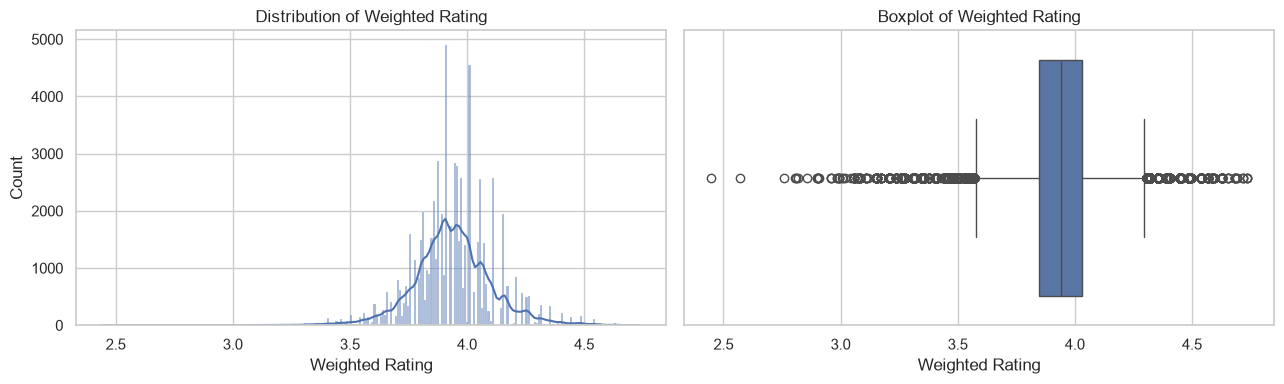

Figure saved successfully!


In [310]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

output_dir = Path("outputs/figures/eda")
output_dir.mkdir(parents=True, exist_ok=True)

target = model_df_clean["weighted_rating"]

print("Target Variable: weighted_rating")
print("\nDescriptive Statistics:")
display(target.describe())

print("\nMissing Values:", target.isnull().sum())
print("Unique Values:", target.nunique())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(target, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Weighted Rating")
axes[0].set_xlabel("Weighted Rating")

sns.boxplot(x=target, ax=axes[1])
axes[1].set_title("Boxplot of Weighted Rating")
axes[1].set_xlabel("Weighted Rating")

plt.tight_layout()

fig.savefig(
    output_dir / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure saved successfully!")

In [306]:
print("Dataset shape:", model_df_clean.shape)

print("\nData types:")
display(model_df_clean.dtypes.value_counts())

print("\nNumeric columns:", len(model_df_clean.select_dtypes(include="number").columns))
print("Categorical columns:", len(model_df_clean.select_dtypes(exclude="number").columns))

print("\nPotentially sensitive columns:")
for col in model_df_clean.columns:
    if any(word in col.lower() for word in ["rating", "score", "weight", "target"]):
        print(col)

Dataset shape: (66968, 125)

Data types:


float64    113
str          7
int64        5
Name: count, dtype: int64


Numeric columns: 118
Categorical columns: 7

Potentially sensitive columns:
weighted_rating


In [307]:
for i, col in enumerate(model_df_clean.columns, start=1):
    print(f"{i:3}. {col}")

  1. locality_latitude
  2. locality_longitude
  3. weighted_rating
  4. total_city_restaurant_count
  5. local_district_population
  6. local_district_wealth_index
  7. median_menu_item_price
  8. top_menu_category_avg_price
  9. top_menu_category_relative_price
 10. menu_item_share_aloo
 11. menu_item_share_bhaji
 12. menu_item_share_bhurji
 13. menu_item_share_biryani
 14. menu_item_share_bowl
 15. menu_item_share_bread
 16. menu_item_share_brownie
 17. menu_item_share_burger
 18. menu_item_share_cake
 19. menu_item_share_chaap
 20. menu_item_share_chaat
 21. menu_item_share_chicken
 22. menu_item_share_chilli
 23. menu_item_share_chocolate
 24. menu_item_share_coffee
 25. menu_item_share_combo
 26. menu_item_share_cookies
 27. menu_item_share_corn
 28. menu_item_share_curry
 29. menu_item_share_dip
 30. menu_item_share_dosa
 31. menu_item_share_drink
 32. menu_item_share_falooda
 33. menu_item_share_fish
 34. menu_item_share_fries
 35. menu_item_share_fry
 36. menu_item_share_gobi


Top 20 numerical features correlated with weighted_rating:


,correlation
vegetarian_menu_ratio,0.2771
menu_available,0.2123
menu_item_share_icecream,0.2044
local_district_wealth_index,0.1892
menu_item_share_other,0.1806
menu_item_share_drink,0.1799
total_city_restaurant_count,0.1780
menu_item_share_brownie,0.1711
menu_item_share_falooda,0.1664
menu_item_share_shake,0.1646


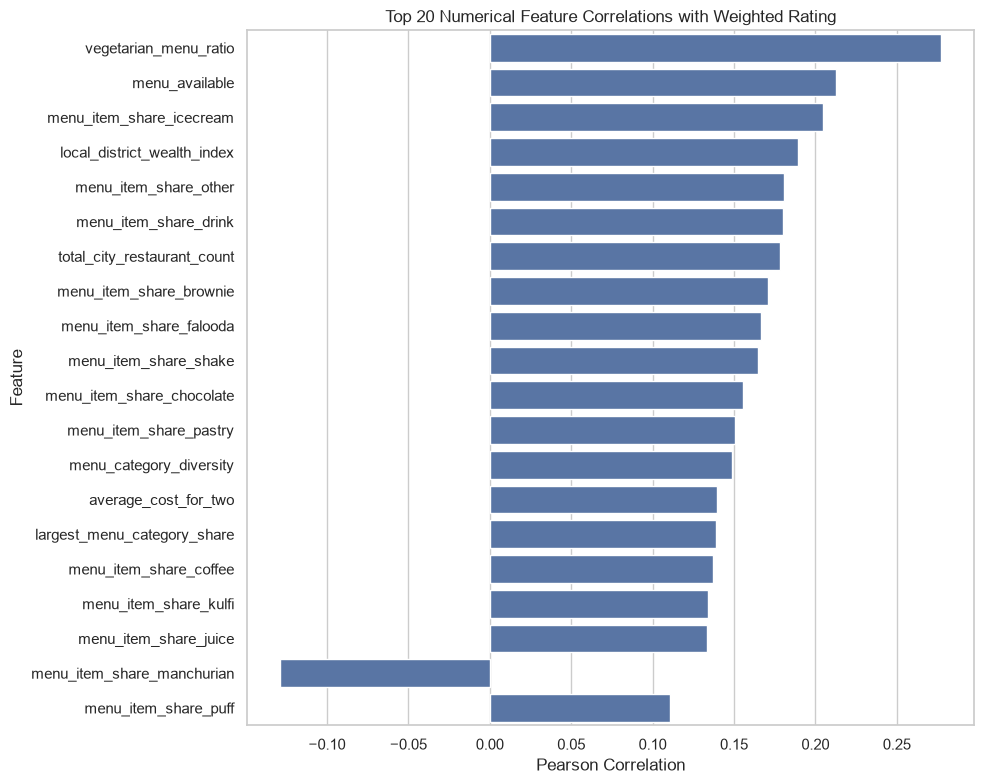

Correlation table and figure saved successfully.


In [311]:
from pathlib import Path

figure_dir = Path("outputs/figures/eda")
table_dir = Path("outputs/tables/eda")

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

numeric_corr = (
    model_df_clean
    .select_dtypes(include="number")
    .corr()["weighted_rating"]
    .drop("weighted_rating")
    .sort_values(key=abs, ascending=False)
)

print("Top 20 numerical features correlated with weighted_rating:")
display(numeric_corr.head(20).to_frame("correlation"))

numeric_corr.to_csv(table_dir / "numerical_correlations.csv")

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(
    x=numeric_corr.head(20).values,
    y=numeric_corr.head(20).index,
    ax=ax
)

ax.set_title("Top 20 Numerical Feature Correlations with Weighted Rating")
ax.set_xlabel("Pearson Correlation")
ax.set_ylabel("Feature")

plt.tight_layout()

fig.savefig(
    figure_dir / "top20_feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Correlation table and figure saved successfully.")

In [312]:
categorical_cols = model_df_clean.select_dtypes(
    exclude="number"
).columns

categorical_summary = pd.DataFrame({
    "unique_values": model_df_clean[categorical_cols].nunique(),
    "missing_values": model_df_clean[categorical_cols].isnull().sum(),
    "top_value": [
        model_df_clean[col].mode().iloc[0]
        if not model_df_clean[col].mode().empty else None
        for col in categorical_cols
    ],
    "top_value_count": [
        model_df_clean[col].value_counts().iloc[0]
        if not model_df_clean[col].value_counts().empty else 0
        for col in categorical_cols
    ]
})

display(categorical_summary.sort_values(
    "unique_values", ascending=False
))

,unique_values,missing_values,top_value,top_value_count
cuisine,4245,0,"North Indian, Chinese",2931
city,536,0,Delhi,7869
locality,272,23590,Greater Kailash 2,842
dominant_menu_category,78,0,Unknown,19211
state,32,0,Karnataka,8314
geocoding_status,4,0,available,66042
geographic_state_validation_status,4,0,matched,66275


In [313]:
locality_missing = model_df_clean[
    model_df_clean["locality"].isnull()
]

print("Missing locality records:", len(locality_missing))
print(
    "Missing locality percentage:",
    round(len(locality_missing) / len(model_df_clean) * 100, 2),
    "%"
)

print("\nTop 20 cities with missing locality:")
display(
    locality_missing["city"]
    .value_counts()
    .head(20)
    .to_frame("missing_locality_count")
)

print("\nGeocoding status for missing locality:")
display(
    locality_missing["geocoding_status"]
    .value_counts()
    .to_frame("count")
)

Missing locality records: 23590
Missing locality percentage: 35.23 %

Top 20 cities with missing locality:


,missing_locality_count
city,
Bikaner,850
Ahmedabad,670
Delhi,598
Noida-1,545
Patna,340
Kanpur,303
Gandhinagar,298
Madurai,270
Varanasi,256



Geocoding status for missing locality:


,count
geocoding_status,
available,23073
suspected_geocoding_error,392
missing_coordinates,103
ambiguous_city_label,22


In [314]:
locality_missing = model_df_clean[
    model_df_clean["locality"].isnull()
]

coordinate_analysis = pd.DataFrame({
    "condition": [
        "Both coordinates available",
        "Latitude missing",
        "Longitude missing",
        "Both coordinates missing"
    ],
    "count": [
        (
            locality_missing["locality_latitude"].notna()
            & locality_missing["locality_longitude"].notna()
        ).sum(),
        locality_missing["locality_latitude"].isna().sum(),
        locality_missing["locality_longitude"].isna().sum(),
        (
            locality_missing["locality_latitude"].isna()
            & locality_missing["locality_longitude"].isna()
        ).sum()
    ]
})

display(coordinate_analysis)

print("\nGeocoding status vs coordinate availability:")
display(pd.crosstab(
    locality_missing["geocoding_status"],
    locality_missing["locality_latitude"].notna()
    & locality_missing["locality_longitude"].notna()
))

,condition,count
0,Both coordinates available,23487
1,Latitude missing,103
2,Longitude missing,103
3,Both coordinates missing,103



Geocoding status vs coordinate availability:


col_0,False,True
geocoding_status,,
ambiguous_city_label,0,22
available,0,23073
missing_coordinates,103,0
suspected_geocoding_error,0,392


In [315]:
from pathlib import Path

table_dir = Path("outputs/tables/eda")
table_dir.mkdir(parents=True, exist_ok=True)

locality_analysis = pd.DataFrame({
    "metric": [
        "Total records",
        "Missing locality records",
        "Missing locality percentage",
        "Records with both coordinates",
        "Records without coordinates"
    ],
    "value": [
        len(model_df_clean),
        len(locality_missing),
        round(len(locality_missing) / len(model_df_clean) * 100, 2),
        (
            locality_missing["locality_latitude"].notna()
            & locality_missing["locality_longitude"].notna()
        ).sum(),
        (
            locality_missing["locality_latitude"].isna()
            & locality_missing["locality_longitude"].isna()
        ).sum()
    ]
})

display(locality_analysis)

locality_analysis.to_csv(
    table_dir / "missing_locality_analysis.csv",
    index=False
)

print("Missing locality analysis saved.")

,metric,value
0,Total records,66968.0000
1,Missing locality records,23590.0000
2,Missing locality percentage,35.2300
3,Records with both coordinates,23487.0000
4,Records without coordinates,103.0000


Missing locality analysis saved.


In [316]:
missing_summary = pd.DataFrame({
    "missing_count": model_df_clean.isnull().sum(),
    "missing_percentage": (
        model_df_clean.isnull().sum() / len(model_df_clean) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percentage", ascending=False)

print("Features containing missing values:", len(missing_summary))

display(missing_summary)

missing_summary.to_csv(
    table_dir / "overall_missing_value_analysis.csv"
)

print("Missing-value analysis saved.")

Features containing missing values: 27


,missing_count,missing_percentage
locality,23590,35.2258
top_menu_category_relative_price,19248,28.7421
top_menu_category_avg_price,19248,28.7421
median_menu_item_price,19211,28.6868
college_count_within_1000m,2714,4.0527
college_count_within_500m,2714,4.0527
college_nearest_distance_meters,2714,4.0527
hospital_count_within_1000m,2713,4.0512
mall_count_within_500m,2713,4.0512
hospital_count_within_500m,2713,4.0512


Missing-value analysis saved.


In [317]:
menu_missing = model_df_clean["median_menu_item_price"].isnull()
poi_missing = model_df_clean["hospital_count_within_500m"].isnull()

print("Menu availability vs missing menu price:")
display(pd.crosstab(
    model_df_clean["menu_available"],
    menu_missing,
    margins=True
))

print("\nPOI data trustworthiness vs missing POI count:")
display(pd.crosstab(
    model_df_clean["nearby_poi_data_trustworthy"],
    poi_missing,
    margins=True
))

print("\nMissing menu price by menu availability:")
display(
    model_df_clean.groupby("menu_available")["median_menu_item_price"]
    .agg(["count", "mean"])
)

Menu availability vs missing menu price:


median_menu_item_price,False,True,All
menu_available,,,
0,0,19211,19211
1,47757,0,47757
All,47757,19211,66968



POI data trustworthiness vs missing POI count:


hospital_count_within_500m,False,True,All
nearby_poi_data_trustworthy,,,
0,0,2713,2713
1,64255,0,64255
All,64255,2713,66968



Missing menu price by menu availability:


,count,mean
menu_available,,
0,0,NaN
1,47757,155.1934


In [318]:
poi_cols = [
    col for col in model_df_clean.columns
    if (
        "count_within_" in col
        or "nearest_distance_meters" in col
    )
]

poi_missing_summary = pd.DataFrame({
    "missing_count": model_df_clean[poi_cols].isnull().sum(),
    "missing_percentage": (
        model_df_clean[poi_cols].isnull().mean() * 100
    )
})

print("POI feature missingness:")
display(poi_missing_summary)

print("\nRecords with all POI features missing:",
      model_df_clean[poi_cols].isnull().all(axis=1).sum())

print("Records with some POI features missing:",
      model_df_clean[poi_cols].isnull().any(axis=1).sum()
      - model_df_clean[poi_cols].isnull().all(axis=1).sum())

POI feature missingness:


,missing_count,missing_percentage
college_count_within_500m,2714,4.0527
college_count_within_1000m,2714,4.0527
hospital_count_within_500m,2713,4.0512
hospital_count_within_1000m,2713,4.0512
mall_count_within_500m,2713,4.0512
mall_count_within_1000m,2713,4.0512
market_count_within_500m,2713,4.0512
market_count_within_1000m,2713,4.0512
office_count_within_500m,2713,4.0512
office_count_within_1000m,2713,4.0512



Records with all POI features missing: 2713
Records with some POI features missing: 1


In [319]:
partial_poi_rows = model_df_clean[
    model_df_clean[poi_cols].isnull().any(axis=1)
    & ~model_df_clean[poi_cols].isnull().all(axis=1)
]

display(partial_poi_rows[
    ["city", "locality", "nearby_poi_data_trustworthy"]
    + poi_cols
])

,city,locality,nearby_poi_data_trustworthy,college_count_within_500m,college_count_within_1000m,hospital_count_within_500m,hospital_count_within_1000m,mall_count_within_500m,mall_count_within_1000m,market_count_within_500m,market_count_within_1000m,office_count_within_500m,office_count_within_1000m,school_count_within_500m,school_count_within_1000m,college_nearest_distance_meters,hospital_nearest_distance_meters,mall_nearest_distance_meters,market_nearest_distance_meters,office_nearest_distance_meters,school_nearest_distance_meters
64383,Ambur,NaN,1,NaN,NaN,0.0000,0.0000,1.0000,2.0000,1.0000,2.0000,3.0000,6.0000,1.0000,4.0000,NaN,1089.0000,120.0000,209.0000,222.0000,274.0000


In [320]:
target_corr = (
    model_df_clean
    .select_dtypes(include="number")
    .corr()["weighted_rating"]
    .drop("weighted_rating")
    .dropna()
)

high_corr_features = (
    target_corr[ target_corr.abs() >= 0.70 ]
    .sort_values(key=abs, ascending=False)
)

print("Features with absolute correlation >= 0.70:")
display(high_corr_features)

print("\nHighest absolute feature-target correlations:")
display(target_corr.abs().sort_values(ascending=False).head(10))

Features with absolute correlation >= 0.70:


Series([], Name: weighted_rating, dtype: float64)


Highest absolute feature-target correlations:


vegetarian_menu_ratio         0.2771
menu_available                0.2123
menu_item_share_icecream      0.2044
local_district_wealth_index   0.1892
menu_item_share_other         0.1806
menu_item_share_drink         0.1799
total_city_restaurant_count   0.1780
menu_item_share_brownie       0.1711
menu_item_share_falooda       0.1664
menu_item_share_shake         0.1646
Name: weighted_rating, dtype: float64

In [321]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("data/processed/Clean_Restaurant_Dataset.csv")

model_df_clean = pd.read_csv(DATA_PATH)

print("Dataset shape:", model_df_clean.shape)
print("Duplicate rows:", model_df_clean.duplicated().sum())
print("Missing target values:", model_df_clean["weighted_rating"].isnull().sum())
print("Target column:", "weighted_rating" in model_df_clean.columns)

Dataset shape: (66968, 125)
Duplicate rows: 0
Missing target values: 0
Target column: True


### Step 2: Train-Test Split Preparation

The dataset will be divided into 80% training data and 20% testing data.

Since `weighted_rating` is a continuous target, we will use stratification based on rating bins to maintain a similar target distribution in both sets. We will also examine the distribution of states to assess geographic representation.

We will use `random_state=42` to ensure reproducibility.

In [322]:
print("State distribution:")
display(
    model_df_clean["state"]
    .value_counts(dropna=False)
    .to_frame("record_count")
)

print("\nWeighted rating distribution:")
display(
    model_df_clean["weighted_rating"]
    .describe()
    .to_frame("weighted_rating")
)

State distribution:


,record_count
state,
Karnataka,8314
Delhi,7885
Tamil Nadu,7697
Maharashtra,7532
Telangana,5083
Gujarat,4921
Uttar Pradesh,4637
West Bengal,4121
Andhra Pradesh,2696



Weighted rating distribution:


,weighted_rating
count,66968.0000
mean,3.9374
std,0.1697
min,2.4467
25%,3.8451
50%,3.9428
75%,4.0285
max,4.7357


### Step 3: Target Stratification

Since `weighted_rating` is a continuous regression target, it cannot be directly used for stratified sampling.

We will divide it into five quantile-based bins. These bins allow us to preserve approximately the same distribution of low, medium, and high ratings in the training and testing datasets.

The bins are used only for splitting and will not be included as model features.

In [323]:
model_df_clean["rating_bin"] = pd.qcut(
    model_df_clean["weighted_rating"],
    q=5,
    labels=False,
    duplicates="drop"
)

print("Rating bin distribution:")
display(
    model_df_clean["rating_bin"]
    .value_counts()
    .sort_index()
    .to_frame("record_count")
)

Rating bin distribution:


,record_count
rating_bin,
0,13957
1,12863
2,13735
3,13837
4,12576


In [324]:
rating_bins, bin_edges = pd.qcut(
    model_df_clean["weighted_rating"],
    q=5,
    retbins=True,
    duplicates="drop"
)

bin_summary = pd.DataFrame({
    "rating_range": rating_bins.cat.categories.astype(str),
    "record_count": rating_bins.value_counts().sort_index().values
})

display(bin_summary)

,rating_range,record_count
0,"(2.446, 3.812]",13957
1,"(3.812, 3.902]",12863
2,"(3.902, 3.962]",13735
3,"(3.962, 4.057]",13837
4,"(4.057, 4.736]",12576


In [325]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    model_df_clean,
    test_size=0.20,
    random_state=42,
    stratify=model_df_clean["rating_bin"]
)

train_df = train_df.drop(columns=["rating_bin"])
test_df = test_df.drop(columns=["rating_bin"])

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (53574, 125)
Testing dataset: (13394, 125)


### Step 5: Train-Test Distribution Verification

The target variable distribution is compared between the training and testing datasets to verify that stratified sampling has maintained a similar distribution.

We compare the mean, standard deviation, minimum, maximum, and quartiles of `weighted_rating` in both datasets.

In [326]:
target_comparison = pd.DataFrame({
    "Training": train_df["weighted_rating"].describe(),
    "Testing": test_df["weighted_rating"].describe()
})

display(target_comparison.round(4))

,Training,Testing
count,53574.0000,13394.0000
mean,3.9372,3.9382
std,0.1699,0.1688
min,2.4467,2.5690
25%,3.8451,3.8451
50%,3.9285,3.9428
75%,4.0285,4.0285
max,4.7357,4.7357


### Step 6: Save Train and Test Datasets

After verifying the stratified split, the training and testing datasets are saved separately in the processed data directory.

The original `Clean_Restaurant_Dataset.csv` remains unchanged. Both datasets retain the target column `weighted_rating` for supervised regression.

In [327]:
train_path = Path("data/processed/train_dataset.csv")
test_path = Path("data/processed/test_dataset.csv")

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print("Training dataset saved:", train_path)
print("Testing dataset saved:", test_path)
print("Training shape:", pd.read_csv(train_path).shape)
print("Testing shape:", pd.read_csv(test_path).shape)

Training dataset saved: data\processed\train_dataset.csv
Testing dataset saved: data\processed\test_dataset.csv
Training shape: (53574, 125)
Testing shape: (13394, 125)


### Step 7: Geographic Representation Check

The state distribution of the training and testing datasets is compared to identify geographic representation differences.

This check helps us understand whether certain states are underrepresented in either dataset, even though stratification was performed using `rating_bin`.

In [328]:
state_comparison = pd.DataFrame({
    "Training_Count": train_df["state"].value_counts(),
    "Testing_Count": test_df["state"].value_counts()
}).fillna(0).astype(int)

state_comparison["Training_Percentage"] = (
    state_comparison["Training_Count"] / len(train_df) * 100
)

state_comparison["Testing_Percentage"] = (
    state_comparison["Testing_Count"] / len(test_df) * 100
)

display(state_comparison.sort_values("Training_Count", ascending=False).round(2))

,Training_Count,Testing_Count,Training_Percentage,Testing_Percentage
state,,,,
Karnataka,6598,1716,12.3200,12.8100
Delhi,6357,1528,11.8700,11.4100
Tamil Nadu,6186,1511,11.5500,11.2800
Maharashtra,6026,1506,11.2500,11.2400
Telangana,4003,1080,7.4700,8.0600
Gujarat,3936,985,7.3500,7.3500
Uttar Pradesh,3760,877,7.0200,6.5500
West Bengal,3310,811,6.1800,6.0500
Andhra Pradesh,2150,546,4.0100,4.0800


### Step 8: Feature Type Identification

The input features are classified into numerical and categorical variables to determine the appropriate preprocessing techniques.

Numerical features may require missing-value imputation and scaling, while categorical features require missing-value handling and encoding.

The target variable `weighted_rating` is kept separate from the input features.

In [329]:
target = "weighted_rating"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

print("\nCategorical columns:")
print(categorical_cols)

Numerical features: 117
Categorical features: 7

Categorical columns:
['cuisine', 'locality', 'city', 'geocoding_status', 'state', 'geographic_state_validation_status', 'dominant_menu_category']


### Step 9: Numerical Feature Missing-Value Analysis

Missing numerical values are examined to determine the appropriate imputation strategy.

Features with structural missingness, such as menu prices when menu data is unavailable and POI measurements when POI data is untrustworthy, require special consideration.

Imputation statistics will be calculated from the training dataset only and subsequently applied to the testing dataset.

In [330]:
numeric_missing = pd.DataFrame({
    "missing_count": X_train[numeric_cols].isnull().sum(),
    "missing_percentage": (
        X_train[numeric_cols].isnull().mean() * 100
    )
})

numeric_missing = (
    numeric_missing[numeric_missing["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

print("Numerical features with missing values:", len(numeric_missing))
display(numeric_missing.round(2))

Numerical features with missing values: 26


,missing_count,missing_percentage
top_menu_category_relative_price,15347,28.6500
top_menu_category_avg_price,15347,28.6500
median_menu_item_price,15322,28.6000
college_count_within_500m,2222,4.1500
college_count_within_1000m,2222,4.1500
college_nearest_distance_meters,2222,4.1500
hospital_count_within_1000m,2221,4.1500
mall_count_within_500m,2221,4.1500
hospital_count_within_500m,2221,4.1500
market_count_within_500m,2221,4.1500


### Step 10: Categorical Feature Missing-Value Analysis

Categorical features are examined for missing values and high-cardinality categories.

This analysis helps determine suitable strategies for handling missing categories and encoding categorical variables. Special attention is given to locality and cuisine because they contain many distinct categories.

In [331]:
categorical_summary = pd.DataFrame({
    "unique_values": X_train[categorical_cols].nunique(),
    "missing_count": X_train[categorical_cols].isnull().sum(),
    "missing_percentage": X_train[categorical_cols].isnull().mean() * 100
})

display(
    categorical_summary.sort_values(
        "unique_values",
        ascending=False
    ).round(2)
)

,unique_values,missing_count,missing_percentage
cuisine,3686,0,0.0000
city,535,0,0.0000
locality,272,18962,35.3900
dominant_menu_category,78,0,0.0000
state,31,0,0.0000
geocoding_status,4,0,0.0000
geographic_state_validation_status,4,0,0.0000


### Step 11: Categorical Frequency Analysis

The frequency distribution of categorical variables is examined to identify dominant categories and rare categories.

This is particularly important for high-cardinality features such as cuisine, city, and locality. The analysis will help select appropriate encoding methods and avoid unnecessary feature expansion.

In [332]:
for col in categorical_cols:
    print(f"\n{col}")
    print("Unique categories:", X_train[col].nunique())
    display(
        X_train[col]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("count")
    )


cuisine
Unique categories: 3686


,count
cuisine,
"North Indian, Chinese",2334
North Indian,1659
Indian,1590
"Indian, Chinese",1520
South Indian,1394
Chinese,1134
Pizzas,998
"Bakery, Desserts",910
"Ice Cream, Desserts",871



locality
Unique categories: 272


,count
locality,
NaN,18962
Greater Kailash 2,682
Dwarka,631
Adajan,568
Rajouri Garden,526
Rohini,483
Laxmi Nagar,470
Indiranagar,458
Vastrapur,426



city
Unique categories: 535


,count
city,
Delhi,6344
Bangalore,5436
Chennai,3906
Hyderabad,3657
Pune,2997
Kolkata,2528
Mumbai,1881
Ahmedabad,1799
Surat,994


... (4 outputs left out)


geographic_state_validation_status
Unique categories: 4


,count
geographic_state_validation_status,
matched,53014
state_boundary_mismatch,424
missing_coordinates,86
outside_boundary,50



dominant_menu_category
Unique categories: 78


,count
dominant_menu_category,
Unknown,15322
curry,8803
pizza,2430
biryani,2184
combo,2084
chicken,2081
burger,2013
dosa,1850
noodles,1772


In [333]:
high_cardinality_cols = ["cuisine", "locality", "city"]

low_cardinality_cols = [
    "state",
    "dominant_menu_category",
    "geocoding_status",
    "geographic_state_validation_status"
]

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

for col in high_cardinality_cols:
    X_train_encoded[col] = X_train_encoded[col].fillna("Unknown")
    X_test_encoded[col] = X_test_encoded[col].fillna("Unknown")

    frequency_map = X_train_encoded[col].value_counts(normalize=True)

    X_train_encoded[col] = X_train_encoded[col].map(frequency_map)
    X_test_encoded[col] = X_test_encoded[col].map(frequency_map).fillna(0)

X_train_low = pd.get_dummies(
    X_train_encoded[low_cardinality_cols],
    columns=low_cardinality_cols,
    dtype=int
)

X_test_low = pd.get_dummies(
    X_test_encoded[low_cardinality_cols],
    columns=low_cardinality_cols,
    dtype=int
)

X_test_low = X_test_low.reindex(
    columns=X_train_low.columns,
    fill_value=0
)

X_train_encoded = pd.concat(
    [
        X_train_encoded.drop(columns=low_cardinality_cols),
        X_train_low
    ],
    axis=1
)

X_test_encoded = pd.concat(
    [
        X_test_encoded.drop(columns=low_cardinality_cols),
        X_test_low
    ],
    axis=1
)

print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)
print("Remaining categorical columns:",
      X_train_encoded.select_dtypes(include=["object", "category", "bool"]).columns.tolist())

Training shape: (53574, 237)
Testing shape: (13394, 237)
Remaining categorical columns: []


In [334]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_processed = pd.DataFrame(
    imputer.fit_transform(X_train_encoded),
    columns=imputer.get_feature_names_out(),
    index=X_train_encoded.index
)

X_test_processed = pd.DataFrame(
    imputer.transform(X_test_encoded),
    columns=imputer.get_feature_names_out(),
    index=X_test_encoded.index
)

In [335]:
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("Training missing values:", X_train_processed.isna().sum().sum())
print("Testing missing values:", X_test_processed.isna().sum().sum())

print("Training median imputation values:", len(imputer.statistics_))
print("Missingness indicator features:", len(imputer.indicator_.features_))

Training shape: (53574, 263)
Testing shape: (13394, 263)
Training missing values: 0
Testing missing values: 0
Training median imputation values: 237
Missingness indicator features: 26


In [336]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_processed),
    columns=X_train_processed.columns,
    index=X_train_processed.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_processed),
    columns=X_test_processed.columns,
    index=X_test_processed.index
)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Training missing values:", X_train_scaled.isna().sum().sum())
print("Testing missing values:", X_test_scaled.isna().sum().sum())

Training shape: (53574, 263)
Testing shape: (13394, 263)
Training missing values: 0
Testing missing values: 0


In [337]:
from pathlib import Path
import joblib

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

X_train_processed.to_csv(
    processed_dir / "X_train_processed.csv", index=False
)
X_test_processed.to_csv(
    processed_dir / "X_test_processed.csv", index=False
)

X_train_scaled.to_csv(
    processed_dir / "X_train_scaled.csv", index=False
)
X_test_scaled.to_csv(
    processed_dir / "X_test_scaled.csv", index=False
)

pd.DataFrame({"weighted_rating": y_train}).to_csv(
    processed_dir / "y_train.csv", index=False
)
pd.DataFrame({"weighted_rating": y_test}).to_csv(
    processed_dir / "y_test.csv", index=False
)

frequency_maps = {
    col: X_train[col].fillna("Unknown").value_counts(normalize=True).to_dict()
    for col in high_cardinality_cols
}

preprocessing_objects = {
    "imputer": imputer,
    "scaler": scaler,
    "frequency_maps": frequency_maps,
    "low_cardinality_cols": low_cardinality_cols,
    "high_cardinality_cols": high_cardinality_cols,
    "encoded_columns": X_train_encoded.columns.tolist(),
    "processed_columns": X_train_processed.columns.tolist(),
    "scaled_columns": X_train_scaled.columns.tolist()
}

joblib.dump(
    preprocessing_objects,
    processed_dir / "preprocessing_objects.joblib"
)

print("Processed datasets and preprocessing objects saved successfully.")
print("Files saved in:", processed_dir)

Processed datasets and preprocessing objects saved successfully.
Files saved in: data\processed


In [338]:
print("TRAINING DATA")
print("Missing values:", X_train_processed.isna().sum().sum())
print("Duplicate rows:", X_train_processed.duplicated().sum())

print("\nTESTING DATA")
print("Missing values:", X_test_processed.isna().sum().sum())
print("Duplicate rows:", X_test_processed.duplicated().sum())

print("\nTARGET")
print("Training target missing:", y_train.isna().sum())
print("Testing target missing:", y_test.isna().sum())

TRAINING DATA
Missing values: 0
Duplicate rows: 118

TESTING DATA
Missing values: 0
Duplicate rows: 4

TARGET
Training target missing: 0
Testing target missing: 0


In [339]:
train_check = X_train_processed.copy()
train_check["weighted_rating"] = y_train

duplicate_mask = X_train_processed.duplicated(keep=False)

duplicate_groups = (
    train_check[duplicate_mask]
    .groupby(list(X_train_processed.columns), dropna=False)
    .agg(
        records=("weighted_rating", "size"),
        unique_ratings=("weighted_rating", "nunique"),
        minimum_rating=("weighted_rating", "min"),
        maximum_rating=("weighted_rating", "max")
    )
    .reset_index(drop=True)
)

print("Duplicate feature groups:", len(duplicate_groups))
print("\nGroups with different target ratings:")
display(
    duplicate_groups[
        duplicate_groups["unique_ratings"] > 1
    ].head(10)
)

print(
    "\nDuplicate groups with identical target ratings:",
    (duplicate_groups["unique_ratings"] == 1).sum()
)

Duplicate feature groups: 97

Groups with different target ratings:


,records,unique_ratings,minimum_rating,maximum_rating
0,2,2,3.8951,3.9951
1,2,2,3.7094,3.8785
2,2,2,3.6428,4.0951
3,2,2,3.7071,3.8451
4,2,2,3.6571,3.8451
5,2,2,3.5071,3.6785
6,3,3,3.4571,3.9761
7,2,2,3.9118,3.9428
8,4,4,3.8451,3.9951
9,2,2,4.0451,4.0618



Duplicate groups with identical target ratings: 0


In [340]:
duplicate_mask = X_train_processed.duplicated(keep=False)

duplicate_indices = X_train_processed.index[duplicate_mask]

original_duplicate_records = X_train.loc[duplicate_indices].copy()
original_duplicate_records["weighted_rating"] = y_train.loc[duplicate_indices]

display(
    original_duplicate_records[
        [
            "cuisine",
            "locality",
            "city",
            "state",
            "dominant_menu_category",
            "weighted_rating"
        ]
    ].head(20)
)

,cuisine,locality,city,state,dominant_menu_category,weighted_rating
18578,"North Indian, Chinese",North Mohali,Mohali,Punjab,Unknown,3.7428
33404,South Indian,Kukatpally,Hyderabad,Telangana,Unknown,3.9451
66271,"North Indian, Punjabi",Salt Lake,Kolkata,West Bengal,Unknown,4.0285
47836,North Indian,Egmore,Chennai,Tamil Nadu,Unknown,3.8761
61790,"Biryani, North Indian",NaN,Noida-1,Uttar Pradesh,biryani,3.9118
56789,"Bakery, Desserts",Geddalahalli,Bangalore,Karnataka,Unknown,3.8118
47040,American,Greater Kailash 2,Delhi,Delhi,Unknown,4.0618
20355,"North Indian, Chinese",North Mohali,Mohali,Punjab,Unknown,3.3761
51086,Chinese,Vashi,Mumbai,Maharashtra,Unknown,3.5785
37473,"Chinese, Thai",Greater Kailash 2,Delhi,Delhi,Unknown,3.9785


In [341]:
identifier_cols = [
    col for col in model_df_clean.columns
    if any(term in col.lower() for term in ["id", "name", "restaurant"])
]

print("Possible identifier columns:")
print(identifier_cols)

Possible identifier columns:
['total_city_restaurant_count', 'menu_item_share_idli', 'geographic_state_validation_status']


In [342]:
identifier_cols = [
    col for col in df.columns
    if any(term in col.lower() for term in ["id", "name", "restaurant"])
]

print("Possible identifier columns in original dataset:")
print(identifier_cols)

Possible identifier columns in original dataset:
['name', 'city_restaurant_count', 'cuisine_restaurant_count_city', 'share_idli', 'state_validation_status']


In [343]:
print("Total records:", len(df))
print("Missing restaurant names:", df["name"].isna().sum())
print("Unique restaurant names:", df["name"].nunique())
print("Duplicate restaurant names:", df["name"].duplicated().sum())

print("\nMost frequent restaurant names:")
display(
    df["name"].value_counts().head(10).to_frame("count")
)

Total records: 67529
Missing restaurant names: 0
Unique restaurant names: 45002
Duplicate restaurant names: 22527

Most frequent restaurant names:


,count
name,
Domino's Pizza,419
Pizza Hut,332
KFC,328
Subway,239
Kwality Walls Frozen Dessert and Ice Cream Shop,236
Baskin Robbins,228
McDonald's,204
Faasos - Wraps & Rolls,197
Oven Story Pizza,194


In [345]:
duplicate_mask = X_train_processed.duplicated(keep=False)
duplicate_indices = X_train_processed.index[duplicate_mask]

duplicate_name_check = pd.concat(
    [
        df.loc[duplicate_indices, ["name"]],
        model_df_clean.loc[duplicate_indices, ["city", "locality"]],
        y_train.loc[duplicate_indices].rename("weighted_rating")
    ],
    axis=1
)

display(
    duplicate_name_check.sort_values(
        ["name", "city"]
    ).head(30)
)

,name,city,locality,weighted_rating
41507,A1 CHIPS,Kolkata,Salt Lake,3.9118
42643,A1 Chips,Coimbatore,Saravanampatti,3.7094
47836,A1 chips,Chennai,Egmore,3.8761
53296,ARBYs Grills rolls,Gurgaon,Greenfields_FBD,3.7785
44670,AWWSOME BITE,Chennai,Padur,3.9118
22179,Aiswariya,Mumbai,Vashi,3.8428
31729,Al-Aadaab Arabian Mandi Restaurant,Gurgaon,Greenfields_FBD,3.7428
35428,Al-Rad Kuzhimandi,Chennai,ECR-Kottivakkam,3.9951
65381,American Mafia Company,Chennai,Mogappair,4.0285
19862,Amiya Snacks,Chennai,OMR Perungudi,3.8451


In [346]:
try:
    import catboost
    print("CatBoost version:", catboost.__version__)
except ImportError:
    print("CatBoost is not installed.")

CatBoost is not installed.


In [347]:
%pip install catboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/101.7 MB 10.1 MB/s eta 0:00:10
   - -------------------------------------- 3.9/101.7 MB 12.5 MB/s eta 0:00:08
   - -------------------------------------- 4.5/101.7 MB 8.9 MB/s eta 0:00:11
   - -------------------------------------- 5.0/101.7 MB 7.1 MB/s eta 0:00:14
   -- ------------------------------------- 5.5/101.7 MB 6.1 MB/s eta 0:00:16
   -- ------------------------------------- 6.0/101.7 MB 5.5 MB/s eta 0:00:18
   -- ------------------------------------- 6.8/101.7 MB 5.1 MB/s eta 0:00:19
   -- ------------------------------------- 7.1/101.7 MB 4.6 MB/s eta 0:00:21
   -- ------------------------------------- 7.6/101.7 MB 4.4 MB/s eta 0:00:22
   --- ------------------------------------ 7.9/101.7 MB 4.0 MB/s eta 0:00:24
   --- ------------------------------------ 8.4/101.7 MB 3.9 MB/s eta 0:00:25
   --- ------------------------------------ 8.9/101.7 MB 3.7 MB/s eta


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Het Borad\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [348]:
import catboost

print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


In [349]:
X_train_cat = X_train.copy()
X_test_cat = X_test.copy()

cat_cols = X_train_cat.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in cat_cols:
    X_train_cat[col] = X_train_cat[col].fillna("Unknown").astype(str)
    X_test_cat[col] = X_test_cat[col].fillna("Unknown").astype(str)

print("Training shape:", X_train_cat.shape)
print("Testing shape:", X_test_cat.shape)
print("Categorical features:", cat_cols)
print("Training missing values:", X_train_cat.isna().sum().sum())
print("Testing missing values:", X_test_cat.isna().sum().sum())

Training shape: (53574, 124)
Testing shape: (13394, 124)
Categorical features: ['cuisine', 'locality', 'city', 'geocoding_status', 'state', 'geographic_state_validation_status', 'dominant_menu_category']
Training missing values: 87281
Testing missing values: 20856


In [350]:
print("Categorical missing values in training:")
print(X_train_cat[cat_cols].isna().sum())

print("\nCategorical missing values in testing:")
print(X_test_cat[cat_cols].isna().sum())

print("\nNumerical missing values in training:",
      X_train_cat.drop(columns=cat_cols).isna().sum().sum())

print("Numerical missing values in testing:",
      X_test_cat.drop(columns=cat_cols).isna().sum().sum())

Categorical missing values in training:
cuisine                               0
locality                              0
city                                  0
geocoding_status                      0
state                                 0
geographic_state_validation_status    0
dominant_menu_category                0
dtype: int64

Categorical missing values in testing:
cuisine                               0
locality                              0
city                                  0
geocoding_status                      0
state                                 0
geographic_state_validation_status    0
dominant_menu_category                0
dtype: int64

Numerical missing values in training: 87281
Numerical missing values in testing: 20856


In [351]:
X_train_cat.to_csv(
    "data/processed/X_train_catboost.csv", index=False
)

X_test_cat.to_csv(
    "data/processed/X_test_catboost.csv", index=False
)

y_train.to_csv(
    "data/processed/y_train_catboost.csv", index=False
)

y_test.to_csv(
    "data/processed/y_test_catboost.csv", index=False
)

print("CatBoost datasets saved successfully.")

CatBoost datasets saved successfully.


In [352]:
import os
import pandas as pd

files = [
    "X_train_catboost.csv",
    "X_test_catboost.csv",
    "y_train_catboost.csv",
    "y_test_catboost.csv"
]

for file in files:
    path = os.path.join("data/processed", file)
    data = pd.read_csv(path)
    print(f"{file}: {data.shape}")

X_train_catboost.csv: (53574, 124)
X_test_catboost.csv: (13394, 124)
y_train_catboost.csv: (53574, 1)
y_test_catboost.csv: (13394, 1)


In [353]:
import joblib

catboost_config = {
    "categorical_features": cat_cols,
    "target": target,
    "random_state": 42
}

joblib.dump(
    catboost_config,
    "data/processed/catboost_config.joblib"
)

print("CatBoost configuration saved.")
print("Categorical features:", cat_cols)

CatBoost configuration saved.
Categorical features: ['cuisine', 'locality', 'city', 'geocoding_status', 'state', 'geographic_state_validation_status', 'dominant_menu_category']



# Summary – Exploratory Data Analysis (EDA)

## 1. Objective

The objective of Exploratory Data Analysis (EDA) was to understand the restaurant dataset, examine its structure, identify patterns, investigate missing values, and understand the relationship between available features and the target variable.

The analysis helped identify data quality issues and determine suitable preprocessing strategies for supervised machine learning.

## 2. Dataset Overview

The original cleaned dataset contained:

- Records: 67,529
- Columns: 151

The modeling dataset was subsequently prepared with:

- Records: 66,968
- Columns: 125

The dataset contains restaurant-related information, including cuisine, location, menu characteristics, pricing, ratings, and geographical features.

The target variable selected for supervised regression was `weighted_rating`.

## 3. Target Variable Analysis

The distribution of `weighted_rating` was examined using a histogram and boxplot.

Key observations:

- Mean: approximately 3.9374
- Standard deviation: approximately 0.1697
- Minimum: approximately 2.4467
- Maximum: approximately 4.7357

The target distribution was concentrated around the mean, with relatively low variation across most observations.

The histogram and boxplot were used to examine the distribution and identify potential outliers.

## 4. Numerical Feature Analysis

The correlation between numerical features and `weighted_rating` was examined using Pearson correlation.

No feature had an absolute Pearson correlation of 0.70 or higher with the target.

The strongest positive correlations included:

| Feature | Correlation |
|---|---:|
| vegetarian_menu_ratio | 0.2771 |
| menu_available | 0.2123 |
| menu_item_share_icecream | 0.2044 |
| local_district_wealth_index | 0.1892 |

Key observations:

- Most individual numerical features had relatively weak linear relationships with the target.
- No strong linear correlation was observed.
- Weak correlation does not necessarily mean a feature is unimportant because non-linear relationships and feature interactions may exist.

## 5. Categorical Feature Analysis

The categorical features were examined to understand their unique category counts and frequency distributions.

| Feature | Unique Categories |
|---|---:|
| cuisine | 4,245 |
| city | 536 |
| locality | 272 |
| dominant_menu_category | 78 |
| state | 32 |
| geocoding_status | 4 |
| geographic_state_validation_status | 4 |

Key observations:

- Cuisine, city, and locality have high cardinality.
- State, dominant menu category, and geographical status features have relatively low cardinality.
- Different encoding techniques may therefore be suitable for different categorical features.

## 6. Locality Analysis

The `locality` feature contained 23,590 missing values, representing approximately 35.23% of the dataset.

Other observations:

- Missing locality values were mainly associated with locality identification or extraction limitations.
- Missing locality values should not automatically result in dropping the corresponding records.
- The missing values were retained and later represented as `Unknown` during categorical preprocessing.

## 7. Missing Value Analysis

Missing values were examined across the dataset.

A total of 27 columns contained missing values.

Important observations:

- `median_menu_item_price` was missing when `menu_available` was zero.
- Several POI-related features were missing when `nearby_poi_data_trustworthy` was zero.
- Local district population and wealth features had relatively low missingness.
- Locality coordinates had very little missingness.

These findings indicated that some missing values were structural and related to feature availability rather than random data loss.

Therefore, missing values required feature-aware handling rather than blindly replacing all missing values with zero or removing affected records.

## 8. Data Quality and Duplicate Analysis

Duplicate records were investigated during preparation of the modeling dataset.

- The modeling dataset contained 66,968 records after duplicate-row removal.
- Further investigation identified repeated feature combinations.
- Some repeated feature combinations had different target ratings.
- The dataset did not contain a reliable unique restaurant identifier.

Repeated feature combinations were therefore not automatically treated as duplicate restaurants. Removing them could result in the loss of valid observations.

## 9. Important EDA Findings and Their Impact on Preprocessing

| EDA Finding | Preprocessing Decision |
|---|---|
| High-cardinality cuisine, city, and locality | Frequency encoding for the traditional preprocessing pipeline |
| Low-cardinality categorical features | One-hot encoding |
| Missing locality values | Replace with `Unknown` |
| Numerical missing values | Median imputation with missingness indicators |
| Structural missing values | Preserve missingness information |
| Different feature scales | Prepare a scaled dataset for scale-sensitive models |
| Original categorical information | Prepare a separate dataset for CatBoost |
| Repeated feature combinations | Retain valid observations rather than removing them automatically |

## 10. EDA Visualizations and Outputs

The following outputs were generated and saved:

- `outputs/figures/eda/target_distribution.png`
- `outputs/tables/eda/numerical_correlations.csv`
- `outputs/figures/eda/top20_feature_correlations.png`
- `outputs/tables/eda/missing_locality_analysis.csv`
- `outputs/tables/eda/overall_missing_value_analysis.csv`

These outputs provide visual and tabular evidence supporting the EDA findings.

## 11. Conclusion

EDA provided an understanding of the dataset's structure, target distribution, numerical relationships, categorical cardinality, missing values, and repeated feature combinations.

The analysis identified important preprocessing requirements, particularly for high-cardinality categorical variables and structurally missing values.

Based on these findings, the dataset was prepared using multiple preprocessing approaches to support comparisons between traditional machine learning algorithms and CatBoost.

The next phase involves training supervised regression models to predict `weighted_rating`, evaluating their performance using MAE, RMSE, and R², and selecting a suitable model for deployment in a live web application.


# Summary – Data Preprocessing

## 1. Objective

The objective of this notebook was to prepare the cleaned restaurant dataset for supervised machine learning. The target variable is `weighted_rating`, and the task is to predict restaurant ratings using restaurant, menu, geographical, and other relevant features.

Three different preprocessing approaches were prepared to support comparisons between machine learning algorithms.

## 2. Dataset Preparation

- Loaded the cleaned dataset containing 67,529 records and 151 columns.
- Prepared the modeling dataset with 66,968 records and 125 columns after removing duplicate rows.
- Checked the target variable `weighted_rating` and ensured that no missing target values remained.
- Preserved the original cleaned dataset without modifying it.

## 3. Train-Test Split

The dataset was divided into training and testing sets using an 80:20 ratio.

- Training records: 53,574
- Testing records: 13,394
- Random state: 42
- Stratification: Five quantile-based bins created from `weighted_rating`.

Stratification was used to maintain a similar target distribution in both datasets.

## 4. Feature Separation

The target variable was separated from the input features.

- Target variable: `weighted_rating`
- Numerical features: 117
- Categorical features: 7

Categorical features:
- cuisine
- locality
- city
- geocoding_status
- state
- geographic_state_validation_status
- dominant_menu_category

## 5. Missing Value Handling and Categorical Encoding

Two different categorical encoding strategies were prepared.

### A. Frequency Encoding

Frequency encoding was applied to high-cardinality features:

- cuisine
- locality
- city

Category frequencies were calculated using only the training data. The same mappings were applied to the testing data. Unseen categories in the testing data were assigned a frequency of zero.

### B. One-Hot Encoding

One-hot encoding was applied to low-cardinality features:

- state
- dominant_menu_category
- geocoding_status
- geographic_state_validation_status

The testing dataset was aligned with the training dataset's encoded columns to maintain consistent feature dimensions.

Missing locality values were replaced with `Unknown` before encoding.

## 6. Numerical Missing Value Imputation

Numerical missing values were handled using `SimpleImputer` with the median strategy.

- Median values were calculated using the training data only.
- The learned medians were applied to both training and testing data.
- Missingness indicators were added to preserve information about which values were originally missing.

After imputation:
- Training features: 53,574 × 263
- Testing features: 13,394 × 263
- Missing values: 0

## 7. Feature Scaling

`StandardScaler` was applied to the imputed features.

- Mean and standard deviation were learned from the training data.
- The same scaling parameters were applied to the testing data.

Two feature versions were retained:

- **Processed features:** Encoded and imputed, without scaling. Suitable for tree-based models.
- **Scaled features:** Encoded, imputed, and standardized. Suitable for scale-sensitive models such as Linear Regression, Ridge, SVR, and KNN.

## 8. CatBoost Data Preparation

A separate dataset was prepared for CatBoost to preserve the original categorical information.

- Original categorical values were retained.
- Missing categorical values were replaced with `Unknown`.
- Numerical missing values were retained because CatBoost can handle numerical missing values natively.
- Feature scaling and frequency encoding were not applied.

The categorical feature names and model configuration were saved separately.

## 9. Final Dataset Dimensions

| Dataset | Rows | Columns |
|---|---:|---:|
| X_train_processed | 53,574 | 263 |
| X_test_processed | 13,394 | 263 |
| X_train_scaled | 53,574 | 263 |
| X_test_scaled | 13,394 | 263 |
| X_train_catboost | 53,574 | 124 |
| X_test_catboost | 13,394 | 124 |
| y_train | 53,574 | 1 |
| y_test | 13,394 | 1 |

## 10. Data Leakage Prevention

The following precautions were taken:

- The test dataset was separated before fitting preprocessing transformations.
- Frequency mappings were learned only from training data.
- One-hot encoding columns were aligned using the training feature structure.
- Median imputation values were learned only from training data.
- Standardization parameters were learned only from training data.
- The test dataset was transformed using previously learned training parameters.

The test dataset will remain reserved for final model evaluation.

## 11. Saved Preprocessing Files

All prepared datasets and preprocessing configurations were saved under `data/processed/`.

Important files include:

- `Clean_Restaurant_Dataset.csv`
- `train_dataset.csv`
- `test_dataset.csv`
- `X_train_processed.csv`
- `X_test_processed.csv`
- `X_train_scaled.csv`
- `X_test_scaled.csv`
- `y_train.csv`
- `y_test.csv`
- `preprocessing_objects.joblib`
- `X_train_catboost.csv`
- `X_test_catboost.csv`
- `y_train_catboost.csv`
- `y_test_catboost.csv`
- `catboost_config.joblib`

## 12. Conclusion

The dataset was successfully prepared for supervised regression modeling. Three feature preparation approaches were created to support comparisons between tree-based, scale-sensitive, and CatBoost models.

The next phase will involve training and comparing regression algorithms using MAE, RMSE, and R². The best-performing model will subsequently be considered for deployment through a live web application and CI/CD pipeline.
